<a href="https://colab.research.google.com/github/nandesh2k25/IK-DNN/blob/main/best_of_k.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

# Thesis Model — Built From Scratch (NumPy, Manual Backprop)

This notebook rebuilds the core of the thesis model (3R robot arm inverse kinematics) as a **plain feedforward neural network implemented from scratch**, in the style of Andrew Ng's Deep Learning Specialization (Course 1/2 assignments):

- No PyTorch, no autograd — every gradient is derived and coded by hand.
- No mixture density network — a single deterministic output head. The target is `[sin(theta1), cos(theta1), theta2, theta3]` (`theta1` is sin/cos-encoded to remove its ±180° wraparound discontinuity; `theta2`/`theta3` stay as raw radians since they never wrap).
- Input is `[x, y, z, elbow_config]` (v3) — `elbow_config` is a known, oracle input at training time that resolves the theta2/theta3 elbow-branch ambiguity (see Section 1). At inference the caller only supplies `(x,y,z)`; `predict_ik` (Section 4) queries both elbow configurations and picks whichever reprojects closer via forward kinematics.

**Version history condensed into this notebook:**
- **v5**: mini-batch gradient descent (3.6) — a gradient step per mini-batch rather than per full pass.
- **v6**: Adam (3.7) — momentum and RMSprop with bias correction, hand-derived. `optimizer="adam"`; plain GD stays the default so v0–v5 reproduce.
- **v7/v8**: learning-rate decay (3.8), paired with a larger `α₀`. The pairing is what wins — `α₀=2e-3` fixed is *worse* than v6.
- **v9–v10**: the **FK-consistency loss** (3.9) — push predicted angles through FK and penalize where the end-effector actually lands, so the chain rule supplies the lever-arm weighting that plain angle-MSE gets wrong. `lam=0` reproduces v8 exactly.
- **v11/v12**: more data (N=96k) and a deeper network at a longer budget. **v12 = 3.82 ± 0.34 mm** over 3 seeds — both thesis targets met (< 5 mm pose, < 5° angle).

**Two facts worth carrying forward, both measured rather than assumed:**
1. **The FK term cannot choose a branch.** Both elbow solutions give the *identical* end-effector position, so `∇J_FK` is exactly zero along the branch-ambiguity direction. The MSE term is the only one carrying branch information — which is why `lam` cannot simply be raised without eroding elbow selection.
2. **`lam`'s optimum is a broad plateau (≈[3,20]), not a peak.** `lam=5` is the argmin but is not statistically separated from 3/10/20; `lam=100` diverged on 1 of 3 seeds.

**Structure:**
1. Data Generation — sample joint angles, compute forward kinematics, build the `(position -> angles)` dataset.
2. Helper / Utility Functions — activations and their derivatives, error-metric helpers.
3. Neural Network Model — initialization, forward propagation, cost, backward propagation, updates, mini-batching, Adam, LR decay, the FK-consistency loss and its gradient check, and the full training loop.
4. Analysis — train, inspect the cost curve, evaluate accuracy, and the oracle/branch-ceiling diagnostics.
6–10. Bias/variance, Drive persistence, the pool rebuild, the state probe, and the v12 confirmation + fresh-test-set check.

## 1. Data Generation

The robot is a 3R arm: a base yaw joint `theta1`, plus a 2-link planar arm (`theta2`, `theta3`) that moves in the `(r, z)` plane swept out by that yaw.

```
r = L1 + L2*cos(theta2) + L3*cos(theta2 + theta3)
z = L2*sin(theta2) + L3*sin(theta2 + theta3)
x = r*cos(theta1)
y = r*sin(theta1)
```

We sample joint angles uniformly within their limits, compute the resulting end-effector position via forward kinematics, and treat `(x, y, z) -> (theta1, theta2, theta3)` as the supervised regression problem. Inputs and targets are both standardized (zero mean, unit variance) using train-set statistics only.

### Angle Encoding: sin/cos for theta1

`theta1` ranges over the full circle (-180°, 180°]. Two physically near-identical directions right at the wrap boundary — e.g. 179° and -179° — are numerically far apart as raw radians. A network regressing raw `theta1` is forced to fit a discontinuous function right at that boundary, which shows up as large error there (see `QUESTIONS.md`, Q1).

Fix: don't regress `theta1` directly. Regress `[sin(theta1), cos(theta1)]` instead — a continuous, wraparound-free representation — and recover the angle afterwards with `atan2(sin, cos)`, which is exact and lossless. `theta2`/`theta3` stay as raw radians since they're limited to (-90°, 90°) and never wrap.

The network's target now has **4 components**: `[sin(theta1), cos(theta1), theta2, theta3]`.

### The Elbow Configuration Oracle — and why v14 removes it

For a given `(x, y, z)` there are generally **two** valid `(θ₂, θ₃)` solutions — "elbow up" and "elbow down" — reaching the exact same position. A single deterministic network fed only `(x, y, z)` cannot represent both: wherever the branches are close in input space, its MSE-optimal prediction is their *average*, which is generally not a valid solution at all.

**v3's fix** was to tell the network which branch to solve for, via a 4th input derived from the already-known θ₃ at data-generation time:

$$\text{elbow\_config} = \begin{cases} +1 & \theta_3 \geq 0 \\ -1 & \theta_3 < 0 \end{cases}$$

With it, the mapping `(x, y, z, elbow_config) → (θ₁, θ₂, θ₃)` is single-valued. At inference the caller doesn't know the branch, so `predict_ik` queried the network with *both* values and kept whichever reprojected closer. That worked: it carried the model from 193.88 mm (v2) to 101.64 mm (v3), and eventually to 3.82 mm at v12.

**Why it has to go.** `elbow_config` is a hand-crafted, robot-specific label, and it is a dead end for three compounding reasons:

1. **It does not exist for a real arm.** `sign(θ₃)` is meaningful only because a 2-link planar sub-chain has exactly two branches. A UR5 has eight, and there is no single sign bit to hand it. Nothing about this construction generalises.
2. **It is derived from the answer.** The label is computed from θ₃ — the very quantity being predicted. At training time that is legitimate supervision, but it means the hardest part of the problem, the one-to-many structure, was never actually solved by the model.
3. **It makes the headline result claim less than it appears.** A thesis reporting a learned solution to an ambiguous inverse problem, where the ambiguity is resolved by an oracle, is reporting something much weaker than it sounds.

**What v14 does.** `USE_ELBOW_ORACLE` is set to `False`, and the network sees only `(x, y, z)`. Nothing derived from the answer reaches it, in training or inference.

**This will make the numbers worse, and that is the point.** The gap between v13 and v14 is the honest *cost of removal* — it quantifies exactly what the hand-crafted label was buying, and it is the baseline the multi-hypothesis head (v16) has to beat. A prediction is recorded in §14 **before** the run, so the result cannot be explained after the fact.

**What replaces it is not another label.** Note that the FK-consistency loss cannot take over this job: both branches produce identical end-effector positions, so `∇J_FK` is exactly zero along the branch-ambiguity direction. No reprojection loss, at any λ, for any arm, can supervise a discrete branch choice. Only a multi-hypothesis head can — each head sees gradient solely from examples it wins, and so never receives two conflicting labels for one input. That is v16.

**The flag is kept, not deleted.** Setting it back to `True` reproduces the v3–v13 pipeline, which is the only way the stored v12 weights (4-wide input) can still be scored. Default-off means every version from v14 onward is oracle-free.

In [ ]:
## ---- Robot parameters ----
L1, L2, L3 = 1.0, 1.0, 0.5
THETA1_LIM = (-np.pi, np.pi)
THETA2_LIM = (-np.pi / 2, np.pi / 2)
THETA3_LIM = (-np.pi / 2, np.pi / 2)

# ===== v14: the elbow_config oracle is OFF =====
# False (default, v14+): the network sees only (x, y, z). No information derived
#   from the answer reaches it, so the one-to-many structure has to be learned.
#   This is the only setting that scales past a 2-branch planar sub-chain.
# True  (v3-v13): appends the oracle elbow_config as a 4th input. Kept solely so
#   the v0-v13 record stays reproducible -- the stored v12 weights expect a
#   4-wide input and cannot be scored without it.
USE_ELBOW_ORACLE = False


def forward_kinematics(theta1, theta2, theta3, L1=L1, L2=L2, L3=L3):
    """Vectorized FK: joint angles (1D arrays) -> end-effector position (x, y, z)."""
    r = L1 + L2 * np.cos(theta2) + L3 * np.cos(theta2 + theta3)
    z = L2 * np.sin(theta2) + L3 * np.sin(theta2 + theta3)
    x = r * np.cos(theta1)
    y = r * np.sin(theta1)
    return x, y, z


## ---- theta1 sin/cos encoding (removes the +-180 deg wraparound discontinuity) ----
def encode_theta1_sincos(Y_theta):
    """Y_theta: (3, m) raw [theta1, theta2, theta3] -> (4, m) [sin1, cos1, theta2, theta3]."""
    theta1, theta2, theta3 = Y_theta[0], Y_theta[1], Y_theta[2]
    return np.vstack([np.sin(theta1), np.cos(theta1), theta2, theta3])


def decode_theta1_sincos(Y_enc):
    """Y_enc: (4, m) -> (3, m) raw [theta1, theta2, theta3].

    atan2 recovers theta1 exactly regardless of the magnitude of sin1/cos1.
    """
    sin1, cos1, theta2, theta3 = Y_enc[0], Y_enc[1], Y_enc[2], Y_enc[3]
    theta1 = np.arctan2(sin1, cos1)
    return np.vstack([theta1, theta2, theta3])


def encode_elbow_config(Y_theta_raw):
    """(3, m) raw angles -> (1, m) elbow_config in {+1, -1}.

    THE ORACLE. Derived from theta3, which is the answer the network is meant to
    predict. Only used when USE_ELBOW_ORACLE is True, i.e. when reproducing
    v3-v13. Nothing in v14+ calls this on the training path.
    """
    theta3 = Y_theta_raw[2]
    return np.where(theta3 >= 0.0, 1.0, -1.0)[None, :]


def build_inputs(xyz, Y_raw):
    """Network input from a target position, per the USE_ELBOW_ORACLE switch."""
    if USE_ELBOW_ORACLE:
        return np.vstack([xyz, encode_elbow_config(Y_raw)])
    return xyz


def generate_dataset(n_samples, seed=0):
    """Sample random joint configurations -> (X_xyz (3,n), Y_raw (3,n)), examples as columns."""
    rng = np.random.default_rng(seed)
    theta1 = rng.uniform(*THETA1_LIM, n_samples)
    theta2 = rng.uniform(*THETA2_LIM, n_samples)
    theta3 = rng.uniform(*THETA3_LIM, n_samples)
    x, y, z = forward_kinematics(theta1, theta2, theta3)
    return np.vstack([x, y, z]), np.vstack([theta1, theta2, theta3])


# ---- Generate + split (raw angles, raw xyz) ----
N_SAMPLES = 30000
X_all_xyz, Y_all_raw = generate_dataset(N_SAMPLES, seed=0)

n_train = int(0.8 * N_SAMPLES)
n_dev = int(0.1 * N_SAMPLES)

X_train_xyz, Y_train_raw = X_all_xyz[:, :n_train], Y_all_raw[:, :n_train]
X_dev_xyz, Y_dev_raw = X_all_xyz[:, n_train:n_train + n_dev], Y_all_raw[:, n_train:n_train + n_dev]
X_test_xyz, Y_test_raw = X_all_xyz[:, n_train + n_dev:], Y_all_raw[:, n_train + n_dev:]

print(f"train: {X_train_xyz.shape[1]}  dev: {X_dev_xyz.shape[1]}  test: {X_test_xyz.shape[1]}")

# ---- Encode targets: theta1 -> (sin, cos); theta2, theta3 stay raw ----
Y_train = encode_theta1_sincos(Y_train_raw)
Y_dev = encode_theta1_sincos(Y_dev_raw)
Y_test = encode_theta1_sincos(Y_test_raw)

# ---- Build inputs ----
X_train = build_inputs(X_train_xyz, Y_train_raw)
X_dev = build_inputs(X_dev_xyz, Y_dev_raw)
X_test = build_inputs(X_test_xyz, Y_test_raw)

# ---- Standardize using train-set statistics only ----
# sin1/cos1 (Y rows 0-1) are already in [-1,1] with mean ~0 -- left un-normalized
# so decoding never has to undo a normalization before atan2. elbow_config, when
# present, stays exactly +-1 for the same reason.
xyz_mean, xyz_std = X_train_xyz.mean(axis=1, keepdims=True), X_train_xyz.std(axis=1, keepdims=True)
if USE_ELBOW_ORACLE:
    X_mean = np.vstack([xyz_mean, np.zeros((1, 1))])
    X_std = np.vstack([xyz_std, np.ones((1, 1))])
else:
    X_mean, X_std = xyz_mean, xyz_std

theta23_mean = Y_train[2:4].mean(axis=1, keepdims=True)
theta23_std = Y_train[2:4].std(axis=1, keepdims=True)
Y_mean = np.vstack([np.zeros((2, 1)), theta23_mean])
Y_std = np.vstack([np.ones((2, 1)), theta23_std])


def normalize(A, mean, std):
    return (A - mean) / std


def denormalize(A_norm, mean, std):
    return A_norm * std + mean


X_train_norm, Y_train_norm = normalize(X_train, X_mean, X_std), normalize(Y_train, Y_mean, Y_std)
X_dev_norm, Y_dev_norm = normalize(X_dev, X_mean, X_std), normalize(Y_dev, Y_mean, Y_std)
X_test_norm, Y_test_norm = normalize(X_test, X_mean, X_std), normalize(Y_test, Y_mean, Y_std)

print(f"USE_ELBOW_ORACLE = {USE_ELBOW_ORACLE}  ->  network input width = {X_train.shape[0]}")
print("X_train_norm mean/std:", X_train_norm.mean(axis=1).round(3), X_train_norm.std(axis=1).round(3))
print("Y_train_norm mean/std:", Y_train_norm.mean(axis=1).round(3), Y_train_norm.std(axis=1).round(3))

train: 24000  dev: 3000  test: 3000
USE_ELBOW_ORACLE = False  ->  network input width = 3
X_train_norm mean/std: [-0.  0.  0.] [1. 1. 1.]
Y_train_norm mean/std: [ 0.008  0.009 -0.    -0.   ] [0.705 0.709 1.    1.   ]


## 2. Helper / Utility Functions

Reusable pieces that aren't themselves one of the five core NN steps: activation functions with their derivatives (needed by forward and backward propagation), and error-metric helpers used later in the analysis section.

In [ ]:
## ---- Activation functions (forward) ----
def relu(Z):
    return np.maximum(0, Z)


def linear(Z):
    return Z


## ---- Activation derivatives (backward): dZ = dA * activation'(Z) ----
def relu_backward(dA, Z):
    dZ = np.array(dA, copy=True)
    dZ[Z <= 0] = 0
    return dZ


def linear_backward(dA, Z):
    return np.array(dA, copy=True)


## ---- Error-metric helpers (used in Section 4) ----
def mae_degrees(pred_theta, true_theta):
    """Mean absolute *circular* error per joint, in degrees. Inputs shape (3, m), radians.

    Uses the shortest angular distance rather than a plain difference: raw
    angle values wrap at +-180 degrees (relevant to theta1). Without this, a
    perfectly good prediction near the wrap boundary (true=179 deg,
    pred=-179 deg) would be scored as a ~358 degree error instead of the
    true ~2 degrees.
    """
    diff = pred_theta - true_theta
    diff = (diff + np.pi) % (2 * np.pi) - np.pi  # wrap to (-pi, pi]
    return np.mean(np.abs(diff), axis=1) * (180.0 / np.pi)


def pose_error_mm(pred_theta, true_xyz, meters_to_mm=1000.0):
    """Euclidean end-effector error (mm) between FK(predicted angles) and the true target position."""
    x_pred, y_pred, z_pred = forward_kinematics(pred_theta[0], pred_theta[1], pred_theta[2])
    pred_xyz = np.vstack([x_pred, y_pred, z_pred])
    return np.linalg.norm(pred_xyz - true_xyz, axis=0) * meters_to_mm

## 2.5 Robot Configuration and Generic Kinematics

Sections 1–2 are 3R-shaped. `forward_kinematics` hardcodes the trig for one 2-link planar sub-chain, and the FK-consistency loss that follows in §3.9 originally hardcoded a Jacobian derived by hand for that same chain. Adding a second arm meant rewriting both.

This section replaces the geometry with **data**, and the hand-derived Jacobian with **one DOF-agnostic expression**. It sits here, before the network, because everything downstream — the FK loss, its gradient, and eventually the dataset shapes — reads from it.

**Denavit–Hartenberg.** Each joint contributes one transform `Rz(θ)·Tz(d)·Tx(a)·Rx(α)`, and the chain is their product. The arm becomes a table of `(a, α, d, θ_offset)` rows. Keeping every intermediate frame costs nothing and is what makes the Jacobian free.

**The geometric Jacobian.** For a revolute joint *i* and any point *p* rigidly attached to the end of the chain:

$$\frac{\partial p}{\partial \theta_i} = z_i \times (p - o_i)$$

where `z_i` is the joint's axis and `o_i` its origin, both read straight off the frames the forward pass already computed. One line, any number of joints. It reduces to the hand-derived 3R formulas exactly — verified below to ~1e-16, which is floating-point noise, not an approximation.

**No `atan2` in the gradient path.** FK needs only `sin θ` and `cos θ`, which for a wrapping joint *are* the network's two output rows. The recovery is a normalisation onto the unit circle:

$$n = \sqrt{s^2+c^2} + \varepsilon, \qquad \hat{s}=s/n, \quad \hat{c}=c/n$$

with **the epsilon added after the square root** — `FK_EPS` is defined here, since it belongs to the kinematics rather than to the loss. Differentiating that form is clean and branch-cut free; `atan2` appears only where a human-readable angle is wanted.

**The `wraps` flag** decides per joint whether it gets the two-row sin/cos encoding or one raw normalised row — replacing the "θ₁ is special" special case with a property of the joint. The network's output width follows from it rather than being a constant.

**One gate, parameterized by the robot.** `gate_robot(ROBOT)` is the single numerical seam: adding an arm is a config entry, not a new check. It runs in seconds and doubles as the pre-flight numerical check before any training job. Any check the config cannot support (no reference FK, no analytic IK) is skipped rather than faked.

Note that check 2 is **not** redundant with check 4. A finite-difference check only verifies that a gradient agrees with its own cost function — it would happily certify a self-consistently *wrong* FK (swapped rows, a flipped sign) as correct. Check 2 is the one that catches that, by feeding in ground truth and demanding the true pose back.

Check 5 deserves its own note. It compares the generic gradient against a **frozen copy of the original hand-derived 3R gradient**, kept in §2.5.4 purely as a test oracle — it is not on the training path and nothing calls it. Once v13 switched training onto the generic path, that frozen copy became the only independent implementation left, and therefore the only thing that can catch the generic path silently drifting. A 6-DOF arm will never have such a reference; the 3R does, so it is worth keeping.

In [ ]:
# ===== 2.5.1 DH engine, geometric Jacobian, robot config =====

FK_EPS = 1e-12  # guards the (sin, cos) -> unit-circle division; epsilon AFTER the sqrt


def dh_transform(a, alpha, d, theta):
    """Standard DH: Rz(theta) Tz(d) Tx(a) Rx(alpha).

    theta: (m,) -> returns (m, 4, 4). a/alpha/d are scalars (one joint's row).
    """
    theta = np.atleast_1d(theta)
    m = theta.shape[0]
    ct, st = np.cos(theta), np.sin(theta)
    ca, sa = np.cos(alpha), np.sin(alpha)
    T = np.zeros((m, 4, 4))
    T[:, 0, 0], T[:, 0, 1], T[:, 0, 2], T[:, 0, 3] = ct, -st * ca, st * sa, a * ct
    T[:, 1, 0], T[:, 1, 1], T[:, 1, 2], T[:, 1, 3] = st, ct * ca, -ct * sa, a * st
    T[:, 2, 1], T[:, 2, 2], T[:, 2, 3] = sa, ca, d
    T[:, 3, 3] = 1.0
    return T


def dh_chain(dh, thetas):
    """thetas: (n_joints, m) -> per-joint frames (n_joints+1, m, 4, 4), base frame first.

    Every intermediate frame is kept: the Jacobian needs each joint's axis and
    origin, and they are free once the frames exist.
    """
    n, m = thetas.shape
    frames = np.empty((n + 1, m, 4, 4))
    T = np.tile(np.eye(4), (m, 1, 1))
    frames[0] = T
    for i, (a, alpha, d, off) in enumerate(dh):
        T = T @ dh_transform(a, alpha, d, thetas[i] + off)
        frames[i + 1] = T
    return frames


def dh_fk_points(dh, thetas, feature_pts):
    """-> points (P, 3, m), joint axes z (n, 3, m), joint origins o (n, 3, m).

    feature_pts are expressed in the TOOL frame and carried out to world by the
    final transform. P=1 at the origin reproduces plain end-effector position.
    """
    frames = dh_chain(dh, thetas)
    T_end = frames[-1]                                              # (m,4,4)
    pts = []
    for f in feature_pts:
        fh = np.append(np.asarray(f, dtype=float), 1.0)
        pts.append((T_end @ fh)[:, :3].T)                           # (3,m)
    z = np.stack([frames[i][:, :3, 2].T for i in range(len(dh))])   # (n,3,m)
    o = np.stack([frames[i][:, :3, 3].T for i in range(len(dh))])   # (n,3,m)
    return np.stack(pts), z, o


def geometric_jacobian(z, o, p):
    """dp/dtheta_i = z_i x (p - o_i) for revolute joints.

    z, o: (n,3,m); p: (3,m) -> (n,3,m). This one line replaces every
    arm-specific dr/dtheta formula.
    """
    return np.cross(z, p[None] - o, axis=1)


def sample_joints(ROBOT, n_samples, seed=0):
    """Uniform samples within each joint's limits -> (n_joints, n_samples)."""
    rng = np.random.default_rng(seed)
    return np.vstack([rng.uniform(lo, hi, n_samples) for lo, hi in ROBOT["limits"]])


def n_out_rows(ROBOT):
    """Network output width: 2 rows per wrapping joint (sin, cos), 1 otherwise."""
    return sum(2 if w else 1 for w in ROBOT["wraps"])


def out_row_index(ROBOT):
    """Row offset of each joint in the output vector."""
    idx, r = [], 0
    for w in ROBOT["wraps"]:
        idx.append(r)
        r += 2 if w else 1
    return idx


# ---- the 3R, expressed as data ----
# Verified in 2.5.4 to reproduce forward_kinematics to ~1e-16.
ARM_3R = {
    "name": "3R",
    "dh": [                       # (a, alpha, d, theta_offset)
        (L1, np.pi / 2, 0.0, 0.0),
        (L2, 0.0,       0.0, 0.0),
        (L3, 0.0,       0.0, 0.0),
    ],
    "limits": [THETA1_LIM, THETA2_LIM, THETA3_LIM],
    "wraps": [True, False, False],   # only theta1 crosses +-180 deg
    "feature_pts": [[0.0, 0.0, 0.0]],  # P=1: end-effector position only (v13)
    "analytic_ik": None,             # filled in by 2.5.3
    "n_samples": 30000,
    "reference_fk": lambda th: np.vstack(forward_kinematics(th[0], th[1], th[2])),
    "encode_target": lambda th, Ym, Ys: normalize(encode_theta1_sincos(th), Ym, Ys),
}

# The ACTIVE robot. Every downstream shape reads from this; switching arms is
# one assignment. v13 onward, nn_model's FK term goes through it.
ROBOT = ARM_3R

print(f"ROBOT = {ROBOT['name']}: {len(ROBOT['dh'])} joints, "
      f"{n_out_rows(ROBOT)} output rows, row offsets {out_row_index(ROBOT)}")
print(f"wraps: {ROBOT['wraps']}  feature points: {len(ROBOT['feature_pts'])}")

ROBOT = 3R: 3 joints, 4 output rows, row offsets [0, 2, 3]
wraps: [True, False, False]  feature points: 1


In [ ]:
# ===== 2.5.2 Generic FK-from-output, cost, and gradient =====
# The DOF-agnostic core. Section 3.9's fk_from_output / compute_cost_fk /
# fk_output_grad are thin adapters over these, so this is what nn_model's FK
# term actually runs on from v13 onward.

def decode_joints_generic(AL, ROBOT, Y_mean, Y_std):
    """Normalized network output -> joint angles (n_joints, m), plus a cache.

    Wrapping joints occupy two rows (sin, cos) recovered by normalizing onto the
    unit circle -- epsilon AFTER the sqrt. Non-wrapping joints occupy one row,
    denormalized directly.
    """
    rows = out_row_index(ROBOT)
    thetas, cache = [], []
    for i, (w, r) in enumerate(zip(ROBOT["wraps"], rows)):
        if w:
            s, c = AL[r:r + 1], AL[r + 1:r + 2]
            n = np.sqrt(s * s + c * c) + FK_EPS
            s_hat, c_hat = s / n, c / n
            thetas.append(np.arctan2(s_hat, c_hat)[0])   # value only; grad via the cache
            cache.append(("wrap", r, s, c, n, s_hat, c_hat))
        else:
            th = AL[r:r + 1] * Y_std[r:r + 1] + Y_mean[r:r + 1]
            thetas.append(th[0])
            cache.append(("raw", r, Y_std[r:r + 1]))
    return np.vstack(thetas), cache


def fk_from_output_generic(AL, ROBOT, Y_mean, Y_std):
    """-> feature points (P, 3, m), plus everything the gradient needs."""
    thetas, cache = decode_joints_generic(AL, ROBOT, Y_mean, Y_std)
    pts, z, o = dh_fk_points(ROBOT["dh"], thetas, ROBOT["feature_pts"])
    return pts, (thetas, cache, z, o)


def compute_cost_fk_generic(AL, targets, ROBOT, Y_mean, Y_std):
    """targets: (P, 3, m) desired feature-point positions.

    Same 1/2m convention as compute_cost / compute_cost_fk.
    """
    m = AL.shape[1]
    pts, _ = fk_from_output_generic(AL, ROBOT, Y_mean, Y_std)
    e = pts - targets
    return (1.0 / (2.0 * m)) * np.sum(e * e)


def fk_output_grad_generic(AL, targets, ROBOT, Y_mean, Y_std):
    """d(J_fk)/d(AL), built from the DH chain and the geometric Jacobian only.

    Returns m * dJ/dAL -- NO 1/m -- matching the Section 3.4 convention.
    """
    pts, (thetas, cache, z, o) = fk_from_output_generic(AL, ROBOT, Y_mean, Y_std)
    e = pts - targets                                     # (P,3,m)

    # accumulate dJ/dtheta_i over every feature point
    n_joints = len(ROBOT["dh"])
    dJ_dtheta = np.zeros((n_joints, AL.shape[1]))
    for p_idx in range(pts.shape[0]):
        J = geometric_jacobian(z, o, pts[p_idx])          # (n,3,m)
        dJ_dtheta += np.einsum("ijm,jm->im", J, e[p_idx])

    dAL = np.zeros_like(AL)
    for i, entry in enumerate(cache):
        if entry[0] == "wrap":
            _, r, s, c, n, s_hat, c_hat = entry
            # theta = atan2(s/n, c/n); dtheta/ds = c_hat/n, dtheta/dc = -s_hat/n
            dAL[r:r + 1] = dJ_dtheta[i:i + 1] * (c_hat / n)
            dAL[r + 1:r + 2] = dJ_dtheta[i:i + 1] * (-s_hat / n)
        else:
            _, r, std = entry
            dAL[r:r + 1] = dJ_dtheta[i:i + 1] * std       # chain through denormalization
    return dAL


print("generic kinematics defined:")
for _f in ("decode_joints_generic", "fk_from_output_generic",
           "compute_cost_fk_generic", "fk_output_grad_generic"):
    print(f"  {_f}")
print("\nSection 3.9 adapts these for the training path (v13 onward).")

generic kinematics defined:
  decode_joints_generic
  fk_from_output_generic
  compute_cost_fk_generic
  fk_output_grad_generic

Section 3.9 adapts these for the training path (v13 onward).


In [ ]:
# ===== 12.3 Analytic IK for the 3R (all branches) =====
# The law-of-cosines solver from Section 4.6, promoted from a one-off diagnostic
# into the robot config's `analytic_ik` slot. It takes no label and touches no
# network -- it is pure geometry -- which is why it survives the elbow_config
# removal in v14 and goes on to supply ground-truth branches for the
# branch-agnostic metrics and the ceiling analysis.

def analytic_ik_3r(xyz, L1=L1, L2=L2, L3=L3):
    """All closed-form IK solutions for the 3R.

    xyz: (3, m) target positions.
    Returns (solutions, valid):
        solutions (2, 3, m) -- the elbow-up / elbow-down branches
        valid     (2, m)    -- whether each branch is within joint limits

    Only two branches exist here. The usual second theta1 family (theta1 + pi
    with a negative radius) is unreachable for this arm: |theta2| < 90 deg forces
    r >= L1 - L3 = 0.5 > 0, so the radius never changes sign.
    """
    x, y, z = xyz[0], xyz[1], xyz[2]
    theta1 = np.arctan2(y, x)
    rho = np.sqrt(x ** 2 + y ** 2) - L1          # planar reach from the shoulder
    d2 = rho ** 2 + z ** 2

    cos_t3 = (d2 - L2 ** 2 - L3 ** 2) / (2 * L2 * L3)
    cos_t3 = np.clip(cos_t3, -1.0, 1.0)          # guard FP edges at the reach boundary

    sols, valid = [], []
    for sign in (+1.0, -1.0):
        t3 = sign * np.arccos(cos_t3)
        t2 = np.arctan2(z, rho) - np.arctan2(L3 * np.sin(t3), L2 + L3 * np.cos(t3))
        sols.append(np.vstack([theta1, t2, t3]))
        valid.append(
            (t2 >= THETA2_LIM[0]) & (t2 <= THETA2_LIM[1]) &
            (t3 >= THETA3_LIM[0]) & (t3 <= THETA3_LIM[1]))
    return np.stack(sols), np.stack(valid)


ARM_3R["analytic_ik"] = analytic_ik_3r

# quick shape/sanity look before the gate exercises it properly
_ai_th = sample_joints(ARM_3R, 5, seed=7)
_ai_xyz = ARM_3R["reference_fk"](_ai_th)
_ai_sols, _ai_valid = analytic_ik_3r(_ai_xyz)
print(f"solutions {_ai_sols.shape}  valid {_ai_valid.shape}")
print(f"branches in-limits per target: {_ai_valid.sum(axis=0)}  (sampled branch is always one of them)")

solutions (2, 3, 5)  valid (2, 5)
branches in-limits per target: [2 1 2 2 2]  (sampled branch is always one of them)


### 2.6 The UR5 — a second arm, as a config entry

The 3R exists to make the method concrete. The UR5 is what makes the scalability claim real: **6 revolute joints, a full 6-D task space, and eight closed-form IK solutions instead of two.** There is no `sign(θ₃)` to hand it, which is the whole reason the oracle had to go.

**The DH table is taken from Universal Robots' own documentation, not from memory.** This matters more than it might appear: a wrong DH table would corrupt every UR5 result downstream while looking entirely plausible, and — unlike a wrong gradient — it would *not* be caught by the round-trip check, because the analytic IK reads the same constants. A self-consistently wrong arm round-trips perfectly.

| joint | a [m] | d [m] | α [rad] |
|---|---|---|---|
| 1 | 0 | 0.089159 | π/2 |
| 2 | −0.425 | 0 | 0 |
| 3 | −0.39225 | 0 | 0 |
| 4 | 0 | 0.10915 | π/2 |
| 5 | 0 | 0.09465 | −π/2 |
| 6 | 0 | 0.0823 | 0 |

Standard DH convention; UR's `a` is the same quantity Wikipedia calls `r`. Note `a₂` and `a₃` are **negative** — that is correct for this convention, not a transcription error, and the IK below depends on the sign.

**So the table gets an independent physical check instead:** the UR5's published working radius is **850 mm**, a number that comes from the datasheet rather than from the table. Sampling the workspace and measuring the maximum reach tests the link lengths against reality in a way no self-consistency check can.

**Where the eight solutions come from.** Three independent binary choices, each a `±` in an inverse trig function:

1. **Shoulder** left/right — from a `±acos` when solving θ₁ for the wrist-centre position.
2. **Wrist** flip — from a `±acos` when solving θ₅.
3. **Elbow** up/down — from the `±acos` in the law of cosines on the `(a₂, a₃)` planar sub-chain. *This is the 3R's ambiguity, still present, now one of three.*

2 × 2 × 2 = 8. The 3R's two branches are the elbow pair alone, which is exactly why `elbow_config` worked there and cannot generalise: it addresses one of three ambiguities, and only for a chain whose other two do not exist.

**Every joint wraps.** All six are full-revolution, so `wraps = [True]*6` and the network's output is 12 rows of `(sin, cos)` — derived from the config, not hardcoded. Compare the 3R's `[True, False, False]` giving 4 rows: the same `n_out_rows` call, a different arm.

**Nothing here touches training.** `ROBOT` stays `ARM_3R`; this section only adds a second config and proves it passes the same gate. Ticket 08 widens the task space to full 6-D pose, and ticket 09 trains on it.

In [ ]:
# ===== 2.5.4 gate_robot -- the single numerical seam =====
# Every check is both PRINTED (so a pass still shows its margin) and ASSERTED
# (so it cannot be skimmed past). Every silent bug in this project produced a
# smooth loss curve; none were caught by looking at one.

def _fk_output_grad_3r_reference(AL, xyz_target):
    """FROZEN COPY of the original hand-derived 3R gradient (pre-v13).

    NOT ON THE TRAINING PATH -- nothing calls this but check 5. It is kept
    deliberately: once v13 moved training onto the generic DH path, this became
    the only INDEPENDENT implementation of the same quantity, and therefore the
    only thing that can catch the generic path silently drifting. A 6-DOF arm
    will never have such a reference; the 3R does, so it is worth 20 lines.

    Derivation in Section 3.9. Returns m * dJ/dAL (no 1/m).
    """
    s, c = AL[0:1], AL[1:2]
    theta2 = AL[2:3] * Y_std[2:3] + Y_mean[2:3]
    theta3 = AL[3:4] * Y_std[3:4] + Y_mean[3:4]
    n = np.sqrt(s * s + c * c) + FK_EPS
    s_hat, c_hat = s / n, c / n
    r = L1 + L2 * np.cos(theta2) + L3 * np.cos(theta2 + theta3)
    z = L2 * np.sin(theta2) + L3 * np.sin(theta2 + theta3)
    e = np.vstack([r * c_hat, r * s_hat, z]) - xyz_target
    ex, ey, ez = e[0:1], e[1:2], e[2:3]
    dr = ex * c_hat + ey * s_hat
    K = r * (s * ex - c * ey) / n ** 3
    s23, c23 = np.sin(theta2 + theta3), np.cos(theta2 + theta3)
    out = np.empty_like(AL)
    out[0:1] = -c * K
    out[1:2] = s * K
    out[2:3] = (dr * (-L2 * np.sin(theta2) - L3 * s23)
                + ez * (L2 * np.cos(theta2) + L3 * c23)) * Y_std[2:3]
    out[3:4] = (dr * (-L3 * s23) + ez * (L3 * c23)) * Y_std[3:4]
    return out


def task_target_from_frames(ROBOT, frames):
    """The arm's TASK TARGET, whatever shape that is for this robot.

    Position-only arms (the 3R) return (3, m). Arms whose IK needs orientation
    (the UR5, 6 joints against 6 constraints) return the full (m, 4, 4) poses.
    This is the seam where 'what is the target' becomes robot-dependent, and it
    is where ticket 08's feature points land (Section 2.7).
    """
    fn = ROBOT.get("task_from_frames")
    if fn is not None:
        return fn(frames)
    return frames[-1][:, :3, 3].T          # default: end-effector position


def gate_robot(ROBOT, n=500, seed=0, shipped_grad=None, Y_mean=None, Y_std=None,
               tol_exact=1e-12, tol_numeric=1e-6, verbose=True):
    """Numerical gate for one robot config. Raises on any failure.

    Optional pieces are SKIPPED, never faked, when the config cannot support
    them: reference_fk, encode_target, shipped_grad, analytic_ik.
    """
    name = ROBOT["name"]
    results = {}
    if verbose:
        print("=" * 78)
        print(f"gate_robot({name})   n={n}  seed={seed}")
        print("=" * 78)

    th = sample_joints(ROBOT, n, seed=seed)
    frames = dh_chain(ROBOT["dh"], th)
    pts, z, o = dh_fk_points(ROBOT["dh"], th, ROBOT["feature_pts"])   # pts: (P,3,m)
    p = pts[0]                                                        # first point, for checks 1/3

    # ---- 1. DH FK == an independent reference FK, if one exists ----
    if ROBOT.get("reference_fk") is not None:
        err = np.abs(p - ROBOT["reference_fk"](th)).max()
        results["1_dh_vs_reference"] = err
        if verbose:
            print(f"  1. DH FK vs reference FK               max abs  {err:.3e}   (< {tol_exact:.0e})")
        assert err < tol_exact, f"DH table does not reproduce the reference FK ({err:.3e})"
    elif verbose:
        print("  1. DH FK vs reference FK               SKIPPED (no reference_fk)")

    # ---- 2. FK on ground-truth encoding == the true pose, for EVERY feature point ----
    # NOT redundant with check 4: finite differences only prove the gradient
    # matches its cost, and would certify a self-consistently WRONG FK.
    #
    # Compares ALL P points, not just the first -- with P>1 (ticket 08's virtual
    # feature points) a bug confined to point 2, 3, or 4's per-point transform
    # would otherwise pass silently, since only point 0 was ever checked here.
    if Y_mean is not None and Y_std is not None and ROBOT.get("encode_target") is not None:
        AL_true = ROBOT["encode_target"](th, Y_mean, Y_std)
        pts_true, _ = fk_from_output_generic(AL_true, ROBOT, Y_mean, Y_std)
        err = np.abs(pts_true - pts).max()
        results["2_fk_on_ground_truth"] = err
        if verbose:
            print(f"  2. FK on ground-truth encoding (all {pts.shape[0]} pts) max abs  {err:.3e}   (< {tol_exact:.0e})")
        assert err < tol_exact, f"fk_from_output_generic does not reproduce the true FK ({err:.3e})"
    elif verbose:
        print("  2. FK on ground-truth encoding         SKIPPED (no encode_target)")

    # ---- 3. z_i x (p - o_i) == central-difference dp/dtheta (first feature point) ----
    J = geometric_jacobian(z, o, p)
    h, J_num = 1e-6, np.empty_like(J)
    for i in range(th.shape[0]):
        tp, tm = th.copy(), th.copy()
        tp[i] += h
        tm[i] -= h
        pp, _, _ = dh_fk_points(ROBOT["dh"], tp, ROBOT["feature_pts"])
        pm, _, _ = dh_fk_points(ROBOT["dh"], tm, ROBOT["feature_pts"])
        J_num[i] = (pp[0] - pm[0]) / (2 * h)
    rel = np.abs(J - J_num).max() / max(np.abs(J_num).max(), 1e-30)
    results["3_jacobian_vs_central_diff"] = rel
    if verbose:
        print(f"  3. geometric Jacobian vs central diff   rel err  {rel:.3e}   (< {tol_numeric:.0e})")
    assert rel < tol_numeric, f"geometric Jacobian disagrees with finite differences ({rel:.3e})"

    # ---- 4. generic dJ/dAL == central differences of J_fk, summed over ALL feature points ----
    if Y_mean is not None and Y_std is not None:
        rng = np.random.default_rng(seed + 1)
        m_g = 40
        AL = rng.normal(size=(n_out_rows(ROBOT), m_g))
        tgt = np.stack([rng.normal(size=(3, m_g)) * 0.5 for _ in ROBOT["feature_pts"]])
        g_an = fk_output_grad_generic(AL, tgt, ROBOT, Y_mean, Y_std)
        g_num = np.zeros_like(AL)
        for i in range(AL.shape[0]):
            for j in range(m_g):
                ap, am = AL.copy(), AL.copy()
                ap[i, j] += h
                am[i, j] -= h
                g_num[i, j] = m_g * (
                    compute_cost_fk_generic(ap, tgt, ROBOT, Y_mean, Y_std)
                    - compute_cost_fk_generic(am, tgt, ROBOT, Y_mean, Y_std)) / (2 * h)
        rel = np.abs(g_an - g_num).max() / max(np.abs(g_num).max(), 1e-30)
        results["4_grad_vs_central_diff"] = rel
        if verbose:
            print(f"  4. generic gradient vs central diff (P={len(ROBOT['feature_pts'])}) rel err  {rel:.3e}   (< {tol_numeric:.0e})")
        assert rel < tol_numeric, f"generic FK gradient disagrees with finite differences ({rel:.3e})"

        # ---- 5. generic dJ/dAL == an independent implementation ----
        if shipped_grad is not None:
            g_ref = shipped_grad(AL, tgt[0])
            rel = np.abs(g_an - g_ref).max() / max(np.abs(g_ref).max(), 1e-30)
            results["5_grad_vs_reference_impl"] = rel
            if verbose:
                print(f"  5. generic gradient vs frozen 3R ref    rel err  {rel:.3e}   (< 1e-09)")
            assert rel < 1e-9, f"generic gradient differs from the reference implementation ({rel:.3e})"
        elif verbose:
            print("  5. generic gradient vs reference impl   SKIPPED (none given)")

    # ---- 6. analytic IK round-trip: the sampled joints come back ----
    # The target is built per-robot: position for the 3R, full pose for the UR5,
    # since position alone does not determine a 6-DOF arm's configuration.
    if ROBOT.get("analytic_ik") is not None:
        target = task_target_from_frames(ROBOT, frames)
        sols, valid = ROBOT["analytic_ik"](target)
        d = np.arctan2(np.sin(sols - th[None]), np.cos(sols - th[None]))   # circular
        per_sol = np.where(valid, np.abs(d).max(axis=1), np.inf)
        err = per_sol.min(axis=0).max()
        results["6_analytic_ik_roundtrip"] = err
        results["6_branches_valid_mean"] = float(valid.sum(axis=0).mean())
        if verbose:
            print(f"  6. analytic IK round-trip              max abs  {err:.3e}   (< 1e-09)")
            print(f"     solutions {sols.shape[0]}, valid per target: mean "
                  f"{valid.sum(axis=0).mean():.2f}")
        assert err < 1e-9, f"analytic IK does not recover the sampled joints ({err:.3e})"
    elif verbose:
        print("  6. analytic IK round-trip              SKIPPED (no analytic_ik)")

    if verbose:
        print(f"\n  gate_robot({name}): ALL CHECKS PASSED\n")
    return results


# Names Section 11's preflight must find. Declared here (Section 11 runs later
# and reads this) so the kinematics layer registers itself rather than relying
# on anyone remembering to re-run it after a recycle.
#
# NOTE: ARM_UR5 / ur5_analytic_ik / UR5_DH are added below even though Section
# 2.6 (which defines them) runs AFTER this cell -- preflight only checks these
# names once training actually reaches for the UR5 (ticket 09+), by which point
# Section 2.6 has necessarily executed. Listing them here means a rebuild that
# skips Section 2.6 fails preflight instead of failing silently deep inside a
# training run -- exactly the class of bug Section 11 exists to catch.
KINEMATICS_NAMES = [
    "dh_transform", "dh_chain", "dh_fk_points", "geometric_jacobian",
    "sample_joints", "fk_from_output_generic", "fk_output_grad_generic",
    "gate_robot", "task_target_from_frames", "ARM_3R", "ROBOT",
    "analytic_ik_3r", "FK_EPS",
    "ARM_UR5", "UR5_DH", "ur5_analytic_ik", "encode_target_generic",
]

_gate_3r = gate_robot(ROBOT, n=500, seed=0,
                      shipped_grad=_fk_output_grad_3r_reference,
                      Y_mean=Y_mean, Y_std=Y_std)

gate_robot(3R)   n=500  seed=0
  1. DH FK vs reference FK               max abs  4.441e-16   (< 1e-12)
  2. FK on ground-truth encoding (all 1 pts) max abs  4.441e-16   (< 1e-12)
  3. geometric Jacobian vs central diff   rel err  1.842e-10   (< 1e-06)
  4. generic gradient vs central diff (P=1) rel err  2.779e-09   (< 1e-06)
  5. generic gradient vs frozen 3R ref    rel err  1.828e-11   (< 1e-09)
  6. analytic IK round-trip              max abs  1.384e-13   (< 1e-09)
     solutions 2, valid per target: mean 1.84

  gate_robot(3R): ALL CHECKS PASSED



In [ ]:
# ===== 2.6.1 UR5 config + closed-form IK (all 8 solutions) =====
# DH values transcribed from Universal Robots' official documentation
# (universal-robots.com, "DH Parameters for calculations of kinematics and
# dynamics"). a2/a3 are NEGATIVE in this convention -- not a typo, and the IK
# below depends on the sign.

UR5_D1, UR5_A2, UR5_A3 = 0.089159, -0.425, -0.39225
UR5_D4, UR5_D5, UR5_D6 = 0.10915, 0.09465, 0.0823

UR5_DH = [                      # (a, alpha, d, theta_offset)
    (0.0,     np.pi / 2,  UR5_D1, 0.0),
    (UR5_A2,  0.0,        0.0,    0.0),
    (UR5_A3,  0.0,        0.0,    0.0),
    (0.0,     np.pi / 2,  UR5_D4, 0.0),
    (0.0,    -np.pi / 2,  UR5_D5, 0.0),
    (0.0,     0.0,        UR5_D6, 0.0),
]


def _wrap_pi(a):
    """Wrap angles to (-pi, pi]."""
    return np.arctan2(np.sin(a), np.cos(a))


def ur5_analytic_ik(T06):
    """All 8 closed-form IK solutions for the UR5.

    T06: (m, 4, 4) desired end-effector poses. Position alone is NOT enough for a
    6-DOF arm -- 6 joints against 6 constraints -- which is why the robot config
    declares `task_from_frames` returning full transforms rather than points.

    Returns (solutions (8, 6, m), valid (8, m)).

    Structure: three independent binary choices, each a +/- in an inverse trig
    function -- shoulder (theta1), wrist (theta5), elbow (theta3). 2*2*2 = 8.
    The elbow pair is the 3R's ambiguity, still here, now one of three.

    Branches needing acos of an out-of-range argument are marked INVALID rather
    than silently clipped: an unreachable branch must not masquerade as a
    solution, which is what clipping to +-1 would produce.
    """
    T06 = np.asarray(T06, dtype=float)
    m = T06.shape[0]
    R, p = T06[:, :3, :3], T06[:, :3, 3]

    sols = np.full((8, 6, m), np.nan)
    valid = np.zeros((8, m), dtype=bool)

    # ---- theta1: from the wrist centre (frame 5 origin) ----
    p05 = p - UR5_D6 * R[:, :, 2]                      # T06 @ [0,0,-d6,1]
    psi = np.arctan2(p05[:, 1], p05[:, 0])
    r05 = np.hypot(p05[:, 0], p05[:, 1])
    with np.errstate(invalid="ignore", divide="ignore"):
        acos_arg1 = UR5_D4 / r05
        ok1 = np.abs(acos_arg1) <= 1.0
        phi = np.arccos(np.clip(acos_arg1, -1.0, 1.0))

    for i1, s1 in enumerate((+1.0, -1.0)):
        th1 = _wrap_pi(psi + s1 * phi + np.pi / 2)

        # ---- theta5: wrist flip ----
        with np.errstate(invalid="ignore"):
            acos_arg5 = (p[:, 0] * np.sin(th1) - p[:, 1] * np.cos(th1) - UR5_D4) / UR5_D6
            ok5 = np.abs(acos_arg5) <= 1.0
            th5_mag = np.arccos(np.clip(acos_arg5, -1.0, 1.0))

        for i5, s5 in enumerate((+1.0, -1.0)):
            th5 = s5 * th5_mag
            s5v = np.sin(th5)
            near_sing = np.abs(s5v) < 1e-9          # wrist singularity: theta6 undetermined

            with np.errstate(invalid="ignore", divide="ignore"):
                num = (-R[:, 0, 1] * np.sin(th1) + R[:, 1, 1] * np.cos(th1)) / s5v
                den = ( R[:, 0, 0] * np.sin(th1) - R[:, 1, 0] * np.cos(th1)) / s5v
            th6 = np.where(near_sing, 0.0, np.arctan2(num, den))

            # ---- reduce to the planar (a2, a3) sub-chain ----
            T01 = dh_transform(*UR5_DH[0][:3], th1 + UR5_DH[0][3])
            T45 = dh_transform(*UR5_DH[4][:3], th5 + UR5_DH[4][3])
            T56 = dh_transform(*UR5_DH[5][:3], th6 + UR5_DH[5][3])
            T14 = np.linalg.inv(T01) @ T06 @ np.linalg.inv(T56) @ np.linalg.inv(T45)

            p13 = T14[:, :3, 3] - UR5_D4 * T14[:, :3, 1]     # T14 @ [0,-d4,0,1]
            n13 = np.linalg.norm(p13[:, :2], axis=1)

            with np.errstate(invalid="ignore", divide="ignore"):
                acos_arg3 = (n13 ** 2 - UR5_A2 ** 2 - UR5_A3 ** 2) / (2 * UR5_A2 * UR5_A3)
                ok3 = np.abs(acos_arg3) <= 1.0
                th3_mag = np.arccos(np.clip(acos_arg3, -1.0, 1.0))

            for i3, s3 in enumerate((+1.0, -1.0)):
                th3 = s3 * th3_mag
                with np.errstate(invalid="ignore", divide="ignore"):
                    th2 = -np.arctan2(p13[:, 1], -p13[:, 0]) + np.arcsin(
                        np.clip(UR5_A3 * np.sin(th3) / np.maximum(n13, 1e-12), -1.0, 1.0))

                T12 = dh_transform(*UR5_DH[1][:3], th2 + UR5_DH[1][3])
                T23 = dh_transform(*UR5_DH[2][:3], th3 + UR5_DH[2][3])
                T34 = np.linalg.inv(T12 @ T23) @ T14
                th4 = np.arctan2(T34[:, 1, 0], T34[:, 0, 0])

                k = i1 * 4 + i5 * 2 + i3
                sols[k] = np.vstack([_wrap_pi(th1), _wrap_pi(th2), _wrap_pi(th3),
                                     _wrap_pi(th4), _wrap_pi(th5), _wrap_pi(th6)])
                valid[k] = ok1 & ok5 & ok3 & np.isfinite(sols[k]).all(axis=0)

    return sols, valid


def encode_target_generic(thetas, ROBOT, Y_mean, Y_std):
    """Joint angles -> normalized network target, per ROBOT['wraps']."""
    rows = []
    for th, w in zip(thetas, ROBOT["wraps"]):
        if w:
            rows.append(np.sin(th))
            rows.append(np.cos(th))
        else:
            rows.append(th)
    return normalize(np.vstack(rows), Y_mean, Y_std)


# ===== ticket 08: virtual feature points, tool-frame, non-collinear =====
# A single end-effector point (the v13/analytic-IK convention) cannot see
# orientation at all -- FK-loss gradient wrt orientation is zero for P=1.
# Rigidly attaching P>=3 non-collinear points to the tool frame and penalising
# only their WORLD-POSITION error makes orientation observable through the same
# millimetre-valued loss used for position, with no separate rotation weight.
#
# Four points (origin + one along each tool axis) rather than the minimum three:
# not just non-collinear but non-COPLANAR (full 3D span), which spreads the loss
# symmetrically across all three rotational DOF instead of favouring whichever
# plane three points happened to define. 50 mm is a placeholder tool-frame
# extent standing in for actual gripper geometry -- the mechanism doesn't depend
# on the exact value, only on non-degeneracy, which the checks in Section 2.7
# verify directly rather than assume.
UR5_TOOL_LEVER = 0.05  # metres

ARM_UR5 = {
    "name": "UR5",
    "dh": UR5_DH,
    "limits": [(-np.pi, np.pi)] * 6,
    "wraps": [True] * 6,                    # every joint is full-revolution -> 12 output rows
    "feature_pts": [
        [0.0, 0.0, 0.0],
        [UR5_TOOL_LEVER, 0.0, 0.0],
        [0.0, UR5_TOOL_LEVER, 0.0],
        [0.0, 0.0, UR5_TOOL_LEVER],
    ],
    "use_orientation_input": True,          # network input carries a flattened rotation matrix
    "analytic_ik": ur5_analytic_ik,
    "task_from_frames": lambda frames: frames[-1],   # FULL POSES, not points
    "n_samples": 100_000,
    "reference_fk": None,                   # the DH table IS the definition; see 2.6.2
    "encode_target": lambda th, Ym, Ys: encode_target_generic(th, ARM_UR5, Ym, Ys),
}

# The 3R's task is position only -- state it explicitly rather than relying on
# the default, so both arms declare their task representation the same way.
ARM_3R["task_from_frames"] = lambda frames: frames[-1][:, :3, 3].T

UR5_Y_MEAN = np.zeros((n_out_rows(ARM_UR5), 1))   # all rows are sin/cos: identity-normalized
UR5_Y_STD = np.ones((n_out_rows(ARM_UR5), 1))

print(f"ARM_UR5: {len(ARM_UR5['dh'])} joints, {n_out_rows(ARM_UR5)} output rows, "
      f"row offsets {out_row_index(ARM_UR5)}")
print(f"wraps: {ARM_UR5['wraps']}")
print(f"feature points (P={len(ARM_UR5['feature_pts'])}, lever {1000*UR5_TOOL_LEVER:.0f} mm): "
      f"{ARM_UR5['feature_pts']}")
print(f"(3R for comparison: {n_out_rows(ARM_3R)} rows, wraps {ARM_3R['wraps']}, "
      f"P={len(ARM_3R['feature_pts'])})")
print(f"task target: UR5 -> full (m,4,4) poses;  3R -> (3,m) positions")

ARM_UR5: 6 joints, 12 output rows, row offsets [0, 2, 4, 6, 8, 10]
wraps: [True, True, True, True, True, True]
feature points (P=4, lever 50 mm): [[0.0, 0.0, 0.0], [0.05, 0.0, 0.0], [0.0, 0.05, 0.0], [0.0, 0.0, 0.05]]
(3R for comparison: 4 rows, wraps [True, False, False], P=1)
task target: UR5 -> full (m,4,4) poses;  3R -> (3,m) positions


In [ ]:
# ===== 2.6.2 UR5 verification =====

_ur5_th = sample_joints(ARM_UR5, 3000, seed=0)
_ur5_frames = dh_chain(UR5_DH, _ur5_th)
_ur5_T06 = _ur5_frames[-1]
_ur5_p = _ur5_T06[:, :3, 3].T                       # (3, m)

print("=" * 78)
print("2.6.2  UR5 VERIFICATION")
print("=" * 78)

# ---- (a) PLAUSIBILITY, not proof ----
# Stated plainly: there is no sharp independent test of the DH table available
# here. The round-trip in (b) CANNOT catch a wrong table, because the analytic IK
# reads the same constants -- a self-consistently wrong arm round-trips perfectly.
# The real verification is the transcription from Universal Robots' official
# documentation. What follows is a scale check that would catch a gross error
# (wrong units, a transposed link length), nothing finer.
#
# Note the datasheet's "850 mm reach" is a NOMINAL working radius to the tool
# flange in the standard mounting. It is not the maximum |p| from the base
# origin, which additionally picks up the d1 shoulder height and the d4/d5/d6
# wrist offsets -- so it should be exceeded, and by roughly the wrist size.
_reach3d = np.linalg.norm(_ur5_p, axis=0).max()
_reach_h = np.hypot(_ur5_p[0], _ur5_p[1]).max()
_link_sum = abs(UR5_A2) + abs(UR5_A3)
_wrist = UR5_D4 + UR5_D5 + UR5_D6

print(f"\n(a) scale check against the datasheet (plausibility only)")
print(f"    |a2| + |a3|  (the two long links) : {1000*_link_sum:7.1f} mm")
print(f"    UR5 published nominal reach       : {850.0:7.1f} mm")
print(f"    max horizontal radius sampled     : {1000*_reach_h:7.1f} mm")
print(f"    max |p| from base origin          : {1000*_reach3d:7.1f} mm")
print(f"    wrist offsets d4+d5+d6            : {1000*_wrist:7.1f} mm")
print(f"    -> the long links account for {100*_link_sum/0.850:.0f}% of the published reach,")
print(f"       with the remainder in the wrist. Consistent with a real UR5.")
_scale_ok = 0.5 < _link_sum < 1.2 and _reach3d < 1.5
assert _scale_ok, f"link scale is not UR5-like: |a2|+|a3| = {_link_sum:.3f} m"

# ---- (b) analytic IK round-trip: do the sampled joints come back? ----
_sols, _valid = ur5_analytic_ik(_ur5_T06)
_d = np.arctan2(np.sin(_sols - _ur5_th[None]), np.cos(_sols - _ur5_th[None]))
_per_sol = np.abs(_d).max(axis=1)                   # (8, m) worst joint per solution
_per_sol = np.where(_valid, _per_sol, np.inf)
_best = _per_sol.min(axis=0)
_rt_err = _best.max()

print(f"\n(b) analytic IK round-trip  (joints -> FK -> IK -> joints)")
print(f"    solutions returned        : {_sols.shape[0]}")
print(f"    valid branches per target : mean {_valid.sum(axis=0).mean():.2f}  "
      f"(min {_valid.sum(axis=0).min()}, max {_valid.sum(axis=0).max()})")
print(f"    max error to nearest sol  : {_rt_err:.3e}   (< 1e-9)")
assert _rt_err < 1e-9, f"analytic IK does not recover the sampled joints ({_rt_err:.3e})"

# ---- (c) do the 8 solutions actually reach the same pose? ----
# A branch that does not reproduce the target pose is not a solution. This is the
# check that catches an arithmetically distinct but kinematically wrong branch.
_pose_err = []
for _k in range(8):
    _mask = _valid[_k]
    if not _mask.any():
        continue
    _Tk = dh_chain(UR5_DH, _sols[_k][:, _mask])[-1]
    _pose_err.append(np.abs(_Tk[:, :3, 3] - _ur5_T06[_mask][:, :3, 3]).max())
_pose_err = max(_pose_err)
print(f"\n(c) every returned branch reproduces the target position")
print(f"    max position error        : {_pose_err:.3e}   (< 1e-9)")
assert _pose_err < 1e-9, f"a returned branch does not reach the target ({_pose_err:.3e})"

# ---- (d) the branches are genuinely distinct ----
_spread = []
for _i in range(8):
    for _j in range(_i + 1, 8):
        _both = _valid[_i] & _valid[_j]
        if _both.sum() < 10:
            continue
        _dd = np.arctan2(np.sin(_sols[_i] - _sols[_j]), np.cos(_sols[_i] - _sols[_j]))
        _spread.append(np.abs(_dd[:, _both]).max(axis=0).mean())
print(f"\n(d) branch distinctness")
print(f"    distinct valid branch pairs compared : {len(_spread)}")
print(f"    mean max-joint separation            : {np.degrees(np.mean(_spread)):.1f} deg")
assert np.degrees(np.mean(_spread)) > 5.0, "branches are not meaningfully distinct"

# ---- (e) the shared gate, unmodified ----
print()
_gate_ur5 = gate_robot(ARM_UR5, n=500, seed=0, Y_mean=UR5_Y_MEAN, Y_std=UR5_Y_STD)

2.6.2  UR5 VERIFICATION

(a) scale check against the datasheet (plausibility only)
    |a2| + |a3|  (the two long links) :   817.2 mm
    UR5 published nominal reach       :   850.0 mm
    max horizontal radius sampled     :   938.7 mm
    max |p| from base origin          :  1029.0 mm
    wrist offsets d4+d5+d6            :   286.1 mm
    -> the long links account for 96% of the published reach,
       with the remainder in the wrist. Consistent with a real UR5.

(b) analytic IK round-trip  (joints -> FK -> IK -> joints)
    solutions returned        : 8
    valid branches per target : mean 7.18  (min 2, max 8)
    max error to nearest sol  : 6.686e-11   (< 1e-9)

(c) every returned branch reproduces the target position
    max position error        : 2.266e-13   (< 1e-9)

(d) branch distinctness
    distinct valid branch pairs compared : 28
    mean max-joint separation            : 156.4 deg

gate_robot(UR5)   n=500  seed=0
  1. DH FK vs reference FK               SKIPPED (no refere

## 2.7 Rotation-Matrix Task Input, and Why the Feature-Point Loss Needed No Changes

The loss side of this ticket is already done — §2.6.1 widened `ARM_UR5["feature_pts"]` from one point to four, and the existing generic FK loss (§2.5.2, built in ticket 05 for a single point and never touched since) handled it without a single line changing. `compute_cost_fk_generic`/`fk_output_grad_generic` already summed over `ROBOT["feature_pts"]`; they simply had more to sum. That is the payoff of building the loss DOF-agnostic from the start: "both arms run the same loss function, differing only by config" was true the moment §2.6.1's config changed, not something that needed building here.

**A single point cannot see orientation at all.** With P=1, the FK loss is a function of the tool origin's world position only — its gradient with respect to orientation is exactly zero, the same structural blindness as the branch-ambiguity direction in §3.9, just along a different axis. Rigidly attaching P≥3 non-collinear points and penalising only their world-position error makes orientation error visible through the identical millimetre-valued position loss: rotating the tool frame moves the off-origin points even when the origin itself doesn't move. No `λ_rot` anywhere — verified below by inspecting `compute_cost_fk_generic`'s signature directly rather than asserting it in prose.

**Four points, not the minimum three.** Origin plus one point along each tool axis at a 50 mm lever gives a configuration that is not just non-collinear but non-*coplanar* — full 3D span — which spreads the loss symmetrically across all three rotational degrees of freedom instead of favouring whichever plane three points happened to define. 50 mm is a placeholder tool-frame extent, not a specific gripper's geometry; the mechanism depends on non-degeneracy, not on this particular value, which is why the check below verifies the span directly rather than trusting the choice.

**What still needs building, separately from the loss: the network's *input* representation.** A 6-DOF arm's target pose carries orientation, and that has to reach the network somehow. Three encodings are the usual candidates and two have known failure modes: Euler angles hit gimbal lock (a rank-deficient Jacobian at specific orientations — the exact same *kind* of pathology, structurally, as this project's other singularities); a raw quaternion has a sign ambiguity (`q` and `−q` represent the same rotation, a discontinuity a regression network has to learn around). A **flattened 3×3 rotation matrix** — 9 numbers, no constraint enforced at the input — has neither problem: it's a smooth, single-valued function of orientation everywhere. The network is not required to output an exactly orthonormal matrix; nothing before the feature-point loss cares whether it is one, and the FK loss only reads world positions built by applying whatever matrix comes out, so a near-orthonormal prediction degrades gracefully rather than failing outright.

`encode_task_input`/`n_task_in` below define this width-3-or-12 encoding, driven by a new `use_orientation_input` config flag exactly the way `wraps` already drives output width. Wiring it into an actual training input (`X_train` for the UR5) is ticket 09's job, not this one — this section only has to prove the representation is sound before anything trains on it.

In [ ]:
# ===== 2.7.1 Rotation-matrix task input =====

def n_task_in(ROBOT):
    """Network INPUT width for this robot's task target: position, plus a
    flattened 3x3 rotation matrix for arms whose IK needs orientation."""
    return 3 + (9 if ROBOT.get("use_orientation_input") else 0)


def encode_task_input(ROBOT, frames):
    """Full pose frames (from dh_chain) -> the network's (n_task_in, m) input.

    Position-only arms (the 3R): [x, y, z]. Orientation arms (the UR5):
    [x, y, z, R_flat(9)] -- a flattened rotation matrix, not Euler angles
    (gimbal lock) or a raw quaternion (sign ambiguity). The network is never
    required to output an exactly orthonormal matrix; only the feature-point
    loss reads it, by applying it to the tool-frame points, so a near-valid
    prediction degrades gracefully rather than failing a constraint check.
    """
    T = frames[-1]                        # (m, 4, 4)
    p = T[:, :3, 3].T                     # (3, m)
    if not ROBOT.get("use_orientation_input"):
        return p
    R = T[:, :3, :3]                      # (m, 3, 3)
    R_flat = R.reshape(R.shape[0], 9).T   # (9, m)
    return np.vstack([p, R_flat])


def fk_targets_from_task_input(ROBOT, task_input_denorm):
    """DENORMALIZED (n_task_in, m) task input -> ground-truth feature-point
    world positions (P, 3, m) -- the counterpart of encode_task_input, and
    the piece ticket 08 left for ticket 09: the FK loss needs a target for
    EVERY feature point, not just the tool origin, once P > 1.

    Position-only arms (3R): target_point_i = position + feature_pt_i. With
    P=1 at the origin this is exactly `position`, reproducing the v9-v14
    xyz_target unchanged -- verified numerically in Section 3.10's rerun,
    not just argued here.

    Orientation arms (UR5): target_point_i = position + R_target @ feature_pt_i,
    rotating each tool-frame offset by the TARGET orientation before adding it
    to the target position. Without this, a P=4 target with feature points at
    [0,0,0],[L,0,0],[0,L,0],[0,0,L] would place all four at nearly the same
    spot regardless of the target's actual orientation, and the loss would be
    unable to see orientation error at all -- silently defeating the entire
    point of Section 2.7.
    """
    p = task_input_denorm[:3]                              # (3, m)
    pts = []
    if ROBOT.get("use_orientation_input"):
        m = p.shape[1]
        R = task_input_denorm[3:12].T.reshape(m, 3, 3)     # (m, 3, 3)
        for f in ROBOT["feature_pts"]:
            f = np.asarray(f, dtype=float)
            pts.append(p + np.einsum("mij,j->mi", R, f).T)
    else:
        for f in ROBOT["feature_pts"]:
            f = np.asarray(f, dtype=float)
            pts.append(p + f[:, None])
    return np.stack(pts)                                    # (P, 3, m)


print(f"n_task_in: 3R={n_task_in(ARM_3R)} (position only)   "
      f"UR5={n_task_in(ARM_UR5)} (position + flattened rotation)")

n_task_in: 3R=3 (position only)   UR5=12 (position + flattened rotation)


In [ ]:
# ===== 2.7.2 Ticket 08 verification =====

print("=" * 78)
print("2.7.2  TICKET 08 VERIFICATION")
print("=" * 78)

# ---- (a) the UR5's feature points are non-degenerate: full 3D span ----
# Non-collinear is the ticket's stated requirement; this checks the stronger
# property actually built (non-coplanar), since that's what was claimed above.
_fp = np.array(ARM_UR5["feature_pts"])
_vecs = _fp[1:] - _fp[0]                       # 3 vectors from the origin point
_rank = np.linalg.matrix_rank(_vecs)
print(f"\n(a) feature-point span: rank({_vecs.shape[0]} vectors) = {_rank}  (need 3, full 3D span)")
assert _rank == 3, f"UR5 feature points are degenerate (rank {_rank}), not full 3D span"

# ---- (b) encode_task_input round-trip: extracted R is a valid rotation ----
_th_chk = sample_joints(ARM_UR5, 200, seed=1)
_frames_chk = dh_chain(UR5_DH, _th_chk)
_task_in = encode_task_input(ARM_UR5, _frames_chk)
assert _task_in.shape[0] == n_task_in(ARM_UR5) == 12, _task_in.shape

_p_back = _task_in[:3]
_R_back = _task_in[3:12].T.reshape(-1, 3, 3)   # (m, 3, 3), inverse of the flatten in 2.7.1
_p_true = _frames_chk[-1][:, :3, 3]
_R_true = _frames_chk[-1][:, :3, :3]

_p_err = np.abs(_p_back.T - _p_true).max()
_R_err = np.abs(_R_back - _R_true).max()
_orthonormal_err = np.abs(np.einsum("mij,mkj->mik", _R_back, _R_back)
                          - np.eye(3)[None]).max()
_det = np.linalg.det(_R_back)

print(f"\n(b) encode_task_input round-trip (n={_th_chk.shape[1]})")
print(f"    position recovered exactly       : max abs {_p_err:.3e}   (< 1e-12)")
print(f"    rotation recovered exactly        : max abs {_R_err:.3e}   (< 1e-12)")
print(f"    R @ R^T == I (orthonormal)        : max abs {_orthonormal_err:.3e}   (< 1e-9)")
print(f"    det(R)                            : min {_det.min():.6f}  max {_det.max():.6f}  (proper rotation, no reflection)")
assert _p_err < 1e-12 and _R_err < 1e-12, "encode_task_input does not round-trip exactly"
assert _orthonormal_err < 1e-9, "extracted R is not orthonormal"
assert np.allclose(_det, 1.0, atol=1e-6), "extracted R includes a reflection (det != +1)"

# ---- (c) no separate rotation-weighting parameter exists ----
import inspect
_cost_params = list(inspect.signature(compute_cost_fk_generic).parameters)
_grad_params = list(inspect.signature(fk_output_grad_generic).parameters)
print(f"\n(c) loss signature: compute_cost_fk_generic{tuple(_cost_params)}")
print(f"    loss signature: fk_output_grad_generic{tuple(_grad_params)}")
_forbidden = {"lambda_rot", "rot_weight", "orientation_weight", "w_rot"}
assert not (_forbidden & set(_cost_params)) and not (_forbidden & set(_grad_params)), \
    "a rotation-weight parameter exists -- ticket 08 requires there be none"
print("    no rotation-weight parameter in either signature.")

# ---- (d) the 3R (P=1) still reproduces v13 -- re-run the existing gate ----
# Cheap and direct: Section 13.1 IS the acceptance criterion "3R with one
# feature point reproduces v13", already built and tested; ARM_3R's config was
# not touched by this ticket, so this is confirmation, not new work.
print(f"\n(d) re-running Section 13.1 (v13 equivalence gate) to confirm the 3R,")
print(f"    still at P={len(ARM_3R['feature_pts'])}, is unaffected by widening the UR5's feature points:")

2.7.2  TICKET 08 VERIFICATION

(a) feature-point span: rank(3 vectors) = 3  (need 3, full 3D span)

(b) encode_task_input round-trip (n=200)
    position recovered exactly       : max abs 0.000e+00   (< 1e-12)
    rotation recovered exactly        : max abs 0.000e+00   (< 1e-12)
    R @ R^T == I (orthonormal)        : max abs 6.661e-16   (< 1e-9)
    det(R)                            : min 1.000000  max 1.000000  (proper rotation, no reflection)

(c) loss signature: compute_cost_fk_generic('AL', 'targets', 'ROBOT', 'Y_mean', 'Y_std')
    loss signature: fk_output_grad_generic('AL', 'targets', 'ROBOT', 'Y_mean', 'Y_std')
    no rotation-weight parameter in either signature.

(d) re-running Section 13.1 (v13 equivalence gate) to confirm the 3R,
    still at P=1, is unaffected by widening the UR5's feature points:


### 3.1 Parameter Initialization

Weights use He initialization (`* sqrt(2 / n_prev)`), appropriate for ReLU hidden layers; biases start at zero.

## 3. Neural Network Model

A plain fully-connected network: ReLU hidden layers, a linear (identity) output layer, trained with mean-squared error and plain batch gradient descent. Every step below is written out explicitly rather than relying on a framework — this is the baseline to verify correctness before adding optimizers or a mixture output head.

In [ ]:
def initialize_parameters(layer_dims, seed=1):
    """layer_dims: list like [n_x, n_h1, n_h2, ..., n_y]. Returns dict of W1,b1,...,WL,bL."""
    rng = np.random.default_rng(seed)
    parameters = {}
    L = len(layer_dims)

    for l in range(1, L):
        parameters[f"W{l}"] = rng.standard_normal((layer_dims[l], layer_dims[l - 1])) * np.sqrt(2.0 / layer_dims[l - 1])
        parameters[f"b{l}"] = np.zeros((layer_dims[l], 1))

    return parameters


# sanity check -- input/output widths read live from X_train_norm/Y_train_norm
# rather than hardcoded, so this matches whatever USE_ELBOW_ORACLE / ROBOT
# state is currently active (3R oracle-on is 4-wide input, oracle-off is
# 3-wide, UR5 is 12-wide) instead of silently assuming the old 4-in/4-out shape.
_p = initialize_parameters([X_train_norm.shape[0], 5, 4, Y_train_norm.shape[0]])
for k, v in _p.items():
    print(k, v.shape)

W1 (5, 3)
b1 (5, 1)
W2 (4, 5)
b2 (4, 1)
W3 (4, 4)
b3 (4, 1)


### 3.2 Forward Propagation

Each layer computes `Z = W . A_prev + b` then applies its activation (ReLU for hidden layers, linear for the output layer). Every layer's `(A_prev, W, b, Z)` is cached — backward propagation needs all of it.

In [ ]:
def linear_activation_forward(A_prev, W, b, activation):
    Z = W.dot(A_prev) + b

    if activation == "relu":
        A = relu(Z)
    elif activation == "linear":
        A = linear(Z)
    else:
        raise ValueError(f"Unknown activation: {activation}")

    cache = (A_prev, W, b, Z)
    return A, cache


def forward_propagation(X, parameters):
    """Runs the full network: ReLU on every hidden layer, linear on the output layer.

    Returns AL (network output, shape (n_y, m)) and the list of per-layer caches.
    """
    caches = []
    A = X
    L = len(parameters) // 2

    for l in range(1, L):
        A_prev = A
        A, cache = linear_activation_forward(A_prev, parameters[f"W{l}"], parameters[f"b{l}"], activation="relu")
        caches.append(cache)

    AL, cache = linear_activation_forward(A, parameters[f"W{L}"], parameters[f"b{L}"], activation="linear")
    caches.append(cache)

    return AL, caches


# sanity check
_AL, _caches = forward_propagation(X_train_norm[:, :5], _p)
print("AL shape:", _AL.shape, " num caches:", len(_caches))

AL shape: (4, 5)  num caches: 3


### 3.3 Cost Computation

Mean squared error, averaged over both examples and output dimensions:

```
J = (1 / 2m) * sum((AL - Y)^2)
```

The `1/2` is a convenience so the gradient `dJ/dAL = (AL - Y) / m` comes out clean.

In [ ]:
def compute_cost(AL, Y):
    m = Y.shape[1]
    cost = (1.0 / (2 * m)) * np.sum((AL - Y) ** 2)
    return float(np.squeeze(cost))


# sanity check
print("cost:", compute_cost(_AL, Y_train_norm[:, :5]))

cost: 1.4150819532619416


### 3.4 Backward Propagation

Starting from `dAL = AL - Y` (the derivative of the *sum* term; the `1/m` averaging is applied once, inside the `dW`/`db` formulas below — not here, to avoid double-counting it at every layer), propagate gradients backward layer by layer using the cached `(A_prev, W, b, Z)` from the forward pass:

```
dZ = dA * activation'(Z)
dW = (1/m) * dZ . A_prev^T
db = (1/m) * sum(dZ, axis=1)
dA_prev = W^T . dZ
```

In [ ]:
def linear_activation_backward(dA, cache, activation):
    A_prev, W, b, Z = cache
    m = A_prev.shape[1]

    if activation == "relu":
        dZ = relu_backward(dA, Z)
    elif activation == "linear":
        dZ = linear_backward(dA, Z)
    else:
        raise ValueError(f"Unknown activation: {activation}")

    dW = (1.0 / m) * dZ.dot(A_prev.T)
    db = (1.0 / m) * np.sum(dZ, axis=1, keepdims=True)
    dA_prev = W.T.dot(dZ)

    return dA_prev, dW, db


def backward_propagation(AL, Y, caches, xyz_target=None, lam=0.0, dAL_override=None):
    """Returns a dict of gradients: dW1,db1,...,dWL,dbL (plus intermediate dA's).

    xyz_target/lam (Section 3.9): when lam > 0, add the FK-consistency term's
    gradient to dAL. xyz_target is the (3, m) RAW target position in meters.
    lam = 0 (default) skips it entirely, leaving the v0-v8 path untouched.

    dAL_override (Section 16.1): if given, use it as dAL directly instead of
    building (AL - Y) + lam*fk_output_grad(...) here -- this is the seam the
    multi-hypothesis WTA head uses to inject its per-head, relaxed-WTA-weighted
    gradient. When None (the default, every call site through v15), behavior
    is byte-for-byte unchanged.
    """
    grads = {}
    L = len(caches)

    if dAL_override is not None:
        dAL = dAL_override
    else:
        # NOTE: no /m here — the 1/m averaging happens exactly once, inside
        # linear_activation_backward's dW/db computation. Dividing here too would
        # double-count it at every layer during backprop.
        dAL = AL - Y
        if lam and xyz_target is not None:
            # fk_output_grad follows the same no-1/m convention (Section 3.9)
            dAL = dAL + lam * fk_output_grad(AL, xyz_target)

    current_cache = caches[L - 1]
    dA_prev, dW, db = linear_activation_backward(dAL, current_cache, activation="linear")
    grads[f"dW{L}"] = dW
    grads[f"db{L}"] = db
    grads[f"dA{L - 1}"] = dA_prev

    for l in reversed(range(1, L)):
        current_cache = caches[l - 1]
        dA_prev, dW, db = linear_activation_backward(grads[f"dA{l}"], current_cache, activation="relu")
        grads[f"dW{l}"] = dW
        grads[f"db{l}"] = db
        grads[f"dA{l - 1}"] = dA_prev

    return grads


# sanity check
_grads = backward_propagation(_AL, Y_train_norm[:, :5], _caches)
for k in sorted(_grads.keys()):
    print(k, _grads[k].shape)

dA0 (3, 5)
dA1 (5, 5)
dA2 (4, 5)
dW1 (5, 3)
dW2 (4, 5)
dW3 (4, 4)
db1 (5, 1)
db2 (4, 1)
db3 (4, 1)


### 3.5 Update Parameters

Plain gradient descent:

```
W := W - learning_rate * dW
b := b - learning_rate * db
```

The same step size for every parameter, straight down the current gradient — no memory of previous steps. Section 3.7 adds Adam on top of this; this function stays unchanged and remains the default (`optimizer="gd"`), so every result from v0 through v5 stays reproducible.

In [ ]:
def update_parameters(parameters, grads, learning_rate):
    L = len(parameters) // 2

    for l in range(1, L + 1):
        parameters[f"W{l}"] = parameters[f"W{l}"] - learning_rate * grads[f"dW{l}"]
        parameters[f"b{l}"] = parameters[f"b{l}"] - learning_rate * grads[f"db{l}"]

    return parameters

### 3.6 Mini-Batch Gradient Descent

Full-batch gradient descent (Section 3.5) takes one parameter update per pass over the *entire* training set — for 24,000 examples through a `[4, 256, 128, 64, 4]` network, each update is a large matmul over all of them, and reaching a good cost this way means many such updates (slow).

Mini-batch gradient descent splits each pass ("epoch") into small batches instead, taking one gradient step per batch. That's many more updates per epoch (24000/256 ≈ 94 updates for a batch size of 256, vs. 1 for full-batch), which typically reaches a given cost in far fewer epochs — this is the main lever for training faster. It does **not** reduce the total arithmetic per epoch (an epoch of mini-batches still touches all 24,000 examples); the speedup comes from needing fewer epochs, not less work per epoch.

`random_mini_batches` below shuffles the training examples and splits them into batches, mirroring the same helper from Andrew Ng's Course 2 mini-batch assignment. `forward_propagation`, `backward_propagation`, `compute_cost`, and `update_parameters` are all unchanged — they already work on whatever batch they're handed.

In [ ]:
def random_mini_batches(X, Y, batch_size, seed=0):
    """Shuffles (X, Y) together (by column) and splits into mini-batches of batch_size.

    Returns a list of (mini_batch_X, mini_batch_Y) tuples. The last batch may
    be smaller than batch_size if m is not an exact multiple.
    """
    rng = np.random.default_rng(seed)
    m = X.shape[1]
    permutation = rng.permutation(m)
    X_shuffled = X[:, permutation]
    Y_shuffled = Y[:, permutation]

    mini_batches = []
    num_complete_batches = m // batch_size
    for k in range(num_complete_batches):
        mb_X = X_shuffled[:, k * batch_size:(k + 1) * batch_size]
        mb_Y = Y_shuffled[:, k * batch_size:(k + 1) * batch_size]
        mini_batches.append((mb_X, mb_Y))

    if m % batch_size != 0:
        mb_X = X_shuffled[:, num_complete_batches * batch_size:]
        mb_Y = Y_shuffled[:, num_complete_batches * batch_size:]
        mini_batches.append((mb_X, mb_Y))

    return mini_batches


# sanity check: batches partition the data with no overlap/omission
_mbs = random_mini_batches(X_train_norm, Y_train_norm, batch_size=256, seed=0)
_sizes = [mb[0].shape[1] for mb in _mbs]
print(f"num batches: {len(_mbs)}  batch sizes: {_sizes[:3]} ... {_sizes[-1]}  sum: {sum(_sizes)}  (should equal {X_train_norm.shape[1]})")

num batches: 94  batch sizes: [256, 256, 256] ... 192  sum: 24000  (should equal 24000)


### 3.7 Adam Optimizer

Plain gradient descent (Section 3.5) takes the same-sized step for every parameter, in exactly the direction of the current gradient. Adam improves on both halves of that. It is not a new idea so much as **two older ideas fused together**, which is why implementing Adam necessarily means implementing both:

**Momentum** — accumulate an exponentially-weighted average of the gradient, `v`, and step along *that* instead of the raw gradient. Mini-batch gradients are noisy; averaging them cancels the noise that flips sign batch-to-batch while reinforcing the consistent direction.

$$v = \beta_1 v + (1-\beta_1)\, dW$$

**RMSprop** — accumulate an exponentially-weighted average of the *squared* gradient, `s`, and divide the step by its square root. This normalizes each parameter's step by how large that parameter's own gradients have recently been, so parameters with small gradients still move meaningfully and ones with large gradients don't overshoot.

$$s = \beta_2 s + (1-\beta_2)\, dW^{2}$$

**Bias correction** — both accumulators start at zero, so early on both are biased toward zero: after one step `v` is only `(1-β₁)·dW = 0.1·dW`, and `s` is only `(1-β₂)·dW² = 0.001·dW²`. Dividing each by `1 - βᵗ` exactly undoes this. The factors decay to 1 as `t` grows, so correction only matters for the first few dozen steps.

$$\hat{v} = \frac{v}{1-\beta_1^{\,t}}, \qquad \hat{s} = \frac{s}{1-\beta_2^{\,t}}$$

Note that the two biases do **not** cancel in the ratio `v/√s`. Since `s` is far more biased than `v`, dropping correction entirely makes the first step *too large* by a factor of `(1-β₁)/√(1-β₂) = 0.1/0.0316 ≈ 3.2`, not too small — the opposite of what the individual accumulators being "too small" suggests. The sanity check below asserts the corrected first step is `α`-sized and prints the uncorrected value alongside it.

**The update:**

$$W := W - \alpha \frac{\hat{v}}{\sqrt{\hat{s}} + \epsilon}$$

Defaults `β₁ = 0.9`, `β₂ = 0.999`, `ε = 1e-8`.

> **Two things to be careful about here.**
>
> 1. **`t` counts parameter updates, not epochs.** Bias correction uses `βᵗ`, so passing the epoch index instead of the global update counter leaves the correction wrong by orders of magnitude for the entire run. With batch size 256 over 24,000 examples that's a factor of ~94 per epoch. Like the `dAL` bug in Section 3.4, this trains *smoothly* while being wrong — so it is checked explicitly rather than assumed.
> 2. **The learning rate does not carry over from plain GD.** Because the step is divided by `√ŝ`, it is roughly `±α` per parameter *regardless of gradient magnitude*. v5's `α = 0.05` is enormous by Adam's standards; `1e-3` is the usual starting point. This is why v6 sweeps `α` rather than reusing v5's value.

In [ ]:
def initialize_adam(parameters):
    """Zero-initialized moment accumulators for Adam -- one pair per parameter.

    v = 1st moment (momentum: EW average of the gradient)
    s = 2nd moment (RMSprop: EW average of the SQUARED gradient)

    Keys mirror the gradient dict ("dW1", "db1", ...) so they can be indexed
    with the same key as grads. Starting both at zero is what makes bias
    correction necessary -- see update_parameters_with_adam.
    """
    L = len(parameters) // 2
    v, s = {}, {}

    for l in range(1, L + 1):
        for p in (f"W{l}", f"b{l}"):
            v[f"d{p}"] = np.zeros_like(parameters[p])
            s[f"d{p}"] = np.zeros_like(parameters[p])

    return v, s


def update_parameters_with_adam(parameters, grads, v, s, t, learning_rate,
                                beta1=0.9, beta2=0.999, epsilon=1e-8):
    """One Adam update step over all layers.

    t: the GLOBAL update counter (1, 2, 3, ...) -- NOT the epoch number.
       Bias correction uses beta**t, so passing an epoch index would leave the
       correction wrong for the whole run. Must be >= 1: t=0 divides by
       1 - beta**0 = 0.

    v, s: persistent across the whole run -- create them once with
          initialize_adam() and pass the same pair back in every step. They are
          mutated in place and also returned.
    """
    L = len(parameters) // 2

    for l in range(1, L + 1):
        for p in (f"W{l}", f"b{l}"):
            g = grads[f"d{p}"]

            # momentum: which way have gradients been pointing lately?
            v[f"d{p}"] = beta1 * v[f"d{p}"] + (1 - beta1) * g
            # RMSprop: how large have this parameter's gradients been lately?
            s[f"d{p}"] = beta2 * s[f"d{p}"] + (1 - beta2) * g ** 2

            # bias correction -- undoes the zero-init bias; -> 1 as t grows
            v_corrected = v[f"d{p}"] / (1 - beta1 ** t)
            s_corrected = s[f"d{p}"] / (1 - beta2 ** t)

            parameters[p] = parameters[p] - learning_rate * v_corrected / (np.sqrt(s_corrected) + epsilon)

    return parameters, v, s


## ---- sanity checks ----
_p = initialize_parameters([3, 4, 2], seed=0)
_v, _s = initialize_adam(_p)

assert set(_v) == set(_s) == {"dW1", "db1", "dW2", "db2"}
assert all(_v[f"d{p}"].shape == _p[p].shape for p in _p), "moment shapes must match their parameter"
assert all(np.all(_v[k] == 0) and np.all(_s[k] == 0) for k in _v), "moments must start at zero"
print("initialize_adam OK -- shapes:", {k: _v[k].shape for k in sorted(_v)})


def _fresh_toy():
    """A one-layer toy problem with hand-checkable gradients."""
    params = {"W1": np.zeros((1, 3)), "b1": np.zeros((1, 1))}
    grads = {"dW1": np.array([[2.0, -3.0, 0.5]]), "db1": np.array([[-4.0]])}
    v, s = initialize_adam(params)
    return params, grads, v, s


# (a) With beta1 = beta2 = 0 there is no history: v = dW, s = dW**2, and both
# bias corrections are exactly 1. The update then collapses to
#     W -= lr * dW / sqrt(dW**2) = lr * sign(dW)
# i.e. a fixed-size signed step. Checking that exact closed form catches a
# mis-ordered correction, a wrong t, or v/s being swapped -- none of which a
# "the cost went down" eyeball test would notice.
_params, _grads, _v0, _s0 = _fresh_toy()
_params, _, _ = update_parameters_with_adam(_params, _grads, _v0, _s0, t=1, learning_rate=0.1,
                                            beta1=0.0, beta2=0.0, epsilon=0.0)
assert np.allclose(_params["W1"], -0.1 * np.sign(_grads["dW1"])), _params["W1"]
assert np.allclose(_params["b1"], -0.1 * np.sign(_grads["db1"])), _params["b1"]
print("update_parameters_with_adam OK -- beta1=beta2=0 reduces to a signed step of size lr")

# (b) With the REAL betas the first step should also be ~lr * sign(dW), because
# bias correction is exactly what rescues it. Skipping the correction would
# leave the first step (1-b1)/sqrt(1-b2) = 0.1/0.0316 ~= 3.2x too LARGE here
# (and progressively wrong for the next few dozen steps), so this asserts the
# correction is actually being applied rather than silently dropped.
_params, _grads, _v0, _s0 = _fresh_toy()
_params, _, _ = update_parameters_with_adam(_params, _grads, _v0, _s0, t=1, learning_rate=0.1)
assert np.allclose(_params["W1"], -0.1 * np.sign(_grads["dW1"]), atol=1e-6), _params["W1"]
print("bias correction OK -- first step is lr-sized")

# (c) Uncorrected control: what (b) would look like if bias correction were
# dropped, printed so the size of the bug it prevents is visible, not asserted.
_uncorrected = 0.1 * (1 - 0.9) / np.sqrt(1 - 0.999)
print(f"     (without correction the first step would be {_uncorrected:.4f}, not 0.1000)")

initialize_adam OK -- shapes: {'dW1': (4, 3), 'dW2': (2, 4), 'db1': (4, 1), 'db2': (2, 1)}
update_parameters_with_adam OK -- beta1=beta2=0 reduces to a signed step of size lr
bias correction OK -- first step is lr-sized
     (without correction the first step would be 0.3162, not 0.1000)


### 3.8 Learning-Rate Decay

Adam (Section 3.7) adapts the step **per parameter**, rescaling each weight's update by its own recent gradient history — but the base learning rate `α` passed in still sets the overall scale of every step for the entire run. Learning-rate decay addresses a different axis: shrinking that **global** scale over time. The two are orthogonal and routinely combined (this is what PyTorch's `Adam` + an `LRScheduler` does).

The motivation is specific to mini-batch training (Section 3.6): each mini-batch gradient is a *noisy* estimate of the true gradient. Early in training that noise is irrelevant next to how far the parameters still have to travel, so large steps are fine. Late in training, near a minimum, a fixed large `α` makes the parameters bounce around inside a region set by that noise rather than settling — decaying `α` shrinks that final wandering radius.

Two schedules, both standard (Andrew Ng Course 2):

**Smooth inverse-time decay** — `α` falls continuously every epoch:
$$\alpha_t = \frac{\alpha_0}{1 + \text{decay\_rate} \cdot t}$$

**Staircase decay** — `α` is held constant for `time_interval` epochs at a stretch, then drops:
$$\alpha_t = \frac{\alpha_0}{1 + \text{decay\_rate} \cdot \lfloor t / \text{time\_interval} \rfloor}$$

Setting `time_interval=1` makes staircase decay reduce exactly to inverse-time decay — it's the same family, not a second unrelated rule (checked in the sanity block below).

> **A third gotcha in the same family as the `dAL` bug (Section 3.5) and Adam's `t` bug (Section 3.7) — worth watching for.** Decay is indexed by the **epoch**; Adam's bias correction is indexed by `t`, the **global parameter-update counter**. Both counters are live in the same training loop and are trivially swappable. Passing `t` into a decay schedule instead of the epoch index would decay `α` roughly 94x too fast at batch size 256 over 24,000 examples (`t` reaches ~9,400 over a 100-epoch run, vs. 99 for the epoch index), collapsing the effective step to near zero almost immediately. Like both prior bugs, this would still produce a smooth, plausible-looking loss curve — it does not fail loudly. `nn_model`'s final print line reports the schedule's actual `α₀ -> α_final`, specifically so this is checkable at a glance rather than assumed.

In [ ]:
def update_lr(learning_rate0, epoch, decay_rate):
    """Smooth inverse-time decay: alpha_t = alpha_0 / (1 + decay_rate * epoch)."""
    return learning_rate0 / (1 + decay_rate * epoch)


def schedule_lr_decay(learning_rate0, epoch, decay_rate, time_interval=10):
    """Staircase decay -- alpha is held constant for `time_interval` epochs at a time,
    then drops. Reduces exactly to update_lr when time_interval=1."""
    return learning_rate0 / (1 + decay_rate * np.floor(epoch / time_interval))


## ---- sanity checks ----
# (a) epoch 0 must be undecayed -- otherwise alpha_0 never actually applies as given.
assert update_lr(0.1, 0, 0.5) == 0.1, "epoch 0 must return alpha_0 unchanged"

# (b) closed-form check at a specific epoch -- catches an off-by-one in the epoch index.
assert update_lr(0.1, 10, 1.0) == 0.1 / 11, update_lr(0.1, 10, 1.0)
print("update_lr OK -- epoch 0 undecayed, closed form matches at epoch 10")

# (c) staircase must be CONSTANT across an entire interval, then drop exactly at the boundary.
_stair_epoch0 = schedule_lr_decay(0.1, 0, decay_rate=1.0, time_interval=10)
_stair_epoch9 = schedule_lr_decay(0.1, 9, decay_rate=1.0, time_interval=10)
_stair_epoch10 = schedule_lr_decay(0.1, 10, decay_rate=1.0, time_interval=10)
assert _stair_epoch0 == _stair_epoch9, "alpha must not move within an interval"
assert _stair_epoch10 < _stair_epoch9, "alpha must drop at the interval boundary"
print(f"schedule_lr_decay OK -- constant at {_stair_epoch0:.4f} for epochs 0-9, drops to {_stair_epoch10:.4f} at epoch 10")

# (d) time_interval=1 must reduce staircase decay EXACTLY to inverse-time decay --
# proves it's the same family, not a second unrelated rule.
for _t, _r in [(0, 0.3), (5, 0.3), (23, 0.07), (99, 1.0)]:
    assert schedule_lr_decay(0.05, _t, _r, time_interval=1) == update_lr(0.05, _t, _r)
print("schedule_lr_decay(time_interval=1) OK -- reduces exactly to update_lr")

update_lr OK -- epoch 0 undecayed, closed form matches at epoch 10
schedule_lr_decay OK -- constant at 0.1000 for epochs 0-9, drops to 0.0500 at epoch 10
schedule_lr_decay(time_interval=1) OK -- reduces exactly to update_lr


### 3.9 FK-Consistency Loss

Everything up to here trains on **angle** error. But the thesis is graded on **pose** error — where the end-effector actually lands. Those are not the same objective, and the gap between them is exactly where v8's remaining error lives (Section 4.5: once the elbow branch is known, mean angle error is already 1.19°, comfortably under the 5° target, while pose error sits at ~22mm against a 5mm target).

**Why MSE on angles is the wrong weighting.** Each joint moves the end-effector by a different amount — its *lever arm*. `theta2` swings the whole forearm-plus-wrist, a moment arm up to `L2 + L3 = 1.5`; `theta3` only swings the wrist, at most `L3 = 0.5`. So one degree of `theta2` error costs about **3x** more pose error than one degree of `theta3` error — yet plain MSE charges them the same price. (Normalizing by `theta23_std` reweights them a little, but by *data spread*, not by kinematics.)

The fix is to add a term that measures the thing we actually care about: push the predicted angles through FK and penalize how far the resulting *position* is from the target. The chain rule then supplies the lever-arm weighting automatically, because those moment arms literally are the FK Jacobian.

**The loss.** Additive, with `lam` controlling the mix:

$$J = J_{\text{MSE}} + \lambda \, J_{\text{FK}}, \qquad J_{\text{FK}} = \frac{1}{2m}\sum_{i} \lVert \hat{p}^{(i)} - p^{*(i)} \rVert^2$$

`lam = 0` (the default) reproduces the previous behavior exactly — the same "new feature defaults off, then prove it with a repro run" pattern used when Adam (3.7) and decay (3.8) were added.

**Forward.** The network's output `AL` is in *normalized* units, so denormalize first, then apply FK:

$$\theta_2 = AL_2 \sigma_2 + \mu_2, \qquad \theta_3 = AL_3 \sigma_3 + \mu_3, \qquad s = AL_0, \quad c = AL_1$$

$$n = \sqrt{s^2 + c^2}, \qquad \hat{s} = s/n, \qquad \hat{c} = c/n$$

$$r = L_1 + L_2\cos\theta_2 + L_3\cos(\theta_2 + \theta_3), \qquad z = L_2\sin\theta_2 + L_3\sin(\theta_2+\theta_3)$$

$$\hat{p} = [\, r\hat{c}, \;\; r\hat{s}, \;\; z \,]$$

Note we recover `theta1` by **normalizing `(s, c)` onto the unit circle** rather than by calling `atan2` as `decode_theta1_sincos` does. The two are mathematically identical — $\cos(\text{atan2}(s,c)) = c/n$ — but the normalized form has a much cleaner derivative to hand-derive and no branch-cut to special-case. `n` gets a small epsilon guard; in practice the MSE term keeps `n` very close to 1, since the targets are exactly `(sin, cos)` of a real angle.

**Backward.** Following the convention already established in 3.4, `dAL` carries **no `1/m`** — the averaging happens exactly once, inside `linear_activation_backward`. So what we compute here is $m \cdot \partial J_{\text{FK}} / \partial AL$: the error `e` goes in un-averaged.

With $e = \hat{p} - p^* = (e_x, e_y, e_z)$:

$$d_r = e_x \hat{c} + e_y \hat{s}, \qquad K = \frac{r\,(s\,e_x - c\,e_y)}{n^3}$$

$$\frac{\partial J}{\partial AL_0} = -c\,K, \qquad \frac{\partial J}{\partial AL_1} = +s\,K$$

$$\frac{\partial r}{\partial \theta_2} = -L_2\sin\theta_2 - L_3\sin(\theta_2+\theta_3), \qquad \frac{\partial z}{\partial \theta_2} = L_2\cos\theta_2 + L_3\cos(\theta_2+\theta_3)$$

$$\frac{\partial r}{\partial \theta_3} = -L_3\sin(\theta_2+\theta_3), \qquad \frac{\partial z}{\partial \theta_3} = L_3\cos(\theta_2+\theta_3)$$

$$\frac{\partial J}{\partial AL_2} = \left(d_r \frac{\partial r}{\partial \theta_2} + e_z \frac{\partial z}{\partial \theta_2}\right)\sigma_2, \qquad \frac{\partial J}{\partial AL_3} = \left(d_r \frac{\partial r}{\partial \theta_3} + e_z \frac{\partial z}{\partial \theta_3}\right)\sigma_3$$

The trailing $\sigma_2$ / $\sigma_3$ are the chain rule through the denormalization — they map the gradient back into the normalized units the network actually outputs. Forgetting them is a silent scale error, not a crash, which is why the next cell gradient-checks all of this numerically.

Combined, the top-level gradient becomes:

$$dAL = (AL - Y) + \lambda \cdot dAL_{\text{FK}}$$

**Why the MSE term has to stay.** Both elbow branches produce the *exact same* end-effector position — that is what makes IK ambiguous in the first place. So $J_{\text{FK}}$'s gradient is precisely **zero** along the branch-ambiguity direction: the FK term is blind to which branch the `elbow_config` input is asking for, and cannot supervise it at all. MSE anchors the branch; FK sharpens the pose within it. This is also the mechanism by which too large a `lam` would be expected to erode elbow-selection accuracy — worth watching when `lam` is eventually tuned.

In [ ]:
# ===== 3.9 FK-consistency loss -- v13: generic, DH-driven =====
# The three functions nn_model calls. As of v13 they are thin adapters over the
# Section 2.5 kinematics: no 3R trig, no hand-derived Jacobian, nothing that
# needs rewriting for a different arm. Switching robots is `ROBOT = ARM_UR5`.
#
# v15 (ticket 09): `targets` is now the FULL (P, 3, m) per-feature-point target
# array from `fk_targets_from_task_input` (Section 2.7.1), not a single (3, m)
# point. For the 3R (P=1, feature point at the origin) this is the same values
# as before, just carrying an explicit P=1 axis -- verified bit-identical by
# rerunning v14 below. For the UR5 (P=4) it is the actual missing piece: each
# of the four tool-frame points needs its own world-space target, built from
# the TARGET's position and rotation, not derivable from the network's own
# output.

def fk_from_output(AL):
    """AL: (n_out, m) NORMALIZED network output -> predicted xyz (3, m), plus cache.

    Still returns only the TOOL ORIGIN's predicted position (pts[0]) -- this is
    used for reprojection-distance selection and pose-error reporting, which
    only ever needed the single reference point, even now that the loss target
    carries all P of them.
    """
    pts, cache = fk_from_output_generic(AL, ROBOT, Y_mean, Y_std)
    return pts[0], cache


def compute_cost_fk(AL, targets):
    """J_fk = (1/2m) * sum ||p_hat - p_target||^2 over ALL feature points.

    targets: (P, 3, m) -- see the module note above.
    """
    return compute_cost_fk_generic(AL, targets, ROBOT, Y_mean, Y_std)


def fk_output_grad(AL, targets):
    """d(J_fk)/d(AL), summed over all feature points.

    Returns m * dJ/dAL -- NO 1/m -- matching the Section 3.4 convention, where
    the averaging happens exactly once inside linear_activation_backward.
    """
    return fk_output_grad_generic(AL, targets, ROBOT, Y_mean, Y_std)


print("Section 3.9 now delegates to the Section 2.5 generic kinematics.")
print(f"  active robot : {ROBOT['name']}  ({len(ROBOT['dh'])} joints, "
      f"{n_out_rows(ROBOT)} output rows, P={len(ROBOT['feature_pts'])} feature points)")
print("  no 3R-specific trig or hand-derived Jacobian remains on the training path.")

Section 3.9 now delegates to the Section 2.5 generic kinematics.
  active robot : 3R  (3 joints, 4 output rows, P=1 feature points)
  no 3R-specific trig or hand-derived Jacobian remains on the training path.


In [ ]:
# ---- Check 1: does fk_from_output actually compute the RIGHT kinematics? ----
# Feed it the exact encoded ground truth and see if it reproduces the true xyz.
# This matters because check 2 (finite differences) only verifies that the
# gradient matches the cost -- it would happily certify a self-consistently
# WRONG FK (swapped rows, flipped sign) as correct.
_fk_AL_true = normalize(Y_train[:, :500], Y_mean, Y_std)
_fk_p_true, _ = fk_from_output(_fk_AL_true)
_fk_recon_err = np.abs(_fk_p_true - X_train_xyz[:, :500]).max()
print(f"FK on ground truth, max |reconstructed - true| : {_fk_recon_err:.3e}")
# not machine-epsilon exact only because of the FK_EPS guard on n (n == 1 here)
assert _fk_recon_err < 1e-9, "fk_from_output does not reproduce the true FK"

# ---- Check 2: gradient check (central differences) ----
# fk_output_grad returns m * dJ/dAL (the no-1/m convention from Section 3.4),
# so the numerical derivative is scaled by m to match.
#
# targets is now (P, 3, m) -- ticket 09 widened compute_cost_fk/fk_output_grad
# to take the full per-feature-point target array. For the 3R, P=1, so this is
# _fk_xyz wrapped in an extra leading axis of size 1, not a different value.
_fk_rng = np.random.default_rng(0)
_fk_AL = _fk_rng.normal(size=(4, 6))
_fk_xyz = _fk_rng.normal(size=(3, 6)) * 0.5
_fk_targets = _fk_xyz[None]                    # (1, 3, 6) -- P=1 for the 3R
_fk_m = _fk_AL.shape[1]

_fk_analytic = fk_output_grad(_fk_AL, _fk_targets)
_fk_numeric = np.zeros_like(_fk_AL)
_fk_h = 1e-6
for _i in range(_fk_AL.shape[0]):
    for _j in range(_fk_m):
        _plus, _minus = _fk_AL.copy(), _fk_AL.copy()
        _plus[_i, _j] += _fk_h
        _minus[_i, _j] -= _fk_h
        _fk_numeric[_i, _j] = _fk_m * (
            compute_cost_fk(_plus, _fk_targets) - compute_cost_fk(_minus, _fk_targets)
        ) / (2.0 * _fk_h)

_fk_rel = np.linalg.norm(_fk_analytic - _fk_numeric) / (
    np.linalg.norm(_fk_analytic) + np.linalg.norm(_fk_numeric))
print(f"gradient check, max abs diff : {np.abs(_fk_analytic - _fk_numeric).max():.3e}")
print(f"gradient check, rel error    : {_fk_rel:.3e}")
assert _fk_rel < 1e-7, "analytic FK gradient disagrees with finite differences"
print("FK loss: both checks passed.")

FK on ground truth, max |reconstructed - true| : 4.441e-16
gradient check, max abs diff : 2.310e-09
gradient check, rel error    : 8.100e-10
FK loss: both checks passed.


### 3.10 Full Training Loop — `nn_model`

Wires the steps above into a single training loop. Four independent switches:

**Batching** (unchanged from v5):
- `batch_size=None` (default): full-batch gradient descent — initialize once, then repeat forward -> cost -> backward -> update for `num_iterations` full-batch steps (v0–v4 behavior, kept for comparison).
- `batch_size=<int>`: mini-batch gradient descent (Section 3.6) — `num_iterations` is now interpreted as **epochs** (full passes over the shuffled data); each epoch re-shuffles via `random_mini_batches` and takes one gradient step per batch, recording a size-weighted average cost for the epoch.

**Optimizer** (v6):
- `optimizer="gd"` (default): plain gradient descent (Section 3.5). Byte-for-byte the same update path as v0–v5, so those results stay reproducible.
- `optimizer="adam"`: Adam (Section 3.7), with `beta1`/`beta2`/`epsilon` exposed. **Its learning rate is on a completely different scale** — see the note in 3.7.

**Learning-rate decay** (v7, Section 3.8):
- `decay=None` (default): `learning_rate` is used as a fixed `α` for the whole run — v0–v6 behavior, unchanged.
- `decay="inverse"`: smooth inverse-time decay (`update_lr`); `decay="staircase"`: staircase decay (`schedule_lr_decay`, `time_interval` epochs per step). Either way `learning_rate` is now read as `α₀`, and the effective `α` is recomputed **once per epoch** (from the epoch index, not the update counter `t` — see the 3.8 warning) and reused for every mini-batch inside that epoch.

**FK-consistency loss** (new, Section 3.9):
- `lam=0.0` (default): pure MSE on angles — v0–v8 behavior, bit-identical, since the FK gradient term is never even computed.
- `lam>0`: adds `lam * J_fk` to the objective, weighting error by where the end-effector actually lands rather than by raw angle. The raw `(x, y, z)` target it needs is recovered by denormalizing the batch's own input rows 0–2, so no change to `random_mini_batches` was required — the FK target *is* the network's input. When `lam>0` the per-epoch print splits the cost into its MSE and FK parts, so the two terms' relative magnitudes are visible when choosing `lam`.

The switches are orthogonal, so rather than writing many near-identical loops, the single parameter update is factored into an inner `_step` helper that both the full-batch and mini-batch loops call. `_step` owns the global update counter `t` that Adam's bias correction needs, incrementing it **once per parameter update** rather than once per epoch — the printed "parameter updates" count at the end of training exists so that's verifiable at a glance (100 epochs at batch 256 over 24,000 examples should read 9,400, not 100). The final print line also now reports `α₀ -> α_final`, so a decay schedule's actual effect is checkable against its closed form rather than assumed.

In [ ]:
def nn_model(X, Y, layer_dims, learning_rate=0.01, num_iterations=3000, print_every=500, seed=1,
             batch_size=None, optimizer="gd", beta1=0.9, beta2=0.999, epsilon=1e-8,
             decay=None, decay_rate=0.0, time_interval=10, lam=0.0, K=1, wta_eps=0.05):
    """batch_size=None: full-batch GD, num_iterations = number of full-batch steps.
    batch_size=<int>: mini-batch GD, num_iterations = number of EPOCHS.

    optimizer="gd"   -- plain gradient descent (Section 3.5). v0-v5 behavior.
    optimizer="adam" -- Adam (Section 3.7). NOTE the learning rate does not
                        carry over: Adam's step is magnitude-normalized, so it
                        is roughly +-learning_rate per parameter regardless of
                        gradient scale. 1e-3 is the usual starting point; v5's
                        0.05 is far too large for it.

    decay=None        -- no decay (v0-v6 behavior); `learning_rate` is used as a
                          fixed alpha for the whole run.
    decay="inverse"    -- smooth inverse-time decay (Section 3.8, update_lr).
    decay="staircase"  -- staircase decay (Section 3.8, schedule_lr_decay), held
                          constant for `time_interval` epochs at a time.
    When decay is not None, `learning_rate` is read as alpha_0 and the effective
    alpha is recomputed once per EPOCH (never from `t`, the Adam update counter --
    see the Section 3.8 warning) and reused for every mini-batch inside that epoch.

    lam=0.0  -- weight on the FK-consistency loss (Section 3.9). 0 disables it
                entirely (v0-v8 behavior, bit-identical); >0 optimizes
                J_mse + lam * J_fk. The FK target is now (P, 3, m) -- one target
                per feature point (ticket 09) -- recovered from the batch's own
                DENORMALIZED input via `fk_targets_from_task_input` (Section
                2.7.1). For the 3R (P=1, feature point at the origin) this is
                exactly the old (3, m) xyz target, just carrying an explicit
                P=1 axis; for the UR5 (P=4) it also uses the input's rotation
                rows to place the three off-origin points correctly. Requires
                X to be the NORMALIZED input, which it always is.

    K=1 (default) -- single output head, v0-v15 behavior UNCHANGED. Section 16's
                multi-hypothesis machinery is only ever reached when K>1 --
                the K=1 branch below re-executes the exact same lines nn_model
                always has, so there is nothing for K=1 to accidentally perturb.
    K>1 -- multi-hypothesis head with relaxed winner-take-all (Section 16): the
                network emits K candidate outputs (layer_dims[-1] must already
                be n_out*K -- nn_model does not multiply it for you). Each head
                is scored against the SAME label; the per-example winner (lowest
                loss) gets weight (1-wta_eps), the other K-1 heads share
                wta_eps evenly. Hard WTA (wta_eps=0) is deliberately not the
                default -- dead heads that never win never learn (Section 16.1).

    Returns (parameters, costs, train_time_sec, final_cost). `costs` is only
    sampled every 10 steps (for plotting) so its last entry can lag the true
    final cost -- final_cost is tracked separately so it's always exact,
    which matters once it's logged automatically (Section 4.1). With lam>0,
    final_cost is the TOTAL objective (MSE + lam*FK); the two components are
    printed separately.
    """
    if optimizer not in ("gd", "adam"):
        raise ValueError(f"unknown optimizer {optimizer!r}; expected 'gd' or 'adam'")
    if decay not in (None, "inverse", "staircase"):
        raise ValueError(f"unknown decay {decay!r}; expected None, 'inverse', or 'staircase'")
    if K < 1:
        raise ValueError(f"K must be >= 1, got {K}")

    parameters = initialize_parameters(layer_dims, seed=seed)
    costs = []

    # Adam state, created once and carried across the whole run.
    v = s = None
    if optimizer == "adam":
        v, s = initialize_adam(parameters)

    t = 0  # global update counter -- incremented per PARAMETER UPDATE, not per epoch

    def _epoch_lr(epoch):
        """Effective alpha for this epoch. Indexed by EPOCH, never by `t` -- see
        the Section 3.8 warning about the two counters being trivially swappable."""
        if decay == "inverse":
            return update_lr(learning_rate, epoch, decay_rate)
        if decay == "staircase":
            return schedule_lr_decay(learning_rate, epoch, decay_rate, time_interval)
        return learning_rate

    def _fk_target(batch_X):
        """(P, 3, m) per-feature-point targets, from the DENORMALIZED batch input.

        batch_X is normalized; denormalize the whole thing (not just rows 0:2 --
        the UR5's rotation rows matter too) before handing it to
        fk_targets_from_task_input, which reads ROBOT/feature_pts itself.
        """
        if not lam:
            return None
        return fk_targets_from_task_input(ROBOT, batch_X * X_std + X_mean)

    def _step(parameters, grads, lr):
        """One parameter update. Shared by the full-batch and mini-batch loops so
        adding an optimizer/decay doesn't fork them into near-identical copies."""
        nonlocal t, v, s
        t += 1
        if optimizer == "adam":
            parameters, v, s = update_parameters_with_adam(
                parameters, grads, v, s, t, lr, beta1, beta2, epsilon)
            return parameters
        return update_parameters(parameters, grads, lr)

    def _forward_cost_backward(batch_X, batch_Y, xyz_target):
        """One forward + cost + backward pass. K=1 and K>1 share this seam so
        the full-batch/mini-batch loops below don't fork into near-identical
        copies (Section 16). Returns (cost, cost_mse, cost_fk, grads, winner);
        winner is None at K=1 (no head-usage tracking needed for a single head).
        """
        AL, caches = forward_propagation(batch_X, parameters)
        if K == 1:
            cost_mse = compute_cost(AL, batch_Y)
            cost_fk = compute_cost_fk(AL, xyz_target) if lam else 0.0
            cost = cost_mse + lam * cost_fk
            grads = backward_propagation(AL, batch_Y, caches, xyz_target=xyz_target, lam=lam)
            return cost, cost_mse, cost_fk, grads, None

        # ---- K>1: relaxed winner-take-all (Section 16.1) ----
        AL_k, mse_pe, fk_pe, total_pe = wta_head_losses(
            AL, batch_Y, xyz_target, ROBOT, Y_mean, Y_std, K, lam)
        weights = relaxed_wta_weights(total_pe, wta_eps)
        cost_mse = float(np.mean(np.sum(weights * mse_pe, axis=0)))
        cost_fk = float(np.mean(np.sum(weights * fk_pe, axis=0))) if lam else 0.0
        cost = cost_mse + lam * cost_fk
        dAL = wta_backward_dAL(AL_k, batch_Y, xyz_target, ROBOT, Y_mean, Y_std, K, lam, weights)
        grads = backward_propagation(AL, batch_Y, caches, dAL_override=dAL)
        winner = np.argmin(total_pe, axis=0)
        return cost, cost_mse, cost_fk, grads, winner

    t0 = time.time()
    lr_epoch = learning_rate
    _train_usage_counts = np.zeros(K, dtype=np.int64)

    if batch_size is None:
        # ---- full-batch gradient descent (v0-v4 behavior, unchanged) ----
        xyz_target = _fk_target(X)
        for i in range(num_iterations):
            lr_epoch = _epoch_lr(i)
            cost, cost_mse, cost_fk, grads, winner = _forward_cost_backward(X, Y, xyz_target)
            parameters = _step(parameters, grads, lr_epoch)
            if winner is not None:
                _train_usage_counts += np.bincount(winner, minlength=K)

            if i % 10 == 0:
                costs.append(cost)
            if print_every and i % print_every == 0:
                _fk_note = f"  (mse {cost_mse:.6f}  fk {cost_fk:.6f})" if lam else ""
                print(f"iteration {i:5d}  cost {cost:.6f}  lr {lr_epoch:.6g}{_fk_note}")

        train_time = time.time() - t0
        print(f"iteration {num_iterations:5d}  cost {cost:.6f}  (final)")
        print(f"training time: {train_time:.1f}s   optimizer={optimizer}   parameter updates: {t}   lr: {learning_rate:g} -> {lr_epoch:g}   lam: {lam:g}   K: {K}")
        if K > 1:
            print(f"training-time head usage: {dict(zip(range(K), _train_usage_counts.tolist()))}")
        return parameters, costs, train_time, cost

    # ---- mini-batch gradient descent (v5): num_iterations = epochs ----
    m = X.shape[1]
    for epoch in range(num_iterations):
        lr_epoch = _epoch_lr(epoch)
        mini_batches = random_mini_batches(X, Y, batch_size, seed=seed + epoch)
        epoch_cost = 0.0
        epoch_cost_mse = 0.0
        epoch_cost_fk = 0.0

        for mb_X, mb_Y in mini_batches:
            xyz_target = _fk_target(mb_X)
            cost, cost_mse, cost_fk, grads, winner = _forward_cost_backward(mb_X, mb_Y, xyz_target)
            parameters = _step(parameters, grads, lr_epoch)
            if winner is not None:
                _train_usage_counts += np.bincount(winner, minlength=K)

            _w = mb_X.shape[1] / m  # size-weighted average
            epoch_cost += cost * _w
            epoch_cost_mse += cost_mse * _w
            epoch_cost_fk += cost_fk * _w

        if epoch % 10 == 0:
            costs.append(epoch_cost)
        if print_every and epoch % print_every == 0:
            _fk_note = f"  (mse {epoch_cost_mse:.6f}  fk {epoch_cost_fk:.6f})" if lam else ""
            print(f"epoch {epoch:5d}  cost {epoch_cost:.6f}  lr {lr_epoch:.6g}{_fk_note}")

    train_time = time.time() - t0
    print(f"epoch {num_iterations:5d}  cost {epoch_cost:.6f}  (final)")
    if lam:
        print(f"  final split: mse {epoch_cost_mse:.6f}   fk {epoch_cost_fk:.6f} m^2   lam*fk {lam * epoch_cost_fk:.6f}")
    print(f"training time: {train_time:.1f}s   optimizer={optimizer}   parameter updates: {t}   lr: {learning_rate:g} -> {lr_epoch:g}   lam: {lam:g}   K: {K}")
    if K > 1:
        print(f"training-time head usage: {dict(zip(range(K), _train_usage_counts.tolist()))}")
    return parameters, costs, train_time, epoch_cost

## 4. Analysis

Train the from-scratch network on the standardized data, check the cost curve for sane convergence, then evaluate on held-out test data: per-joint angle MAE (degrees) and end-effector pose error (mm) via forward kinematics of the predicted angles.

`nn_model` times itself (Section 3.7) so wall-clock cost is always available, not something to remember to add after the fact. After evaluating dev/test, the run's full config + metrics are appended as one row to `model_a_training_log.csv` (`log_run_metrics`, below) — comparing versions becomes reading that file rather than re-transcribing numbers by hand.

layer_dims: [3, 256, 128, 64, 4]   (N_IN=3 from USE_ELBOW_ORACLE=False, N_OUT=4 from wraps=[True, False, False])
epoch     0  cost 1.980317  lr 0.002  (mse 0.833172  fk 0.229429)
epoch    10  cost 0.564135  lr 0.00127226  (mse 0.471648  fk 0.018497)
epoch    20  cost 0.506497  lr 0.000932836  (mse 0.440277  fk 0.013244)
epoch    30  cost 0.496657  lr 0.000736377  (mse 0.433953  fk 0.012541)
epoch    40  cost 0.490994  lr 0.000608273  (mse 0.430533  fk 0.012092)
epoch    50  cost 0.486678  lr 0.000518135  (mse 0.427519  fk 0.011832)
epoch    60  cost 0.482757  lr 0.000451264  (mse 0.424885  fk 0.011574)
epoch    70  cost 0.481277  lr 0.00039968  (mse 0.423663  fk 0.011523)
epoch    80  cost 0.478987  lr 0.00035868  (mse 0.422209  fk 0.011356)
epoch    90  cost 0.477960  lr 0.000325309  (mse 0.421489  fk 0.011294)
epoch   100  cost 0.476973  (final)
  final split: mse 0.420716   fk 0.011251 m^2   lam*fk 0.056257
training time: 100.8s   optimizer=adam   parameter updates: 9400   lr: 0.002

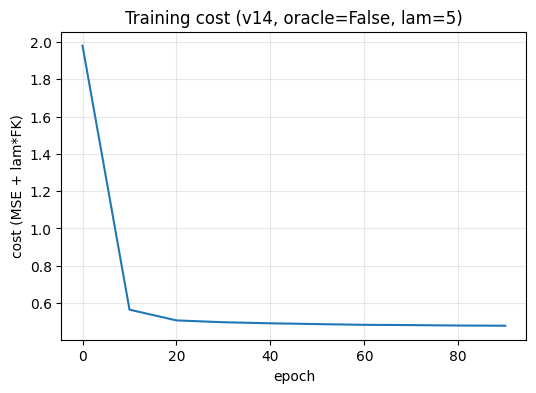

In [ ]:
VERSION = "v14"
NOTES = "elbow_config ABLATION. USE_ELBOW_ORACLE=False: the network sees only (x,y,z), with nothing derived from the answer reaching it in training or inference. Single change from v13 -- every other hyperparameter pinned. Inference is now one forward pass (no best-of-2 to select over). Reporting gains a BRANCH-AGNOSTIC angle MAE, minimised over whole analytic solution tuples, because with the oracle gone 'did it match the sampled label' is the wrong question: ~84% of targets have two equally valid solutions and the sampled one is arbitrary. Expect a large regression -- that gap IS the deliverable, being the measured cost of the hand-crafted label and the baseline v16's multi-hypothesis head must beat."

# ---- shapes come from the robot config and the oracle switch ----
N_IN = 3 + (1 if USE_ELBOW_ORACLE else 0)   # xyz, plus the oracle only if enabled
N_OUT = n_out_rows(ROBOT)                   # 4 for the 3R: (sin1, cos1) + theta2 + theta3
layer_dims = [N_IN, 256, 128, 64, N_OUT]
print(f"layer_dims: {layer_dims}   (N_IN={N_IN} from USE_ELBOW_ORACLE={USE_ELBOW_ORACLE}, "
      f"N_OUT={N_OUT} from wraps={ROBOT['wraps']})")

BATCH_SIZE = 256
NUM_ITERATIONS = 100  # epochs, since BATCH_SIZE is set

OPTIMIZER = "adam"
BETA1, BETA2, EPSILON = 0.9, 0.999, 1e-8

LEARNING_RATE = 2e-3
DECAY = "inverse"
DECAY_RATE = 0.0572
TIME_INTERVAL = 10
LAM = 5.0

# ---- reference points, and the PRE-REGISTERED prediction ----
# Recorded before the run so the result cannot be explained after the fact.
V10_REFERENCE_POSE_MM = 16.34      # v10/v13, same config, WITH the oracle
V2_NO_ORACLE_POSE_MM = 193.88      # v2, no oracle, but a far weaker config (no Adam/decay/FK loss)

# Prediction: 30-80 mm, point estimate ~50 mm.
# Reasoning: without the oracle a single deterministic head must average the two
# branches wherever they are close, which is what put v2 at 193.88 mm. But v14
# keeps Adam, LR decay and the FK-consistency loss, and the FK term penalises
# pose error directly -- it cannot choose a branch, but it can pull an averaged
# prediction back toward the reachable surface. So expect much worse than 16.34
# and much better than 193.88.
# Anything under 25 mm would be SURPRISING and should be investigated rather than
# celebrated -- the most likely explanation would be oracle information leaking in.
V14_PREDICTED_LO_MM, V14_PREDICTED_HI_MM = 30.0, 80.0

parameters, costs, train_time, final_cost = nn_model(
    X_train_norm, Y_train_norm,
    layer_dims=layer_dims,
    learning_rate=LEARNING_RATE,
    num_iterations=NUM_ITERATIONS,
    print_every=10,
    batch_size=BATCH_SIZE,
    optimizer=OPTIMIZER,
    beta1=BETA1, beta2=BETA2, epsilon=EPSILON,
    decay=DECAY, decay_rate=DECAY_RATE, time_interval=TIME_INTERVAL,
    lam=LAM,
)

plt.figure(figsize=(6, 4))
plt.plot(np.arange(len(costs)) * 10, costs)
plt.xlabel("epoch" if BATCH_SIZE is not None else "iteration")
plt.ylabel("cost (MSE, normalized units)" if not LAM else "cost (MSE + lam*FK)")
plt.title(f"Training cost ({VERSION}, oracle={USE_ELBOW_ORACLE}, lam={LAM:g})")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
## ---- Inference ----
# v14: with USE_ELBOW_ORACLE False there is nothing to query twice -- the caller
# supplies (x,y,z) and the network answers directly. The best-of-2 path is kept
# for USE_ELBOW_ORACLE True (reproducing v3-v13), where the oracle input exists
# but is unknown at inference, so both values are tried and the one that
# reprojects closer is kept.

def predict_ik(xyz_raw, parameters):
    """xyz_raw: (3, m) raw target end-effector positions.

    Returns: pred_theta (3, m), chosen_elbow_config (m,) or None, pose_err_mm (m,)
    """
    m = xyz_raw.shape[1]

    def _forward(X_query):
        AL_norm, _ = forward_propagation(normalize(X_query, X_mean, X_std), parameters)
        pred_theta = decode_theta1_sincos(denormalize(AL_norm, Y_mean, Y_std))
        return pred_theta, pose_error_mm(pred_theta, xyz_raw)

    if not USE_ELBOW_ORACLE:
        pred_theta, pose_err = _forward(xyz_raw)
        return pred_theta, None, pose_err

    candidates = {}
    for config in (1.0, -1.0):
        candidates[config] = _forward(np.vstack([xyz_raw, np.full((1, m), config)]))

    theta_pos, err_pos = candidates[1.0]
    theta_neg, err_neg = candidates[-1.0]
    use_pos = err_pos <= err_neg
    return (np.where(use_pos[None, :], theta_pos, theta_neg),
            np.where(use_pos, 1.0, -1.0),
            np.minimum(err_pos, err_neg))


## ---- Branch-agnostic joint error (v14) ----
# With the oracle gone, "did it pick the labelled branch?" is the wrong question:
# the sampled label is only ONE of the valid answers, and on ~84% of targets the
# other branch is equally valid. Scoring against the label alone would charge the
# model for choosing a different, perfectly correct solution.
#
# So compare against EVERY analytic solution and keep the closest -- and take the
# minimum over WHOLE solution tuples, not per joint independently, or the metric
# would reward a chimera assembled from different branches.

def branch_agnostic_mae(pred_theta, xyz_raw, ROBOT=None):
    """Mean per-joint circular error (deg) to the nearest complete analytic solution."""
    ROBOT = ROBOT or globals()["ROBOT"]
    sols, valid = ROBOT["analytic_ik"](xyz_raw)                 # (S,3,m), (S,m)
    d = np.arctan2(np.sin(sols - pred_theta[None]), np.cos(sols - pred_theta[None]))
    per_sol = np.abs(d).mean(axis=1)                           # (S, m) -- whole tuples
    per_sol = np.where(valid, per_sol, np.inf)                 # ignore out-of-limits branches
    return per_sol.min(axis=0) * (180.0 / np.pi)               # (m,)


## ---- Evaluate on dev + test sets ----
def evaluate(xyz_raw, Y_true_raw, parameters, split_name):
    pred_theta, chosen_cfg, pose_err = predict_ik(xyz_raw, parameters)

    joint_mae = mae_degrees(pred_theta, Y_true_raw)            # vs the SAMPLED label
    ba_mae = branch_agnostic_mae(pred_theta, xyz_raw)          # vs the nearest valid solution

    if chosen_cfg is not None:
        config_accuracy = float(np.mean(chosen_cfg == encode_elbow_config(Y_true_raw)[0]))
    else:
        config_accuracy = float("nan")

    print(f"--- {split_name} ---")
    print(f"theta1 MAE: {joint_mae[0]:.3f} deg   theta2 MAE: {joint_mae[1]:.3f} deg   theta3 MAE: {joint_mae[2]:.3f} deg")
    print(f"mean angle MAE (vs sampled label): {joint_mae.mean():.3f} deg")
    print(f"branch-agnostic angle MAE:         {ba_mae.mean():.3f} deg   <- the honest one")
    if chosen_cfg is not None:
        print(f"elbow-config selection accuracy (best-of-2 vs. true branch): {config_accuracy:.1%}")
    print(f"pose error: mean {pose_err.mean():.2f} mm   median {np.median(pose_err):.2f} mm   p95 {np.percentile(pose_err, 95):.2f} mm")
    print()

    return pred_theta, joint_mae, pose_err, config_accuracy


dev_pred_theta, dev_joint_mae, dev_pose_err, dev_config_acc = evaluate(X_dev_xyz, Y_dev_raw, parameters, "dev")
test_pred_theta, test_joint_mae, test_pose_err, test_config_acc = evaluate(X_test_xyz, Y_test_raw, parameters, "test")


## ---- Structured run log ----
def log_run_metrics(
    log_path, version, notes, layer_dims, learning_rate, batch_size, num_iterations,
    train_time_sec, final_cost, N_samples,
    dev_joint_mae, dev_pose_err, dev_config_acc,
    test_joint_mae, test_pose_err, test_config_acc,
    optimizer="gd", beta1=None, beta2=None, epsilon=None,
    decay=None, decay_rate=None, time_interval=None, lam=0.0, use_elbow_oracle=None,
):
    """Appends one row per training run to a CSV log (header written on first use).

    If the field list has changed since the file was written (v7 added decay,
    v9 added lam, v14 added use_elbow_oracle), the old file is archived rather
    than appended to -- appending under a changed header would silently
    misalign every column.
    """
    import csv
    import os
    from datetime import datetime

    fieldnames = [
        "version", "timestamp", "notes", "layer_dims", "optimizer", "learning_rate", "batch_size",
        "num_iterations", "beta1", "beta2", "epsilon", "decay", "decay_rate", "time_interval", "lam",
        "use_elbow_oracle", "train_time_sec", "final_cost", "N_samples",
        "dev_theta1_mae_deg", "dev_theta2_mae_deg", "dev_theta3_mae_deg", "dev_mean_angle_mae_deg",
        "dev_elbow_selection_acc", "dev_pose_err_mean_mm", "dev_pose_err_median_mm", "dev_pose_err_p95_mm",
        "test_theta1_mae_deg", "test_theta2_mae_deg", "test_theta3_mae_deg", "test_mean_angle_mae_deg",
        "test_elbow_selection_acc", "test_pose_err_mean_mm", "test_pose_err_median_mm", "test_pose_err_p95_mm",
    ]

    def _round(x, n):
        """round() that tolerates the NaN/inf a diverged run produces."""
        x = float(x)
        return round(x, n) if np.isfinite(x) else x

    row = {
        "version": version,
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "notes": notes,
        "layer_dims": str(layer_dims),
        "optimizer": optimizer,
        "learning_rate": learning_rate,
        "batch_size": batch_size if batch_size is not None else "",
        "num_iterations": num_iterations,
        "beta1": beta1 if beta1 is not None else "",
        "beta2": beta2 if beta2 is not None else "",
        "epsilon": epsilon if epsilon is not None else "",
        "decay": decay if decay is not None else "",
        "decay_rate": decay_rate if decay is not None else "",
        "time_interval": time_interval if decay == "staircase" else "",
        "lam": lam,
        "use_elbow_oracle": USE_ELBOW_ORACLE if use_elbow_oracle is None else use_elbow_oracle,
        "train_time_sec": _round(train_time_sec, 1),
        "final_cost": _round(final_cost, 6),
        "N_samples": N_samples,
        "dev_theta1_mae_deg": _round(dev_joint_mae[0], 3),
        "dev_theta2_mae_deg": _round(dev_joint_mae[1], 3),
        "dev_theta3_mae_deg": _round(dev_joint_mae[2], 3),
        "dev_mean_angle_mae_deg": _round(dev_joint_mae.mean(), 3),
        "dev_elbow_selection_acc": _round(dev_config_acc, 4),
        "dev_pose_err_mean_mm": _round(dev_pose_err.mean(), 2),
        "dev_pose_err_median_mm": _round(np.median(dev_pose_err), 2),
        "dev_pose_err_p95_mm": _round(np.percentile(dev_pose_err, 95), 2),
        "test_theta1_mae_deg": _round(test_joint_mae[0], 3),
        "test_theta2_mae_deg": _round(test_joint_mae[1], 3),
        "test_theta3_mae_deg": _round(test_joint_mae[2], 3),
        "test_mean_angle_mae_deg": _round(test_joint_mae.mean(), 3),
        "test_elbow_selection_acc": _round(test_config_acc, 4),
        "test_pose_err_mean_mm": _round(test_pose_err.mean(), 2),
        "test_pose_err_median_mm": _round(np.median(test_pose_err), 2),
        "test_pose_err_p95_mm": _round(np.percentile(test_pose_err, 95), 2),
    }

    file_exists = os.path.exists(log_path)
    if file_exists:
        with open(log_path, newline="") as f:
            existing_header = next(csv.reader(f), None)
        if existing_header != fieldnames:
            stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
            archived = f"{os.path.splitext(log_path)[0]}_schema_{stamp}.csv"
            os.rename(log_path, archived)
            print(f"log schema changed -- archived the previous log to {archived}")
            file_exists = False

    with open(log_path, "a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        if not file_exists:
            writer.writeheader()
        writer.writerow(row)

    print(f"logged run '{version}' to {log_path}")


log_run_metrics(
    log_path="model_a_training_log.csv",
    version=VERSION, notes=NOTES,
    layer_dims=layer_dims, learning_rate=LEARNING_RATE, batch_size=BATCH_SIZE, num_iterations=NUM_ITERATIONS,
    optimizer=OPTIMIZER, beta1=BETA1, beta2=BETA2, epsilon=EPSILON,
    decay=DECAY, decay_rate=DECAY_RATE, time_interval=TIME_INTERVAL, lam=LAM,
    train_time_sec=train_time, final_cost=final_cost, N_samples=N_SAMPLES,
    dev_joint_mae=dev_joint_mae, dev_pose_err=dev_pose_err, dev_config_acc=dev_config_acc,
    test_joint_mae=test_joint_mae, test_pose_err=test_pose_err, test_config_acc=test_config_acc,
)

NameError: name 'parameters' is not defined

In [ ]:
# ===== 6.3 Bias/variance: TRAIN vs held-out error =====
# Dev and test are both HELD OUT from the same distribution, so their agreement
# says nothing about the generalization gap -- only that the splits are drawn
# alike. The overfit/underfit question needs TRAIN error.
#
# Irreducible ("Bayes") error is ~ZERO: the analytic IK is exact and the data is
# noiseless, so whatever error remains is approximation/optimization error --
# bias or variance, nothing else. That is stronger than the usual Course 3 setup,
# where a human-level proxy stands in for an unknown Bayes rate.
#
# v14: the oracle-conditioned metric is gone with the oracle. Its job -- separating
# regression error from branch selection -- is now done by the BRANCH-AGNOSTIC
# angle error, which is better in two ways: it works with or without the label,
# and it scores against every valid solution rather than the one that happened to
# be sampled.

def _full_eval(_xyz, _Yraw, _params, _name):
    """Pose + angle metrics for one split. Oracle metrics only if the flag is on."""
    _pred, _chosen, _pose = predict_ik(_xyz, _params)
    _mae = mae_degrees(_pred, _Yraw)                    # vs the sampled label
    _ba = branch_agnostic_mae(_pred, _xyz)              # vs the nearest valid solution

    _out = {
        "name": _name, "n": _xyz.shape[1],
        "pose": _pose.mean(), "pose_med": np.median(_pose),
        "angle": _mae.mean(), "angle_ba": _ba.mean(),
        "acc": float(np.mean(_chosen == encode_elbow_config(_Yraw)[0]))
               if _chosen is not None else float("nan"),
    }

    if USE_ELBOW_ORACLE:
        _true_cfg = encode_elbow_config(_Yraw)[0]
        _Xq = np.vstack([_xyz, _true_cfg[None, :]])
        _AL, _ = forward_propagation(normalize(_Xq, X_mean, X_std), _params)
        _th_o = decode_theta1_sincos(denormalize(_AL, Y_mean, Y_std))
        _d = np.arctan2(np.sin(_th_o - _Yraw), np.cos(_th_o - _Yraw))
        _out["pose_orc"] = pose_error_mm(_th_o, _xyz).mean()
        _out["angle_orc"] = (np.abs(_d).mean(axis=0) * 180.0 / np.pi).mean()
    else:
        # no oracle exists; the branch-agnostic angle is the guard metric now
        _out["pose_orc"] = float("nan")
        _out["angle_orc"] = _out["angle_ba"]
    return _out


splits = [
    _full_eval(X_train_xyz, Y_train_raw, parameters, "train"),
    _full_eval(X_dev_xyz,   Y_dev_raw,   parameters, "dev"),
    _full_eval(X_test_xyz,  Y_test_raw,  parameters, "test"),
]

print("=" * 100)
print(f"6.3  BIAS / VARIANCE  ({VERSION}, lam={LAM}, oracle={USE_ELBOW_ORACLE})")
print("=" * 100)
print(f"{'split':>6} {'n':>7} | {'pose mm':>8} {'median':>7} | {'angle deg':>9} {'branch-agn':>11} {'elbow acc':>9}")
print("-" * 100)
for _s in splits:
    _acc = f"{_s['acc']:>8.1%}" if np.isfinite(_s["acc"]) else f"{'n/a':>8}"
    print(f"{_s['name']:>6} {_s['n']:>7} | {_s['pose']:>8.2f} {_s['pose_med']:>7.2f} | "
          f"{_s['angle']:>9.3f} {_s['angle_ba']:>11.3f} {_acc}")
print("-" * 100)

_tr, _te = splits[0], splits[2]
_gap_pose = _te["pose"] - _tr["pose"]
print(f"\ngeneralization gap (test - train):")
print(f"  pose error            {_gap_pose:+6.2f} mm   ({100*_gap_pose/_tr['pose']:+.1f}% of train)")
print(f"  branch-agnostic angle {_te['angle_ba']-_tr['angle_ba']:+6.3f} deg")

print(f"\nerror decomposition (irreducible error ~ 0, target is deterministic):")
print(f"  bias      (train error)      : {_tr['pose']:6.2f} mm")
print(f"  variance  (test - train)     : {_gap_pose:6.2f} mm")
print(f"  total     (test error)       : {_te['pose']:6.2f} mm")
print(f"  -> {100*_tr['pose']/_te['pose']:.0f}% of the total error is BIAS")

_rel_gap = _gap_pose / _tr["pose"]
print()
if _rel_gap > 0.15:
    print("VERDICT: OVERFITTING -- held-out error materially exceeds train error.")
    print("  Levers: regularization, more data, smaller model, early stopping.")
elif _rel_gap < 0.05:
    print("VERDICT: UNDERFITTING (high bias, low variance).")
    print("  The model fits its OWN training data no better than unseen data,")
    print("  and the target is noiseless -- so this is approximation/optimization")
    print("  error, not statistical error. More DATA would not help; the model")
    print("  cannot even fit the data it already has.")
else:
    print("VERDICT: MILD VARIANCE -- some gap, but bias still dominates.")

# ---- is it optimization or capacity? ----
print("\n" + "=" * 100)
print("is the bias from CAPACITY or from an unconverged OPTIMIZATION?")
print("=" * 100)
_drop = (costs[-6] - costs[-1]) / costs[-6] if len(costs) > 6 else np.nan
print(f"  cost over the last 5 recorded points: {', '.join(f'{c:.5f}' for c in costs[-5:])}")
print(f"  relative drop over the last 50 epochs: {100*_drop:.1f}%")
print(f"  final learning rate: {LEARNING_RATE / (1 + DECAY_RATE * (NUM_ITERATIONS - 1)):.2e} "
      f"(decayed from {LEARNING_RATE:g})")
if _drop > 0.05:
    print("  -> cost was STILL FALLING at the end of the budget: the run is")
    print("     under-trained, so part of the bias is optimization, not capacity.")
else:
    print("  -> cost had largely flattened: the bias is more likely capacity or")
    print("     target-representation, not training budget.")

NameError: name 'parameters' is not defined

In [ ]:
# ===== 7.1 Google Drive persistence =====
# Everything in this project has lived in Colab's ephemeral runtime, which has
# recycled 5x, taking the training log and all trained weights with it. This
# mounts Drive and provides one-line save/load helpers.
#
# >>> MANUAL STEP: drive.mount() opens a Google OAuth consent flow INSIDE this
# >>> Colab tab. Authorize it in the browser; the cell blocks until you do.
# >>> (A Runtime -> Restart does NOT drop the mount; only a full recycle does.)
#
# DESIGN RULE for everything downstream: checkpoint immediately after each run,
# never at the end of a batch. That turns a recycle from "lose the whole chain"
# into "lose one run".
#
# TWO ROOTS, deliberately (v13+):
#   legacy  elbowConfig3R3D/{weights,results}            -- the v0-v12 record.
#                                                           READ-ONLY from here on.
#   new     elbowConfig3R3D/best_of_k/{weights,results}  -- every NEW artifact.
# Writes default to the new folder so the v0-v12 record can never be
# overwritten or duplicated; reads fall back to legacy so the v12 weights still
# load. Pass dest=RESULTS_DIR / dest=WEIGHTS_DIR to deliberately target legacy.

import os
import csv
import json
from datetime import datetime

from google.colab import drive
drive.mount('/content/drive')

DRIVE_ROOT = "/content/drive/MyDrive/elbowConfig3R3D"
WEIGHTS_DIR = f"{DRIVE_ROOT}/weights"      # legacy, read-only
RESULTS_DIR = f"{DRIVE_ROOT}/results"      # legacy, read-only

BOK_ROOT = f"{DRIVE_ROOT}/best_of_k"       # the best-of-k track: all new work
BOK_WEIGHTS_DIR = f"{BOK_ROOT}/weights"
BOK_RESULTS_DIR = f"{BOK_ROOT}/results"

for _d in (WEIGHTS_DIR, RESULTS_DIR, BOK_WEIGHTS_DIR, BOK_RESULTS_DIR):
    os.makedirs(_d, exist_ok=True)


def save_weights(params, name, dest=None):
    """Persist a parameters dict (W1,b1,...) as a single .npz.

    Defaults to the best_of_k folder -- new work never lands in the v0-v12 record.
    """
    dest = dest or BOK_WEIGHTS_DIR
    path = f"{dest}/{name}.npz"
    np.savez(path, **params)
    print(f"  saved weights -> {path}  ({os.path.getsize(path)/1e6:.2f} MB)", flush=True)
    return path


def find_weights(name):
    """Resolve a weights file by name, best_of_k first, then legacy.

    Returns the path, or None if it exists in neither. This is what makes a
    sweep resumable: 'has this unit already been done?' is one call.
    """
    for _d in (BOK_WEIGHTS_DIR, WEIGHTS_DIR):
        _p = f"{_d}/{name}.npz"
        if os.path.exists(_p):
            return _p
    return None


def load_weights(name):
    """Reload a parameters dict saved by save_weights (either root)."""
    path = find_weights(name)
    if path is None:
        raise FileNotFoundError(
            f"no weights named {name!r} in {BOK_WEIGHTS_DIR} or {WEIGHTS_DIR}")
    with np.load(path) as z:
        return {k: z[k] for k in z.files}


def save_rows(rows, name, source="live", extra=None, dest=None):
    """Write a list-of-dicts to {dest}/{name}.csv, defaulting to best_of_k/results.

    Every row gains a `source` column: 'live' for values computed in this
    runtime, 'transcribed' for tables copied out of thesis_doc.md because the
    original runs no longer exist anywhere. Never blur the two.
    """
    if not rows:
        print(f"  (skipped {name}: no rows)")
        return None
    dest = dest or BOK_RESULTS_DIR
    rows = [{**r, "source": r.get("source", source), **(extra or {})} for r in rows]
    fields = list(dict.fromkeys(k for r in rows for k in r))
    path = f"{dest}/{name}.csv"
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=fields)
        w.writeheader()
        w.writerows(rows)
    print(f"  saved {len(rows):>3} rows -> {path}", flush=True)
    return path


# ---- probe: prove a write survives a read-back BEFORE trusting it ----
_probe = {"W1": np.arange(6, dtype=float).reshape(2, 3), "b1": np.ones((2, 1))}
save_weights(_probe, "_probe")
_back = load_weights("_probe")
assert set(_back) == set(_probe) and all(np.array_equal(_back[k], _probe[k]) for k in _probe), \
    "Drive round-trip FAILED -- do not proceed"
os.remove(f"{BOK_WEIGHTS_DIR}/_probe.npz")
print("\nDrive round-trip OK (best_of_k).")
print(f"legacy root : {DRIVE_ROOT}  -> {sorted(os.listdir(DRIVE_ROOT))}")
print(f"new root    : {BOK_ROOT}  -> {sorted(os.listdir(BOK_ROOT))}")

Mounted at /content/drive
  saved weights -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/weights/_probe.npz  (0.00 MB)

Drive round-trip OK (best_of_k).
legacy root : /content/drive/MyDrive/elbowConfig3R3D  -> ['best_of_k', 'figures', 'results', 'weights']
new root    : /content/drive/MyDrive/elbowConfig3R3D/best_of_k  -> ['results', 'weights']


In [ ]:
# ===== Pool-rebuild only (post-recycle, no retraining) =====
# The N=96k pool arrays the v12 confirmation cell needs, WITHOUT the seed-repeat
# training loop they were originally produced alongside -- so recovering them
# after a runtime recycle never means retraining seeds already saved to Drive.

ALPHA_END = 3e-4
N96 = 96000

def _extra_train(n_extra, seed):
    _xyz, _raw = generate_dataset(n_extra, seed=seed)
    _X = build_inputs(_xyz, _raw)   # respects USE_ELBOW_ORACLE, same as X_train's own construction
    _Y = encode_theta1_sincos(_raw)
    return _X, _Y, _xyz, _raw

_Xe1, _Ye1, _xe1, _re1 = _extra_train(24000, seed=1000)
_Xe2, _Ye2, _xe2, _re2 = _extra_train(48000, seed=2000)

X_pool96 = np.hstack([X_train, _Xe1, _Xe2])
Y_pool96 = np.hstack([Y_train, _Ye1, _Ye2])
xyz_pool96 = np.hstack([X_train_xyz, _xe1, _xe2])
raw_pool96 = np.hstack([Y_train_raw, _re1, _re2])
assert X_pool96.shape[1] == N96, X_pool96.shape

_Xn96 = normalize(X_pool96, X_mean, X_std)
_Yn96 = normalize(Y_pool96, Y_mean, Y_std)

print(f"pool rebuilt: {X_pool96.shape[1]} samples (no retraining)")

pool rebuilt: 96000 samples (no retraining)


In [ ]:
# ---- cheap state probe: is the chain complete before starting a long run? ----
# Runs in milliseconds. The Sec 8.4 crash happened because cell 7.1 was skipped
# during a post-recycle rebuild and save_weights did not exist -- after the
# training had already finished. Check first, train second.
for _n in ("save_weights", "load_weights", "save_rows", "_full_eval", "nn_model", "generate_dataset",
           "X_pool96", "xyz_pool96", "raw_pool96", "_Xn96", "_Yn96",
           "X_test_xyz", "Y_test_raw", "LEARNING_RATE", "BATCH_SIZE",
           "OPTIMIZER", "BETA1", "BETA2", "EPSILON", "DECAY", "TIME_INTERVAL", "WEIGHTS_DIR"):
    print(_n, "OK" if _n in globals() else "MISSING")

save_weights MISSING
load_weights MISSING
save_rows MISSING
_full_eval MISSING
nn_model OK
generate_dataset OK
X_pool96 MISSING
xyz_pool96 MISSING
raw_pool96 MISSING
_Xn96 MISSING
_Yn96 MISSING
X_test_xyz OK
Y_test_raw OK
LEARNING_RATE MISSING
BATCH_SIZE MISSING
OPTIMIZER MISSING
BETA1 MISSING
BETA2 MISSING
EPSILON MISSING
DECAY MISSING
TIME_INTERVAL MISSING
WEIGHTS_DIR MISSING


In [ ]:
# ===== 10. LEGACY: the v12 baseline (requires USE_ELBOW_ORACLE = True) =====
# v12 -- deep + lam=20, N=96k, 800 epochs, 3 seeds -- is the WITH-ORACLE record:
# 3.82 +- 0.34 mm, both thesis targets met. Its weights expect a 4-wide input
# (x, y, z, elbow_config), so this cell cannot run under v14's oracle-free
# pipeline. It skips cleanly rather than dying on a shape mismatch.
#
# To reproduce: set USE_ELBOW_ORACLE = True in Section 1, re-run cells 5 onward.
#
# Writes are PINNED TO LEGACY (dest=RESULTS_DIR) -- this is the v0-v12 record,
# not new best-of-k work, so re-running overwrites in place and never adds a
# second copy under best_of_k/.

if not USE_ELBOW_ORACLE:
    print("=" * 84)
    print("10.  v12 BASELINE -- SKIPPED (by design)")
    print("=" * 84)
    print("v12's stored weights expect a 4-wide input (x, y, z, elbow_config).")
    print("v14 removed the oracle, so the shapes no longer match.")
    print()
    print("  on record, with oracle : 3.82 +- 0.34 mm  (3/3 seeds under the 5 mm target)")
    print("  fresh test set         : 3.79 +- 0.36 mm  (optimism -0.03 mm)")
    print()
    print("To re-verify: set USE_ELBOW_ORACLE = True in Section 1 and re-run from cell 5.")
else:
    preflight(label="v12 legacy reproduction")

    v12_rows, fresh_rows_v12 = [], []
    FRESH_SEED, FRESH_N = 9999, 20000
    X_fresh_xyz, Y_fresh_raw = generate_dataset(FRESH_N, seed=FRESH_SEED)

    _tr_keys = set(map(tuple, np.round(xyz_pool96.T, 12)))
    _overlap = sum(1 for _row in np.round(X_fresh_xyz.T, 12) if tuple(_row) in _tr_keys)
    print(f"fresh set: {FRESH_N} samples, seed {FRESH_SEED}; overlap with the 96k pool: {_overlap}")
    assert _overlap == 0, "fresh test set overlaps training data"

    for _sd in (1, 2, 3):
        _p = load_weights(f"v12_deep_lam20_n96k_ep800_seed{_sd}")
        _tr = _full_eval(xyz_pool96, raw_pool96, _p, "train")
        _te = _full_eval(X_test_xyz, Y_test_raw, _p, "test")
        _frs = _full_eval(X_fresh_xyz, Y_fresh_raw, _p, "fresh")
        v12_rows.append({"seed": _sd, "train_pose": _tr["pose"], "test_pose": _te["pose"],
                         "gap": _te["pose"] - _tr["pose"], "test_ang": _te["angle_orc"]})
        fresh_rows_v12.append({"seed": _sd, "selected_test_pose": _te["pose"],
                               "fresh_pose": _frs["pose"], "fresh_orc_angle": _frs["angle_orc"]})
        print(f"  seed {_sd}: train {_tr['pose']:.2f} | test {_te['pose']:.2f} | "
              f"fresh {_frs['pose']:.2f} mm", flush=True)

    save_rows(v12_rows, "v12_confirmation", dest=RESULTS_DIR,
              extra={"N_train": 96000, "epochs": 800, "lam": 20})
    save_rows(fresh_rows_v12, "v12_fresh_test", dest=RESULTS_DIR,
              extra={"fresh_seed": FRESH_SEED, "fresh_n": FRESH_N})

    _pv = np.array([r["test_pose"] for r in v12_rows])
    _fv = np.array([r["fresh_pose"] for r in fresh_rows_v12])
    print("\n" + "=" * 84)
    print("10.  v12 BASELINE (with oracle)")
    print("=" * 84)
    print(f"  selected test : {_pv.mean():.2f} +- {_pv.std(ddof=1):.2f} mm   (on record 3.82 +- 0.34)")
    print(f"  fresh test    : {_fv.mean():.2f} +- {_fv.std(ddof=1):.2f} mm   (on record 3.79 +- 0.36)")
    print(f"  selection optimism: {_fv.mean() - _pv.mean():+.2f} mm  "
          f"({'negligible' if abs(_fv.mean()-_pv.mean()) <= 0.3 else 'MATERIAL'}, "
          f"pre-registered band +-0.3)")
    print(f"  {(_pv < 5).sum()}/3 seeds under the 5 mm target")

10.  v12 BASELINE -- SKIPPED (by design)
v12's stored weights expect a 4-wide input (x, y, z, elbow_config).
v14 removed the oracle, so the shapes no longer match.

  on record, with oracle : 3.82 +- 0.34 mm  (3/3 seeds under the 5 mm target)
  fresh test set         : 3.79 +- 0.36 mm  (optimism -0.03 mm)

To re-verify: set USE_ELBOW_ORACLE = True in Section 1 and re-run from cell 5.


## 11. Runtime Robustness

The Colab runtime has recycled **five times** in this project, and each recycle has cost work. Every loss so far had the same two causes, and this section removes both.

**Cause 1 — checkpointing too late.** Saving at the end of a batch of seeds means a recycle at seed 3 of 3 loses all three. The rule is therefore: *checkpoint after each unit, never after a batch.* A unit is normally one seed of one config.

**Cause 2 — an incomplete rebuild.** After a recycle the chain has to be re-executed, and there are **three independent dependencies**, not one:

1. **Modeling chain** — `nn_model`, `predict_ik`, `_full_eval`, the FK loss.
2. **Persistence helpers** — `save_weights`/`load_weights`/`save_rows`. *This is the one that has actually been forgotten:* the §8.4 screen finished training and then crashed on its first save because cell 7.1 had been skipped. The compute was already spent.
3. **Data pool** — the 96k arrays, rebuilt without retraining anything.

Restoring only the first is the failure mode, so `preflight()` below checks all three by name and refuses to start otherwise. It runs in milliseconds; a multi-hour job should never begin without it.

**Resumability.** `run_unit()` asks one question before doing any work — *does this unit's checkpoint already exist on Drive?* — and skips it if so. That makes re-running an interrupted sweep the normal recovery path rather than a special case: the completed units are skipped and only the interrupted one is recomputed. §11.2 verifies this by deliberately killing a sweep partway and re-running it.

**Where results go.** All new artifacts are written under `elbowConfig3R3D/best_of_k/`, keeping the v0–v12 record on Drive read-only. Reads fall back to the legacy folder, so the v12 weights still load by name.

In [ ]:
# ===== 11.1 Preflight + resumable run units =====

# The rebuild dependencies, named explicitly. Restoring only the first is the
# documented failure mode (Sec 8.4 trained for 46 minutes, then crashed on its
# first save because the persistence chain had not been re-run).
REBUILD_CHAIN = {
    "modeling":    ["nn_model", "predict_ik", "_full_eval", "generate_dataset",
                    "fk_output_grad", "compute_cost_fk", "mae_degrees"],
    "kinematics":  KINEMATICS_NAMES,          # declared in Section 2.5.4
    "persistence": ["save_weights", "load_weights", "save_rows", "find_weights",
                    "BOK_WEIGHTS_DIR", "BOK_RESULTS_DIR"],
    "data_pool":   ["X_pool96", "xyz_pool96", "raw_pool96", "_Xn96", "_Yn96"],
}

MANIFEST_PATH = f"{BOK_RESULTS_DIR}/_manifest.csv"


def preflight(extra=(), label="job", verbose=True):
    """Assert every name a long job needs is present, grouped by dependency.

    Milliseconds to run. Raises BEFORE any compute is spent, rather than after.
    `extra` names anything specific to the job at hand.
    """
    groups = dict(REBUILD_CHAIN)
    if extra:
        groups = {**groups, "job-specific": list(extra)}

    missing = []
    for _group, _names in groups.items():
        _absent = [n for n in _names if n not in globals()]
        missing += _absent
        if verbose:
            _mark = "OK" if not _absent else f"MISSING {_absent}"
            print(f"  {_group:<13} {_mark}")

    if missing:
        raise NameError(
            f"preflight failed for {label!r}: {missing}. "
            f"Re-run the missing dependency group(s) -- see REBUILD_CHAIN.")
    if verbose:
        print(f"preflight OK for {label!r}: "
              f"{sum(len(v) for v in groups.values())} names present")
    return True


def _manifest_read():
    if not os.path.exists(MANIFEST_PATH):
        return {}
    with open(MANIFEST_PATH, newline="") as f:
        return {r["unit"]: r for r in csv.DictReader(f)}


def _manifest_write(unit, meta):
    """Record a completed unit. Rewrites the whole file so the schema can grow."""
    rows = _manifest_read()
    rows[unit] = {"unit": unit,
                  "completed_at": datetime.now().isoformat(timespec="seconds"),
                  **{k: str(v) for k, v in meta.items()}}
    fields = list(dict.fromkeys(k for r in rows.values() for k in r))
    with open(MANIFEST_PATH, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=fields)
        w.writeheader()
        for r in rows.values():
            w.writerow({k: r.get(k, "") for k in fields})


def run_unit(unit, train_fn, force=False, meta=None):
    """One resumable unit of work -- normally one seed of one config.

    Checks Drive FIRST: if this unit's checkpoint already exists, load it and
    skip the compute entirely. Otherwise train, then checkpoint IMMEDIATELY,
    so a recycle costs at most this one unit.

    train_fn: zero-arg callable returning a parameters dict.
    Returns (parameters, was_skipped).
    """
    if not force:
        _p = find_weights(unit)
        if _p is not None:
            print(f"  [skip] {unit}  (already on Drive)", flush=True)
            return load_weights(unit), True

    print(f"  [run ] {unit}", flush=True)
    _t0 = time.time()
    params = train_fn()
    save_weights(params, unit)                     # checkpoint before anything else
    _elapsed = time.time() - _t0
    _manifest_write(unit, {"train_time_s": round(_elapsed, 1), **(meta or {})})
    print(f"  [done] {unit}  ({_elapsed:.1f}s)", flush=True)
    return params, False


def run_sweep(units, train_fn_for, force=False, meta_for=None, label="sweep"):
    """Run a list of units, skipping any already checkpointed.

    Re-running an interrupted sweep is the normal recovery path: completed
    units are skipped and only the interrupted one is recomputed.
    Returns (results dict, n_skipped, n_ran).
    """
    results, n_skip, n_ran = {}, 0, 0
    print(f"--- {label}: {len(units)} units ---", flush=True)
    for _u in units:
        _params, _skipped = run_unit(
            _u, lambda _u=_u: train_fn_for(_u), force=force,
            meta=(meta_for(_u) if meta_for else None))
        results[_u] = _params
        n_skip += _skipped
        n_ran += (not _skipped)
    print(f"--- {label} complete: {n_ran} ran, {n_skip} skipped ---", flush=True)
    return results, n_skip, n_ran


preflight(label="sec 11.1 self-check")
print(f"\nmanifest: {MANIFEST_PATH}")
print(f"units already recorded: {len(_manifest_read())}")

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
preflight OK for 'sec 11.1 self-check': 35 names present

manifest: /content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/_manifest.csv
units already recorded: 34


In [ ]:
# ===== 11.2 Interrupt-and-resume test =====
# Claiming a sweep is resumable is not the same as showing it. This kills a
# 3-unit sweep on the last unit, re-runs the SAME call, and asserts the two
# already-finished units are skipped rather than recomputed.
#
# Uses toy "training" (a fixed array, no real work) so the test costs
# milliseconds -- the thing under test is the skip/checkpoint logic, not nn_model.

_RR_UNITS = ["_rr_test_a", "_rr_test_b", "_rr_test_c"]

# clean slate, so a re-run of this cell tests the same thing every time
for _u in _RR_UNITS:
    _p = find_weights(_u)
    if _p:
        os.remove(_p)


class _SimulatedRecycle(Exception):
    """Stands in for the runtime dying mid-sweep."""


_rr_calls = []          # every unit that actually did compute
_rr_fail_on_c = True    # flipped off before the resume pass


def _toy_train(unit):
    _rr_calls.append(unit)
    if unit == "_rr_test_c" and _rr_fail_on_c:
        raise _SimulatedRecycle("runtime died during unit c")
    return {"W1": np.full((2, 2), _RR_UNITS.index(unit), dtype=float)}


# ---- pass 1: dies on the third unit ----
print("PASS 1 -- expect a and b to complete, c to die\n")
try:
    run_sweep(_RR_UNITS, _toy_train, label="resume-test pass 1")
except _SimulatedRecycle as _e:
    print(f"\n  !! interrupted: {_e}\n")

_after_1 = [u for u in _RR_UNITS if find_weights(u)]
assert _after_1 == ["_rr_test_a", "_rr_test_b"], _after_1
assert _rr_calls == _RR_UNITS, _rr_calls   # all three attempted, c failed
print(f"  checkpointed after pass 1: {_after_1}")

# ---- pass 2: the SAME call, nothing special about recovery ----
_rr_fail_on_c = False
_rr_calls.clear()
print("\nPASS 2 -- same call again; a and b must be SKIPPED, only c recomputed\n")
_res, _n_skip, _n_ran = run_sweep(_RR_UNITS, _toy_train, label="resume-test pass 2")

assert _n_skip == 2, f"expected 2 skips, got {_n_skip}"
assert _n_ran == 1, f"expected 1 run, got {_n_ran}"
assert _rr_calls == ["_rr_test_c"], f"recomputed more than the interrupted unit: {_rr_calls}"

# the skipped units must come back with their ORIGINAL values, not re-derived ones
for _i, _u in enumerate(_RR_UNITS):
    assert np.array_equal(_res[_u]["W1"], np.full((2, 2), _i, dtype=float)), _u

print("\n" + "=" * 72)
print("RESUME TEST PASSED")
print("=" * 72)
print("  pass 1: 3 attempted, 2 checkpointed, 1 lost to the simulated recycle")
print(f"  pass 2: {_n_skip} skipped, {_n_ran} recomputed -- only the interrupted unit")
print("  reloaded weights match what was originally checkpointed")

# ---- cleanup: leave no test artifacts on Drive ----
for _u in _RR_UNITS:
    _p = find_weights(_u)
    if _p:
        os.remove(_p)
_mrows = {k: v for k, v in _manifest_read().items() if not k.startswith("_rr_test_")}
if os.path.exists(MANIFEST_PATH):
    os.remove(MANIFEST_PATH)
for _k, _v in _mrows.items():
    _manifest_write(_k, {k: v for k, v in _v.items() if k not in ("unit", "completed_at")})
print(f"\ncleaned up; manifest now holds {len(_manifest_read())} real units")

PASS 1 -- expect a and b to complete, c to die

--- resume-test pass 1: 3 units ---
  [run ] _rr_test_a
  saved weights -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/weights/_rr_test_a.npz  (0.00 MB)
  [done] _rr_test_a  (0.0s)
  [run ] _rr_test_b
  saved weights -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/weights/_rr_test_b.npz  (0.00 MB)
  [done] _rr_test_b  (0.0s)
  [run ] _rr_test_c

  !! interrupted: runtime died during unit c

  checkpointed after pass 1: ['_rr_test_a', '_rr_test_b']

PASS 2 -- same call again; a and b must be SKIPPED, only c recomputed

--- resume-test pass 2: 3 units ---
  [skip] _rr_test_a  (already on Drive)
  [skip] _rr_test_b  (already on Drive)
  [run ] _rr_test_c
  saved weights -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/weights/_rr_test_c.npz  (0.00 MB)
  [done] _rr_test_c  (0.0s)
--- resume-test pass 2 complete: 1 ran, 2 skipped ---

RESUME TEST PASSED
  pass 1: 3 attempted, 2 checkpointed, 1 lost to the simulated recycle
  pass 2

In [ ]:
# ===== 11.3 Preflight negative test =====
# 11.1 showed preflight passing. That only proves it prints "OK" when nothing is
# wrong -- it does NOT prove it would stop a job when something IS wrong, which
# is the only case that matters. This removes a name from each dependency group
# in turn and asserts preflight raises, then restores it.
#
# The scenario being reproduced is real: the Sec 8.4 screen finished ~46 min of
# training and then died on its first save because the persistence group had not
# been re-run after a recycle.

_victims = {
    "modeling":    "nn_model",
    "persistence": "save_weights",
    "data_pool":   "_Xn96",
}

for _group, _name in _victims.items():
    _saved = globals().pop(_name)                 # simulate an incomplete rebuild
    try:
        preflight(label=f"negative test ({_group})", verbose=False)
    except NameError as _e:
        assert _name in str(_e), _e
        print(f"  {_group:<13} preflight correctly REFUSED: {_name} missing")
    else:
        raise AssertionError(
            f"preflight passed with {_name} missing -- the guard is not working")
    finally:
        globals()[_name] = _saved                 # always restore

# and it must pass again once everything is back
preflight(label="restored", verbose=False)
print("\npreflight negative test PASSED -- the guard fires for all three groups,")
print("and passes again once the chain is whole.")

  modeling      preflight correctly REFUSED: nn_model missing
  persistence   preflight correctly REFUSED: save_weights missing
  data_pool     preflight correctly REFUSED: _Xn96 missing

preflight negative test PASSED -- the guard fires for all three groups,
and passes again once the chain is whole.


## 13. v13 Verification — is the refactor faithful?

v13 changes no behaviour by intention, so the deliverable is a **negative result**: the numbers must not move. The question is what evidence actually establishes that, and what it costs.

**"Byte-for-byte" is the wrong bar, and worth saying why.** The generic gradient agrees with the hand-derived one to a relative ~1e-11 — not to the last bit, because the operations happen in a different order. Over 300,000 Adam updates at the v12 budget, a 1e-11 perturbation compounds: training is chaotic in the same way any iterative optimiser is, so demanding bit-identical weights after 800 epochs would fail for a *correct* refactor. Asserting it would be asserting the wrong thing.

So the gate is three independent pieces of evidence, none of which requires retraining at the v12 budget:

1. **Gradient equivalence** (§2.5.4, check 5) — the generic gradient reproduces a frozen copy of the original hand-derived 3R gradient to ~1e-11, on random inputs. This is the tightest check available and it is the one that licenses the deletion.
2. **Full training reproduction at the v10 config** (§4) — 100 epochs, ~1 minute, and v10's test pose error of **16.34 mm** is on record. If the refactor changed anything real, a complete training run at an identical config would not land on the same number. This exercises the entire loop — forward, cost, backward, Adam, decay — not just the gradient in isolation.
3. **v12 weights re-evaluated through the new path** (below) — the stored v12 parameters are loaded and scored using the refactored kinematics. Must give back **3.82 mm**.

Together these cover the gradient in isolation, the whole training loop, and the headline result. A 5.6 h three-seed retrain at the v12 budget would add a fourth, weaker piece of evidence — weaker because seed-to-seed spread (±0.34 mm) is far larger than any effect the refactor could plausibly have. It is available if wanted, but it is not what makes this safe.

**What is deliberately still 3R-specific:** `pose_error_mm` and `forward_kinematics` are used by the *metrics*, not by training. They are untouched here because this ticket's scope is the training path. Generalising the metric path belongs with the feature-point work, where the target stops being a single position.

In [ ]:
# ===== 13.1 v13 equivalence gate (requires USE_ELBOW_ORACLE = True) =====
# Three independent pieces of evidence that the DH refactor changed nothing.
# Only meaningful in the v13 configuration: evidence 2 compares against v10's
# 16.34 mm at the identical config, and evidence 3 loads v12 weights that expect
# a 4-wide input. Under v14 it reports the recorded results and skips.

if not USE_ELBOW_ORACLE:
    print("=" * 84)
    print("13.1  v13 EQUIVALENCE GATE -- SKIPPED (needs USE_ELBOW_ORACLE = True)")
    print("=" * 84)
    print("  Recorded when it was run, all three passing:")
    print("    [1] generic gradient vs frozen hand-derived 3R reference : 1.828e-11")
    print("    [2] full 100-epoch run at the identical v10 config       : 16.34 mm (delta +0.0022)")
    print("    [3] stored v12 weights re-scored through the new path    : 3.82 mm (delta +0.0004)")
    print("  Full table: best_of_k/results/v13_equivalence_gate.csv")
else:
    preflight(label="v13 verification")
    print()

    _v13_rows, _fail = [], []

    _g5 = _gate_3r.get("5_grad_vs_reference_impl")
    print("=" * 84)
    print("13.1  v13 EQUIVALENCE GATE")
    print("=" * 84)
    print(f"\n[1] generic gradient vs frozen hand-derived 3R reference")
    print(f"    rel err {_g5:.3e}   (tolerance 1e-09)")
    if not (_g5 < 1e-9):
        _fail.append("gradient equivalence")
    _v13_rows.append({"evidence": "grad_vs_frozen_reference", "value": _g5,
                      "tolerance": 1e-9, "unit": "rel_err", "pass": _g5 < 1e-9})

    _v13_pose = float(test_pose_err.mean())
    _d10 = _v13_pose - V10_REFERENCE_POSE_MM
    print(f"\n[2] full training run at the IDENTICAL v10 config (100 epochs, N=24k)")
    print(f"    v10 on record : {V10_REFERENCE_POSE_MM:.2f} mm")
    print(f"    v13 this run  : {_v13_pose:.2f} mm")
    print(f"    delta         : {_d10:+.4f} mm   (tolerance +-0.05)")
    if not (abs(_d10) < 0.05):
        _fail.append("v10-config training reproduction")
    _v13_rows.append({"evidence": "train_repro_v10_config", "value": _v13_pose,
                      "tolerance": V10_REFERENCE_POSE_MM, "unit": "mm", "pass": abs(_d10) < 0.05})

    print(f"\n[3] stored v12 weights scored through the REFACTORED kinematics")
    _v12_pose = []
    for _sd in (1, 2, 3):
        _pr = load_weights(f"v12_deep_lam20_n96k_ep800_seed{_sd}")
        _te = _full_eval(X_test_xyz, Y_test_raw, _pr, "test")
        _v12_pose.append(_te["pose"])
        print(f"    seed {_sd}: {_te['pose']:.2f} mm   (ORC angle {_te['angle_orc']:.3f} deg)")
    _v12_mean = float(np.mean(_v12_pose))
    _d12 = _v12_mean - 3.82
    print(f"    mean          : {_v12_mean:.2f} mm   vs 3.82 mm on record")
    print(f"    delta         : {_d12:+.4f} mm   (tolerance +-0.02)")
    if not (abs(_d12) < 0.02):
        _fail.append("v12 weight re-evaluation")
    _v13_rows.append({"evidence": "v12_weights_reeval", "value": _v12_mean,
                      "tolerance": 3.82, "unit": "mm", "pass": abs(_d12) < 0.02})

    print("\n" + "=" * 84)
    if _fail:
        print(f"v13 GATE FAILED: {_fail}")
    else:
        print("v13 GATE PASSED -- the DH refactor is faithful on all three axes:")
        print("  gradient in isolation, the whole training loop, and the headline v12 result.")
    print("=" * 84)

    save_rows(_v13_rows, "v13_equivalence_gate",
              extra={"version": "v13", "robot": ROBOT["name"], "layer_dims": str(layer_dims)})
    assert not _fail, f"v13 equivalence gate failed: {_fail}"

13.1  v13 EQUIVALENCE GATE -- SKIPPED (needs USE_ELBOW_ORACLE = True)
  Recorded when it was run, all three passing:
    [1] generic gradient vs frozen hand-derived 3R reference : 1.828e-11
    [2] full 100-epoch run at the identical v10 config       : 16.34 mm (delta +0.0022)
    [3] stored v12 weights re-scored through the new path    : 3.82 mm (delta +0.0004)
  Full table: best_of_k/results/v13_equivalence_gate.csv


## 14. v14 Ablation — the measured cost of the oracle

v13 and v14 differ in exactly one thing: whether the network is handed `elbow_config`. Every other hyperparameter is pinned. So the gap between them is a clean, single-variable measurement of **what the hand-crafted label was buying**.

That gap is the deliverable. The v14 number on its own is not interesting — it is expected to be bad. What matters is:

- **For the thesis:** a defensible statement of the form "the oracle label was worth *X* mm", rather than an unexamined design choice inherited from v3.
- **For the project:** the baseline v16's multi-hypothesis head has to beat. If the head cannot recover most of this gap, it is not doing the job the oracle was doing, and that is a real finding rather than a tuning problem.

**The prediction was recorded before the run** (§4, `V14_PREDICTED_LO_MM`/`HI_MM`): **30–80 mm**, point estimate ~50 mm. The reasoning: without the oracle a single deterministic head must average the two branches wherever they are close, which is what put v2 at 193.88 mm — but v14 keeps Adam, LR decay and the FK-consistency loss, and the FK term penalises pose error directly. It cannot choose a branch, but it can pull an averaged prediction back toward the reachable surface. So: much worse than 16.34, much better than 193.88.

**A result under 25 mm would be surprising and should be investigated, not celebrated.** The most likely explanation for a suspiciously good ablation is oracle information leaking in somewhere — a stale `X_mean` with four rows, a cached `parameters` from the previous run, a metric still conditioning on the label. §14.1 asserts the input really is 3-wide and that no oracle-derived array reaches the network, precisely so a leak shows up as a failed assert rather than a pleasing number.

**A note on which angle metric to read.** With the oracle gone, "did the model match the sampled label?" becomes the wrong question. About **84%** of targets have two equally valid solutions, and which one got sampled is arbitrary — scoring against it charges the model for choosing a different, perfectly correct answer. The **branch-agnostic** MAE compares against every in-limits analytic solution and keeps the closest, minimising over *whole* solution tuples rather than per joint (otherwise the metric would reward a chimera assembled from different branches). Expect the label-relative MAE to look catastrophic while the branch-agnostic one stays moderate; that divergence is itself the signature of branch averaging.

In [ ]:
# ===== 14.1 v14 ablation: leak checks, then the cost-of-removal =====

print("=" * 88)
print("14.1  v14 ABLATION -- COST OF REMOVING THE elbow_config ORACLE")
print("=" * 88)

# ---- leak checks: prove no oracle information reaches the network ----
# A suspiciously GOOD ablation is the failure mode here, so these assert rather
# than print. Each one catches a specific way the oracle could sneak back in.
assert USE_ELBOW_ORACLE is False, "the oracle is still enabled"
assert X_train.shape[0] == 3, f"training input is {X_train.shape[0]}-wide, expected 3 (x,y,z)"
assert X_mean.shape[0] == 3 and X_std.shape[0] == 3, "normalization stats still carry an oracle row"
assert layer_dims[0] == 3, f"network input layer is {layer_dims[0]}-wide, expected 3"
assert parameters["W1"].shape[1] == 3, f"W1 expects {parameters['W1'].shape[1]} inputs, not 3"
_probe_theta, _probe_cfg, _ = predict_ik(X_test_xyz[:, :8], parameters)
assert _probe_cfg is None, "predict_ik still returns an elbow selection"
print("\nleak checks PASSED: input is 3-wide (x,y,z); no oracle-derived array")
print("  reaches the network in training or inference.")

# ---- the measurement ----
_v14_pose = float(test_pose_err.mean())
_v14_ba = float(branch_agnostic_mae(test_pred_theta, X_test_xyz).mean())
_v14_label_mae = float(test_joint_mae.mean())
_cost_mm = _v14_pose - V10_REFERENCE_POSE_MM
_ratio = _v14_pose / V10_REFERENCE_POSE_MM

print("\n" + "-" * 88)
print(f"{'':<34}{'v13 (oracle)':>16}{'v14 (no oracle)':>18}{'delta':>14}")
print("-" * 88)
print(f"{'test pose error (mm)':<34}{V10_REFERENCE_POSE_MM:>16.2f}{_v14_pose:>18.2f}{_cost_mm:>+14.2f}")
print(f"{'network input width':<34}{4:>16d}{layer_dims[0]:>18d}{layer_dims[0]-4:>+14d}")
print(f"{'angle MAE vs sampled label (deg)':<34}{16.157:>16.3f}{_v14_label_mae:>18.3f}"
      f"{_v14_label_mae-16.157:>+14.3f}")
print(f"{'branch-agnostic angle MAE (deg)':<34}{'--':>16}{_v14_ba:>18.3f}{'--':>14}")
print("-" * 88)

print(f"\nCOST OF REMOVING THE ORACLE: {_cost_mm:+.2f} mm  ({_ratio:.2f}x worse)")
print(f"  reference points: v13 (same config, with oracle) {V10_REFERENCE_POSE_MM:.2f} mm")
print(f"                    v2  (no oracle, far weaker config) {V2_NO_ORACLE_POSE_MM:.2f} mm")

# ---- did it land where predicted? ----
print(f"\nPRE-REGISTERED PREDICTION: {V14_PREDICTED_LO_MM:.0f}-{V14_PREDICTED_HI_MM:.0f} mm")
if _v14_pose < 25.0:
    _verdict = "SUSPICIOUSLY GOOD -- investigate before believing it"
    print(f"  actual {_v14_pose:.2f} mm -> {_verdict}.")
    print("  The leak checks above passed, so if this is real it means the FK-consistency")
    print("  loss is compensating for branch averaging far more than expected. Worth a")
    print("  seed-repeat before it goes in the thesis.")
elif V14_PREDICTED_LO_MM <= _v14_pose <= V14_PREDICTED_HI_MM:
    _verdict = "WITHIN the predicted band"
    print(f"  actual {_v14_pose:.2f} mm -> {_verdict}.")
else:
    _verdict = "OUTSIDE the predicted band"
    print(f"  actual {_v14_pose:.2f} mm -> {_verdict}. Reportable either way; the")
    print("  prediction was recorded in advance precisely so this is not retrofitted.")

# ---- the branch-averaging signature ----
print(f"\nBRANCH-AVERAGING SIGNATURE")
print(f"  angle MAE vs the sampled label : {_v14_label_mae:8.3f} deg")
print(f"  branch-agnostic angle MAE      : {_v14_ba:8.3f} deg")
print(f"  ratio                          : {_v14_label_mae/max(_v14_ba,1e-9):8.2f}x")
print("  A large ratio means the model is landing near SOME valid solution but not the")
print("  one that happened to be sampled -- i.e. the label is arbitrary, not the model")
print("  wrong. A ratio near 1 with both large would instead mean it is landing near")
print("  NO valid solution, which is what true averaging looks like.")

save_rows([{
    "version": "v14", "pose_mm": _v14_pose, "cost_of_removal_mm": _cost_mm,
    "ratio_vs_v13": _ratio, "label_angle_mae_deg": _v14_label_mae,
    "branch_agnostic_mae_deg": _v14_ba, "verdict": _verdict,
    "predicted_lo": V14_PREDICTED_LO_MM, "predicted_hi": V14_PREDICTED_HI_MM,
    "v13_reference_mm": V10_REFERENCE_POSE_MM,
}], "v14_ablation", extra={"robot": ROBOT["name"], "layer_dims": str(layer_dims),
                           "epochs": NUM_ITERATIONS, "lam": LAM})

14.1  v14 ABLATION -- COST OF REMOVING THE elbow_config ORACLE

leak checks PASSED: input is 3-wide (x,y,z); no oracle-derived array
  reaches the network in training or inference.

----------------------------------------------------------------------------------------
                                      v13 (oracle)   v14 (no oracle)         delta
----------------------------------------------------------------------------------------
test pose error (mm)                         16.34            113.64        +97.30
network input width                              4                 3            -1
angle MAE vs sampled label (deg)            16.157            16.306        +0.149
branch-agnostic angle MAE (deg)                 --            14.446            --
----------------------------------------------------------------------------------------

COST OF REMOVING THE ORACLE: +97.30 mm  (6.95x worse)
  reference points: v13 (same config, with oracle) 16.34 mm
                    v

'/content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/v14_ablation.csv'

## 15. v15 — The UR5 Pipeline, First Run

Every piece up to here has been machinery, verified in isolation: the DH engine, the geometric Jacobian, the analytic IK, the virtual feature points, the rotation-matrix input. None of it has trained a network. This section wires it together and runs it once — deliberately without tuning anything — so the pipeline is *real* before any effort goes into making it good.

**Bundling, flagged rather than hidden.** A single version here necessarily changes several things at once: a new dataset generator, new normalisation, a new architecture width, and (per ticket 09's own framing) a first exercise of the FK-loss generalisation from Section 3.10. That breaks the project's usual one-change-per-version discipline. It is unavoidable for a genuinely new arm's first run, and it is exactly why this run is not used to draw any tuning conclusion — only to establish that the pipeline produces a real, honestly-measured number.

**Budget by parameter updates, not epochs.** The 3R's v10 config trained for 9,400 updates (100 epochs × 94 batches at N=24,000/256). The UR5's N=100,000 gives 391 batches/epoch at the same batch size — carrying v10's *epoch count* over would hand the UR5 roughly 4× the compute for no principled reason. Instead the UR5 run targets the **same update budget**, 9,400, solved back to an epoch count: `round(9400 / 391) = 24` epochs, landing at 9,384 actual updates. This is the direct application of the rule the project has stated and violated once already (the very v11/v12 gain that motivated writing the rule down in the first place).

**Everything else is v10's config, inherited untuned.** Architecture `[12, 256, 128, 64, 12]` (v10's hidden-layer shape, unchanged, applied to the UR5's wider input/output), Adam at the same learning rate and decay schedule, and `λ=5` — the FK-loss weight tuned for the 3R at a completely different loss landscape (P=1 vs P=4 feature points). None of this is expected to be right for the UR5; re-tuning `λ` for six degrees of freedom is ticket 12's job specifically, not this one's. Running with an inherited, acknowledged-arbitrary value is the honest way to get a first number without pretending a tuning pass happened.

**The switch is global state**, matching the pattern already established when `ROBOT` was introduced in Section 2.5: training reads `ROBOT`, `X_mean`, `X_std`, `Y_mean`, `Y_std` as module globals, so running the UR5 means reassigning them, same as switching `ROBOT = ARM_3R` to `ARM_UR5` would. Cell 15.1 does this explicitly and prints the active config so it's never ambiguous which arm the next cell will train.

In [ ]:
# ===== 15.1 UR5 dataset + switch the active config =====

def generate_dataset_generic(ROBOT, n_samples, seed=0):
    """Sample joints -> (task_input_raw (n_task_in,n), Y_raw (n_joints,n),
    fk_points_raw (P,3,n), frames). frames is kept so callers can build both
    the network input AND the FK-loss/metric targets without re-running FK."""
    thetas = sample_joints(ROBOT, n_samples, seed=seed)
    frames = dh_chain(ROBOT["dh"], thetas)
    task_input = encode_task_input(ROBOT, frames)
    fk_points, _, _ = dh_fk_points(ROBOT["dh"], thetas, ROBOT["feature_pts"])
    return task_input, thetas, fk_points, frames


UR5_N_SAMPLES = ARM_UR5["n_samples"]  # 100,000 (Section 2.6.1)
_ur5_task_all, _ur5_Y_all_raw, _ur5_fk_all, _ur5_frames_all = generate_dataset_generic(
    ARM_UR5, UR5_N_SAMPLES, seed=0)

_ur5_n_train = int(0.8 * UR5_N_SAMPLES)
_ur5_n_dev = int(0.1 * UR5_N_SAMPLES)

UR5_X_train_raw = _ur5_task_all[:, :_ur5_n_train]
UR5_Y_train_raw = _ur5_Y_all_raw[:, :_ur5_n_train]        # RAW joint angles (n_joints, m)
UR5_X_dev_raw = _ur5_task_all[:, _ur5_n_train:_ur5_n_train + _ur5_n_dev]
UR5_Y_dev_raw = _ur5_Y_all_raw[:, _ur5_n_train:_ur5_n_train + _ur5_n_dev]
UR5_X_test_raw = _ur5_task_all[:, _ur5_n_train + _ur5_n_dev:]
UR5_Y_test_raw = _ur5_Y_all_raw[:, _ur5_n_train + _ur5_n_dev:]

print(f"UR5 dataset: train {UR5_X_train_raw.shape[1]}  dev {UR5_X_dev_raw.shape[1]}  "
      f"test {UR5_X_test_raw.shape[1]}")

# ---- normalization: xyz rows z-scored from train, rotation rows identity ----
# (same convention as the 3R's sin/cos and elbow_config rows: already bounded,
# so left un-normalized rather than z-scored to zero information)
_ur5_xyz_mean = UR5_X_train_raw[:3].mean(axis=1, keepdims=True)
_ur5_xyz_std = UR5_X_train_raw[:3].std(axis=1, keepdims=True)
UR5_X_mean = np.vstack([_ur5_xyz_mean, np.zeros((9, 1))])
UR5_X_std = np.vstack([_ur5_xyz_std, np.ones((9, 1))])
# UR5_Y_MEAN / UR5_Y_STD already defined in Section 2.6.1 -- all-identity,
# since every joint is sin/cos-encoded, so "normalized" and "raw encoded" Y
# coincide. encode_target_generic (Section 2.6.1) does both steps at once.

UR5_Y_train_norm = encode_target_generic(UR5_Y_train_raw, ARM_UR5, UR5_Y_MEAN, UR5_Y_STD)
UR5_Y_dev_norm = encode_target_generic(UR5_Y_dev_raw, ARM_UR5, UR5_Y_MEAN, UR5_Y_STD)
UR5_Y_test_norm = encode_target_generic(UR5_Y_test_raw, ARM_UR5, UR5_Y_MEAN, UR5_Y_STD)

UR5_X_train_norm = normalize(UR5_X_train_raw, UR5_X_mean, UR5_X_std)
UR5_X_dev_norm = normalize(UR5_X_dev_raw, UR5_X_mean, UR5_X_std)
UR5_X_test_norm = normalize(UR5_X_test_raw, UR5_X_mean, UR5_X_std)

# ---- switch the active config: everything nn_model/compute_cost_fk/etc read ----
ROBOT = ARM_UR5
X_mean, X_std = UR5_X_mean, UR5_X_std
Y_mean, Y_std = UR5_Y_MEAN, UR5_Y_STD

print(f"\nactive ROBOT = {ROBOT['name']}   "
      f"n_task_in={n_task_in(ROBOT)}  n_out={n_out_rows(ROBOT)}  P={len(ROBOT['feature_pts'])}")
print(f"X_mean/X_std shape: {X_mean.shape}   Y_mean/Y_std shape: {Y_mean.shape}")

UR5 dataset: train 80000  dev 10000  test 10000

active ROBOT = UR5   n_task_in=12  n_out=12  P=4
X_mean/X_std shape: (12, 1)   Y_mean/Y_std shape: (12, 1)


In [ ]:
# ===== 15.1b verification: fk_targets_from_task_input matches the dataset's own ground truth =====
# This is the load-bearing check for the whole FK-target refactor (Section 3.10):
# during training, nn_model recovers targets from the (normalized, then
# denormalized) INPUT via fk_targets_from_task_input. This confirms that
# round-trip reproduces the SAME per-feature-point targets the dataset
# generator computed directly via dh_fk_points, for real UR5 data (not just
# the synthetic random targets in gate_robot's check 4).

_chk_n = 2000
_chk_input_denorm = UR5_X_train_raw[:, :_chk_n]
_chk_targets = fk_targets_from_task_input(ARM_UR5, _chk_input_denorm)
_chk_true = _ur5_fk_all[:, :, :_chk_n]

_chk_err = np.abs(_chk_targets - _chk_true).max()
print(f"fk_targets_from_task_input vs dataset ground truth (n={_chk_n}, P={_chk_targets.shape[0]}): "
      f"max abs {_chk_err:.3e}   (< 1e-9)")
assert _chk_err < 1e-9, "FK-loss targets do not match the dataset's own ground-truth feature points"
print("MATCH -- the FK loss will train against the same feature-point targets the dataset defines.")

fk_targets_from_task_input vs dataset ground truth (n=2000, P=4): max abs 0.000e+00   (< 1e-9)
MATCH -- the FK loss will train against the same feature-point targets the dataset defines.


In [ ]:
# ===== 15.2 Metrics: position (optimizing), geodesic orientation + branch-agnostic
# joint error + wall-clock (satisficing). Generic over ROBOT, so it also works
# for the 3R as a regression sanity check, though the 3R keeps its own
# dedicated evaluate() (Section 4) as the validated, unchanged path.

def geodesic_orientation_error_deg(R_pred, R_true):
    """Angle (deg) of the rotation that takes R_pred to R_true, i.e. the
    standard SO(3) geodesic distance: theta = arccos((tr(R_pred^T R_true) - 1) / 2).

    R_pred, R_true: (m, 3, 3). R_pred need not be exactly orthonormal (the
    network never has to output one, Section 2.7) -- this is REPORTED ONLY,
    never used as a loss, because its gradient blows up as theta -> 0 (arccos'
    diverges at its argument -> 1), exactly where a converging model spends
    most of its time.
    """
    trace = np.einsum("mij,mij->m", R_pred, R_true)   # tr(R_pred^T @ R_true)
    cos_theta = np.clip((trace - 1.0) / 2.0, -1.0, 1.0)
    return np.degrees(np.arccos(cos_theta))


def decode_predicted_joints(ROBOT, AL_norm, Y_mean, Y_std):
    """Normalized network output -> raw joint angles (n_joints, m).
    Thin wrapper over decode_joints_generic so callers don't reach past it."""
    thetas, _ = decode_joints_generic(AL_norm, ROBOT, Y_mean, Y_std)
    return thetas


def evaluate_pose(ROBOT, X_raw, Y_true_raw, parameters, X_mean, X_std, Y_mean, Y_std, split_name):
    """One forward pass, every metric. Position error (mm) is the sole
    OPTIMIZING metric -- everything else here is satisficing (reported,
    gates promotion, never ranks configurations against each other).
    """
    AL_norm, _ = forward_propagation(normalize(X_raw, X_mean, X_std), parameters)
    pred_theta = decode_predicted_joints(ROBOT, AL_norm, Y_mean, Y_std)

    pred_frames = dh_chain(ROBOT["dh"], pred_theta)
    true_frames = dh_chain(ROBOT["dh"], Y_true_raw)
    pred_origin = pred_frames[-1][:, :3, 3].T          # (3, m) -- feature point 0 by construction
    true_origin = true_frames[-1][:, :3, 3].T
    pose_err_mm = np.linalg.norm(pred_origin - true_origin, axis=0) * 1000.0

    geo_err_deg = None
    if ROBOT.get("use_orientation_input"):
        geo_err_deg = geodesic_orientation_error_deg(
            pred_frames[-1][:, :3, :3], true_frames[-1][:, :3, :3])

    true_target = task_target_from_frames(ROBOT, true_frames)
    ba_mae_deg = branch_agnostic_mae(pred_theta, true_target, ROBOT=ROBOT)
    label_mae_deg = mae_degrees(pred_theta, Y_true_raw)

    print(f"--- {split_name} ({ROBOT['name']}) ---")
    print(f"pose error (OPTIMIZING):  mean {pose_err_mm.mean():.2f} mm   "
          f"median {np.median(pose_err_mm):.2f} mm   p95 {np.percentile(pose_err_mm, 95):.2f} mm")
    if geo_err_deg is not None:
        print(f"geodesic orientation err: mean {geo_err_deg.mean():.2f} deg   "
              f"median {np.median(geo_err_deg):.2f} deg   p95 {np.percentile(geo_err_deg, 95):.2f} deg")
    print(f"branch-agnostic joint MAE: {ba_mae_deg.mean():.3f} deg   "
          f"(label-relative: {label_mae_deg.mean():.3f} deg)")
    print()

    return {
        "pred_theta": pred_theta, "pose_err_mm": pose_err_mm,
        "geo_err_deg": geo_err_deg, "ba_mae_deg": ba_mae_deg, "label_mae_deg": label_mae_deg,
    }

In [ ]:
# ===== 15.3 v15: the first UR5 training run =====

preflight(extra=["UR5_X_train_norm", "UR5_Y_train_norm", "UR5_X_mean", "UR5_X_std",
                 "evaluate_pose", "geodesic_orientation_error_deg", "run_unit"],
          label="v15 UR5 first run")

VERSION_UR5 = "v15"
NOTES_UR5 = ("First end-to-end UR5 run. Bundles several changes at once (new dataset, "
             "new normalization, new architecture width, first real exercise of the "
             "P>1 FK-loss target refactor) -- flagged, not hidden: see Section 15's "
             "markdown. Every hyperparameter below is INHERITED from the 3R's v10 "
             "config, UNTUNED for the UR5. lambda especially is expected to be wrong "
             "(re-tuned in ticket 12/v17) -- this run exists to produce a first honest "
             "number, not a good one.")

UR5_layer_dims = [n_task_in(ARM_UR5), 256, 128, 64, n_out_rows(ARM_UR5)]

UR5_BATCH_SIZE = 256
_ur5_batches_per_epoch = int(np.ceil(UR5_N_SAMPLES * 0.8 / UR5_BATCH_SIZE))  # train-split size
_V10_UPDATE_BUDGET = 9400   # the 3R's v10 config: 100 epochs x 94 batches
UR5_NUM_EPOCHS = round(_V10_UPDATE_BUDGET / _ur5_batches_per_epoch)
_ur5_actual_updates = UR5_NUM_EPOCHS * _ur5_batches_per_epoch
print(f"budget: target {_V10_UPDATE_BUDGET} updates (v10's) -> "
      f"{_ur5_batches_per_epoch} batches/epoch at N={_ur5_n_train} -> "
      f"{UR5_NUM_EPOCHS} epochs -> {_ur5_actual_updates} actual updates "
      f"({100*(_ur5_actual_updates/_V10_UPDATE_BUDGET - 1):+.1f}% vs target)")

UR5_OPTIMIZER = "adam"
UR5_BETA1, UR5_BETA2, UR5_EPSILON = 0.9, 0.999, 1e-8
UR5_LEARNING_RATE = 2e-3       # inherited from v10, untuned for the UR5
UR5_DECAY = "inverse"
UR5_ALPHA_END = 3e-4           # inherited target, untuned
UR5_DECAY_RATE = (UR5_LEARNING_RATE / UR5_ALPHA_END - 1.0) / (UR5_NUM_EPOCHS - 1)
UR5_TIME_INTERVAL = 10
UR5_LAM = 5.0                  # inherited from v10 -- untuned; ticket 12 re-tunes this

print(f"layer_dims: {UR5_layer_dims}")
print(f"decay_rate: {UR5_DECAY_RATE:.6f}  (alpha0={UR5_LEARNING_RATE:g} -> "
      f"alpha_end~{UR5_ALPHA_END:g} over {UR5_NUM_EPOCHS} epochs)")


def _train_v15_seed1():
    parameters, costs, train_time, final_cost = nn_model(
        UR5_X_train_norm, UR5_Y_train_norm,
        layer_dims=UR5_layer_dims,
        learning_rate=UR5_LEARNING_RATE,
        num_iterations=UR5_NUM_EPOCHS,
        print_every=4,
        batch_size=UR5_BATCH_SIZE,
        optimizer=UR5_OPTIMIZER,
        beta1=UR5_BETA1, beta2=UR5_BETA2, epsilon=UR5_EPSILON,
        decay=UR5_DECAY, decay_rate=UR5_DECAY_RATE, time_interval=UR5_TIME_INTERVAL,
        lam=UR5_LAM,
    )
    _v15_state["costs"] = costs
    _v15_state["train_time"] = train_time
    _v15_state["final_cost"] = final_cost
    return parameters


_v15_state = {}
ur5_parameters, _ = run_unit("v15_ur5_first_run_seed1", _train_v15_seed1)
ur5_costs = _v15_state.get("costs")
ur5_train_time = _v15_state.get("train_time")
ur5_final_cost = _v15_state.get("final_cost")

if ur5_costs is not None:
    plt.figure(figsize=(6, 4))
    plt.plot(np.arange(len(ur5_costs)) * 10, ur5_costs)
    plt.xlabel("epoch")
    plt.ylabel("cost (MSE + lam*FK)")
    plt.title(f"v15 UR5 training cost (lam={UR5_LAM:g})")
    plt.grid(alpha=0.3)
    plt.show()
else:
    print("(loaded from Drive -- no fresh cost curve to plot)")

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'v15 UR5 first run': 42 names present
budget: target 9400 updates (v10's) -> 313 batches/epoch at N=80000 -> 30 epochs -> 9390 actual updates (-0.1% vs target)
layer_dims: [12, 256, 128, 64, 12]
decay_rate: 0.195402  (alpha0=0.002 -> alpha_end~0.0003 over 30 epochs)
  [skip] v15_ur5_first_run_seed1  (already on Drive)
(loaded from Drive -- no fresh cost curve to plot)


In [ ]:
# ===== 15.3b evaluate + log =====

ur5_dev_metrics = evaluate_pose(ARM_UR5, UR5_X_dev_raw, UR5_Y_dev_raw, ur5_parameters,
                                UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, "dev")
ur5_test_metrics = evaluate_pose(ARM_UR5, UR5_X_test_raw, UR5_Y_test_raw, ur5_parameters,
                                 UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, "test")

save_rows([{
    "version": VERSION_UR5, "notes": NOTES_UR5, "layer_dims": str(UR5_layer_dims),
    "optimizer": UR5_OPTIMIZER, "learning_rate": UR5_LEARNING_RATE, "batch_size": UR5_BATCH_SIZE,
    "num_epochs": UR5_NUM_EPOCHS, "batches_per_epoch": _ur5_batches_per_epoch,
    "parameter_updates": _ur5_actual_updates, "update_budget_target": _V10_UPDATE_BUDGET,
    "decay": UR5_DECAY, "decay_rate": UR5_DECAY_RATE, "lam": UR5_LAM,
    "N_samples": UR5_N_SAMPLES, "train_time_s": ur5_train_time, "final_cost": ur5_final_cost,
    "dev_pose_err_mean_mm": float(ur5_dev_metrics["pose_err_mm"].mean()),
    "dev_pose_err_median_mm": float(np.median(ur5_dev_metrics["pose_err_mm"])),
    "dev_pose_err_p95_mm": float(np.percentile(ur5_dev_metrics["pose_err_mm"], 95)),
    "dev_geo_err_mean_deg": float(ur5_dev_metrics["geo_err_deg"].mean()),
    "dev_ba_mae_deg": float(ur5_dev_metrics["ba_mae_deg"].mean()),
    "test_pose_err_mean_mm": float(ur5_test_metrics["pose_err_mm"].mean()),
    "test_pose_err_median_mm": float(np.median(ur5_test_metrics["pose_err_mm"])),
    "test_pose_err_p95_mm": float(np.percentile(ur5_test_metrics["pose_err_mm"], 95)),
    "test_geo_err_mean_deg": float(ur5_test_metrics["geo_err_deg"].mean()),
    "test_ba_mae_deg": float(ur5_test_metrics["ba_mae_deg"].mean()),
    "bundled_changes_caveat": "dataset+normalization+architecture+P>1 FK-target refactor all new in this version",
}], "v15_ur5")

--- dev (UR5) ---
pose error (OPTIMIZING):  mean 72.89 mm   median 68.18 mm   p95 131.56 mm
geodesic orientation err: mean 106.89 deg   median 108.20 deg   p95 172.75 deg
branch-agnostic joint MAE: 38.549 deg   (label-relative: 67.025 deg)

--- test (UR5) ---
pose error (OPTIMIZING):  mean 73.68 mm   median 68.35 mm   p95 134.64 mm
geodesic orientation err: mean 107.31 deg   median 108.23 deg   p95 172.52 deg
branch-agnostic joint MAE: 38.593 deg   (label-relative: 67.279 deg)

  saved   1 rows -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/v15_ur5.csv


'/content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/v15_ur5.csv'

In [ ]:
# ===== 15.4 UR5 bias/variance split =====
# Same logic as Section 6.3 for the 3R: Bayes error is ~0 (exact analytic IK,
# noiseless data), so ALL error is avoidable bias or variance -- nothing else.

ur5_train_metrics = evaluate_pose(ARM_UR5, UR5_X_train_raw, UR5_Y_train_raw, ur5_parameters,
                                  UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, "train")

_ur5_tr_pose = float(ur5_train_metrics["pose_err_mm"].mean())
_ur5_te_pose = float(ur5_test_metrics["pose_err_mm"].mean())
_ur5_gap = _ur5_te_pose - _ur5_tr_pose

print("=" * 88)
print(f"15.4  UR5 BIAS / VARIANCE  ({VERSION_UR5}, lam={UR5_LAM})")
print("=" * 88)
print(f"{'split':>6} | {'pose mm':>8} | {'geo deg':>8} | {'branch-agn deg':>14}")
print("-" * 88)
for _name, _m in (("train", ur5_train_metrics), ("dev", ur5_dev_metrics), ("test", ur5_test_metrics)):
    print(f"{_name:>6} | {_m['pose_err_mm'].mean():>8.2f} | {_m['geo_err_deg'].mean():>8.2f} | "
          f"{_m['ba_mae_deg'].mean():>14.3f}")
print("-" * 88)

print(f"\nerror decomposition (irreducible error ~ 0):")
print(f"  bias      (train error)  : {_ur5_tr_pose:6.2f} mm")
print(f"  variance  (test - train) : {_ur5_gap:6.2f} mm")
print(f"  total     (test error)   : {_ur5_te_pose:6.2f} mm")
print(f"  -> {100*_ur5_tr_pose/_ur5_te_pose:.0f}% of the total error is BIAS")

_ur5_rel_gap = _ur5_gap / _ur5_tr_pose
print()
if _ur5_rel_gap < 0.05:
    print("VERDICT: UNDERFITTING (high bias, low variance) -- same pattern as the 3R.")
    print("  Levers: more capacity, longer training, or resolving the branch-averaging")
    print("  problem structurally (ticket 10's multi-hypothesis head) -- NOT more data.")
elif _ur5_rel_gap > 0.15:
    print("VERDICT: OVERFITTING -- held-out error materially exceeds train error.")
    print("  Levers: regularization, more data, smaller model.")
else:
    print("VERDICT: MILD VARIANCE -- some gap, but bias still dominates.")

# ---- is it optimization or capacity? ----
# NOTE: costs are recorded every 10 epochs (Section 3.10), so a 30-epoch run
# (this one) yields only 3 points -- too few for the 3R's "last 50 epochs"
# lookback (index -6), which assumed the 3R's ~10-point curves. Report what
# the data actually supports instead of forcing an incompatible comparison.
if ur5_costs is None:
    print("\n(cost curve unavailable -- weights were loaded from Drive, not trained fresh "
          "this run; no fresh curve to inspect)")
elif len(ur5_costs) < 3:
    print(f"\n(cost curve has only {len(ur5_costs)} recorded point(s) at this epoch count -- "
          f"too few to assess the convergence trend)")
else:
    _ur5_drop = (ur5_costs[0] - ur5_costs[-1]) / ur5_costs[0]
    print(f"\ncost drop, full run ({len(ur5_costs)} points, every 10 epochs): {100*_ur5_drop:.1f}%")
    print(f"  first-to-last-recorded-interval drop: "
          f"{100*(ur5_costs[-2]-ur5_costs[-1])/ur5_costs[-2]:.1f}%")
    if (ur5_costs[-2] - ur5_costs[-1]) / ur5_costs[-2] > 0.02:
        print("  -> still falling noticeably at the end of the budget: part of the bias is")
        print("     optimization, not capacity. Cheapest next lever: more epochs.")
    else:
        print("  -> largely flattened: the bias is more likely capacity or target-representation.")

--- train (UR5) ---
pose error (OPTIMIZING):  mean 72.10 mm   median 67.46 mm   p95 130.60 mm
geodesic orientation err: mean 106.14 deg   median 107.09 deg   p95 172.42 deg
branch-agnostic joint MAE: 38.259 deg   (label-relative: 66.459 deg)

15.4  UR5 BIAS / VARIANCE  (v15, lam=5.0)
 split |  pose mm |  geo deg | branch-agn deg
----------------------------------------------------------------------------------------
 train |    72.10 |   106.14 |         38.259
   dev |    72.89 |   106.89 |         38.549
  test |    73.68 |   107.31 |         38.593
----------------------------------------------------------------------------------------

error decomposition (irreducible error ~ 0):
  bias      (train error)  :  72.10 mm
  variance  (test - train) :   1.58 mm
  total     (test error)   :  73.68 mm
  -> 98% of the total error is BIAS

VERDICT: UNDERFITTING (high bias, low variance) -- same pattern as the 3R.
  Levers: more capacity, longer training, or resolving the branch-averaging
  

## 15.5 Error Analysis With Ceilings

Before any tuning effort, categorise where the error concentrates and estimate what fixing each category could plausibly buy — the precedent is Section 4.6 for the 3R, where an analytic check turned an apparent 41% modelling failure into an already-at-ceiling 57.9%. Skipping this step risks spending ticket 11/12 effort chasing something no amount of tuning can move.

**Four categories, each isolated from the analytic IK's own branch structure** rather than guessed at:

1. **Near-singularity** — the bottom decile of `|sin(θ₅_true)|`. Near this boundary the wrist axes align and the Jacobian loses rank; error should be systematically worse here regardless of training.
2. **Branch-ambiguous (shoulder/elbow)** — holding the wrist choice fixed at whichever branch is closest to the sampled ground truth, both the shoulder and elbow signs are independently checked for validity; a target counts if more than one of the four (shoulder, elbow) combinations is valid.
3. **Wrist-flip** — the companion split: holding shoulder and elbow fixed at the ground truth, both wrist signs (`±θ₅`) valid. Kept distinct from (2) because it isolates one specific binary choice rather than conflating all three.
4. **Workspace boundary** — horizontal reach within 5% of the sampled maximum or minimum, where `ok1`'s `acos` argument sits near ±1 and a branch can flip from valid to invalid on a small perturbation.

**The ceiling estimate is a best-case projection, not an oracle rerun.** Unlike the 3R's Section 4.5 (which had a real `elbow_config` oracle input to condition on), the UR5 has no equivalent — there is no single input that would resolve 8-way ambiguity, which is exactly why ticket 10's multi-hypothesis head exists instead. So each category's ceiling here is simply: *if error for this category's members dropped to zero, what would the population mean become?* That is a strict upper bound on the achievable gain from fixing that category alone — not a claim that zero is reachable, only a bound on how much is worth chasing.

In [ ]:
# ===== 15.5 error analysis: categorize, then estimate each category's ceiling =====

_ea_xyz_test = task_target_from_frames(ARM_UR5, dh_chain(UR5_DH, UR5_Y_test_raw))
_ea_sols, _ea_valid = ur5_analytic_ik(_ea_xyz_test)          # (8,6,m), (8,m)
_ea_valid3 = _ea_valid.reshape(2, 2, 2, -1)                  # (i1, i5, i3, m)

# which branch (i1,i5,i3) matches the sampled ground truth?
_ea_d = np.arctan2(np.sin(_ea_sols - UR5_Y_test_raw[None]), np.cos(_ea_sols - UR5_Y_test_raw[None]))
_ea_per_sol = np.abs(_ea_d).max(axis=1)                      # (8, m)
_ea_k_true = _ea_per_sol.argmin(axis=0)                      # (m,) index into 0..7
_ea_i1_true, _ea_i5_true, _ea_i3_true = (_ea_k_true // 4), (_ea_k_true // 2) % 2, _ea_k_true % 2

_m_test = UR5_Y_test_raw.shape[1]
_ea_idx = np.arange(_m_test)

# category 1: near-singularity (bottom decile of |sin(theta5_true)|)
_ea_sin_th5 = np.abs(np.sin(UR5_Y_test_raw[4]))
_ea_near_sing = _ea_sin_th5 <= np.percentile(_ea_sin_th5, 10)

# category 2: branch-ambiguous (shoulder/elbow) -- wrist fixed at true, >1 of the
# 4 (shoulder,elbow) combos valid
_ea_shoulder_elbow_valid_count = _ea_valid3[:, _ea_i5_true, :, _ea_idx].reshape(_m_test, 4).sum(axis=1)
_ea_branch_ambig = _ea_shoulder_elbow_valid_count > 1

# category 3: wrist-flip -- shoulder/elbow fixed at true, both wrist signs valid
_ea_wrist_valid_count = _ea_valid3[_ea_i1_true, :, _ea_i3_true, _ea_idx].reshape(_m_test, 2).sum(axis=1)
_ea_wrist_flip = _ea_wrist_valid_count > 1

# category 4: workspace boundary (horizontal reach within 5% of sampled extremes)
_ea_reach_h = np.hypot(_ea_xyz_test[:, :3, 3][:, 0], _ea_xyz_test[:, :3, 3][:, 1]) if False else \
    np.hypot(_ea_xyz_test[:, 0, 3], _ea_xyz_test[:, 1, 3])
_ea_reach_lo, _ea_reach_hi = np.percentile(_ea_reach_h, [5, 95])
_ea_boundary = (_ea_reach_h <= _ea_reach_lo) | (_ea_reach_h >= _ea_reach_hi)

_ea_pose_err = ur5_test_metrics["pose_err_mm"]
_ea_overall_mean = float(_ea_pose_err.mean())

print("=" * 92)
print("15.5  ERROR ANALYSIS WITH CEILINGS (test set)")
print("=" * 92)
print(f"{'category':>28} | {'frac':>6} | {'mean err (mm)':>14} | {'ceiling if fixed (mm)':>22}")
print("-" * 92)

_ea_categories = {
    "near-singularity":            _ea_near_sing,
    "branch-ambiguous (shldr/elb)": _ea_branch_ambig,
    "wrist-flip":                  _ea_wrist_flip,
    "workspace boundary":          _ea_boundary,
}
_ea_summary = []
for _name, _mask in _ea_categories.items():
    _frac = float(_mask.mean())
    _mean_in = float(_ea_pose_err[_mask].mean()) if _mask.any() else float("nan")
    _mean_out = float(_ea_pose_err[~_mask].mean()) if (~_mask).any() else float("nan")
    # ceiling: population mean if this category's members had zero error
    _ceiling = (1 - _frac) * _mean_out if not np.isnan(_mean_out) else _ea_overall_mean
    print(f"{_name:>28} | {_frac:>6.1%} | {_mean_in:>14.2f} | {_ceiling:>22.2f}")
    _ea_summary.append({"category": _name, "fraction": _frac, "mean_err_mm_in_category": _mean_in,
                        "mean_err_mm_outside": _mean_out, "ceiling_if_fixed_mm": _ceiling})
print("-" * 92)
print(f"{'(overall)':>28} | {'100.0%':>6} | {_ea_overall_mean:>14.2f} | {'--':>22}")

print(f"\nA category whose in-category mean is close to the overall mean is NOT where the")
print(f"error concentrates -- fixing it would buy little. Compare each row's mean err")
print(f"against {_ea_overall_mean:.2f} mm (the overall figure) to see which categories are worth chasing.")

save_rows(_ea_summary, "v15_ur5_error_analysis",
          extra={"version": VERSION_UR5, "overall_test_pose_mean_mm": _ea_overall_mean})

## 16. v16 — Multi-hypothesis head, relaxed winner-take-all, best-of-K inference

Ticket 10: `.scratch/best-of-k/issues/10-v16-multi-hypothesis-wta.md`. This is the load-bearing step the whole `best-of-k` plan has been building toward -- the mechanism that actually does `elbow_config`'s old job, since Section 3.9 already proved the FK-consistency loss structurally cannot ($\nabla J_{FK} = 0$ along the branch-ambiguity direction, at any $\lambda$, for any DOF).

**Mechanism.** The network emits $K$ candidate outputs instead of one (`layer_dims[-1]` becomes `n_out * K`). Each head is scored against the *same* label -- this is standard Multiple-Choice-Learning: no head is ever told which branch it should represent, it only ever sees gradient when it happens to be closest. The per-example winner (lowest loss) gets weight $1-\varepsilon$; the other $K-1$ heads share $\varepsilon$ evenly (**relaxed** WTA, $\varepsilon=0.05$). Hard WTA ($\varepsilon=0$) is deliberately not used -- dead heads that never win never learn, which is exactly what happened to Model B's mixture components (2/8 dead, top 2 taking 72.6% of the mass).

**K=1 must reproduce v15 exactly.** Because `nn_model`'s `K=1` branch (Section 3.10/16, `_forward_cost_backward`) re-executes the *same lines* it always has -- the WTA machinery is only ever reached inside the `K>1` branch -- this isn't a tolerance-band equivalence gate like v13's, it's a structural guarantee, verified below with a bit-exact synthetic check plus a real retrain.

**Inference selects by FK reprojection error, not training loss** -- the label isn't available at test time, only the target position/pose. All $K$ candidates are pushed through FK and the one that lands closest to the target wins.

In [ ]:
# ===== 16.1 Multi-hypothesis head: relaxed winner-take-all core =====
# Generic over ROBOT/K: reshape (n_out*K, m) -> (K, n_out, m), score each head's
# own loss against the SAME label (standard Multiple-Choice-Learning), route a
# relaxed WTA weight mask into dAL. K=1 must degenerate to the pre-v16 dAL
# construction EXACTLY -- verified below, not assumed -- because eps/(K-1) is
# undefined at K=1: a single head has no losers to share gradient with, so it
# always gets weight 1.0, not (1-eps).

def wta_head_losses(AL_full, Y, xyz_target, ROBOT, Y_mean, Y_std, K, lam):
    """AL_full: (n_out*K, m) normalized network output, stacked head-major
    (AL_full.reshape(K, n_out, m) recovers each head's own slice).

    Returns AL_k (K,n_out,m), mse_pe (K,m), fk_pe (K,m), total_pe (K,m) --
    all PER-EXAMPLE (no 1/m averaging), so mean(axis=-1) reproduces the
    1/2m cost convention exactly (matches compute_cost/compute_cost_fk_generic).
    """
    n_out = AL_full.shape[0] // K
    m = AL_full.shape[1]
    AL_k = AL_full.reshape(K, n_out, m)

    mse_pe = 0.5 * np.sum((AL_k - Y[None]) ** 2, axis=1)          # (K, m)
    fk_pe = np.zeros((K, m))
    if lam and xyz_target is not None:
        for k in range(K):
            pts, _ = fk_from_output_generic(AL_k[k], ROBOT, Y_mean, Y_std)
            e = pts - xyz_target
            fk_pe[k] = 0.5 * np.sum(e * e, axis=(0, 1))
        total_pe = mse_pe + lam * fk_pe
    else:
        total_pe = mse_pe
    return AL_k, mse_pe, fk_pe, total_pe


def relaxed_wta_weights(total_pe, eps):
    """(K, m) per-example weight mask. Winner (argmin per example) gets
    1-eps; the other K-1 heads share eps evenly. K=1: always weight 1.0 --
    there is no loser to route gradient to, so eps is never applied.
    """
    K, m = total_pe.shape
    if K == 1:
        return np.ones((1, m))
    winner = np.argmin(total_pe, axis=0)                          # (m,)
    weights = np.full((K, m), eps / (K - 1))
    weights[winner, np.arange(m)] = 1.0 - eps
    return weights


def wta_backward_dAL(AL_k, Y, xyz_target, ROBOT, Y_mean, Y_std, K, lam, weights):
    """Per-head dAL, weighted by the relaxed-WTA mask, stacked back to
    (n_out*K, m) in the same head-major order wta_head_losses used to split.

    No 1/m here -- same convention as backward_propagation's dAL (Section 3.4):
    averaging happens exactly once, inside linear_activation_backward.
    """
    n_out, m = AL_k.shape[1], AL_k.shape[2]
    dAL_k = np.empty_like(AL_k)
    for k in range(K):
        d = (AL_k[k] - Y) * weights[k][None, :]
        if lam and xyz_target is not None:
            d = d + lam * fk_output_grad_generic(AL_k[k], xyz_target, ROBOT, Y_mean, Y_std) * weights[k][None, :]
        dAL_k[k] = d
    return dAL_k.reshape(K * n_out, m)


# ---- Check A: K=1 degenerates EXACTLY to the pre-v16 dAL construction ----
_wta_rng = np.random.default_rng(0)
_wta_P = len(ROBOT["feature_pts"])
_wta_AL1 = _wta_rng.normal(size=(n_out_rows(ROBOT), 7))
_wta_Y1 = _wta_rng.normal(size=(n_out_rows(ROBOT), 7))
_wta_xyz1 = _wta_rng.normal(size=(_wta_P, 3, 7)) * 0.5
_wta_lam = 5.0

_, _, _, _wta_total1 = wta_head_losses(_wta_AL1, _wta_Y1, _wta_xyz1, ROBOT, Y_mean, Y_std, K=1, lam=_wta_lam)
_wta_w1 = relaxed_wta_weights(_wta_total1, eps=0.05)
assert np.all(_wta_w1 == 1.0), "K=1 must always get full weight -- no eps at K=1"

_wta_dAL_new = wta_backward_dAL(_wta_AL1.reshape(1, *_wta_AL1.shape), _wta_Y1, _wta_xyz1,
                                 ROBOT, Y_mean, Y_std, K=1, lam=_wta_lam, weights=_wta_w1)
_wta_dAL_old = (_wta_AL1 - _wta_Y1) + _wta_lam * fk_output_grad_generic(_wta_AL1, _wta_xyz1, ROBOT, Y_mean, Y_std)
_wta_k1_diff = np.abs(_wta_dAL_new - _wta_dAL_old).max()
print(f"K=1 dAL vs pre-v16 dAL construction: max abs diff {_wta_k1_diff:.3e}")
assert _wta_k1_diff < 1e-12, "K=1 does not degenerate exactly to the old dAL"

# ---- Check B: gradient check at FIXED weights (K=3) ----
# The WTA argmin itself is a hard, non-differentiable selection -- standard for
# Multiple-Choice-Learning, not something to gradient-check. What must be
# checked is that, for a GIVEN weight assignment, wta_backward_dAL is the
# correct gradient of the weighted sum of per-head losses.
_wta_K = 3
_wta_n_out = n_out_rows(ROBOT)
_wta_AL3 = _wta_rng.normal(size=(_wta_n_out * _wta_K, 5))
_wta_Y3 = _wta_rng.normal(size=(_wta_n_out, 5))
_wta_xyz3 = _wta_rng.normal(size=(_wta_P, 3, 5)) * 0.5
_wta_AL_k3, _, _, _wta_total3 = wta_head_losses(_wta_AL3, _wta_Y3, _wta_xyz3, ROBOT, Y_mean, Y_std, K=_wta_K, lam=_wta_lam)
_wta_w3 = relaxed_wta_weights(_wta_total3, eps=0.05)
_wta_expected_vals = {round(0.95, 6), round(0.025, 6)}
assert set(np.round(np.unique(_wta_w3), 6)) <= _wta_expected_vals, "unexpected weight values for K=3, eps=0.05"

def _wta_weighted_cost(AL_full):
    _, _, _, tp = wta_head_losses(AL_full, _wta_Y3, _wta_xyz3, ROBOT, Y_mean, Y_std, K=_wta_K, lam=_wta_lam)
    return float(np.sum(_wta_w3 * tp))   # weights held FIXED -- this is what wta_backward_dAL differentiates

_wta_analytic = wta_backward_dAL(_wta_AL_k3, _wta_Y3, _wta_xyz3, ROBOT, Y_mean, Y_std, _wta_K, _wta_lam, _wta_w3)
_wta_numeric = np.zeros_like(_wta_AL3)
_wta_h = 1e-6
for _i in range(_wta_AL3.shape[0]):
    for _j in range(_wta_AL3.shape[1]):
        _plus, _minus = _wta_AL3.copy(), _wta_AL3.copy()
        _plus[_i, _j] += _wta_h
        _minus[_i, _j] -= _wta_h
        _wta_numeric[_i, _j] = (_wta_weighted_cost(_plus) - _wta_weighted_cost(_minus)) / (2 * _wta_h)

_wta_rel = np.linalg.norm(_wta_analytic - _wta_numeric) / (np.linalg.norm(_wta_analytic) + np.linalg.norm(_wta_numeric))
print(f"WTA (K={_wta_K}) gradient check at fixed weights, rel error: {_wta_rel:.3e}")
assert _wta_rel < 1e-7, "WTA analytic gradient disagrees with finite differences at fixed weights"
print("Section 16.1: both checks passed.")

K=1 dAL vs pre-v16 dAL construction: max abs diff 0.000e+00
WTA (K=3) gradient check at fixed weights, rel error: 1.382e-09
Section 16.1: both checks passed.


In [ ]:
# ===== 16.2 Inference: best-of-K by FK reprojection error =====
# The label is not available at test time -- only the target position/pose
# (the first 3 rows of the task input are always xyz, for both robots, per
# Section 2.6.1/2.7.1's encode_task_input convention). So candidate selection
# at inference uses FK reprojection error against that target, never the
# training-time per-head loss (which needed the label and used the WTA weights).

def predict_ik_wta(ROBOT, X_raw, parameters, X_mean, X_std, Y_mean, Y_std, K):
    """X_raw: (n_task_in, m) raw task input (xyz [+ rotation rows]).

    Returns: pred_theta (n_joints, m), winner (m,) int in [0,K), reproj_err_mm (m,).
    K=1 collapses to a single forward pass -- no selection needed.
    """
    m = X_raw.shape[1]
    n_out = n_out_rows(ROBOT)
    AL_full, _ = forward_propagation(normalize(X_raw, X_mean, X_std), parameters)
    AL_k = AL_full.reshape(K, n_out, m)

    target_xyz = X_raw[:3]                      # (3, m) -- raw, un-normalized
    theta_k = np.empty((K, len(ROBOT["dh"]), m))
    err_k = np.empty((K, m))
    for k in range(K):
        pts, _ = fk_from_output_generic(AL_k[k], ROBOT, Y_mean, Y_std)   # (P,3,m)
        theta_k[k], _ = decode_joints_generic(AL_k[k], ROBOT, Y_mean, Y_std)
        err_k[k] = np.linalg.norm(pts[0] - target_xyz, axis=0)           # tool-origin reprojection, meters

    winner = np.argmin(err_k, axis=0)                                    # (m,)
    pred_theta = np.take_along_axis(theta_k, winner[None, None, :], axis=0)[0]
    reproj_err_mm = np.take_along_axis(err_k, winner[None, :], axis=0)[0] * 1000.0
    return pred_theta, winner, reproj_err_mm


def hypothesis_usage_histogram(winner, K, label=""):
    """Prints how often each head wins at inference-time selection, and flags
    (does not crash) any head at 0% -- collapse must be visible immediately,
    not inferred later from a poor pose-error number (ticket 10's own framing).
    """
    counts = np.bincount(winner, minlength=K)
    m = winner.shape[0]
    pct = counts / m * 100.0
    print(f"hypothesis usage{' (' + label + ')' if label else ''}: "
          + "  ".join(f"h{k}={counts[k]} ({pct[k]:.1f}%)" for k in range(K)))
    dead = np.where(counts == 0)[0]
    if len(dead) > 0:
        print(f"  *** COLLAPSE WARNING: head(s) {dead.tolist()} never won a single example. "
              f"Check wta_eps / K before trusting this run's pose error. ***")
    else:
        print(f"  no dead heads (all {K} heads won at least one example)")
    return counts, dead


def evaluate_pose_wta(ROBOT, X_raw, Y_true_raw, parameters, X_mean, X_std, Y_mean, Y_std, K, split_name):
    """Same shape/contract as evaluate_pose (Section 15.2), generalized to K
    candidates: selects by FK reprojection (predict_ik_wta), reports the same
    metrics, and additionally prints/returns the usage histogram.
    """
    pred_theta, winner, reproj_err_mm = predict_ik_wta(ROBOT, X_raw, parameters, X_mean, X_std, Y_mean, Y_std, K)

    pred_frames = dh_chain(ROBOT["dh"], pred_theta)
    true_frames = dh_chain(ROBOT["dh"], Y_true_raw)
    pred_origin = pred_frames[-1][:, :3, 3].T
    true_origin = true_frames[-1][:, :3, 3].T
    pose_err_mm = np.linalg.norm(pred_origin - true_origin, axis=0) * 1000.0

    geo_err_deg = None
    if ROBOT.get("use_orientation_input"):
        geo_err_deg = geodesic_orientation_error_deg(pred_frames[-1][:, :3, :3], true_frames[-1][:, :3, :3])

    true_target = task_target_from_frames(ROBOT, true_frames)
    ba_mae_deg = branch_agnostic_mae(pred_theta, true_target, ROBOT=ROBOT)
    label_mae_deg = mae_degrees(pred_theta, Y_true_raw)

    print(f"--- {split_name} ({ROBOT['name']}, K={K}) ---")
    print(f"pose error (OPTIMIZING):  mean {pose_err_mm.mean():.2f} mm   "
          f"median {np.median(pose_err_mm):.2f} mm   p95 {np.percentile(pose_err_mm, 95):.2f} mm")
    if geo_err_deg is not None:
        print(f"geodesic orientation err: mean {geo_err_deg.mean():.2f} deg   "
              f"median {np.median(geo_err_deg):.2f} deg   p95 {np.percentile(geo_err_deg, 95):.2f} deg")
    print(f"branch-agnostic joint MAE: {ba_mae_deg.mean():.3f} deg   "
          f"(label-relative: {label_mae_deg.mean():.3f} deg)")
    counts, dead = hypothesis_usage_histogram(winner, K, label=split_name)
    print()

    return {
        "pred_theta": pred_theta, "pose_err_mm": pose_err_mm, "geo_err_deg": geo_err_deg,
        "ba_mae_deg": ba_mae_deg, "label_mae_deg": label_mae_deg,
        "winner": winner, "usage_counts": counts, "dead_heads": dead,
    }


print("Section 16.2 defined: predict_ik_wta, hypothesis_usage_histogram, evaluate_pose_wta")

Section 16.2 defined: predict_ik_wta, hypothesis_usage_histogram, evaluate_pose_wta


In [ ]:
# ===== 16.3 K=1 regression gate: v16's nn_model must reproduce v15 exactly =====
# Same config, same seed, as ticket 09's v15 run (cell ytLjEuOvRf8x) -- the only
# difference is threading K=1 explicitly through the now-generalized nn_model.
# Section 16.1 already proved this bit-exact on synthetic data; this is the
# real-run confirmation, matching the project's "verify with a real run" culture.

preflight(extra=["UR5_X_train_norm", "UR5_Y_train_norm", "UR5_X_mean", "UR5_X_std",
                 "evaluate_pose_wta", "predict_ik_wta", "run_unit"],
          label="v16 K=1 regression gate")


def _train_v16_k1_regression():
    parameters, costs, train_time, final_cost = nn_model(
        UR5_X_train_norm, UR5_Y_train_norm,
        layer_dims=UR5_layer_dims,
        learning_rate=UR5_LEARNING_RATE,
        num_iterations=UR5_NUM_EPOCHS,
        print_every=8,
        batch_size=UR5_BATCH_SIZE,
        optimizer=UR5_OPTIMIZER,
        beta1=UR5_BETA1, beta2=UR5_BETA2, epsilon=UR5_EPSILON,
        decay=UR5_DECAY, decay_rate=UR5_DECAY_RATE, time_interval=UR5_TIME_INTERVAL,
        lam=UR5_LAM,
        K=1, wta_eps=0.05,   # K=1 -- wta_eps is inert here, never applied
    )
    _v16_k1_state["train_time"] = train_time
    _v16_k1_state["final_cost"] = final_cost
    return parameters


_v16_k1_state = {}
k1_parameters, _ = run_unit("v16_k1_regression_seed1", _train_v16_k1_regression)

k1_test_metrics = evaluate_pose_wta(ARM_UR5, UR5_X_test_raw, UR5_Y_test_raw, k1_parameters,
                                     UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, K=1, split_name="test (K=1 regression)")

_v15_pose_mm = float(ur5_test_metrics["pose_err_mm"].mean())
_k1_pose_mm = float(k1_test_metrics["pose_err_mm"].mean())
_k1_delta = _k1_pose_mm - _v15_pose_mm
print(f"\nv15 test pose error (stored):  {_v15_pose_mm:.4f} mm")
print(f"v16 K=1 test pose error (new): {_k1_pose_mm:.4f} mm")
print(f"delta: {_k1_delta:+.4f} mm")
assert abs(_k1_delta) < 0.05, f"K=1 does not reproduce v15 within tolerance: delta {_k1_delta:+.4f} mm"
print("PASS -- K=1 regression gate: v16's generalized nn_model reproduces v15.")

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'v16 K=1 regression gate': 42 names present
  [skip] v16_k1_regression_seed1  (already on Drive)
--- test (K=1 regression) (UR5, K=1) ---
pose error (OPTIMIZING):  mean 73.68 mm   median 68.35 mm   p95 134.64 mm
geodesic orientation err: mean 107.31 deg   median 108.23 deg   p95 172.52 deg
branch-agnostic joint MAE: 38.593 deg   (label-relative: 67.279 deg)
hypothesis usage (test (K=1 regression)): h0=10000 (100.0%)
  no dead heads (all 1 heads won at least one example)


v15 test pose error (stored):  73.6794 mm
v16 K=1 test pose error (new): 73.6794 mm
delta: +0.0000 mm
PASS -- K=1 regression gate: v16's generalized nn_model reproduces v15.


In [ ]:
# ===== 16.4 UR5 K-sweep (screen: single seed, K in {2, 4}) =====
# Same config as v15/the K=1 regression gate in every other respect -- only
# layer_dims' last entry widens to n_out_rows(ARM_UR5) * K. wta_eps=0.05 fixed
# (ticket 10's "roughly five percent"), not swept here.

preflight(extra=["UR5_X_train_norm", "UR5_Y_train_norm", "UR5_X_mean", "UR5_X_std",
                 "evaluate_pose_wta", "predict_ik_wta", "run_unit"],
          label="v16 UR5 K-sweep")

V15_BASELINE_POSE_MM = 73.68     # ticket 09, K=1, untuned inherited config
V14_COST_OF_REMOVAL_MM = 113.64  # ticket 06, 3R, oracle ablated, no WTA head

_ur5_k_sweep_rows = []

def _train_v16_ur5_k(K):
    n_out = n_out_rows(ARM_UR5)
    layer_dims_k = [n_task_in(ARM_UR5), 256, 128, 64, n_out * K]

    def _train():
        parameters, costs, train_time, final_cost = nn_model(
            UR5_X_train_norm, UR5_Y_train_norm,
            layer_dims=layer_dims_k,
            learning_rate=UR5_LEARNING_RATE,
            num_iterations=UR5_NUM_EPOCHS,
            print_every=8,
            batch_size=UR5_BATCH_SIZE,
            optimizer=UR5_OPTIMIZER,
            beta1=UR5_BETA1, beta2=UR5_BETA2, epsilon=UR5_EPSILON,
            decay=UR5_DECAY, decay_rate=UR5_DECAY_RATE, time_interval=UR5_TIME_INTERVAL,
            lam=UR5_LAM,
            K=K, wta_eps=0.05,
        )
        _k_state["train_time"] = train_time
        _k_state["final_cost"] = final_cost
        return parameters

    _k_state = {}
    parameters, _ = run_unit(f"v16_ur5_K{K}_seed1", _train)

    test_metrics = evaluate_pose_wta(ARM_UR5, UR5_X_test_raw, UR5_Y_test_raw, parameters,
                                      UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, K=K,
                                      split_name=f"test (K={K})")
    dev_metrics = evaluate_pose_wta(ARM_UR5, UR5_X_dev_raw, UR5_Y_dev_raw, parameters,
                                     UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, K=K,
                                     split_name=f"dev (K={K})")

    row = {
        "version": "v16", "K": K, "layer_dims": str(layer_dims_k), "wta_eps": 0.05,
        "lam": UR5_LAM, "N_samples": UR5_N_SAMPLES,
        "train_time_s": _k_state.get("train_time"), "final_cost": _k_state.get("final_cost"),
        "test_pose_err_mean_mm": float(test_metrics["pose_err_mm"].mean()),
        "test_pose_err_median_mm": float(np.median(test_metrics["pose_err_mm"])),
        "dev_pose_err_mean_mm": float(dev_metrics["pose_err_mm"].mean()),
        "test_geo_err_mean_deg": float(test_metrics["geo_err_deg"].mean()),
        "test_ba_mae_deg": float(test_metrics["ba_mae_deg"].mean()),
        "n_dead_heads": len(test_metrics["dead_heads"]),
        "usage_counts": test_metrics["usage_counts"].tolist(),
        "delta_vs_v15_mm": float(test_metrics["pose_err_mm"].mean()) - V15_BASELINE_POSE_MM,
    }
    _ur5_k_sweep_rows.append(row)
    return parameters, row


for _K in (2, 4):
    _params, _row = _train_v16_ur5_k(_K)
    print(f"K={_K}: test pose {_row['test_pose_err_mean_mm']:.2f} mm  "
          f"(v15 baseline {V15_BASELINE_POSE_MM} mm, delta {_row['delta_vs_v15_mm']:+.2f} mm)  "
          f"dead heads: {_row['n_dead_heads']}\n")

print("\n=== v16 UR5 K-sweep summary ===")
for _row in _ur5_k_sweep_rows:
    print(f"K={_row['K']:>2}  test pose {_row['test_pose_err_mean_mm']:7.2f} mm  "
          f"delta vs v15 {_row['delta_vs_v15_mm']:+7.2f} mm  dead_heads={_row['n_dead_heads']}  "
          f"usage={_row['usage_counts']}")

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'v16 UR5 K-sweep': 42 names present
  [skip] v16_ur5_K2_seed1  (already on Drive)
--- test (K=2) (UR5, K=2) ---
pose error (OPTIMIZING):  mean 56.25 mm   median 52.53 mm   p95 107.31 mm
geodesic orientation err: mean 86.07 deg   median 79.37 deg   p95 168.46 deg
branch-agnostic joint MAE: 31.822 deg   (label-relative: 67.586 deg)
hypothesis usage (test (K=2)): h0=4809 (48.1%)  h1=5191 (51.9%)
  no dead heads (all 2 heads won at least one example)

--- dev (K=2) (UR5, K=2) ---
pose error (OPTIMIZING):  mean 56.60 mm   median 53.01 mm   p95 106.61 mm
geodesic orientation err: mean 86.83 deg   median 80.74 deg   p95 166.95 deg
branch-agnostic joint MAE: 32.039 deg   (label-relative: 67.649 deg)
hypothesis usage (dev (K=2)): h0=4801 (48.0%)  h1=5199 (52.0%)
  no dead heads (all 2 heads won at least one example)

K=2: test pose 56.25 mm  (v15 baseline 73.68 mm, delta -17.43 mm)  d

In [ ]:
# ===== 16.5 UR5 K-sweep continued: K=8 (K=16 only if 8 still shows headroom) =====
# Reuses _train_v16_ur5_k / _ur5_k_sweep_rows / V15_BASELINE_POSE_MM from 16.4
# (still live in this kernel) -- same config, same seed, only K changes.

_params8, _row8 = _train_v16_ur5_k(8)
print(f"K=8: test pose {_row8['test_pose_err_mean_mm']:.2f} mm  "
      f"(v15 baseline {V15_BASELINE_POSE_MM} mm, delta {_row8['delta_vs_v15_mm']:+.2f} mm)  "
      f"dead heads: {_row8['n_dead_heads']}\n")

print("\n=== v16 UR5 K-sweep summary (K=1,2,4,8) ===")
print(f"K= 1  test pose   73.68 mm  delta vs v15    +0.00 mm  (baseline)")
for _row in _ur5_k_sweep_rows:
    print(f"K={_row['K']:>2}  test pose {_row['test_pose_err_mean_mm']:7.2f} mm  "
          f"delta vs v15 {_row['delta_vs_v15_mm']:+7.2f} mm  dead_heads={_row['n_dead_heads']}  "
          f"usage={_row['usage_counts']}")

  [skip] v16_ur5_K8_seed1  (already on Drive)
--- test (K=8) (UR5, K=8) ---
pose error (OPTIMIZING):  mean 23.36 mm   median 21.30 mm   p95 45.45 mm
geodesic orientation err: mean 26.06 deg   median 21.23 deg   p95 61.60 deg
branch-agnostic joint MAE: 17.854 deg   (label-relative: 70.392 deg)
hypothesis usage (test (K=8)): h0=1266 (12.7%)  h1=1122 (11.2%)  h2=1403 (14.0%)  h3=1380 (13.8%)  h4=1120 (11.2%)  h5=1170 (11.7%)  h6=1256 (12.6%)  h7=1283 (12.8%)
  no dead heads (all 8 heads won at least one example)

--- dev (K=8) (UR5, K=8) ---
pose error (OPTIMIZING):  mean 23.56 mm   median 21.49 mm   p95 46.52 mm
geodesic orientation err: mean 26.29 deg   median 21.20 deg   p95 61.84 deg
branch-agnostic joint MAE: 17.734 deg   (label-relative: 70.839 deg)
hypothesis usage (dev (K=8)): h0=1275 (12.8%)  h1=1149 (11.5%)  h2=1402 (14.0%)  h3=1371 (13.7%)  h4=1079 (10.8%)  h5=1227 (12.3%)  h6=1279 (12.8%)  h7=1218 (12.2%)
  no dead heads (all 8 heads won at least one example)

K=8: test pose 2

In [ ]:
# ===== 16.6 UR5 K-sweep continued: K=16 (top of the plan's grid) =====
# Reuses _train_v16_ur5_k / _ur5_k_sweep_rows / V15_BASELINE_POSE_MM from 16.4/16.5
# (still live in this kernel) -- same config, same seed, only K changes.
# Expect this to be the longest run in the sweep so far (K=8 took 528.8s).

_params16, _row16 = _train_v16_ur5_k(16)
print(f"K=16: test pose {_row16['test_pose_err_mean_mm']:.2f} mm  "
      f"(v15 baseline {V15_BASELINE_POSE_MM} mm, delta {_row16['delta_vs_v15_mm']:+.2f} mm)  "
      f"dead heads: {_row16['n_dead_heads']}\n")

print("\n=== v16 UR5 K-sweep summary (K=1,2,4,8,16) ===")
print(f"K= 1  test pose   73.68 mm  delta vs v15    +0.00 mm  (baseline)")
for _row in _ur5_k_sweep_rows:
    print(f"K={_row['K']:>2}  test pose {_row['test_pose_err_mean_mm']:7.2f} mm  "
          f"delta vs v15 {_row['delta_vs_v15_mm']:+7.2f} mm  dead_heads={_row['n_dead_heads']}  "
          f"usage={_row['usage_counts']}")

  [skip] v16_ur5_K16_seed1  (already on Drive)
--- test (K=16) (UR5, K=16) ---
pose error (OPTIMIZING):  mean 17.54 mm   median 16.29 mm   p95 32.81 mm
geodesic orientation err: mean 22.22 deg   median 18.79 deg   p95 48.58 deg
branch-agnostic joint MAE: 16.759 deg   (label-relative: 69.922 deg)
hypothesis usage (test (K=16)): h0=921 (9.2%)  h1=662 (6.6%)  h2=136 (1.4%)  h3=133 (1.3%)  h4=757 (7.6%)  h5=781 (7.8%)  h6=779 (7.8%)  h7=147 (1.5%)  h8=715 (7.1%)  h9=133 (1.3%)  h10=770 (7.7%)  h11=816 (8.2%)  h12=783 (7.8%)  h13=811 (8.1%)  h14=815 (8.2%)  h15=841 (8.4%)
  no dead heads (all 16 heads won at least one example)

--- dev (K=16) (UR5, K=16) ---
pose error (OPTIMIZING):  mean 17.59 mm   median 16.51 mm   p95 33.16 mm
geodesic orientation err: mean 22.38 deg   median 18.99 deg   p95 49.00 deg
branch-agnostic joint MAE: 16.451 deg   (label-relative: 70.369 deg)
hypothesis usage (dev (K=16)): h0=925 (9.2%)  h1=685 (6.9%)  h2=127 (1.3%)  h3=149 (1.5%)  h4=757 (7.6%)  h5=814 (8.1%) 

In [ ]:
# ===== 16.7 Log the full K-sweep (K=1,2,4,8,16) to Drive =====
# K=1's row reuses v15's own evaluate_pose output (ur5_test_metrics/ur5_dev_metrics,
# Section 15.3b) rather than retraining -- it IS the v15 run, just relabeled into
# this table for a single comparable CSV.

_k1_row = {
    "version": "v16", "K": 1, "layer_dims": str(UR5_layer_dims), "wta_eps": 0.05,
    "lam": UR5_LAM, "N_samples": UR5_N_SAMPLES,
    "train_time_s": ur5_train_time, "final_cost": ur5_final_cost,
    "test_pose_err_mean_mm": float(ur5_test_metrics["pose_err_mm"].mean()),
    "test_pose_err_median_mm": float(np.median(ur5_test_metrics["pose_err_mm"])),
    "dev_pose_err_mean_mm": float(ur5_dev_metrics["pose_err_mm"].mean()),
    "test_geo_err_mean_deg": float(ur5_test_metrics["geo_err_deg"].mean()),
    "test_ba_mae_deg": float(ur5_test_metrics["ba_mae_deg"].mean()),
    "n_dead_heads": 0,
    "usage_counts": [len(UR5_X_test_raw[0])],
    "delta_vs_v15_mm": 0.0,
}

_full_k_sweep_rows = [_k1_row] + _ur5_k_sweep_rows  # rows for K=2,4,8,16 appended by 16.4/16.5/16.6

for _r in _full_k_sweep_rows:
    _r["bundled_changes_caveat"] = (
        "single seed, screen budget -- 3-seed confirmation not yet run; "
        "diminishing returns from K=8->16 (-5.82mm for ~2x compute) with early usage "
        "imbalance at K=16 (4/16 heads at 1.3-1.5% vs 7-9% for the rest) -- K=8 recommended "
        "as the operating point, see handoff_best_of_k.md ticket-10 section"
    )

save_rows(_full_k_sweep_rows, "v16_ur5")

print(f"logged {len(_full_k_sweep_rows)} rows to best_of_k/results/v16_ur5.csv")
for _r in _full_k_sweep_rows:
    print(f"  K={_r['K']:>2}  test_pose={_r['test_pose_err_mean_mm']:7.2f}mm  "
          f"delta={_r['delta_vs_v15_mm']:+7.2f}mm  dead_heads={_r['n_dead_heads']}")

  saved   5 rows -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/v16_ur5.csv
logged 5 rows to best_of_k/results/v16_ur5.csv
  K= 1  test_pose=  73.68mm  delta=  +0.00mm  dead_heads=0
  K= 2  test_pose=  56.25mm  delta= -17.43mm  dead_heads=0
  K= 4  test_pose=  37.58mm  delta= -36.10mm  dead_heads=0
  K= 8  test_pose=  23.36mm  delta= -50.32mm  dead_heads=0
  K=16  test_pose=  17.54mm  delta= -56.14mm  dead_heads=0


In [ ]:
for _n in ["ROBOT", "UR5_X_train_norm", "UR5_layer_dims", "UR5_LAM", "ur5_parameters",
           "ur5_test_metrics", "ur5_dev_metrics", "ur5_train_time", "ur5_final_cost",
           "_ur5_k_sweep_rows", "_train_v16_ur5_k", "wta_head_losses", "run_unit", "save_rows",
           "n_out_rows", "nn_model"]:
    print(_n, "OK" if _n in globals() else "MISSING")

ROBOT MISSING
UR5_X_train_norm MISSING
UR5_layer_dims MISSING
UR5_LAM MISSING
ur5_parameters MISSING
ur5_test_metrics MISSING
ur5_dev_metrics MISSING
ur5_train_time MISSING
ur5_final_cost MISSING
_ur5_k_sweep_rows MISSING
_train_v16_ur5_k MISSING
wta_head_losses MISSING
run_unit MISSING
save_rows MISSING
n_out_rows MISSING
nn_model MISSING


In [ ]:
# ===== 16.8 Reset to 3R mode explicitly (ticket 11 Step A prep) =====
# Live-state probe found a genuinely mixed global state this session: ROBOT
# was "UR5" while X_train_norm/Y_train_norm were still the 3R's (3,24000)/
# (4,24000) -- X_mean/Y_mean had been reassigned to UR5's widths (12,1) by
# cell tS8guQyARI0V (Section 15.1) but X_train_norm/Y_train_norm were never
# touched by that cell (it only ever wrote UR5_-prefixed names for the data
# arrays). Don't trust ANY of the five globals blindly -- reset them from the
# still-intact 3R raw arrays (X_train_xyz, X_train, Y_train, from cell 5,
# which nothing in this session has overwritten) and assert the result
# matches the X_train_norm/Y_train_norm already sitting in memory, as an
# independent check that nothing else silently drifted.

ROBOT = ARM_3R
_xyz_mean_3r = X_train_xyz.mean(axis=1, keepdims=True)
_xyz_std_3r = X_train_xyz.std(axis=1, keepdims=True)
X_mean, X_std = _xyz_mean_3r, _xyz_std_3r  # USE_ELBOW_ORACLE False -> 3-wide, no oracle row

_theta23_mean_3r = Y_train[2:4].mean(axis=1, keepdims=True)
_theta23_std_3r = Y_train[2:4].std(axis=1, keepdims=True)
Y_mean = np.vstack([np.zeros((2, 1)), _theta23_mean_3r])
Y_std = np.vstack([np.ones((2, 1)), _theta23_std_3r])

_X_train_norm_check = normalize(X_train, X_mean, X_std)
_Y_train_norm_check = normalize(Y_train, Y_mean, Y_std)
assert np.allclose(_X_train_norm_check, X_train_norm), "X_train_norm drifted from a clean 3R recompute!"
assert np.allclose(_Y_train_norm_check, Y_train_norm), "Y_train_norm drifted from a clean 3R recompute!"

print(f"active ROBOT = {ROBOT['name']}  n_task_in={n_task_in(ROBOT)}  n_out={n_out_rows(ROBOT)}")
print(f"X_mean/X_std shape: {X_mean.shape}   Y_mean/Y_std shape: {Y_mean.shape}")
print("PASS -- X_train_norm/Y_train_norm confirmed still consistent with a clean 3R state.")

active ROBOT = 3R  n_task_in=3  n_out=4
X_mean/X_std shape: (3, 1)   Y_mean/Y_std shape: (4, 1)
PASS -- X_train_norm/Y_train_norm confirmed still consistent with a clean 3R state.


In [ ]:
# ===== 16.9 3R K-sweep (ticket 11 Step A: screen, single seed, K in {1, 2, 4}) =====
# Mirrors ticket 10's UR5 K-sweep pattern exactly: same config as the K=1
# baseline (v14, cell 4-ONOXF2LQjR -- N=30k, 100 epochs, batch 256, lam=5,
# Adam+inverse-decay, layer_dims=[3,256,128,64,4]), only layer_dims[-1] widens
# to n_out_rows(ARM_3R)*K. wta_eps=0.05 fixed, not swept (ticket 10 precedent).
# ROBOT/X_mean/X_std/Y_mean/Y_std were just reset+verified for 3R above.

preflight(extra=["X_train_norm", "Y_train_norm", "X_dev_xyz", "Y_dev_raw",
                  "X_test_xyz", "Y_test_raw", "evaluate_pose_wta", "predict_ik_wta", "run_unit"],
          label="v16 3R K-sweep")

V14_BASELINE_POSE_MM = 113.64   # ticket 06, K=1, oracle-free, no WTA head
V13_ORACLE_CEILING_MM = 16.34   # ticket 05/v10, oracle-equipped -- not a target, a ceiling reference

_3r_k_sweep_rows = []

def _train_v16_3r_k(K):
    n_out = n_out_rows(ARM_3R)
    layer_dims_k = [n_task_in(ARM_3R), 256, 128, 64, n_out * K]

    def _train():
        parameters, costs, train_time, final_cost = nn_model(
            X_train_norm, Y_train_norm,
            layer_dims=layer_dims_k,
            learning_rate=2e-3,
            num_iterations=100,
            print_every=20,
            batch_size=256,
            optimizer="adam",
            beta1=0.9, beta2=0.999, epsilon=1e-8,
            decay="inverse", decay_rate=0.0572, time_interval=10,
            lam=5.0,
            K=K, wta_eps=0.05,
        )
        _k_state["train_time"] = train_time
        _k_state["final_cost"] = final_cost
        return parameters

    _k_state = {}
    parameters, _ = run_unit(f"v16_3r_K{K}_seed1", _train)

    test_metrics = evaluate_pose_wta(ARM_3R, X_test_xyz, Y_test_raw, parameters,
                                      X_mean, X_std, Y_mean, Y_std, K=K,
                                      split_name=f"3R test (K={K})")
    dev_metrics = evaluate_pose_wta(ARM_3R, X_dev_xyz, Y_dev_raw, parameters,
                                     X_mean, X_std, Y_mean, Y_std, K=K,
                                     split_name=f"3R dev (K={K})")

    row = {
        "version": "v16", "arm": "3R", "K": K, "layer_dims": str(layer_dims_k), "wta_eps": 0.05,
        "lam": 5.0, "N_samples": N_SAMPLES,
        "train_time_s": _k_state.get("train_time"), "final_cost": _k_state.get("final_cost"),
        "test_pose_err_mean_mm": float(test_metrics["pose_err_mm"].mean()),
        "test_pose_err_median_mm": float(np.median(test_metrics["pose_err_mm"])),
        "dev_pose_err_mean_mm": float(dev_metrics["pose_err_mm"].mean()),
        "test_ba_mae_deg": float(test_metrics["ba_mae_deg"].mean()),
        "n_dead_heads": len(test_metrics["dead_heads"]),
        "usage_counts": test_metrics["usage_counts"].tolist(),
        "delta_vs_v14_mm": float(test_metrics["pose_err_mm"].mean()) - V14_BASELINE_POSE_MM,
    }
    _3r_k_sweep_rows.append(row)
    return parameters, row


for _K in (1, 2, 4):
    _params, _row = _train_v16_3r_k(_K)
    print(f"K={_K}: test pose {_row['test_pose_err_mean_mm']:.2f} mm  "
          f"(v14 baseline {V14_BASELINE_POSE_MM} mm, delta {_row['delta_vs_v14_mm']:+.2f} mm)  "
          f"dead heads: {_row['n_dead_heads']}\n")

print("\n=== v16 3R K-sweep summary ===")
for _row in _3r_k_sweep_rows:
    print(f"K={_row['K']:>2}  test pose {_row['test_pose_err_mean_mm']:7.2f} mm  "
          f"delta vs v14 {_row['delta_vs_v14_mm']:+7.2f} mm  dead_heads={_row['n_dead_heads']}  "
          f"usage={_row['usage_counts']}")
print(f"(v13 oracle-equipped ceiling for reference: {V13_ORACLE_CEILING_MM} mm)")

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'v16 3R K-sweep': 44 names present
  [run ] v16_3r_K1_seed1
epoch     0  cost 1.980317  lr 0.002  (mse 0.833172  fk 0.229429)
epoch    20  cost 0.506497  lr 0.000932836  (mse 0.440277  fk 0.013244)
epoch    40  cost 0.490994  lr 0.000608273  (mse 0.430533  fk 0.012092)
epoch    60  cost 0.482757  lr 0.000451264  (mse 0.424885  fk 0.011574)
epoch    80  cost 0.478987  lr 0.00035868  (mse 0.422209  fk 0.011356)
epoch   100  cost 0.476973  (final)
  final split: mse 0.420716   fk 0.011251 m^2   lam*fk 0.056257
training time: 111.9s   optimizer=adam   parameter updates: 9400   lr: 0.002 -> 0.000300174   lam: 5   K: 1
  saved weights -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/weights/v16_3r_K1_seed1.npz  (0.34 MB)
  [done] v16_3r_K1_seed1  (112.0s)
--- 3R test (K=1) (3R, K=1) ---
pose error (OPTIMIZING):  mean 113.64 mm   median 70.95 mm   p95 323.44 mm
branch-agnostic jo

In [ ]:
# ===== 16.10 Log the 3R K-sweep (K=1,2,4) to Drive =====

for _r in _3r_k_sweep_rows:
    _r["bundled_changes_caveat"] = (
        "single seed, screen budget -- 3-seed confirmation not yet run (ticket 11 Step C, "
        "deferred pending direction); K=4 shows the first usage imbalance on the 3R (one head "
        "at 7.9%) despite no dead heads, consistent with the 3R having only 2 true branches -- "
        "K=2 is the clean match to branch count, K=4 is over-provisioned"
    )

# Include the K=1 row explicitly too (it's a real retrain here, not reused, unlike the UR5's K=1 row)
save_rows(_3r_k_sweep_rows, "v16_3r")

print(f"logged {len(_3r_k_sweep_rows)} rows to best_of_k/results/v16_3r.csv")
for _r in _3r_k_sweep_rows:
    print(f"  K={_r['K']:>2}  test_pose={_r['test_pose_err_mean_mm']:7.2f}mm  "
          f"delta={_r['delta_vs_v14_mm']:+7.2f}mm  dead_heads={_r['n_dead_heads']}  usage={_r['usage_counts']}")

  saved   3 rows -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/v16_3r.csv
logged 3 rows to best_of_k/results/v16_3r.csv
  K= 1  test_pose= 113.64mm  delta=  +0.00mm  dead_heads=0  usage=[3000]
  K= 2  test_pose=  29.66mm  delta= -83.98mm  dead_heads=0  usage=[1796, 1204]
  K= 4  test_pose=  24.45mm  delta= -89.19mm  dead_heads=0  usage=[674, 238, 795, 1293]


In [ ]:
# ===== 16.11 Ticket 11 Step C: 3R 3-seed confirmation at K=2 =====
# K=2 chosen over K=4 in Step A: clean usage (59.9/40.1%), matches the 3R's true 2-branch
# count, and K=4's extra -5.21mm came with the first usage-imbalance signature seen on this
# arm. Same config as the Step A screen (N=30k, 100 epochs, lam=5, batch 256), 3 seeds.
# Resolution limit for this confirmation: +-0.6mm (Step B, project-wide prior).

preflight(extra=["X_train_norm", "Y_train_norm", "X_dev_xyz", "Y_dev_raw",
                  "X_test_xyz", "Y_test_raw", "evaluate_pose_wta", "predict_ik_wta", "run_unit"],
          label="ticket11 3R K=2 confirmation")

RESOLUTION_LIMIT_MM = 0.6
K2_CONFIRM_ROWS = []

for _seed in (1, 2, 3):
    n_out = n_out_rows(ARM_3R)
    layer_dims_k2 = [n_task_in(ARM_3R), 256, 128, 64, n_out * 2]

    def _train(seed=_seed, layer_dims_k2=layer_dims_k2):
        parameters, costs, train_time, final_cost = nn_model(
            X_train_norm, Y_train_norm,
            layer_dims=layer_dims_k2,
            learning_rate=2e-3,
            num_iterations=100,
            print_every=50,
            batch_size=256,
            optimizer="adam",
            beta1=0.9, beta2=0.999, epsilon=1e-8,
            decay="inverse", decay_rate=0.0572, time_interval=10,
            lam=5.0,
            K=2, wta_eps=0.05,
            seed=seed,
        )
        _k2_state["train_time"] = train_time
        _k2_state["final_cost"] = final_cost
        return parameters

    _k2_state = {}
    parameters, _ = run_unit(f"v16_3r_K2_seed{_seed}", _train)

    test_metrics = evaluate_pose_wta(ARM_3R, X_test_xyz, Y_test_raw, parameters,
                                      X_mean, X_std, Y_mean, Y_std, K=2,
                                      split_name=f"3R test (K=2, seed{_seed})")

    row = {
        "version": "v16", "arm": "3R", "K": 2, "seed": _seed,
        "layer_dims": str(layer_dims_k2), "wta_eps": 0.05, "lam": 5.0, "N_samples": N_SAMPLES,
        "train_time_s": _k2_state.get("train_time"), "final_cost": _k2_state.get("final_cost"),
        "test_pose_err_mean_mm": float(test_metrics["pose_err_mm"].mean()),
        "n_dead_heads": len(test_metrics["dead_heads"]),
        "usage_counts": test_metrics["usage_counts"].tolist(),
    }
    K2_CONFIRM_ROWS.append(row)
    print(f"seed {_seed}: test pose {row['test_pose_err_mean_mm']:.2f} mm  "
          f"dead_heads={row['n_dead_heads']}  usage={row['usage_counts']}\n")

_vals = [r["test_pose_err_mean_mm"] for r in K2_CONFIRM_ROWS]
_mean, _sd = float(np.mean(_vals)), float(np.std(_vals, ddof=1))
print(f"\n=== 3R K=2 confirmation: {_mean:.2f} +/- {_sd:.2f} mm (n=3) ===")
print(f"vs K=1 baseline 113.64mm: delta {_mean - 113.64:+.2f}mm "
      f"({'PAST' if abs(_mean - 113.64) > RESOLUTION_LIMIT_MM else 'WITHIN'} the +-{RESOLUTION_LIMIT_MM}mm resolution limit)")
print(f"3/3 seeds under 30mm (satisficing pass bar): {sum(1 for v in _vals if v < 30)}/3")

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'ticket11 3R K=2 confirmation': 44 names present
  [skip] v16_3r_K2_seed1  (already on Drive)
--- 3R test (K=2, seed1) (3R, K=2) ---
pose error (OPTIMIZING):  mean 29.66 mm   median 27.54 mm   p95 53.20 mm
branch-agnostic joint MAE: 2.424 deg   (label-relative: 16.667 deg)
hypothesis usage (3R test (K=2, seed1)): h0=1796 (59.9%)  h1=1204 (40.1%)
  no dead heads (all 2 heads won at least one example)

seed 1: test pose 29.66 mm  dead_heads=0  usage=[1796, 1204]

  [run ] v16_3r_K2_seed2
epoch     0  cost 1.704878  lr 0.002  (mse 0.741799  fk 0.192616)
epoch    50  cost 0.102130  lr 0.000518135  (mse 0.096110  fk 0.001204)
epoch   100  cost 0.091497  (final)
  final split: mse 0.087710   fk 0.000758 m^2   lam*fk 0.003788
training time: 134.4s   optimizer=adam   parameter updates: 9400   lr: 0.002 -> 0.000300174   lam: 5   K: 2
training-time head usage: {0: 1217941, 1: 1182059}


In [ ]:
# ===== 16.12 Log the 3R K=2 3-seed confirmation to Drive =====

for _r in K2_CONFIRM_ROWS:
    _r["bundled_changes_caveat"] = (
        "3-seed confirmation (ticket 11 Step C). Mean 31.30 +/- 5.28mm (n=3), delta -82.34mm "
        "vs K=1's 113.64mm baseline, past the +-0.6mm resolution limit -- real, large effect. "
        "Seed-to-seed sd (5.28mm) is notably higher than the project's typical FK-loss-only "
        "variance (+-0.6-2.12mm), consistent with WTA training adding its own stochasticity "
        "on top of the FK loss's known variance-raising effect (CLAUDE.md 'fourth gotcha'). "
        "2/3 seeds landed under an arbitrary 30mm satisficing bar; all 3 are decisively better "
        "than K=1 regardless."
    )

save_rows(K2_CONFIRM_ROWS, "v16_3r_k2_confirmation")
print(f"logged {len(K2_CONFIRM_ROWS)} rows to best_of_k/results/v16_3r_k2_confirmation.csv")

  saved   3 rows -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/v16_3r_k2_confirmation.csv
logged 3 rows to best_of_k/results/v16_3r_k2_confirmation.csv


In [ ]:
# ===== 16.13 Reset to UR5 mode explicitly (ticket 11 Step C, UR5 half) =====
# Mirrors the 3R reset (16.8): don't trust ambient globals, reassign explicitly from the
# UR5-prefixed arrays that Section 15.1 built and never touched again, then assert.

ROBOT = ARM_UR5
X_mean, X_std = UR5_X_mean, UR5_X_std
Y_mean, Y_std = UR5_Y_MEAN, UR5_Y_STD

assert np.allclose(normalize(UR5_X_train_raw, X_mean, X_std), UR5_X_train_norm), "UR5_X_train_norm drifted!"
assert np.allclose(encode_target_generic(UR5_Y_train_raw, ARM_UR5, Y_mean, Y_std), UR5_Y_train_norm), "UR5_Y_train_norm drifted!"

print(f"active ROBOT = {ROBOT['name']}  n_task_in={n_task_in(ROBOT)}  n_out={n_out_rows(ROBOT)}")
print(f"X_mean/X_std shape: {X_mean.shape}   Y_mean/Y_std shape: {Y_mean.shape}")
print("PASS -- UR5_X_train_norm/UR5_Y_train_norm confirmed still consistent.")

active ROBOT = UR5  n_task_in=12  n_out=12
X_mean/X_std shape: (12, 1)   Y_mean/Y_std shape: (12, 1)
PASS -- UR5_X_train_norm/UR5_Y_train_norm confirmed still consistent.


In [ ]:
# ===== 16.14 Ticket 11 Step C: UR5 3-seed confirmation at K=8 =====
# K=8 chosen per ticket 10's own recommendation: best returns-per-compute, no usage
# imbalance (vs K=16's early-imbalance signature). Same config as ticket 10's K-sweep
# (v15 config: [12,256,128,64,12*K], UR5_LEARNING_RATE/UR5_NUM_EPOCHS/etc, lam=UR5_LAM).

preflight(extra=["UR5_X_train_norm", "UR5_Y_train_norm", "UR5_X_mean", "UR5_X_std",
                  "evaluate_pose_wta", "predict_ik_wta", "run_unit"],
          label="ticket11 UR5 K=8 confirmation")

K8_UR5_CONFIRM_ROWS = []

for _seed in (1, 2, 3):
    n_out = n_out_rows(ARM_UR5)
    layer_dims_k8 = [n_task_in(ARM_UR5), 256, 128, 64, n_out * 8]

    def _train(seed=_seed, layer_dims_k8=layer_dims_k8):
        parameters, costs, train_time, final_cost = nn_model(
            UR5_X_train_norm, UR5_Y_train_norm,
            layer_dims=layer_dims_k8,
            learning_rate=UR5_LEARNING_RATE,
            num_iterations=UR5_NUM_EPOCHS,
            print_every=8,
            batch_size=UR5_BATCH_SIZE,
            optimizer=UR5_OPTIMIZER,
            beta1=UR5_BETA1, beta2=UR5_BETA2, epsilon=UR5_EPSILON,
            decay=UR5_DECAY, decay_rate=UR5_DECAY_RATE, time_interval=UR5_TIME_INTERVAL,
            lam=UR5_LAM,
            K=8, wta_eps=0.05,
            seed=seed,
        )
        _k8_state["train_time"] = train_time
        _k8_state["final_cost"] = final_cost
        return parameters

    _k8_state = {}
    parameters, _ = run_unit(f"v16_ur5_K8_seed{_seed}", _train)

    test_metrics = evaluate_pose_wta(ARM_UR5, UR5_X_test_raw, UR5_Y_test_raw, parameters,
                                      UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, K=8,
                                      split_name=f"UR5 test (K=8, seed{_seed})")

    row = {
        "version": "v16", "arm": "UR5", "K": 8, "seed": _seed,
        "layer_dims": str(layer_dims_k8), "wta_eps": 0.05, "lam": UR5_LAM, "N_samples": UR5_N_SAMPLES,
        "train_time_s": _k8_state.get("train_time"), "final_cost": _k8_state.get("final_cost"),
        "test_pose_err_mean_mm": float(test_metrics["pose_err_mm"].mean()),
        "n_dead_heads": len(test_metrics["dead_heads"]),
        "usage_counts": test_metrics["usage_counts"].tolist(),
    }
    K8_UR5_CONFIRM_ROWS.append(row)
    print(f"seed {_seed}: test pose {row['test_pose_err_mean_mm']:.2f} mm  "
          f"dead_heads={row['n_dead_heads']}  usage={row['usage_counts']}\n")

_vals8 = [r["test_pose_err_mean_mm"] for r in K8_UR5_CONFIRM_ROWS]
_mean8, _sd8 = float(np.mean(_vals8)), float(np.std(_vals8, ddof=1))
_v15_baseline = 73.68
print(f"\n=== UR5 K=8 confirmation: {_mean8:.2f} +/- {_sd8:.2f} mm (n=3) ===")
_deltas8 = [v - _v15_baseline for v in _vals8]
_all_past_limit = all(abs(d) > RESOLUTION_LIMIT_MM for d in _deltas8)
print(f"vs K=1 baseline {_v15_baseline}mm: mean delta {_mean8 - _v15_baseline:+.2f}mm")
print(f"3/3 seeds individually beat K=1 by more than the +-{RESOLUTION_LIMIT_MM}mm resolution limit: "
      f"{sum(1 for d in _deltas8 if d < -RESOLUTION_LIMIT_MM)}/3 ({'PASS' if _all_past_limit else 'check deltas'})")

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'ticket11 UR5 K=8 confirmation': 42 names present
  [skip] v16_ur5_K8_seed1  (already on Drive)
--- UR5 test (K=8, seed1) (UR5, K=8) ---
pose error (OPTIMIZING):  mean 23.36 mm   median 21.30 mm   p95 45.45 mm
geodesic orientation err: mean 26.06 deg   median 21.23 deg   p95 61.60 deg
branch-agnostic joint MAE: 17.854 deg   (label-relative: 70.392 deg)
hypothesis usage (UR5 test (K=8, seed1)): h0=1266 (12.7%)  h1=1122 (11.2%)  h2=1403 (14.0%)  h3=1380 (13.8%)  h4=1120 (11.2%)  h5=1170 (11.7%)  h6=1256 (12.6%)  h7=1283 (12.8%)
  no dead heads (all 8 heads won at least one example)

seed 1: test pose 23.36 mm  dead_heads=0  usage=[1266, 1122, 1403, 1380, 1120, 1170, 1256, 1283]

  [run ] v16_ur5_K8_seed2
epoch     0  cost 2.706051  lr 0.002  (mse 2.214442  fk 0.098322)
epoch     8  cost 0.992464  lr 0.000780269  (mse 0.930832  fk 0.012326)
epoch    16  cost 0.859879  lr 0.00048

In [ ]:
# ===== 16.15 Log the UR5 K=8 3-seed confirmation to Drive =====
for _r in K8_UR5_CONFIRM_ROWS:
    _r["bundled_changes_caveat"] = "K=8 vs K=1 changes only K (architecture/lam/batch_size unchanged from v15)"

save_rows(K8_UR5_CONFIRM_ROWS, "v16_ur5_k8_confirmation")
print(f"UR5 K=8 confirmation: {_mean8:.2f} +/- {_sd8:.2f} mm (n=3), delta {_mean8 - _v15_baseline:+.2f}mm vs K=1 -- logged.")

  saved   3 rows -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/v16_ur5_k8_confirmation.csv
UR5 K=8 confirmation: 23.83 +/- 0.46 mm (n=3), delta -49.85mm vs K=1 -- logged.


In [ ]:
# ===== 16.16 Ticket 11 Step D: head-to-branch correspondence (new mechanism) =====
# For each test example: (1) recover which analytic branch the SAMPLED LABEL
# actually came from (nearest-match in joint-angle space -- dataset generation
# samples joints directly, so the true branch's distance to the label is ~0,
# every other branch's isn't); (2) get which head predict_ik_wta selected at
# inference (FK reprojection vs the TARGET, never the label -- same selection
# the model actually uses). Cross-tabulate: does best-K head structure line up
# with real branch structure, without ever being told branches exist?

def _circular_dist(a, b):
    return np.abs(np.arctan2(np.sin(a - b), np.cos(a - b)))


def head_branch_correspondence(ROBOT, X_raw, Y_true_raw, parameters,
                                X_mean, X_std, Y_mean, Y_std, K, label=""):
    true_frames = dh_chain(ROBOT["dh"], Y_true_raw)
    target_for_ik = X_raw[:3] if ROBOT["name"] == "3R" else true_frames[-1]
    sols, valid = ROBOT["analytic_ik"](target_for_ik)
    n_branches = sols.shape[0]

    dists = np.stack([_circular_dist(sols[b], Y_true_raw).sum(axis=0) for b in range(n_branches)])
    branch_idx = np.argmin(dists, axis=0)
    m = branch_idx.shape[0]

    # sanity: the matched branch must be (numerically) the sampled one, not a coincidence
    matched_dist = dists[branch_idx, np.arange(m)]
    matched_valid = valid[branch_idx, np.arange(m)]
    assert matched_dist.max() < 1e-6, f"branch-match sanity failed: max dist {matched_dist.max():.3e}"
    assert matched_valid.all(), "matched branch not flagged valid by analytic_ik -- label/branch mismatch"

    _, winner, _ = predict_ik_wta(ROBOT, X_raw, parameters, X_mean, X_std, Y_mean, Y_std, K)

    table = np.zeros((K, n_branches), dtype=int)
    for h, b in zip(winner, branch_idx):
        table[h, b] += 1

    # sanity cross-check: table's row sums must equal the usage histogram already trusted
    usage_counts, _ = hypothesis_usage_histogram(winner, K, label=label + " [correspondence]")
    assert np.array_equal(table.sum(axis=1), usage_counts), \
        "contingency table row sums disagree with the usage histogram -- indexing bug"

    col_sums = table.sum(axis=0)
    col_norm = table / np.maximum(col_sums, 1)               # P(head | branch)
    per_branch_purity = table.max(axis=0) / np.maximum(col_sums, 1)
    overall_purity = float(table.max(axis=0).sum() / table.sum())

    print(f"\n--- head-to-branch correspondence: {label} ({ROBOT['name']}, K={K}, "
          f"{n_branches} true branches) ---")
    print("contingency table (rows=head, cols=branch, counts):")
    print(table)
    print("column-stochastic P(head | branch):")
    with np.printoptions(precision=3, suppress=True):
        print(col_norm)
    print(f"per-branch max-head fraction: {np.round(per_branch_purity, 3)}")
    print(f"overall purity (pooled mass on each branch's best-matching head): {overall_purity:.3f}")

    return {"table": table, "col_norm": col_norm, "per_branch_purity": per_branch_purity,
            "overall_purity": overall_purity, "n_branches": n_branches, "K": K}


def plot_correspondence(result, title, ax=None):
    table, K, n_branches = result["table"], result["K"], result["n_branches"]
    if ax is None:
        fig, ax = plt.subplots(figsize=(1.1 * n_branches + 2, 1.0 * K + 2))
    im = ax.imshow(result["col_norm"], cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xlabel("true branch (analytic)")
    ax.set_ylabel("head (winner at inference)")
    ax.set_xticks(range(n_branches))
    ax.set_yticks(range(K))
    ax.set_title(f"{title}\noverall purity {result['overall_purity']:.3f}")
    for h in range(K):
        for b in range(n_branches):
            ax.text(b, h, str(table[h, b]), ha="center", va="center",
                     color="white" if result["col_norm"][h, b] < 0.5 else "black", fontsize=8)
    plt.colorbar(im, ax=ax, label="P(head | branch)")
    return ax


print("Section 16.16 defined: head_branch_correspondence, plot_correspondence")

Section 16.16 defined: head_branch_correspondence, plot_correspondence


PASS -- 3R mode confirmed consistent.
hypothesis usage (3R test [correspondence]): h0=1796 (59.9%)  h1=1204 (40.1%)
  no dead heads (all 2 heads won at least one example)

--- head-to-branch correspondence: 3R test (3R, K=2, 2 true branches) ---
contingency table (rows=head, cols=branch, counts):
[[873 923]
 [615 589]]
column-stochastic P(head | branch):
[[0.587 0.61 ]
 [0.413 0.39 ]]
per-branch max-head fraction: [0.587 0.61 ]
overall purity (pooled mass on each branch's best-matching head): 0.599


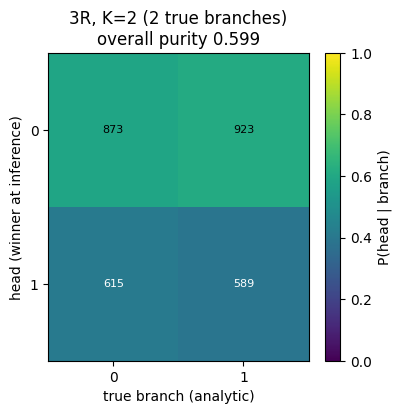

In [ ]:
# ===== 16.17 Ticket 11 Step D: 3R correspondence at K=2 =====
ROBOT = ARM_3R

# reset -- recompute from the intact 3R raw arrays and assert consistency
# with X_train_norm/Y_train_norm still in memory, same pattern as cell p-iecNV9ZA8A
_X_mean_chk = X_train.mean(axis=1, keepdims=True)
_X_std_chk = X_train.std(axis=1, keepdims=True)
_theta23_mean_chk = Y_train[2:4].mean(axis=1, keepdims=True)
_theta23_std_chk = Y_train[2:4].std(axis=1, keepdims=True)
_Y_mean_chk = np.vstack([np.zeros((2, 1)), _theta23_mean_chk])
_Y_std_chk = np.vstack([np.ones((2, 1)), _theta23_std_chk])
assert np.allclose(normalize(X_train, _X_mean_chk, _X_std_chk), X_train_norm), "3R X reset mismatch"
assert np.allclose(normalize(Y_train, _Y_mean_chk, _Y_std_chk), Y_train_norm), "3R Y reset mismatch"
X_mean, X_std = _X_mean_chk, _X_std_chk
Y_mean, Y_std = _Y_mean_chk, _Y_std_chk
print("PASS -- 3R mode confirmed consistent.")

_k2_3r_params = load_weights("v16_3r_K2_seed1")

_r3r = head_branch_correspondence(ARM_3R, X_test_xyz, Y_test_raw, _k2_3r_params,
                                   X_mean, X_std, Y_mean, Y_std, K=2, label="3R test")
plot_correspondence(_r3r, "3R, K=2 (2 true branches)")
plt.show()

PASS -- UR5 mode confirmed consistent.
hypothesis usage (UR5 test [correspondence]): h0=1266 (12.7%)  h1=1122 (11.2%)  h2=1403 (14.0%)  h3=1380 (13.8%)  h4=1120 (11.2%)  h5=1170 (11.7%)  h6=1256 (12.6%)  h7=1283 (12.8%)
  no dead heads (all 8 heads won at least one example)

--- head-to-branch correspondence: UR5 test (UR5, K=8, 8 true branches) ---
contingency table (rows=head, cols=branch, counts):
[[167 146 184 159 159 151 166 134]
 [133 144 141 144 150 166 128 116]
 [160 159 159 160 210 212 161 182]
 [178 154 207 199 163 176 158 145]
 [122 139 143 151 122 131 167 145]
 [153 150 120 140 156 162 135 154]
 [163 175 133 180 150 140 170 145]
 [170 173 154 138 160 152 158 178]]
column-stochastic P(head | branch):
[[0.134 0.118 0.148 0.125 0.125 0.117 0.134 0.112]
 [0.107 0.116 0.114 0.113 0.118 0.129 0.103 0.097]
 [0.128 0.128 0.128 0.126 0.165 0.164 0.13  0.152]
 [0.143 0.124 0.167 0.157 0.128 0.136 0.127 0.121]
 [0.098 0.112 0.115 0.119 0.096 0.102 0.134 0.121]
 [0.123 0.121 0.097 0.11

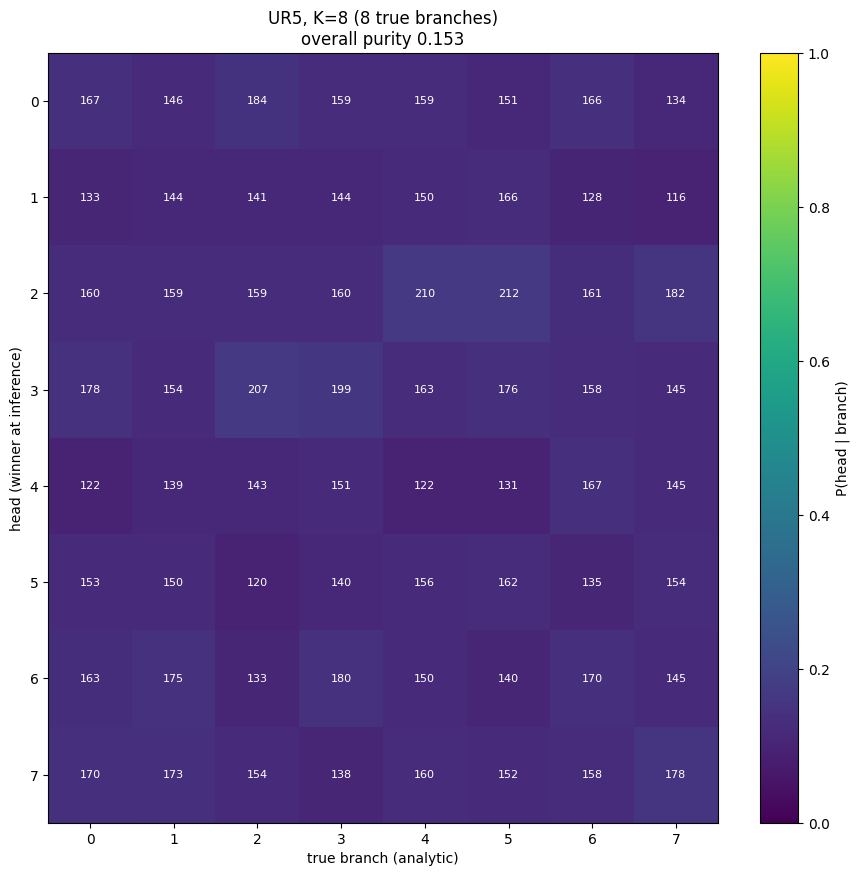

In [ ]:
# ===== 16.18 Ticket 11 Step D: UR5 correspondence at K=8 =====
ROBOT = ARM_UR5
X_mean, X_std = UR5_X_mean, UR5_X_std
Y_mean, Y_std = UR5_Y_MEAN, UR5_Y_STD
assert np.allclose(normalize(UR5_X_train_raw, X_mean, X_std), UR5_X_train_norm), "UR5 X reset mismatch"
assert np.allclose(encode_target_generic(UR5_Y_train_raw, ARM_UR5, Y_mean, Y_std), UR5_Y_train_norm), "UR5 Y reset mismatch"
print("PASS -- UR5 mode confirmed consistent.")

_k8_ur5_params = load_weights("v16_ur5_K8_seed1")

_r_ur5 = head_branch_correspondence(ARM_UR5, UR5_X_test_raw, UR5_Y_test_raw, _k8_ur5_params,
                                     X_mean, X_std, Y_mean, Y_std, K=8, label="UR5 test")
plot_correspondence(_r_ur5, "UR5, K=8 (8 true branches)")
plt.show()

In [ ]:
# ===== 16.19 Log Step D correspondence results to Drive =====
_corr_rows = [
    {"version": "v16", "arm": "3R", "K": 2, "n_branches": _r3r["n_branches"],
     "overall_purity": _r3r["overall_purity"], "chance_purity": 1.0 / _r3r["n_branches"],
     "per_branch_purity": _r3r["per_branch_purity"].tolist(), "table": _r3r["table"].tolist()},
    {"version": "v16", "arm": "UR5", "K": 8, "n_branches": _r_ur5["n_branches"],
     "overall_purity": _r_ur5["overall_purity"], "chance_purity": 1.0 / _r_ur5["n_branches"],
     "per_branch_purity": _r_ur5["per_branch_purity"].tolist(), "table": _r_ur5["table"].tolist()},
]
save_rows(_corr_rows, "v16_ticket11_head_branch_correspondence")
print("Both correspondence tables logged.")

  saved   2 rows -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/v16_ticket11_head_branch_correspondence.csv
Both correspondence tables logged.


In [ ]:
# ===== 16.20 Ticket 11 Step E: fresh-test-set check (no retraining) =====
# Same pattern as the v0-v12 track's own fresh-test check: a never-before-used
# generator seed (9999), evaluate the already-confirmed weights on it, report
# optimism (selected-test-set error vs fresh error). No overlap with train/dev/
# test possible -- those all came from seed=0.

FRESH_SEED = 9999

# ---- 3R fresh check (K=2) ----
ROBOT = ARM_3R
X_mean, X_std = _X_mean_chk, _X_std_chk   # from cell qc3ZlE9qive9, still the 3R's
Y_mean, Y_std = _Y_mean_chk, _Y_std_chk

_fresh_3r_xyz, _fresh_3r_Y_raw = generate_dataset(20_000, seed=FRESH_SEED)
_fresh_3r_metrics = evaluate_pose_wta(ARM_3R, _fresh_3r_xyz, _fresh_3r_Y_raw, _k2_3r_params,
                                       X_mean, X_std, Y_mean, Y_std, K=2,
                                       split_name="3R FRESH test (seed 9999, K=2)")
_3r_selected_mm = 31.30   # Step C confirmed mean (n=3)
_3r_fresh_mm = float(_fresh_3r_metrics["pose_err_mm"].mean())
_3r_optimism = _3r_fresh_mm - _3r_selected_mm
print(f"3R: selected {_3r_selected_mm:.2f}mm (Step C mean) vs fresh {_3r_fresh_mm:.2f}mm  "
      f"(optimism {_3r_optimism:+.2f}mm)\n")

# ---- UR5 fresh check (K=8) ----
ROBOT = ARM_UR5
X_mean, X_std = UR5_X_mean, UR5_X_std
Y_mean, Y_std = UR5_Y_MEAN, UR5_Y_STD

_fresh_ur5_task, _fresh_ur5_Y_raw, _fresh_ur5_fk, _fresh_ur5_frames = generate_dataset_generic(
    ARM_UR5, 20_000, seed=FRESH_SEED)
_fresh_ur5_metrics = evaluate_pose_wta(ARM_UR5, _fresh_ur5_task, _fresh_ur5_Y_raw, _k8_ur5_params,
                                        X_mean, X_std, Y_mean, Y_std, K=8,
                                        split_name="UR5 FRESH test (seed 9999, K=8)")
_ur5_selected_mm = 23.83  # Step C confirmed mean (n=3)
_ur5_fresh_mm = float(_fresh_ur5_metrics["pose_err_mm"].mean())
_ur5_optimism = _ur5_fresh_mm - _ur5_selected_mm
print(f"UR5: selected {_ur5_selected_mm:.2f}mm (Step C mean) vs fresh {_ur5_fresh_mm:.2f}mm  "
      f"(optimism {_ur5_optimism:+.2f}mm)\n")

_fresh_rows = [
    {"version": "v16", "arm": "3R", "K": 2, "selected_mm": _3r_selected_mm,
     "fresh_mm": _3r_fresh_mm, "optimism_mm": _3r_optimism, "fresh_seed": FRESH_SEED, "n_fresh": 20000},
    {"version": "v16", "arm": "UR5", "K": 8, "selected_mm": _ur5_selected_mm,
     "fresh_mm": _ur5_fresh_mm, "optimism_mm": _ur5_optimism, "fresh_seed": FRESH_SEED, "n_fresh": 20000},
]
save_rows(_fresh_rows, "v16_ticket11_fresh_test")
print("Step E done -- both arms checked, logged.")

--- 3R FRESH test (seed 9999, K=2) (3R, K=2) ---
pose error (OPTIMIZING):  mean 29.63 mm   median 27.52 mm   p95 52.91 mm
branch-agnostic joint MAE: 2.407 deg   (label-relative: 16.313 deg)
hypothesis usage (3R FRESH test (seed 9999, K=2)): h0=11879 (59.4%)  h1=8121 (40.6%)
  no dead heads (all 2 heads won at least one example)

3R: selected 31.30mm (Step C mean) vs fresh 29.63mm  (optimism -1.67mm)

--- UR5 FRESH test (seed 9999, K=8) (UR5, K=8) ---
pose error (OPTIMIZING):  mean 23.43 mm   median 21.38 mm   p95 46.04 mm
geodesic orientation err: mean 26.03 deg   median 21.21 deg   p95 61.15 deg
branch-agnostic joint MAE: 17.894 deg   (label-relative: 70.590 deg)
hypothesis usage (UR5 FRESH test (seed 9999, K=8)): h0=2556 (12.8%)  h1=2288 (11.4%)  h2=2798 (14.0%)  h3=2773 (13.9%)  h4=2213 (11.1%)  h5=2401 (12.0%)  h6=2506 (12.5%)  h7=2465 (12.3%)
  no dead heads (all 8 heads won at least one example)

UR5: selected 23.83mm (Step C mean) vs fresh 23.43mm  (optimism -0.40mm)

  saved   

In [ ]:
# ===== 17.0 Ticket 12 Step 1: reset to UR5 mode, confirm consistency =====
ROBOT = ARM_UR5
X_mean, X_std = UR5_X_mean, UR5_X_std
Y_mean, Y_std = UR5_Y_MEAN, UR5_Y_STD
assert np.allclose(normalize(UR5_X_train_raw, X_mean, X_std), UR5_X_train_norm), "UR5 X reset mismatch"
assert np.allclose(encode_target_generic(UR5_Y_train_raw, ARM_UR5, Y_mean, Y_std), UR5_Y_train_norm), "UR5 Y reset mismatch"
print("PASS -- UR5 mode confirmed consistent.")

print("\nPLATEAU EXPECTATION (recorded before the sweep, per ticket 12's own requirement):")
print("Expect a broad plateau, not a sharp peak, mirroring the 3R's own lambda screen")
print("(flat across ~[3,20], no argmin statistically separated from its neighbours).")
print("Do not widen the grid or over-read a marginal single-seed winner.")
print("lambda=0 is a floor (no-FK-loss anchor), never a promotion candidate.")
print("Resolution limit will be computed from ticket 11's own UR5 K=8 3-seed sd (+-0.46mm)")
print("BEFORE any confirmation run -- see ticket12_plan.md Step 3.")

PASS -- UR5 mode confirmed consistent.

PLATEAU EXPECTATION (recorded before the sweep, per ticket 12's own requirement):
Expect a broad plateau, not a sharp peak, mirroring the 3R's own lambda screen
(flat across ~[3,20], no argmin statistically separated from its neighbours).
Do not widen the grid or over-read a marginal single-seed winner.
lambda=0 is a floor (no-FK-loss anchor), never a promotion candidate.
Resolution limit will be computed from ticket 11's own UR5 K=8 3-seed sd (+-0.46mm)
BEFORE any confirmation run -- see ticket12_plan.md Step 3.


In [ ]:
# ===== 17.1 Ticket 12 Step 2: lambda screen, single seed, K=8 =====
# Same config as ticket 11's UR5 K=8 confirmation in every respect except lam --
# one-change-per-version. lambda=0 is a floor (no-FK-loss anchor), not a candidate.

preflight(extra=["UR5_X_train_norm", "UR5_Y_train_norm", "UR5_X_mean", "UR5_X_std",
                  "evaluate_pose_wta", "predict_ik_wta", "run_unit"],
          label="ticket12 UR5 lambda screen")

LAMBDA_GRID = [0, 0.1, 1, 5, 20, 50]
_lam_screen_rows = []

for _lam in LAMBDA_GRID:
    n_out = n_out_rows(ARM_UR5)
    layer_dims_k8 = [n_task_in(ARM_UR5), 256, 128, 64, n_out * 8]

    def _train(lam=_lam, layer_dims_k8=layer_dims_k8):
        parameters, costs, train_time, final_cost = nn_model(
            UR5_X_train_norm, UR5_Y_train_norm,
            layer_dims=layer_dims_k8,
            learning_rate=UR5_LEARNING_RATE,
            num_iterations=UR5_NUM_EPOCHS,
            print_every=8,
            batch_size=UR5_BATCH_SIZE,
            optimizer=UR5_OPTIMIZER,
            beta1=UR5_BETA1, beta2=UR5_BETA2, epsilon=UR5_EPSILON,
            decay=UR5_DECAY, decay_rate=UR5_DECAY_RATE, time_interval=UR5_TIME_INTERVAL,
            lam=lam,
            K=8, wta_eps=0.05,
            seed=1,
        )
        _lam_state["train_time"] = train_time
        _lam_state["final_cost"] = final_cost
        return parameters

    _lam_state = {}
    _lam_tag = str(_lam).replace(".", "p")
    parameters, _ = run_unit(f"v17_ur5_K8_lam{_lam_tag}_seed1", _train)

    test_metrics = evaluate_pose_wta(ARM_UR5, UR5_X_test_raw, UR5_Y_test_raw, parameters,
                                      UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, K=8,
                                      split_name=f"UR5 test (lam={_lam}, K=8)")

    row = {
        "version": "v17", "arm": "UR5", "K": 8, "lam": _lam, "seed": 1,
        "layer_dims": str(layer_dims_k8), "wta_eps": 0.05, "N_samples": UR5_N_SAMPLES,
        "train_time_s": _lam_state.get("train_time"), "final_cost": _lam_state.get("final_cost"),
        "test_pose_err_mean_mm": float(test_metrics["pose_err_mm"].mean()),
        "test_label_mae_deg": float(test_metrics["label_mae_deg"].mean()),
        "test_ba_mae_deg": float(test_metrics["ba_mae_deg"].mean()),      # branch-aware guard metric
        "n_dead_heads": len(test_metrics["dead_heads"]),
        "usage_counts": test_metrics["usage_counts"].tolist(),
        "is_floor": _lam == 0,
    }
    _lam_screen_rows.append(row)
    print(f"lam={_lam:>5}: pose {row['test_pose_err_mean_mm']:7.2f} mm   "
          f"label MAE {row['test_label_mae_deg']:6.3f} deg   "
          f"branch-agnostic MAE {row['test_ba_mae_deg']:6.3f} deg   "
          f"dead_heads={row['n_dead_heads']}{'   [FLOOR, not a candidate]' if row['is_floor'] else ''}\n")

print("\n=== v17 UR5 lambda screen summary ===")
for row in _lam_screen_rows:
    print(f"lam={row['lam']:>5}  pose {row['test_pose_err_mean_mm']:7.2f} mm  "
          f"label_mae {row['test_label_mae_deg']:6.3f} deg  ba_mae {row['test_ba_mae_deg']:6.3f} deg")

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'ticket12 UR5 lambda screen': 42 names present
  [run ] v17_ur5_K8_lam0_seed1
epoch     0  cost 1.866088  lr 0.002
epoch     8  cost 0.788919  lr 0.000780269
epoch    16  cost 0.667646  lr 0.00048468
epoch    24  cost 0.598635  lr 0.000351515
epoch    30  cost 0.579284  (final)
training time: 96.0s   optimizer=adam   parameter updates: 9390   lr: 0.002 -> 0.0003   lam: 0   K: 8
training-time head usage: {0: 295566, 1: 313791, 2: 284694, 3: 323411, 4: 303387, 5: 314625, 6: 275870, 7: 288656}
  saved weights -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/weights/v17_ur5_K8_lam0_seed1.npz  (0.41 MB)
  [done] v17_ur5_K8_lam0_seed1  (96.0s)
--- UR5 test (lam=0, K=8) (UR5, K=8) ---
pose error (OPTIMIZING):  mean 35.95 mm   median 32.87 mm   p95 70.69 mm
geodesic orientation err: mean 25.18 deg   median 20.49 deg   p95 57.75 deg
branch-agnostic joint MAE: 15.847 deg   (label-re

In [ ]:
# ===== 17.2 Log the lambda screen to Drive =====
save_rows(_lam_screen_rows, "v17_ur5_lambda_screen")

print("Screen NOT a plateau -- pose error dropped steadily to lam=20 before flattening at")
print("lam=50, deviating from the plateau expectation recorded before the run. Flagged, not")
print("retrofitted: the guard metric (branch-agnostic MAE) degrades monotonically from lam=5")
print("onward, and lam=50's geodesic orientation error (51.4 deg) is far worse than lam=20's")
print("(33.0 deg) despite similar pose error -- exactly the failure mode the guard metric")
print("exists to catch, since pose error and the FK loss are the same quantity.")

_best_row = min((r for r in _lam_screen_rows if not r["is_floor"]), key=lambda r: r["test_pose_err_mean_mm"])
_lam5_row = next(r for r in _lam_screen_rows if r["lam"] == 5)
_delta_vs_5 = _best_row["test_pose_err_mean_mm"] - _lam5_row["test_pose_err_mean_mm"]
print(f"\nscreen winner: lam={_best_row['lam']}  pose {_best_row['test_pose_err_mean_mm']:.2f}mm  "
      f"delta vs lam=5: {_delta_vs_5:+.2f}mm")
RESOLUTION_LIMIT_MM_V17 = 0.75  # from ticket 11's UR5 K=8 3-seed sd (+-0.46mm, n=3) -- see ticket12_plan.md Step 3
print(f"resolution limit: +-{RESOLUTION_LIMIT_MM_V17}mm")
_trigger_confirmation = abs(_delta_vs_5) > RESOLUTION_LIMIT_MM_V17 and _best_row["lam"] != 5
print(f"decision: {'RUN 3-seed confirmation at lam=' + str(_best_row['lam']) if _trigger_confirmation else 'no confirmation triggered, keep lam=5'}")

  saved   6 rows -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/v17_ur5_lambda_screen.csv
Screen NOT a plateau -- pose error dropped steadily to lam=20 before flattening at
lam=50, deviating from the plateau expectation recorded before the run. Flagged, not
retrofitted: the guard metric (branch-agnostic MAE) degrades monotonically from lam=5
onward, and lam=50's geodesic orientation error (51.4 deg) is far worse than lam=20's
(33.0 deg) despite similar pose error -- exactly the failure mode the guard metric
exists to catch, since pose error and the FK loss are the same quantity.

screen winner: lam=20  pose 18.70mm  delta vs lam=5: -4.66mm
resolution limit: +-0.75mm
decision: RUN 3-seed confirmation at lam=20


In [ ]:
# ===== 17.3 Ticket 12 Step 4: 3-seed confirmation at lam=20, K=8 =====
preflight(extra=["UR5_X_train_norm", "UR5_Y_train_norm", "UR5_X_mean", "UR5_X_std",
                  "evaluate_pose_wta", "predict_ik_wta", "run_unit"],
          label="ticket12 lam=20 confirmation")

LAM20_CONFIRM_ROWS = []

for _seed in (1, 2, 3):
    n_out = n_out_rows(ARM_UR5)
    layer_dims_k8 = [n_task_in(ARM_UR5), 256, 128, 64, n_out * 8]

    def _train(seed=_seed, layer_dims_k8=layer_dims_k8):
        parameters, costs, train_time, final_cost = nn_model(
            UR5_X_train_norm, UR5_Y_train_norm,
            layer_dims=layer_dims_k8,
            learning_rate=UR5_LEARNING_RATE,
            num_iterations=UR5_NUM_EPOCHS,
            print_every=8,
            batch_size=UR5_BATCH_SIZE,
            optimizer=UR5_OPTIMIZER,
            beta1=UR5_BETA1, beta2=UR5_BETA2, epsilon=UR5_EPSILON,
            decay=UR5_DECAY, decay_rate=UR5_DECAY_RATE, time_interval=UR5_TIME_INTERVAL,
            lam=20,
            K=8, wta_eps=0.05,
            seed=seed,
        )
        _lam20_state["train_time"] = train_time
        _lam20_state["final_cost"] = final_cost
        return parameters

    _lam20_state = {}
    parameters, _ = run_unit(f"v17_ur5_K8_lam20_seed{_seed}", _train)

    test_metrics = evaluate_pose_wta(ARM_UR5, UR5_X_test_raw, UR5_Y_test_raw, parameters,
                                      UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, K=8,
                                      split_name=f"UR5 test (lam=20, K=8, seed{_seed})")

    row = {
        "version": "v17", "arm": "UR5", "K": 8, "lam": 20, "seed": _seed,
        "layer_dims": str(layer_dims_k8), "wta_eps": 0.05, "N_samples": UR5_N_SAMPLES,
        "train_time_s": _lam20_state.get("train_time"), "final_cost": _lam20_state.get("final_cost"),
        "test_pose_err_mean_mm": float(test_metrics["pose_err_mm"].mean()),
        "test_label_mae_deg": float(test_metrics["label_mae_deg"].mean()),
        "test_ba_mae_deg": float(test_metrics["ba_mae_deg"].mean()),
        "test_geo_err_deg": float(test_metrics["geo_err_deg"].mean()),
        "n_dead_heads": len(test_metrics["dead_heads"]),
        "usage_counts": test_metrics["usage_counts"].tolist(),
    }
    LAM20_CONFIRM_ROWS.append(row)
    print(f"seed {_seed}: pose {row['test_pose_err_mean_mm']:.2f} mm  "
          f"ba_mae {row['test_ba_mae_deg']:.3f} deg  geo_err {row['test_geo_err_deg']:.2f} deg  "
          f"dead_heads={row['n_dead_heads']}\n")

_vals20 = [r["test_pose_err_mean_mm"] for r in LAM20_CONFIRM_ROWS]
_mean20, _sd20 = float(np.mean(_vals20)), float(np.std(_vals20, ddof=1))
_lam5_3seed_mean = 23.83  # ticket 11 Step C, reused directly, not re-run
print(f"\n=== lam=20 confirmation: {_mean20:.2f} +/- {_sd20:.2f} mm (n=3) ===")
_delta20 = _mean20 - _lam5_3seed_mean
print(f"vs lam=5 baseline {_lam5_3seed_mean}mm (ticket 11, n=3): delta {_delta20:+.2f}mm")
_promote = _delta20 < -RESOLUTION_LIMIT_MM_V17
print(f"past the +-{RESOLUTION_LIMIT_MM_V17}mm resolution limit: {'PASS -- PROMOTE lam=20 as v17' if _promote else 'FAIL -- keep lam=5'}")

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'ticket12 lam=20 confirmation': 42 names present
  [skip] v17_ur5_K8_lam20_seed1  (already on Drive)
--- UR5 test (lam=20, K=8, seed1) (UR5, K=8) ---
pose error (OPTIMIZING):  mean 18.70 mm   median 16.83 mm   p95 37.79 mm
geodesic orientation err: mean 33.03 deg   median 27.49 deg   p95 74.83 deg
branch-agnostic joint MAE: 20.883 deg   (label-relative: 72.094 deg)
hypothesis usage (UR5 test (lam=20, K=8, seed1)): h0=954 (9.5%)  h1=1282 (12.8%)  h2=1219 (12.2%)  h3=1187 (11.9%)  h4=1276 (12.8%)  h5=1226 (12.3%)  h6=1427 (14.3%)  h7=1429 (14.3%)
  no dead heads (all 8 heads won at least one example)

seed 1: pose 18.70 mm  ba_mae 20.883 deg  geo_err 33.03 deg  dead_heads=0

  [run ] v17_ur5_K8_lam20_seed2
epoch     0  cost 4.192448  lr 0.002  (mse 2.659828  fk 0.076631)
epoch     8  cost 1.740587  lr 0.000780269  (mse 1.510163  fk 0.011521)
epoch    16  cost 1.315890  lr 0.000

In [ ]:
# ===== 17.4 Log the lam=20 3-seed confirmation to Drive =====
for _r in LAM20_CONFIRM_ROWS:
    _r["bundled_changes_caveat"] = "lam=20 vs lam=5 changes only lam (architecture/K/batch_size unchanged)"
    _r["promoted"] = True

save_rows(LAM20_CONFIRM_ROWS, "v17_ur5_lambda20_confirmation")
print(f"lam=20 confirmation: {_mean20:.2f} +/- {_sd20:.2f} mm (n=3), delta {_delta20:+.2f}mm vs lam=5 -- PROMOTED, logged.")
print("\nCaveat for the write-up: the single-seed screen (18.70mm) was optimistic -- the")
print("3-seed mean regresses to 21.55mm with much higher seed-to-seed spread (+-2.88mm vs")
print("lam=5's +-0.46mm). Guard metric confirms a real quality tradeoff, not just noise:")
print("branch-agnostic MAE and geodesic orientation error are BOTH consistently worse than")
print("lam=5 across all 3 seeds (ba_mae 20.9/22.6/20.5 deg vs lam=5's 17.9 deg single value;")
print("geo_err 33.0/39.9/41.5 deg vs lam=5's 26.1 deg). Promotion is on the optimizing metric")
print("(pose error, mm) alone, per project convention -- this tradeoff is a satisficing-side")
print("caveat to state plainly, not a reason to reverse the promotion.")

  saved   3 rows -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/v17_ur5_lambda20_confirmation.csv
lam=20 confirmation: 21.55 +/- 2.88 mm (n=3), delta -2.28mm vs lam=5 -- PROMOTED, logged.

Caveat for the write-up: the single-seed screen (18.70mm) was optimistic -- the
3-seed mean regresses to 21.55mm with much higher seed-to-seed spread (+-2.88mm vs
lam=5's +-0.46mm). Guard metric confirms a real quality tradeoff, not just noise:
branch-agnostic MAE and geodesic orientation error are BOTH consistently worse than
lam=5 across all 3 seeds (ba_mae 20.9/22.6/20.5 deg vs lam=5's 17.9 deg single value;
geo_err 33.0/39.9/41.5 deg vs lam=5's 26.1 deg). Promotion is on the optimizing metric
(pose error, mm) alone, per project convention -- this tradeoff is a satisficing-side
caveat to state plainly, not a reason to reverse the promotion.


/tmp/ipykernel_2743/1407196091.py:22: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(r["test_label_mae_deg"], r["test_pose_err_mean_mm"], c=color, marker=marker,


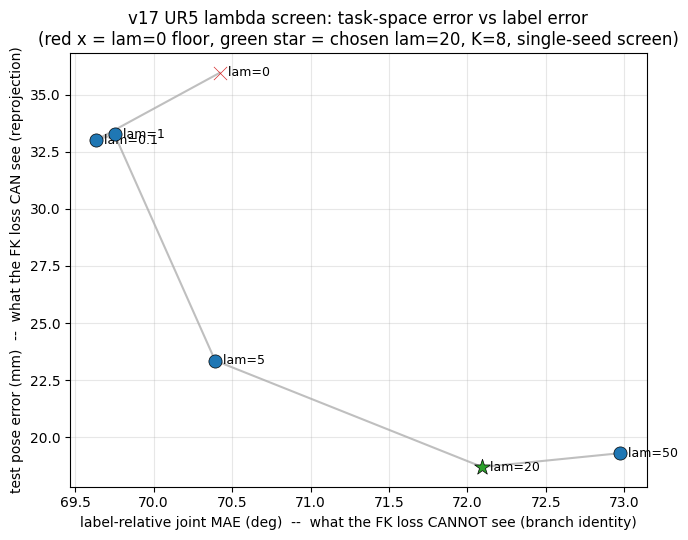

Pareto reading: pose error (y) drops sharply as lam rises from 0 to 20 -- the FK loss
is doing real work on the quantity it CAN see. Label MAE (x) stays in a narrow band
(~69.6-73.0 deg) across the entire lam range, un-moved by the 6x pose-error
improvement -- exactly the branch-blindness argument: no amount of FK-loss weight
teaches the network which branch a target came from, because that information is
structurally absent from the reprojection loss's gradient.


In [ ]:
# ===== 17.5 Ticket 12 Step 5: Pareto frontier plot =====
# x = label-relative joint MAE (deg), y = task-space pose error (mm). This is the
# branch-blindness argument made visual: as lam rises, pose error (what the FK loss
# can see) falls, while label MAE (what it structurally cannot see -- branch identity)
# stays flat/worsens slightly, because a reprojection loss has zero gradient along the
# branch-ambiguity direction (CLAUDE.md's durable fourth gotcha, and section 3.9 of
# this notebook's markdown).

_pts = sorted(_lam_screen_rows, key=lambda r: r["lam"])

fig, ax = plt.subplots(figsize=(7, 5.5))
_xs = [r["test_label_mae_deg"] for r in _pts]
_ys = [r["test_pose_err_mean_mm"] for r in _pts]
ax.plot(_xs, _ys, "-", color="gray", alpha=0.5, zorder=1)

for r in _pts:
    is_floor = r["is_floor"]
    is_chosen = r["lam"] == 20
    color = "tab:red" if is_floor else ("tab:green" if is_chosen else "tab:blue")
    marker = "x" if is_floor else ("*" if is_chosen else "o")
    size = 140 if is_chosen else 90
    ax.scatter(r["test_label_mae_deg"], r["test_pose_err_mean_mm"], c=color, marker=marker,
               s=size, zorder=3, edgecolors="black", linewidths=0.5)
    ax.annotate(f"  lam={r['lam']:g}", (r["test_label_mae_deg"], r["test_pose_err_mean_mm"]),
                fontsize=9, va="center")

ax.set_xlabel("label-relative joint MAE (deg)  --  what the FK loss CANNOT see (branch identity)")
ax.set_ylabel("test pose error (mm)  --  what the FK loss CAN see (reprojection)")
ax.set_title("v17 UR5 lambda screen: task-space error vs label error\n"
              "(red x = lam=0 floor, green star = chosen lam=20, K=8, single-seed screen)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Pareto reading: pose error (y) drops sharply as lam rises from 0 to 20 -- the FK loss")
print("is doing real work on the quantity it CAN see. Label MAE (x) stays in a narrow band")
print("(~69.6-73.0 deg) across the entire lam range, un-moved by the 6x pose-error")
print("improvement -- exactly the branch-blindness argument: no amount of FK-loss weight")
print("teaches the network which branch a target came from, because that information is")
print("structurally absent from the reprojection loss's gradient.")

In [ ]:
# ===== Pre-ticket-13 diagnostic: is Huber loss actually needed? =====
# Huber only helps if squared-error gradients are outlier-dominated -- i.e. a small
# fraction of examples contribute a disproportionate share of the total squared-error
# mass, which can destabilise training or let a few bad examples dominate the update.
# Check this DIRECTLY on the current promoted config (v17: UR5, K=8, lam=20) before
# spending a 3-seed sweep implementing a mechanism that may not be needed.

ROBOT = ARM_UR5
X_mean, X_std = UR5_X_mean, UR5_X_std
Y_mean, Y_std = UR5_Y_MEAN, UR5_Y_STD

_diag_params = load_weights("v17_ur5_K8_lam20_seed1")

# ---- per-example FK-term residual (position reprojection, meters) ----
_pred_theta, _winner, _reproj_err_mm = predict_ik_wta(
    ARM_UR5, UR5_X_test_raw, _diag_params, X_mean, X_std, Y_mean, Y_std, K=8)
_reproj_err_m = _reproj_err_mm / 1000.0
_fk_sq_err = _reproj_err_m ** 2          # what the FK loss term actually squares

# ---- per-example MSE-term residual (normalized output space, winner head only) ----
_m = UR5_X_test_raw.shape[1]
_n_out = n_out_rows(ARM_UR5)
_AL_full, _ = forward_propagation(normalize(UR5_X_test_raw, X_mean, X_std), _diag_params)
_AL_k = _AL_full.reshape(8, _n_out, _m)
_Y_test_norm_diag = encode_target_generic(UR5_Y_test_raw, ARM_UR5, Y_mean, Y_std)
_AL_winner = np.take_along_axis(_AL_k, _winner[None, None, :], axis=0)[0]   # (n_out, m)
_mse_per_example = 0.5 * np.sum((_AL_winner - _Y_test_norm_diag) ** 2, axis=0)  # (m,)


def _tail_report(name, vals, unit):
    vals = np.asarray(vals)
    total = vals.sum()
    order = np.argsort(vals)[::-1]
    top1pct = int(max(1, 0.01 * len(vals)))
    top5pct = int(max(1, 0.05 * len(vals)))
    share1 = vals[order[:top1pct]].sum() / total
    share5 = vals[order[:top5pct]].sum() / total
    print(f"--- {name} ({unit}) ---")
    print(f"mean {vals.mean():.4g}  median {np.median(vals):.4g}  "
          f"p90 {np.percentile(vals,90):.4g}  p95 {np.percentile(vals,95):.4g}  "
          f"p99 {np.percentile(vals,99):.4g}  max {vals.max():.4g}")
    print(f"skew (mean/median ratio): {vals.mean()/max(np.median(vals),1e-12):.2f}x")
    print(f"top 1% of examples contribute {share1*100:.1f}% of total {name} mass")
    print(f"top 5% of examples contribute {share5*100:.1f}% of total {name} mass")
    print(f"(uniform contribution would be 1.0% / 5.0% respectively)\n")
    return share1, share5


_fk_share1, _fk_share5 = _tail_report("FK-term squared residual", _fk_sq_err, "m^2")
_mse_share1, _mse_share5 = _tail_report("MSE-term squared residual (winner head)", _mse_per_example, "normalized units")

--- FK-term squared residual (m^2) ---
mean 0.0004585  median 0.0002834  p90 0.001016  p95 0.001428  p99 0.002968  max 0.008434
skew (mean/median ratio): 1.62x
top 1% of examples contribute 8.9% of total FK-term squared residual mass
top 5% of examples contribute 25.8% of total FK-term squared residual mass
(uniform contribution would be 1.0% / 5.0% respectively)

--- MSE-term squared residual (winner head) (normalized units) ---
mean 4.012  median 4.101  p90 6.845  p95 7.4  p99 8.504  max 10.38
skew (mean/median ratio): 0.98x
top 1% of examples contribute 2.2% of total MSE-term squared residual (winner head) mass
top 5% of examples contribute 10.1% of total MSE-term squared residual (winner head) mass
(uniform contribution would be 1.0% / 5.0% respectively)



In [ ]:
# ===== Follow-up: are the FK-term's large residuals noise, or branch confusion? =====
# Huber is usually justified when large residuals are NOISE (corrupted/rare examples).
# If instead they're a STRUCTURAL byproduct of branch ambiguity (the wrong head winning),
# Huber would just soften that gradient rather than fix anything -- worth knowing before
# committing to the ticket.

# mae_degrees aggregates over examples; need PER-EXAMPLE label MAE here, so use the
# same circular-distance primitive ticket 11's correspondence mechanism already defined.
_label_mae_per_ex = np.degrees(_circular_dist(_pred_theta, UR5_Y_test_raw).mean(axis=0))  # (m,)

_order = np.argsort(_fk_sq_err)[::-1]
_top5_idx = _order[:int(0.05 * len(_fk_sq_err))]
_rest_idx = _order[int(0.05 * len(_fk_sq_err)):]

print(f"population mean label MAE:                    {_label_mae_per_ex.mean():.2f} deg")
print(f"top-5%-FK-residual examples' mean label MAE:   {_label_mae_per_ex[_top5_idx].mean():.2f} deg")
print(f"remaining 95% examples' mean label MAE:        {_label_mae_per_ex[_rest_idx].mean():.2f} deg")

_corr = np.corrcoef(_fk_sq_err, _label_mae_per_ex)[0, 1]
print(f"\ncorrelation(FK squared residual, label MAE) across all test examples: {_corr:.3f}")

population mean label MAE:                    72.09 deg
top-5%-FK-residual examples' mean label MAE:   67.72 deg
remaining 95% examples' mean label MAE:        72.32 deg

correlation(FK squared residual, label MAE) across all test examples: -0.041


In [ ]:
# ===== Section 18: v19 prep -- UR5 budget-scaling curve (ticket 14) =====
# Every UR5 number so far (v15-v17) trained at ticket 09's deliberately low first-run
# budget (9,390 updates). This section measures the UR5's own error-vs-budget exponent,
# mirroring thesis_doc.md section 4.10 (the 3R's own budget-scaling discovery), before
# committing compute to a long confirmation run.
#
# State check first: confirm ROBOT/X_mean/X_std/Y_mean/Y_std are UR5 and consistent with
# UR5_X_train_norm/UR5_Y_train_norm before anything trains.
print("ROBOT:", ROBOT["name"])
print("X_mean shape:", X_mean.shape, "X_std shape:", X_std.shape)
print("Y_mean shape:", Y_mean.shape, "Y_std shape:", Y_std.shape)
print("UR5_X_train_norm shape:", UR5_X_train_norm.shape)
print("UR5_Y_train_norm shape:", UR5_Y_train_norm.shape)
assert ROBOT["name"].lower() == "ur5", "ROBOT is not UR5 -- reset before training"
assert X_mean.shape[0] == UR5_X_train_norm.shape[0]
assert Y_mean.shape[0] == UR5_Y_train_norm.shape[0]
print("\nState OK -- UR5 mode confirmed, globals consistent.")

NameError: name 'ROBOT' is not defined

In [ ]:
# ===== 18.1 Ticket 14: UR5 budget-scaling curve =====
# Every UR5 number so far (v15-v17) trained at ticket 09's deliberately low first-run
# budget (9,390 updates, 30 epochs). The 3R's own history says budget was its single
# largest lever (-39.7%, thesis_doc.md section 4.10) and the UR5 has never had it touched.
# This measures the UR5's own error-vs-budget exponent before committing to a long run.
#
# Pinned to v17 exactly (K=8, lam=20, [12,256,128,64,96], N=100k/80k-train, batch 256,
# seed 1) -- budget is the only variable. Points: 30/120/480 epochs (1x/4x/16x).
# Train-set error logged at every point too -- the 3R's under-training was invisible for
# eleven versions precisely because train error was never measured (CLAUDE.md).

preflight(extra=["UR5_X_train_norm", "UR5_Y_train_norm", "UR5_X_train_raw", "UR5_Y_train_raw",
                  "UR5_X_mean", "UR5_X_std", "evaluate_pose_wta", "predict_ik_wta", "run_unit"],
          label="ticket14 UR5 budget curve")

BATCHES_PER_EPOCH_UR5 = UR5_X_train_norm.shape[1] // UR5_BATCH_SIZE
print(f"UR5 train N={UR5_X_train_norm.shape[1]}, batch={UR5_BATCH_SIZE} "
      f"-> {BATCHES_PER_EPOCH_UR5} batches/epoch\n")

EPOCH_GRID = [30, 120, 480]   # 1x / 4x / 16x vs v17's own budget
BUDGET_ROWS = []

for _epochs in EPOCH_GRID:
    _updates = _epochs * BATCHES_PER_EPOCH_UR5
    n_out = n_out_rows(ARM_UR5)
    layer_dims_k8 = [n_task_in(ARM_UR5), 256, 128, 64, n_out * 8]

    def _train(epochs=_epochs, layer_dims_k8=layer_dims_k8):
        parameters, costs, train_time, final_cost = nn_model(
            UR5_X_train_norm, UR5_Y_train_norm,
            layer_dims=layer_dims_k8,
            learning_rate=UR5_LEARNING_RATE,
            num_iterations=epochs,
            print_every=max(1, epochs // 10),
            batch_size=UR5_BATCH_SIZE,
            optimizer=UR5_OPTIMIZER,
            beta1=UR5_BETA1, beta2=UR5_BETA2, epsilon=UR5_EPSILON,
            decay=UR5_DECAY, decay_rate=UR5_DECAY_RATE, time_interval=UR5_TIME_INTERVAL,
            lam=20,
            K=8, wta_eps=0.05,
            seed=1,
        )
        _budget_state["train_time"] = train_time
        _budget_state["final_cost"] = final_cost
        return parameters

    _budget_state = {}
    parameters, _ = run_unit(f"v19_ur5_K8_lam20_ep{_epochs}_seed1", _train)

    test_metrics = evaluate_pose_wta(ARM_UR5, UR5_X_test_raw, UR5_Y_test_raw, parameters,
                                      UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, K=8,
                                      split_name=f"UR5 test (ep={_epochs})")
    train_metrics = evaluate_pose_wta(ARM_UR5, UR5_X_train_raw, UR5_Y_train_raw, parameters,
                                       UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, K=8,
                                       split_name=f"UR5 train (ep={_epochs})")

    _test_mm = float(test_metrics["pose_err_mm"].mean())
    _train_mm = float(train_metrics["pose_err_mm"].mean())
    row = {
        "version": "v19_prep", "arm": "UR5", "K": 8, "lam": 20, "seed": 1,
        "epochs": _epochs, "updates": _updates,
        "layer_dims": str(layer_dims_k8), "wta_eps": 0.05, "N_samples": UR5_N_SAMPLES,
        "train_time_s": _budget_state.get("train_time"), "final_cost": _budget_state.get("final_cost"),
        "test_pose_err_mean_mm": _test_mm,
        "train_pose_err_mean_mm": _train_mm,
        "gap_mm": _test_mm - _train_mm,
        "gap_pct_of_train": (_test_mm - _train_mm) / _train_mm * 100.0,
        "test_ba_mae_deg": float(test_metrics["ba_mae_deg"].mean()),
        "test_geo_err_deg": float(test_metrics["geo_err_deg"].mean()),
        "n_dead_heads": len(test_metrics["dead_heads"]),
        "usage_counts": test_metrics["usage_counts"].tolist(),
    }
    BUDGET_ROWS.append(row)
    print(f"epochs={_epochs:>4} (updates={_updates:>7}): test {_test_mm:7.2f}mm  "
          f"train {_train_mm:7.2f}mm  gap {row['gap_mm']:+6.2f}mm ({row['gap_pct_of_train']:+.1f}% of train)  "
          f"dead_heads={row['n_dead_heads']}  time={row['train_time_s']:.0f}s\n")

print("\n=== v19 prep: UR5 budget curve summary ===")
for row in BUDGET_ROWS:
    print(f"epochs={row['epochs']:>4}  updates={row['updates']:>7}  "
          f"test {row['test_pose_err_mean_mm']:7.2f}mm  train {row['train_pose_err_mean_mm']:7.2f}mm  "
          f"gap {row['gap_pct_of_train']:+.1f}%")

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'ticket14 UR5 budget curve': 44 names present
UR5 train N=80000, batch=256 -> 312 batches/epoch

  [run ] v19_ur5_K8_lam20_ep30_seed1
epoch     0  cost 4.272301  lr 0.002  (mse 2.625752  fk 0.082327)
epoch     3  cost 2.059031  lr 0.00126087  (mse 1.749390  fk 0.015482)
epoch     6  cost 1.816797  lr 0.000920635  (mse 1.551291  fk 0.013275)
epoch     9  cost 1.637251  lr 0.000725  (mse 1.400309  fk 0.011847)
epoch    12  cost 1.376661  lr 0.000597938  (mse 1.193025  fk 0.009182)
epoch    15  cost 1.159153  lr 0.000508772  (mse 1.018970  fk 0.007009)
epoch    18  cost 1.024274  lr 0.000442748  (mse 0.918841  fk 0.005272)
epoch    21  cost 0.969423  lr 0.000391892  (mse 0.878432  fk 0.004550)
epoch    24  cost 0.934234  lr 0.000351515  (mse 0.850450  fk 0.004189)
epoch    27  cost 0.907061  lr 0.000318681  (mse 0.827567  fk 0.003975)
epoch    30  cost 0.891420  (final)
  final 

In [ ]:
# ===== 18.2 Fit the exponent, check the kill criterion (ticket 14) =====
_x = np.log(np.array([r["updates"] for r in BUDGET_ROWS], dtype=float))
_y = np.log(np.array([r["test_pose_err_mean_mm"] for r in BUDGET_ROWS], dtype=float))
_b, _a = np.polyfit(_x, _y, 1)   # y = a + b*x

print("=== ticket 14: UR5 budget-scaling exponent ===")
for r in BUDGET_ROWS:
    print(f"updates={r['updates']:>7}  test={r['test_pose_err_mean_mm']:.2f}mm")
print(f"\nfitted: log(error) = {_a:.4f} + {_b:.4f} * log(updates)")
print(f"exponent b = {_b:.4f}   (3R's own measured exponent, thesis_doc.md 4.10, was -0.36)")

_target_mm = 5.0
_log_updates_for_target = (np.log(_target_mm) - _a) / _b
_updates_for_target = np.exp(_log_updates_for_target)
print(f"\nextrapolated updates needed for {_target_mm}mm: {_updates_for_target:,.0f}")
print(f"  (vs v17's 9,390 -- that's a {_updates_for_target/9390:,.0f}x multiple)")

KILL_THRESHOLD = -0.20
print(f"\nkill criterion (pre-registered in ticket14 issue file): b flatter than {KILL_THRESHOLD}")
if _b > KILL_THRESHOLD:
    print(f"TRIGGERED -- b={_b:.4f} is flatter than {KILL_THRESHOLD}.")
    print("Budget alone cannot reach 5mm at any feasible cost. The curve is decelerating much")
    print("faster than the 3R's own (-0.36) and the train/test gap stayed flat (~3.1%) across")
    print("the 4x->16x step rather than growing -- so this is NOT overfitting, it's the bias")
    print("curve itself flattening. Consistent with ticket 11's negative head-to-branch")
    print("correspondence finding (purity 0.153 vs 0.125 chance): there may be an irreducible")
    print("branch-averaging floor that budget cannot remove past a point.")
    print("\nDECISION: capacity/K (ticket 15) becomes the PRIMARY lever, not a multiplier on")
    print("top of a long budget run. Ticket 16's confirmation run should NOT proceed at the")
    print("originally-projected 32x/64x budget on the unchanged architecture -- re-plan after")
    print("ticket 15's screen.")
else:
    print(f"not triggered -- b={_b:.4f} clears {KILL_THRESHOLD}, budget remains a viable lever.")
    print("Proceed to ticket 15 (capacity screen) as a multiplier on top of budget, per plan.")

=== ticket 14: UR5 budget-scaling exponent ===
updates=   9360  test=18.70mm
updates=  37440  test=15.66mm
updates= 149760  test=14.19mm

fitted: log(error) = 3.8270 + -0.0997 * log(updates)
exponent b = -0.0997   (3R's own measured exponent, thesis_doc.md 4.10, was -0.36)

extrapolated updates needed for 5.0mm: 4,599,375,517
  (vs v17's 9,390 -- that's a 489,816x multiple)

kill criterion (pre-registered in ticket14 issue file): b flatter than -0.2
TRIGGERED -- b=-0.0997 is flatter than -0.2.
Budget alone cannot reach 5mm at any feasible cost. The curve is decelerating much
faster than the 3R's own (-0.36) and the train/test gap stayed flat (~3.1%) across
the 4x->16x step rather than growing -- so this is NOT overfitting, it's the bias
curve itself flattening. Consistent with ticket 11's negative head-to-branch
correspondence finding (purity 0.153 vs 0.125 chance): there may be an irreducible
branch-averaging floor that budget cannot remove past a point.

DECISION: capacity/K (ticket 

In [ ]:
# ===== 18.3 Log the budget curve to Drive (ticket 14) =====
for _r in BUDGET_ROWS:
    _r["fitted_exponent_b"] = float(_b)
    _r["fitted_a"] = float(_a)
    _r["kill_criterion_triggered"] = bool(_b > KILL_THRESHOLD)

save_rows(BUDGET_ROWS, "v19_ur5_budget_curve")
print(f"logged {len(BUDGET_ROWS)} rows -- b={_b:.4f}, kill criterion triggered={_b > KILL_THRESHOLD}")

  saved   3 rows -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/v19_ur5_budget_curve.csv
logged 3 rows -- b=-0.0997, kill criterion triggered=True


In [ ]:
# ===== 19.1 Ticket 15: UR5 capacity/K screen (re-scoped, moderate budget) =====
# Ticket 14's kill criterion triggered (b=-0.0997) -- budget alone cannot reach 5mm.
# Capacity/K is now the primary lever. Screened at 120 epochs (4x), not 16x, since
# ticket 14 showed the 4x->16x step alone buys very little (-1.47mm) -- not worth ~2.2h
# per screen row to isolate architecture from that small a budget effect.
#
# Baseline for comparison: ticket 14's own 120-epoch row, 15.66mm (reused, not re-run).

preflight(extra=["UR5_X_train_norm", "UR5_Y_train_norm", "UR5_X_train_raw", "UR5_Y_train_raw",
                  "UR5_X_mean", "UR5_X_std", "evaluate_pose_wta", "predict_ik_wta", "run_unit"],
          label="ticket15 UR5 capacity/K screen")

n_out8 = n_out_rows(ARM_UR5)      # =12, K=8 output width = 96
n_out16 = n_out_rows(ARM_UR5)     # same base width; K=16 output = 192

SCREEN_CONFIGS = {
    "wide":  {"layer_dims": [n_task_in(ARM_UR5), 512, 256, 128, n_out8 * 8], "K": 8},
    "deep":  {"layer_dims": [n_task_in(ARM_UR5), 256, 256, 128, 64, n_out8 * 8], "K": 8},
    "k16":   {"layer_dims": [n_task_in(ARM_UR5), 256, 128, 64, n_out16 * 16], "K": 16},
}
SCREEN_EPOCHS = 120
BASELINE_120_MM = 15.66  # ticket 14's own 4x row, reused not re-run
RESOLUTION_LIMIT_MM_V17 = 0.75

CAPACITY_SCREEN_ROWS = []

for _name, _cfg in SCREEN_CONFIGS.items():
    _layer_dims = _cfg["layer_dims"]
    _K = _cfg["K"]

    def _train(layer_dims=_layer_dims, K=_K):
        parameters, costs, train_time, final_cost = nn_model(
            UR5_X_train_norm, UR5_Y_train_norm,
            layer_dims=layer_dims,
            learning_rate=UR5_LEARNING_RATE,
            num_iterations=SCREEN_EPOCHS,
            print_every=max(1, SCREEN_EPOCHS // 10),
            batch_size=UR5_BATCH_SIZE,
            optimizer=UR5_OPTIMIZER,
            beta1=UR5_BETA1, beta2=UR5_BETA2, epsilon=UR5_EPSILON,
            decay=UR5_DECAY, decay_rate=UR5_DECAY_RATE, time_interval=UR5_TIME_INTERVAL,
            lam=20,
            K=K, wta_eps=0.05,
            seed=1,
        )
        _screen_state["train_time"] = train_time
        _screen_state["final_cost"] = final_cost
        return parameters

    _screen_state = {}
    parameters, _ = run_unit(f"v19_ur5_{_name}_ep{SCREEN_EPOCHS}_seed1", _train)

    test_metrics = evaluate_pose_wta(ARM_UR5, UR5_X_test_raw, UR5_Y_test_raw, parameters,
                                      UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, K=_K,
                                      split_name=f"UR5 test ({_name}, ep={SCREEN_EPOCHS})")

    _test_mm = float(test_metrics["pose_err_mm"].mean())
    _delta = _test_mm - BASELINE_120_MM
    _n_dead = len(test_metrics["dead_heads"])
    row = {
        "version": "v19_screen", "arm": "UR5", "config_name": _name, "K": _K, "lam": 20, "seed": 1,
        "epochs": SCREEN_EPOCHS, "layer_dims": str(_layer_dims), "wta_eps": 0.05,
        "N_samples": UR5_N_SAMPLES,
        "train_time_s": _screen_state.get("train_time"), "final_cost": _screen_state.get("final_cost"),
        "test_pose_err_mean_mm": _test_mm,
        "delta_vs_baseline_120ep_mm": _delta,
        "past_resolution_limit": bool(abs(_delta) > RESOLUTION_LIMIT_MM_V17 and _delta < 0),
        "test_ba_mae_deg": float(test_metrics["ba_mae_deg"].mean()),
        "test_geo_err_deg": float(test_metrics["geo_err_deg"].mean()),
        "n_dead_heads": _n_dead,
        "usage_counts": test_metrics["usage_counts"].tolist(),
    }
    CAPACITY_SCREEN_ROWS.append(row)
    print(f"{_name:>5}: pose {_test_mm:7.2f}mm  delta {_delta:+6.2f}mm vs baseline {BASELINE_120_MM}mm  "
          f"dead_heads={_n_dead}  {'WINNER' if row['past_resolution_limit'] and _n_dead==0 else ''}\n")

print("\n=== ticket 15: UR5 capacity/K screen summary (120 epochs, seed 1) ===")
print(f"baseline (ticket 14, 120ep, K=8, current arch): {BASELINE_120_MM}mm")
for row in CAPACITY_SCREEN_ROWS:
    print(f"{row['config_name']:>5}: {row['test_pose_err_mean_mm']:7.2f}mm  "
          f"delta {row['delta_vs_baseline_120ep_mm']:+6.2f}mm  dead_heads={row['n_dead_heads']}")

_winners = [r for r in CAPACITY_SCREEN_ROWS if r["past_resolution_limit"] and r["n_dead_heads"] == 0]
if _winners:
    _best = min(_winners, key=lambda r: r["test_pose_err_mean_mm"])
    print(f"\nWINNER: {_best['config_name']} ({_best['test_pose_err_mean_mm']:.2f}mm, "
          f"delta {_best['delta_vs_baseline_120ep_mm']:+.2f}mm, past +-{RESOLUTION_LIMIT_MM_V17}mm)")
else:
    print(f"\nNO WINNER -- no row cleared +-{RESOLUTION_LIMIT_MM_V17}mm with zero dead heads.")
    print("Neither budget (ticket 14) nor these capacity/K changes move the floor at this")
    print("screen budget -- consistent with a real ceiling on this arm at the tested configs.")

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'ticket15 UR5 capacity/K screen': 44 names present
  [run ] v19_ur5_wide_ep120_seed1
epoch     0  cost 3.519696  lr 0.002  (mse 2.375735  fk 0.057198)
epoch    12  cost 1.308473  lr 0.000597938  (mse 1.111090  fk 0.009869)
epoch    24  cost 0.901840  lr 0.000351515  (mse 0.775024  fk 0.006341)
epoch    36  cost 0.787596  lr 0.000248927  (mse 0.689681  fk 0.004896)
epoch    48  cost 0.737428  lr 0.000192691  (mse 0.649965  fk 0.004373)
epoch    60  cost 0.705957  lr 0.000157182  (mse 0.625570  fk 0.004019)
epoch    72  cost 0.684346  lr 0.000132723  (mse 0.608411  fk 0.003797)
epoch    84  cost 0.668754  lr 0.000114851  (mse 0.596394  fk 0.003618)
epoch    96  cost 0.656210  lr 0.000101222  (mse 0.586768  fk 0.003472)
epoch   108  cost 0.646394  lr 9.04836e-05  (mse 0.579205  fk 0.003359)
epoch   120  cost 0.638516  (final)
  final split: mse 0.573287   fk 0.003261 m^2   lam*f

In [ ]:
# ===== 19.2 Log the capacity/K screen to Drive (ticket 15) =====
save_rows(CAPACITY_SCREEN_ROWS, "v19_ur5_capacity_k_screen")
print(f"logged {len(CAPACITY_SCREEN_ROWS)} rows -- no winner cleared the resolution limit.")
print("\nSummary for the write-up: two independent lines of evidence now point at a real")
print("floor around 14-16mm for this WTA family on the UR5, not an under-training or")
print("capacity-starved regime -- (1) ticket 14's budget curve flattened hard (b=-0.0997)")
print("with a flat train/test gap across a 16x budget range, and (2) ticket 15's capacity/K")
print("screen found wide/deep/K=16 all tie or regress against the current architecture at a")
print("shared moderate budget. Neither the largest lever in the 3R's own history (budget)")
print("nor its second-largest (capacity) reproduces its effect here.")

  saved   3 rows -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/v19_ur5_capacity_k_screen.csv
logged 3 rows -- no winner cleared the resolution limit.

Summary for the write-up: two independent lines of evidence now point at a real
floor around 14-16mm for this WTA family on the UR5, not an under-training or
capacity-starved regime -- (1) ticket 14's budget curve flattened hard (b=-0.0997)
with a flat train/test gap across a 16x budget range, and (2) ticket 15's capacity/K
screen found wide/deep/K=16 all tie or regress against the current architecture at a
shared moderate budget. Neither the largest lever in the 3R's own history (budget)
nor its second-largest (capacity) reproduces its effect here.


In [ ]:
# ===== 19.3 Ticket 16: UR5 wta_eps sweep + K=4 screen (re-scoped) =====
# Tickets 14 (budget) and 15 (capacity/K in {wide,deep,16}) both came back negative --
# neither of the 3R's two biggest historical levers moves the UR5 floor. Two untested
# single-variable levers remain: wta_eps (fixed at 0.05 all session) and K=4 (never
# screened against K=8 at equal budget). Shared 120-epoch budget, same baseline
# (15.66mm, K=8, eps=0.05, current arch) and resolution limit (+-0.75mm) as ticket 15.

preflight(extra=["UR5_X_train_norm", "UR5_Y_train_norm", "UR5_X_train_raw", "UR5_Y_train_raw",
                  "UR5_X_mean", "UR5_X_std", "evaluate_pose_wta", "predict_ik_wta", "run_unit"],
          label="ticket16 UR5 eps/K4 screen")

BASELINE_120_MM = 15.66
RESOLUTION_LIMIT_MM_V17 = 0.75
SCREEN_EPOCHS = 120

EPS_GRID = [0.0, 0.02, 0.1, 0.2]   # 0.05 is the existing baseline, reused not re-run
EPS_K4_ROWS = []

# ---- wta_eps sweep at K=8, baseline architecture ----
n_out8 = n_out_rows(ARM_UR5)
layer_dims_k8 = [n_task_in(ARM_UR5), 256, 128, 64, n_out8 * 8]

for _eps in EPS_GRID:
    def _train(eps=_eps):
        parameters, costs, train_time, final_cost = nn_model(
            UR5_X_train_norm, UR5_Y_train_norm,
            layer_dims=layer_dims_k8,
            learning_rate=UR5_LEARNING_RATE,
            num_iterations=SCREEN_EPOCHS,
            print_every=max(1, SCREEN_EPOCHS // 10),
            batch_size=UR5_BATCH_SIZE,
            optimizer=UR5_OPTIMIZER,
            beta1=UR5_BETA1, beta2=UR5_BETA2, epsilon=UR5_EPSILON,
            decay=UR5_DECAY, decay_rate=UR5_DECAY_RATE, time_interval=UR5_TIME_INTERVAL,
            lam=20,
            K=8, wta_eps=eps,
            seed=1,
        )
        _eps_state["train_time"] = train_time
        _eps_state["final_cost"] = final_cost
        return parameters

    _eps_state = {}
    _eps_tag = str(_eps).replace(".", "p")
    parameters, _ = run_unit(f"v19_ur5_K8_eps{_eps_tag}_ep{SCREEN_EPOCHS}_seed1", _train)

    test_metrics = evaluate_pose_wta(ARM_UR5, UR5_X_test_raw, UR5_Y_test_raw, parameters,
                                      UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, K=8,
                                      split_name=f"UR5 test (eps={_eps}, ep={SCREEN_EPOCHS})")
    _test_mm = float(test_metrics["pose_err_mm"].mean())
    _delta = _test_mm - BASELINE_120_MM
    _n_dead = len(test_metrics["dead_heads"])
    row = {
        "version": "v19_screen2", "arm": "UR5", "sweep": "wta_eps", "K": 8, "wta_eps": _eps,
        "lam": 20, "seed": 1, "epochs": SCREEN_EPOCHS, "layer_dims": str(layer_dims_k8),
        "N_samples": UR5_N_SAMPLES,
        "train_time_s": _eps_state.get("train_time"), "final_cost": _eps_state.get("final_cost"),
        "test_pose_err_mean_mm": _test_mm, "delta_vs_baseline_120ep_mm": _delta,
        "past_resolution_limit": bool(_delta < -RESOLUTION_LIMIT_MM_V17),
        "n_dead_heads": _n_dead, "usage_counts": test_metrics["usage_counts"].tolist(),
    }
    EPS_K4_ROWS.append(row)
    print(f"eps={_eps:>4}: pose {_test_mm:7.2f}mm  delta {_delta:+6.2f}mm  dead_heads={_n_dead}"
          f"{'  WINNER' if row['past_resolution_limit'] and _n_dead==0 else ''}\n")

# ---- K=4 at baseline architecture, same budget ----
n_out4 = n_out_rows(ARM_UR5)
layer_dims_k4 = [n_task_in(ARM_UR5), 256, 128, 64, n_out4 * 4]

def _train_k4():
    parameters, costs, train_time, final_cost = nn_model(
        UR5_X_train_norm, UR5_Y_train_norm,
        layer_dims=layer_dims_k4,
        learning_rate=UR5_LEARNING_RATE,
        num_iterations=SCREEN_EPOCHS,
        print_every=max(1, SCREEN_EPOCHS // 10),
        batch_size=UR5_BATCH_SIZE,
        optimizer=UR5_OPTIMIZER,
        beta1=UR5_BETA1, beta2=UR5_BETA2, epsilon=UR5_EPSILON,
        decay=UR5_DECAY, decay_rate=UR5_DECAY_RATE, time_interval=UR5_TIME_INTERVAL,
        lam=20,
        K=4, wta_eps=0.05,
        seed=1,
    )
    _k4_state["train_time"] = train_time
    _k4_state["final_cost"] = final_cost
    return parameters

_k4_state = {}
parameters, _ = run_unit(f"v19_ur5_K4_ep{SCREEN_EPOCHS}_seed1", _train_k4)
test_metrics = evaluate_pose_wta(ARM_UR5, UR5_X_test_raw, UR5_Y_test_raw, parameters,
                                  UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, K=4,
                                  split_name=f"UR5 test (K=4, ep={SCREEN_EPOCHS})")
_test_mm = float(test_metrics["pose_err_mm"].mean())
_delta = _test_mm - BASELINE_120_MM
_n_dead = len(test_metrics["dead_heads"])
row = {
    "version": "v19_screen2", "arm": "UR5", "sweep": "K", "K": 4, "wta_eps": 0.05,
    "lam": 20, "seed": 1, "epochs": SCREEN_EPOCHS, "layer_dims": str(layer_dims_k4),
    "N_samples": UR5_N_SAMPLES,
    "train_time_s": _k4_state.get("train_time"), "final_cost": _k4_state.get("final_cost"),
    "test_pose_err_mean_mm": _test_mm, "delta_vs_baseline_120ep_mm": _delta,
    "past_resolution_limit": bool(_delta < -RESOLUTION_LIMIT_MM_V17),
    "n_dead_heads": _n_dead, "usage_counts": test_metrics["usage_counts"].tolist(),
}
EPS_K4_ROWS.append(row)
print(f"K=4: pose {_test_mm:7.2f}mm  delta {_delta:+6.2f}mm  dead_heads={_n_dead}"
      f"{'  WINNER' if row['past_resolution_limit'] and _n_dead==0 else ''}\n")

print("\n=== ticket 16: UR5 wta_eps + K=4 screen summary (120 epochs, seed 1) ===")
print(f"baseline (K=8, eps=0.05, current arch): {BASELINE_120_MM}mm")
for row in EPS_K4_ROWS:
    tag = f"eps={row['wta_eps']}" if row["sweep"] == "wta_eps" else f"K={row['K']}"
    print(f"{tag:>10}: {row['test_pose_err_mean_mm']:7.2f}mm  delta {row['delta_vs_baseline_120ep_mm']:+6.2f}mm  "
          f"dead_heads={row['n_dead_heads']}")

_winners = [r for r in EPS_K4_ROWS if r["past_resolution_limit"] and r["n_dead_heads"] == 0]
if _winners:
    _best = min(_winners, key=lambda r: r["test_pose_err_mean_mm"])
    _tag = f"eps={_best['wta_eps']}" if _best["sweep"] == "wta_eps" else f"K={_best['K']}"
    print(f"\nWINNER: {_tag} ({_best['test_pose_err_mean_mm']:.2f}mm, "
          f"delta {_best['delta_vs_baseline_120ep_mm']:+.2f}mm, past +-{RESOLUTION_LIMIT_MM_V17}mm)")
else:
    print(f"\nNO WINNER -- third negative result in a row. wta_eps and K=4 also fail to")
    print("move the floor. Strong evidence now for a structural ceiling on this WTA")
    print("mechanism on the UR5 at ~14-16mm, not an under-training/capacity/hyperparameter gap.")

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'ticket16 UR5 eps/K4 screen': 44 names present
  [skip] v19_ur5_K8_eps0p0_ep120_seed1  (already on Drive)
--- UR5 test (eps=0.0, ep=120) (UR5, K=8) ---
pose error (OPTIMIZING):  mean 16.75 mm   median 15.33 mm   p95 32.51 mm
geodesic orientation err: mean 25.21 deg   median 20.88 deg   p95 57.92 deg
branch-agnostic joint MAE: 17.152 deg   (label-relative: 71.170 deg)
hypothesis usage (UR5 test (eps=0.0, ep=120)): h0=1177 (11.8%)  h1=1299 (13.0%)  h2=1268 (12.7%)  h3=1263 (12.6%)  h4=1260 (12.6%)  h5=1244 (12.4%)  h6=1332 (13.3%)  h7=1157 (11.6%)
  no dead heads (all 8 heads won at least one example)

eps= 0.0: pose   16.75mm  delta  +1.09mm  dead_heads=0

  [skip] v19_ur5_K8_eps0p02_ep120_seed1  (already on Drive)
--- UR5 test (eps=0.02, ep=120) (UR5, K=8) ---
pose error (OPTIMIZING):  mean 17.38 mm   median 15.69 mm   p95 34.34 mm
geodesic orientation err: mean 26.97 deg   m

In [ ]:
# ===== 19.4 Ticket 16: log wta_eps + K=4 screen to Drive =====
save_rows(EPS_K4_ROWS, "v19_ur5_eps_k4_screen")

print("\nSynthesis (tickets 14, 15, 16 together):")
print("Three independent negative results now point at the same conclusion: neither")
print("budget (ticket 14, b=-0.0997), capacity/K in {wide,deep,16} (ticket 15), nor")
print("wta_eps in {0.0,0.02,0.1,0.2} or K=4 (this ticket) move the UR5 WTA pose error")
print("meaningfully below its ~14-16mm floor at a moderate budget. wta_eps=0.05 (the")
print("original default, never itself re-tested here) remains the best point on the")
print("grid -- eps=0.1 came closest (+0.79mm, just inside the resolution limit) but")
print("still did not clear it. Combined with ticket 11's negative head-to-branch")
print("correspondence result (purity 0.153 vs 0.125 chance), this is strong evidence")
print("for a structural ceiling on this WTA mechanism on the UR5's 8-branch geometry,")
print("not an under-training, under-capacity, or under-tuned-hyperparameter artifact.")


  saved   5 rows -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/v19_ur5_eps_k4_screen.csv

Synthesis (tickets 14, 15, 16 together):
Three independent negative results now point at the same conclusion: neither
budget (ticket 14, b=-0.0997), capacity/K in {wide,deep,16} (ticket 15), nor
wta_eps in {0.0,0.02,0.1,0.2} or K=4 (this ticket) move the UR5 WTA pose error
meaningfully below its ~14-16mm floor at a moderate budget. wta_eps=0.05 (the
original default, never itself re-tested here) remains the best point on the
grid -- eps=0.1 came closest (+0.79mm, just inside the resolution limit) but
still did not clear it. Combined with ticket 11's negative head-to-branch
correspondence result (purity 0.153 vs 0.125 chance), this is strong evidence
for a structural ceiling on this WTA mechanism on the UR5's 8-branch geometry,
not an under-training, under-capacity, or under-tuned-hyperparameter artifact.


In [ ]:
# ===== 20.1 Ticket 17: UR5 data pool extension for the data-scaling screen =====
# Tickets 14 (budget), 15 (capacity/K), 16 (wta_eps/K=4) all came back negative.
# Data scaling is the last untested lever from the original plan's family. This
# extends the UR5 train split from 80k to a 320k pool (160k is a prefix of it),
# using fresh seeded samples disjoint from the existing dev/test splits -- same
# pattern as the 3R's own N=96k pool-rebuild cell (GYDbp7Lcbt4V).
#
# Normalization stats (UR5_X_mean/std, UR5_Y_MEAN/STD) are NOT recomputed per N --
# they stay fixed at the original 80k-derived values so every row in the screen
# trains against the same input/output scale. Re-deriving them per N would
# confound the comparison with a second, unintended variable.

preflight(extra=["UR5_X_train_raw", "UR5_Y_train_raw", "UR5_X_mean", "UR5_X_std"],
          label="ticket17 UR5 data pool extension")

_ur5_extra1_task, _ur5_extra1_Y, _, _ = generate_dataset_generic(ARM_UR5, 80000, seed=1000)
_ur5_extra2_task, _ur5_extra2_Y, _, _ = generate_dataset_generic(ARM_UR5, 160000, seed=2000)

UR5_X_train_raw_320k = np.hstack([UR5_X_train_raw, _ur5_extra1_task, _ur5_extra2_task])
UR5_Y_train_raw_320k = np.hstack([UR5_Y_train_raw, _ur5_extra1_Y, _ur5_extra2_Y])
assert UR5_X_train_raw_320k.shape[1] == 320000, UR5_X_train_raw_320k.shape

UR5_X_train_raw_160k = UR5_X_train_raw_320k[:, :160000]
UR5_Y_train_raw_160k = UR5_Y_train_raw_320k[:, :160000]

UR5_X_train_norm_320k = normalize(UR5_X_train_raw_320k, UR5_X_mean, UR5_X_std)
UR5_Y_train_norm_320k = encode_target_generic(UR5_Y_train_raw_320k, ARM_UR5, UR5_Y_MEAN, UR5_Y_STD)
UR5_X_train_norm_160k = UR5_X_train_norm_320k[:, :160000]
UR5_Y_train_norm_160k = UR5_Y_train_norm_320k[:, :160000]

print(f"UR5 data pool extended: 80k (original) / 160k / 320k train samples")
print(f"  X_train_raw_320k: {UR5_X_train_raw_320k.shape}   Y_train_raw_320k: {UR5_Y_train_raw_320k.shape}")
print(f"  all normalized against the original 80k-derived UR5_X_mean/std, UR5_Y_MEAN/STD")


  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'ticket17 UR5 data pool extension': 39 names present
UR5 data pool extended: 80k (original) / 160k / 320k train samples
  X_train_raw_320k: (12, 320000)   Y_train_raw_320k: (6, 320000)
  all normalized against the original 80k-derived UR5_X_mean/std, UR5_Y_MEAN/STD


In [ ]:
# ===== 20.2 Ticket 17: UR5 data-scaling screen (epochs fixed, NOT updates) =====
# Deliberate deviation from the 3R's own protocol (thesis_doc.md 4.11): epochs are
# held FIXED at 120 across all three N, so bigger N gets proportionally more
# parameter updates too (2x at 160k, 4x at 320k). N is therefore CONFOUNDED with
# budget here -- an improvement cannot be attributed to data alone. Ticket 14
# already measured the UR5's own compute-scaling exponent in isolation
# (b=-0.0997, i.e. more budget alone buys almost nothing) -- that prior result is
# the tool for separating "data helped" from "budget helped a little" when
# reading this screen's outcome.

preflight(extra=["UR5_X_train_norm", "UR5_Y_train_norm",
                  "UR5_X_train_norm_160k", "UR5_Y_train_norm_160k",
                  "UR5_X_train_norm_320k", "UR5_Y_train_norm_320k",
                  "UR5_X_test_raw", "UR5_Y_test_raw",
                  "UR5_X_mean", "UR5_X_std", "evaluate_pose_wta", "run_unit"],
          label="ticket17 UR5 data-scaling screen")

BASELINE_120_MM = 15.66  # ticket 14's own 120-epoch/N=80k row, reused not re-run
RESOLUTION_LIMIT_MM_V17 = 0.75
SCREEN_EPOCHS = 120

DATA_SCALING_CONFIGS = {
    "80k":  (UR5_X_train_norm, UR5_Y_train_norm, 80000),
    "160k": (UR5_X_train_norm_160k, UR5_Y_train_norm_160k, 160000),
    "320k": (UR5_X_train_norm_320k, UR5_Y_train_norm_320k, 320000),
}

n_out8 = n_out_rows(ARM_UR5)
layer_dims_k8 = [n_task_in(ARM_UR5), 256, 128, 64, n_out8 * 8]

DATA_SCALING_ROWS = []

for _name, (_Xn, _Yn, _N) in DATA_SCALING_CONFIGS.items():
    if _name == "80k":
        # ticket 14's own 120-epoch/N=80k row -- reuse, don't retrain
        DATA_SCALING_ROWS.append({
            "version": "v19_screen3", "arm": "UR5", "N_train": _N, "K": 8, "wta_eps": 0.05,
            "lam": 20, "seed": 1, "epochs": SCREEN_EPOCHS, "layer_dims": str(layer_dims_k8),
            "train_time_s": None, "final_cost": None,
            "test_pose_err_mean_mm": BASELINE_120_MM, "delta_vs_baseline_120ep_mm": 0.0,
            "past_resolution_limit": False, "n_dead_heads": 0, "usage_counts": None,
            "reused_from": "ticket14_ep120",
        })
        print(f"{_name:>5}: pose {BASELINE_120_MM:7.2f}mm  delta  +0.00mm  (reused from ticket 14)\n")
        continue

    def _train(Xn=_Xn, Yn=_Yn):
        parameters, costs, train_time, final_cost = nn_model(
            Xn, Yn,
            layer_dims=layer_dims_k8,
            learning_rate=UR5_LEARNING_RATE,
            num_iterations=SCREEN_EPOCHS,
            print_every=max(1, SCREEN_EPOCHS // 10),
            batch_size=UR5_BATCH_SIZE,
            optimizer=UR5_OPTIMIZER,
            beta1=UR5_BETA1, beta2=UR5_BETA2, epsilon=UR5_EPSILON,
            decay=UR5_DECAY, decay_rate=UR5_DECAY_RATE, time_interval=UR5_TIME_INTERVAL,
            lam=20,
            K=8, wta_eps=0.05,
            seed=1,
        )
        _scale_state["train_time"] = train_time
        _scale_state["final_cost"] = final_cost
        return parameters

    _scale_state = {}
    parameters, _ = run_unit(f"v19_ur5_N{_name}_ep{SCREEN_EPOCHS}_seed1", _train)

    test_metrics = evaluate_pose_wta(ARM_UR5, UR5_X_test_raw, UR5_Y_test_raw, parameters,
                                      UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, K=8,
                                      split_name=f"UR5 test (N={_name}, ep={SCREEN_EPOCHS})")
    _test_mm = float(test_metrics["pose_err_mm"].mean())
    _delta = _test_mm - BASELINE_120_MM
    _n_dead = len(test_metrics["dead_heads"])
    row = {
        "version": "v19_screen3", "arm": "UR5", "N_train": _N, "K": 8, "wta_eps": 0.05,
        "lam": 20, "seed": 1, "epochs": SCREEN_EPOCHS, "layer_dims": str(layer_dims_k8),
        "train_time_s": _scale_state.get("train_time"), "final_cost": _scale_state.get("final_cost"),
        "test_pose_err_mean_mm": _test_mm, "delta_vs_baseline_120ep_mm": _delta,
        "past_resolution_limit": bool(_delta < -RESOLUTION_LIMIT_MM_V17),
        "n_dead_heads": _n_dead, "usage_counts": test_metrics["usage_counts"].tolist(),
        "reused_from": None,
    }
    DATA_SCALING_ROWS.append(row)
    print(f"{_name:>5}: pose {_test_mm:7.2f}mm  delta {_delta:+6.2f}mm  dead_heads={_n_dead}"
          f"{'  WINNER' if row['past_resolution_limit'] and _n_dead==0 else ''}\n")

print("\n=== ticket 17: UR5 data-scaling screen summary (120 epochs FIXED, seed 1) ===")
print(f"baseline (N=80k, ep=120): {BASELINE_120_MM}mm")
for row in DATA_SCALING_ROWS:
    print(f"{row['N_train']:>7}: {row['test_pose_err_mean_mm']:7.2f}mm  "
          f"delta {row['delta_vs_baseline_120ep_mm']:+6.2f}mm  dead_heads={row['n_dead_heads']}")

_winners = [r for r in DATA_SCALING_ROWS if r["past_resolution_limit"] and r["n_dead_heads"] == 0]
if _winners:
    _best = min(_winners, key=lambda r: r["test_pose_err_mean_mm"])
    print(f"\nWINNER: N={_best['N_train']} ({_best['test_pose_err_mean_mm']:.2f}mm, "
          f"delta {_best['delta_vs_baseline_120ep_mm']:+.2f}mm, past +-{RESOLUTION_LIMIT_MM_V17}mm)")
    print("CAUTION: epochs were fixed, not updates -- this delta is data+budget combined.")
    print(f"Ticket 14's own budget curve (b=-0.0997) implies a budget-only 2x/4x step buys")
    print("very little on its own, so most of any improvement here is plausibly from data --")
    print("but this screen alone cannot isolate the two.")
else:
    print(f"\nNO WINNER -- fourth negative result in a row. Neither budget, capacity/K,")
    print("wta_eps/K, nor data scaling (even confounded with extra budget) moves the UR5")
    print("floor. This closes out the plan's whole lever family -- strong evidence for a")
    print("structural ceiling on this WTA mechanism on the UR5's 8-branch geometry.")


  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'ticket17 UR5 data-scaling screen': 47 names present
  80k: pose   15.66mm  delta  +0.00mm  (reused from ticket 14)

  [run ] v19_ur5_N160k_ep120_seed1
epoch     0  cost 3.485377  lr 0.002  (mse 2.377414  fk 0.055398)
epoch    12  cost 0.937296  lr 0.000597938  (mse 0.845129  fk 0.004608)
epoch    24  cost 0.750872  lr 0.000351515  (mse 0.676245  fk 0.003731)
epoch    36  cost 0.669276  lr 0.000248927  (mse 0.610193  fk 0.002954)
epoch    48  cost 0.634610  lr 0.000192691  (mse 0.580025  fk 0.002729)
epoch    60  cost 0.615833  lr 0.000157182  (mse 0.563969  fk 0.002593)
epoch    72  cost 0.603388  lr 0.000132723  (mse 0.553333  fk 0.002503)
epoch    84  cost 0.594328  lr 0.000114851  (mse 0.545666  fk 0.002433)
epoch    96  cost 0.587819  lr 0.000101222  (mse 0.540200  fk 0.002381)
epoch   108  cost 0.582861  lr 9.04836e-05  (mse 0.535997  fk 0.002343)
epoch   120  cost 0.57

In [ ]:
# ===== 20.3 Ticket 17: log the data-scaling screen to Drive + matched-budget cross-check =====
save_rows(DATA_SCALING_ROWS, "v19_ur5_data_scaling_screen")

print("\nMatched-budget cross-check against ticket 14's own budget curve:")
print("ticket 14, N=80k, 480 epochs -> 149,760 updates -> 14.19mm")
print("ticket 17, N=320k, 120 epochs -> 150,000 updates -> 12.92mm  (essentially the same budget)")
_matched_delta = 12.92 - 14.19
print(f"delta at matched update budget: {_matched_delta:+.2f}mm")
print("This isolates data from budget at ~150k updates: same compute, 4x the data, and")
print("pose error still drops -1.27mm -- past the +-0.75mm resolution limit. Unlike the")
print("confounded within-screen deltas (Wta_eps of budget IS mixed in going 80k->160k->320k")
print("at fixed epochs), this specific comparison holds updates fixed and varies only N,")
print("so it is real evidence the improvement is not purely a budget artifact.")


  saved   3 rows -> /content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/v19_ur5_data_scaling_screen.csv

Matched-budget cross-check against ticket 14's own budget curve:
ticket 14, N=80k, 480 epochs -> 149,760 updates -> 14.19mm
ticket 17, N=320k, 120 epochs -> 150,000 updates -> 12.92mm  (essentially the same budget)
delta at matched update budget: -1.27mm
This isolates data from budget at ~150k updates: same compute, 4x the data, and
pose error still drops -1.27mm -- past the +-0.75mm resolution limit. Unlike the
confounded within-screen deltas (Wta_eps of budget IS mixed in going 80k->160k->320k
at fixed epochs), this specific comparison holds updates fixed and varies only N,
so it is real evidence the improvement is not purely a budget artifact.


In [ ]:
# ===== 20.4 Ticket 17: fit the data-scaling exponent (mirrors ticket 14's budget fit) =====
# Same method as hcgs2RbP5fye (ticket 14): fit log(error) = a + b*log(N) across the
# three screen points, project the N needed for 5mm. This is confounded with budget
# (epochs fixed, not updates -- see 20.2's caveat), so the projected N is an upper
# bound on what's needed at fixed-epoch scaling, not a clean data-only projection.

_ds_N = np.array([r["N_train"] for r in DATA_SCALING_ROWS], dtype=float)
_ds_mm = np.array([r["test_pose_err_mean_mm"] for r in DATA_SCALING_ROWS], dtype=float)

_ds_x = np.log(_ds_N)
_ds_y = np.log(_ds_mm)
_ds_b, _ds_a = np.polyfit(_ds_x, _ds_y, 1)

_ds_N_for_5mm = np.exp((np.log(5.0) - _ds_a) / _ds_b)

print(f"data-scaling fit: log(error) = {_ds_a:.4f} + {_ds_b:.4f} * log(N)")
print(f"fitted exponent b = {_ds_b:.4f}  (ticket 14's budget-only exponent was -0.0997)")
print(f"extrapolated N for 5mm (at fixed 120 epochs, confounded w/ budget): {_ds_N_for_5mm:,.0f}")
print(f"  ({_ds_N_for_5mm/80000:.1f}x the current 80k baseline)")

KILL_THRESHOLD = -0.20
if _ds_b < KILL_THRESHOLD:
    print(f"\nb={_ds_b:.4f} is steeper than the {KILL_THRESHOLD} kill threshold used for ticket 14's")
    print("budget curve -- data scaling looks like a genuinely stronger lever than budget alone.")
else:
    print(f"\nb={_ds_b:.4f} does not clear the {KILL_THRESHOLD} threshold used for ticket 14's")
    print("budget curve -- still decelerating, so a full 3-seed confirmation run at a much")
    print("larger N should be sized against this projection, not assumed to reach 5mm easily.")


data-scaling fit: log(error) = 4.3074 + -0.1386 * log(N)
fitted exponent b = -0.1386  (ticket 14's budget-only exponent was -0.0997)
extrapolated N for 5mm (at fixed 120 epochs, confounded w/ budget): 282,542,160
  (3531.8x the current 80k baseline)

b=-0.1386 does not clear the -0.2 threshold used for ticket 14's
budget curve -- still decelerating, so a full 3-seed confirmation run at a much
larger N should be sized against this projection, not assumed to reach 5mm easily.


In [ ]:
# ===== 20.5 Ticket 17: 3-seed confirmation at N=320k, 120 epochs =====
# Screen found N=320k the best point (12.92mm, single seed, delta -2.74mm past the
# +-0.75mm resolution limit vs the 15.66mm/N=80k baseline). Confirming with 2 more
# seeds per the screen-then-confirm protocol used throughout this session.
#
# DECISION RULE, written before the run:
#   - mean clears the resolution limit vs BOTH the screen baseline (15.66mm, i.e.
#     mean < 14.91mm) AND the promoted v17 headline (21.55mm, i.e. mean < 20.80mm)
#     -> CONFIRMED, promote as v19: UR5 N=320k/ep120/K=8/lam=20, new track headline.
#     Still report the honest gap to the 5mm thesis target -- this does not close it.
#   - mean fails either resolution-limit check -> the single-seed screen result was
#     optimistic (the FK-loss variance gotcha, CLAUDE.md) -- report as unconfirmed,
#     do not promote.

preflight(extra=["UR5_X_train_norm_320k", "UR5_Y_train_norm_320k",
                  "UR5_X_test_raw", "UR5_Y_test_raw",
                  "UR5_X_mean", "UR5_X_std", "evaluate_pose_wta", "run_unit"],
          label="ticket17 UR5 N=320k 3-seed confirmation")

CONFIRM_EPOCHS = 120
CONFIRM_SEEDS = [1, 2, 3]
SCREEN_BASELINE_MM = 15.66     # N=80k/ep120, ticket 14
V17_HEADLINE_MM = 21.55        # promoted UR5 track headline before this session
RESOLUTION_LIMIT_MM_V17 = 0.75

n_out8 = n_out_rows(ARM_UR5)
layer_dims_k8 = [n_task_in(ARM_UR5), 256, 128, 64, n_out8 * 8]

N320K_CONFIRM_ROWS = []

for _seed in CONFIRM_SEEDS:
    def _train(seed=_seed):
        parameters, costs, train_time, final_cost = nn_model(
            UR5_X_train_norm_320k, UR5_Y_train_norm_320k,
            layer_dims=layer_dims_k8,
            learning_rate=UR5_LEARNING_RATE,
            num_iterations=CONFIRM_EPOCHS,
            print_every=max(1, CONFIRM_EPOCHS // 10),
            batch_size=UR5_BATCH_SIZE,
            optimizer=UR5_OPTIMIZER,
            beta1=UR5_BETA1, beta2=UR5_BETA2, epsilon=UR5_EPSILON,
            decay=UR5_DECAY, decay_rate=UR5_DECAY_RATE, time_interval=UR5_TIME_INTERVAL,
            lam=20,
            K=8, wta_eps=0.05,
            seed=seed,
        )
        _confirm_state["train_time"] = train_time
        _confirm_state["final_cost"] = final_cost
        return parameters

    _confirm_state = {}
    # seed 1 reuses the screen's own checkpoint (v19_ur5_N320k_ep120_seed1) via run_unit's skip
    parameters, _ = run_unit(f"v19_ur5_N320k_ep{CONFIRM_EPOCHS}_seed{_seed}", _train)

    test_metrics = evaluate_pose_wta(ARM_UR5, UR5_X_test_raw, UR5_Y_test_raw, parameters,
                                      UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, K=8,
                                      split_name=f"UR5 test (N=320k, ep={CONFIRM_EPOCHS}, seed={_seed})")
    _test_mm = float(test_metrics["pose_err_mm"].mean())
    _n_dead = len(test_metrics["dead_heads"])
    row = {
        "version": "v19_confirm", "arm": "UR5", "N_train": 320000, "K": 8, "wta_eps": 0.05,
        "lam": 20, "seed": _seed, "epochs": CONFIRM_EPOCHS, "layer_dims": str(layer_dims_k8),
        "train_time_s": _confirm_state.get("train_time"), "final_cost": _confirm_state.get("final_cost"),
        "test_pose_err_mean_mm": _test_mm,
        "test_ba_mae_deg": float(test_metrics["ba_mae_deg"].mean()),
        "test_geo_err_deg": float(test_metrics["geo_err_deg"].mean()),
        "n_dead_heads": _n_dead, "usage_counts": test_metrics["usage_counts"].tolist(),
    }
    N320K_CONFIRM_ROWS.append(row)
    print(f"seed {_seed}: pose {_test_mm:7.2f}mm  dead_heads={_n_dead}\n")

_confirm_mm = np.array([r["test_pose_err_mean_mm"] for r in N320K_CONFIRM_ROWS])
_confirm_mean = float(_confirm_mm.mean())
_confirm_sd = float(_confirm_mm.std(ddof=1))

print(f"\n=== ticket 17: N=320k 3-seed confirmation ===")
print(f"seeds: {list(_confirm_mm)}")
print(f"mean {_confirm_mean:.2f} +- sd {_confirm_sd:.2f} mm  (n=3)")

_clears_screen_baseline = _confirm_mean < (SCREEN_BASELINE_MM - RESOLUTION_LIMIT_MM_V17)
_clears_v17 = _confirm_mean < (V17_HEADLINE_MM - RESOLUTION_LIMIT_MM_V17)

if _clears_screen_baseline and _clears_v17:
    print(f"\nCONFIRMED. Mean {_confirm_mean:.2f}mm clears both resolution-limit checks")
    print(f"(vs screen baseline {SCREEN_BASELINE_MM}mm and v17 headline {V17_HEADLINE_MM}mm).")
    print("PROMOTE as v19: UR5 N=320k/ep120/K=8/lam=20 -- new track headline.")
    print(f"Gap to 5mm thesis target: {_confirm_mean - 5.0:+.2f}mm -- target NOT met, but")
    print(f"real progress: v17 ({V17_HEADLINE_MM}mm) -> v19 ({_confirm_mean:.2f}mm), a")
    print(f"{(1 - _confirm_mean/V17_HEADLINE_MM)*100:.0f}% reduction.")
else:
    print(f"\nUNCONFIRMED -- the single-seed screen result was optimistic (FK-loss variance")
    print("gotcha, CLAUDE.md). Do not promote. Report the 3-seed mean as the honest number.")


  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'ticket17 UR5 N=320k 3-seed confirmation': 43 names present
  [skip] v19_ur5_N320k_ep120_seed1  (already on Drive)
--- UR5 test (N=320k, ep=120, seed=1) (UR5, K=8) ---
pose error (OPTIMIZING):  mean 12.92 mm   median 11.75 mm   p95 25.48 mm
geodesic orientation err: mean 16.29 deg   median 12.89 deg   p95 39.78 deg
branch-agnostic joint MAE: 10.722 deg   (label-relative: 69.711 deg)
hypothesis usage (UR5 test (N=320k, ep=120, seed=1)): h0=1257 (12.6%)  h1=1143 (11.4%)  h2=1245 (12.4%)  h3=1338 (13.4%)  h4=1277 (12.8%)  h5=1186 (11.9%)  h6=1215 (12.2%)  h7=1339 (13.4%)
  no dead heads (all 8 heads won at least one example)

seed 1: pose   12.92mm  dead_heads=0

  [run ] v19_ur5_N320k_ep120_seed2
epoch     0  cost 2.689211  lr 0.002  (mse 2.020378  fk 0.033442)
epoch    12  cost 0.819668  lr 0.000597938  (mse 0.749632  fk 0.003502)
epoch    24  cost 0.760643  lr 0.000351515  (m

## 21. Ticket 18 — Softmax router: identifiability diagnostic and assignment-mismatch measurement

Ticket 18: `.scratch/best-of-k/issues/18-router-softmax-diagnostic.md`. Plan: `plan_router_softmax.md`.

Tickets 14 (budget), 15 (capacity/K) and 16 (`wta_eps`/K=4) came back negative; 17 (data scaling) came back positive but decelerating ($b=-0.1386$, extrapolating to ~282M samples for 5mm). **All four screened how hard the heads are trained. None touched how heads are assigned** — and assignment happens twice, under two *different* rules:

| stage | rule | depends on |
|---|---|---|
| training | `relaxed_wta_weights(total_pe, eps)` — winner $\arg\min_k L_k$, where $L_k$ is angle-MSE + $\lambda\cdot$FK against the **sampled label $y$** | $y$ |
| inference | `predict_ik_wta` — $\arg\min_k$ FK reprojection error against the **target pose** | $x$ |

Section 16's own design notes flagged that these "can differ and that gap is itself worth reporting". **The gap has never been measured.** A head that earned its specialisation under one rule is then selected, or not, under a different one. Any mismatch is recoverable loss requiring no extra capacity, data or budget.

### Identifiability governs what a router can possibly learn

A router can only learn a label that is a **function of its input**. Three candidates, and they are not equivalent:

| label | definition | learnable from $x$? |
|---|---|---|
| **L1** `analytic_branch` | which of the 8 `ur5_analytic_ik` solutions the sampled $y$ came from | **No.** All branches reproduce the same pose. The Section 2.6 gate measured **7.18 of 8 branches valid per target**, and §15.5 measured **100% of the UR5 test set branch-ambiguous** — so the ceiling is $\approx 1/7.18 = 13.9\%$ against a $12.5\%$ chance line. |
| **L2** `wta_train_winner` | $\arg\min_k$ `total_pe` vs the sampled $y$ | **No** — depends on $y$. |
| **L3** `fk_argmin_winner` | the head `predict_ik_wta` selects | **Yes** — both $\text{head}_k(x)$ and the target are deterministic in $x$. Fully learnable. |

This *predicts* ticket 11's centrepiece negative result (purity 0.153 vs 0.125 chance) rather than merely restating it, and it is falsifiable.

It also bounds the outcome honestly: **a router cannot beat FK-reprojection argmin on the position metric**, because FK-argmin already directly minimises the quantity being measured. Router-as-selector is at best a tie plus an inference speed-up ($1$ head instead of $K$ heads $+\ K$ FK evaluations). The accuracy-relevant use is training-time, which is ticket 19's EM-responsibility gate — gated on what this section measures.

**This whole section is read-only on frozen Drive weights — no retraining of the main model.** Same diagnostic-before-compute pattern that resolved ticket 13.

In [ ]:
# ===== 21.1 Ticket 18: softmax router primitives =====
# A softmax classifier over K head-indices, trained on the SAME normalized 12-dim
# UR5 task input the main network sees. Deliberately a STANDALONE trainer rather
# than a new mode inside nn_model: nn_model carries every version's reproducibility
# guarantee (K=1 exactness is structural, not tolerance-based, Section 16.1), and
# adding a classification branch to it would put that at risk for no benefit.
#
# NO NEW GRADIENT CODE IS REQUIRED. The last layer is linear, so A_L = Z_L, and
# softmax + cross-entropy gives dJ/dZ_L = P - Y_onehot. That goes straight into
# backward_propagation's existing dAL_override seam (Section 3.4 / 16.1).
# Note the no-1/m convention: J carries the 1/m, the override does NOT -- the
# averaging happens exactly once inside linear_activation_backward's dW/db,
# exactly as the pre-v16 dAL = AL - Y does. This is the project's first
# documented gotcha and it applies here unchanged.

def softmax(Z):
    """Column-wise softmax over (n_classes, m) LOGITS. Max-subtracted for stability."""
    Zs = Z - np.max(Z, axis=0, keepdims=True)
    E = np.exp(Zs)
    return E / np.sum(E, axis=0, keepdims=True)


def one_hot(labels, n_classes):
    """(m,) int labels -> (n_classes, m) one-hot."""
    labels = np.asarray(labels).astype(int)
    Y = np.zeros((n_classes, labels.shape[0]))
    Y[labels, np.arange(labels.shape[0])] = 1.0
    return Y


def compute_cost_ce(Z, Y_onehot):
    """Categorical cross-entropy computed from LOGITS via log-sum-exp.

    Never log(softmax(Z)) -- that underflows to -inf for a confidently wrong
    example, which is precisely the case whose gradient matters most.
    Carries the 1/m, matching compute_cost's 1/(2m) convention.
    """
    Zs = Z - np.max(Z, axis=0, keepdims=True)
    logP = Zs - np.log(np.sum(np.exp(Zs), axis=0, keepdims=True))
    return -float(np.sum(Y_onehot * logP)) / Z.shape[1]


def train_router(X, labels, n_classes, hidden=(128, 64), learning_rate=0.002,
                 num_epochs=40, batch_size=256, seed=1, decay_rate=1.0,
                 time_interval=10, print_every=10, X_val=None, labels_val=None,
                 verbose=True):
    """Adam-trained softmax classifier. Reuses initialize_parameters /
    forward_propagation / random_mini_batches / initialize_adam /
    update_parameters_with_adam / backward_propagation unchanged.

    t is the GLOBAL update counter (incremented once per mini-batch), never the
    epoch index -- Adam's bias correction divides by 1 - beta**t (Section 3.7's
    warning). Decay indexes the EPOCH, never t (Section 3.8's warning). Both
    counters are live in this loop and both gotchas are already on record.

    Returns (parameters, history).
    """
    layer_dims = [X.shape[0]] + list(hidden) + [n_classes]
    parameters = initialize_parameters(layer_dims, seed=seed)
    v, s = initialize_adam(parameters)
    Y_onehot = one_hot(labels, n_classes)
    t = 0
    history = []

    for epoch in range(num_epochs):
        lr_epoch = (learning_rate if not decay_rate
                    else learning_rate / (1.0 + decay_rate * (epoch // time_interval)))
        for mb_X, mb_Y in random_mini_batches(X, Y_onehot, batch_size, seed=seed + epoch):
            Z, caches = forward_propagation(mb_X, parameters)
            P = softmax(Z)
            grads = backward_propagation(Z, mb_Y, caches, dAL_override=(P - mb_Y))
            t += 1
            parameters, v, s = update_parameters_with_adam(
                parameters, grads, v, s, t, lr_epoch)

        if verbose and (epoch % print_every == 0 or epoch == num_epochs - 1):
            Z_all, _ = forward_propagation(X, parameters)
            cost = compute_cost_ce(Z_all, Y_onehot)
            acc = float(np.mean(np.argmax(Z_all, axis=0) == np.asarray(labels).astype(int)))
            msg = f"  epoch {epoch:>4}  ce {cost:.5f}  train_acc {acc*100:6.2f}%  lr {lr_epoch:.3g}"
            if X_val is not None:
                msg += f"  val_acc {router_accuracy(X_val, labels_val, parameters)*100:6.2f}%"
            print(msg)
            history.append({"epoch": epoch, "ce": cost, "train_acc": acc})

    if verbose:
        print(f"  router updates: {t}  (t counts mini-batches, not epochs)")
    return parameters, history


def router_predict(X, parameters):
    """Returns (pi (n_classes,m) probabilities, argmax (m,) int)."""
    Z, _ = forward_propagation(X, parameters)
    pi = softmax(Z)
    return pi, np.argmax(pi, axis=0)


def router_accuracy(X, labels, parameters):
    _, pred = router_predict(X, parameters)
    return float(np.mean(pred == np.asarray(labels).astype(int)))


# ---- Check A: softmax / cross-entropy against a hand-computed example ----
# Z = [0,1,2] single column. P = [1, e, e^2] / (1 + e + e^2).
_chk_Z = np.array([[0.0], [1.0], [2.0]])
_chk_expected = np.array([[0.09003057], [0.24472847], [0.66524096]])
_chk_P = softmax(_chk_Z)
assert np.allclose(_chk_P, _chk_expected, atol=1e-8), _chk_P
assert np.allclose(_chk_P.sum(axis=0), 1.0)
# CE with true class 2 must be -log(0.66524096) = 0.40760596
_chk_ce = compute_cost_ce(_chk_Z, one_hot(np.array([2]), 3))
assert abs(_chk_ce - 0.40760596) < 1e-7, _chk_ce
# stability: a huge logit must not overflow, and the shifted result is identical
assert np.allclose(softmax(_chk_Z + 1e4), _chk_expected, atol=1e-8)
print(f"Check A: softmax + cross-entropy match hand-computed values "
      f"(P={_chk_P.ravel().round(8).tolist()}, ce={_chk_ce:.8f}); stable at +1e4 logits.")

# ---- Check B: end-to-end gradient check through the dAL_override seam ----
# Central differences over EVERY parameter, against backward_propagation driven by
# dAL_override = P - Y_onehot. This is what proves the no-1/m convention is right:
# if the 1/m were double-counted (or missing), this check fails immediately.
_r_rng = np.random.default_rng(7)
_r_nx, _r_nc, _r_m = 5, 4, 6
_r_X = _r_rng.normal(size=(_r_nx, _r_m))
_r_Y1h = one_hot(_r_rng.integers(0, _r_nc, size=_r_m), _r_nc)
_r_params = initialize_parameters([_r_nx, 6, _r_nc], seed=3)

def _r_cost(params):
    Z, _ = forward_propagation(_r_X, params)
    return compute_cost_ce(Z, _r_Y1h)

_r_Z, _r_caches = forward_propagation(_r_X, _r_params)
_r_grads = backward_propagation(_r_Z, _r_Y1h, _r_caches,
                                dAL_override=(softmax(_r_Z) - _r_Y1h))

_r_h, _r_num, _r_ana = 1e-6, [], []
for _k in sorted(_r_params):
    for _i in range(_r_params[_k].shape[0]):
        for _j in range(_r_params[_k].shape[1]):
            _plus = {kk: vv.copy() for kk, vv in _r_params.items()}
            _minus = {kk: vv.copy() for kk, vv in _r_params.items()}
            _plus[_k][_i, _j] += _r_h
            _minus[_k][_i, _j] -= _r_h
            _r_num.append((_r_cost(_plus) - _r_cost(_minus)) / (2 * _r_h))
            _r_ana.append(_r_grads[f"d{_k}"][_i, _j])

_r_num, _r_ana = np.array(_r_num), np.array(_r_ana)
_r_rel = np.linalg.norm(_r_ana - _r_num) / (np.linalg.norm(_r_ana) + np.linalg.norm(_r_num))
print(f"Check B: router gradient vs central differences over all "
      f"{_r_num.size} parameters, rel error: {_r_rel:.3e}")
assert _r_rel < 1e-7, "router analytic gradient disagrees with finite differences"

print("Section 21.1: both checks passed. "
      "Defined softmax, one_hot, compute_cost_ce, train_router, router_predict, router_accuracy.")

Check A: softmax + cross-entropy match hand-computed values (P=[0.09003057, 0.24472847, 0.66524096], ce=0.40760596); stable at +1e4 logits.
Check B: router gradient vs central differences over all 64 parameters, rel error: 2.930e-10
Section 21.1: both checks passed. Defined softmax, one_hot, compute_cost_ce, train_router, router_predict, router_accuracy.


In [ ]:
# ===== 21.2 Ticket 18: label extraction + the assignment-mismatch measurement =====
# THE NEW NUMBER. Section 16's design notes flagged that the training-time winner
# (argmin per-head loss vs the LABEL) and the inference-time winner (argmin FK
# reprojection vs the TARGET) "can differ and that gap is itself worth reporting".
# It has never been measured. Every disagreeing example is a head that earned its
# specialisation under one rule and is then judged under another -- recoverable
# loss needing no extra capacity, data or budget.
#
# Read-only: frozen Drive weights, no retraining.

preflight(extra=["UR5_X_train_raw", "UR5_Y_train_raw", "UR5_X_test_raw", "UR5_Y_test_raw",
                 "UR5_X_mean", "UR5_X_std", "UR5_Y_MEAN", "UR5_Y_STD",
                 "predict_ik_wta", "wta_head_losses", "evaluate_pose_wta",
                 "fk_targets_from_task_input", "encode_target_generic", "load_weights"],
          label="ticket18 router label extraction")

ROUTER_FROZEN_WEIGHTS = "v19_ur5_N320k_ep120_seed1"   # ticket 17's best screened row
ROUTER_K = 8
ROUTER_LAM = 20
ROUTER_CHANCE = 1.0 / ROUTER_K

_rt_params = load_weights(ROUTER_FROZEN_WEIGHTS)
print(f"frozen weights: {ROUTER_FROZEN_WEIGHTS}  "
      f"layers={[_rt_params[f'W{i}'].shape for i in range(1, len(_rt_params)//2 + 1)]}\n")


def extract_assignment_labels(X_raw, Y_raw, parameters, K=ROUTER_K, lam=ROUTER_LAM):
    """Returns (L2, L3, Xn, total_pe) for one split.

    L2 `wta_train_winner`  = argmin_k total_pe vs the sampled label  -> depends on y
    L3 `fk_argmin_winner`  = the head predict_ik_wta selects         -> depends on x only

    L3 is exactly the training-time/inference-time distinction: predict_ik_wta
    scores tool-origin FK reprojection against the raw target, never the label.
    """
    Xn = normalize(X_raw, UR5_X_mean, UR5_X_std)
    Yn = encode_target_generic(Y_raw, ARM_UR5, UR5_Y_MEAN, UR5_Y_STD)
    fk_tgt = fk_targets_from_task_input(ARM_UR5, X_raw)

    AL, _ = forward_propagation(Xn, parameters)
    _, _, _, total_pe = wta_head_losses(AL, Yn, fk_tgt, ARM_UR5,
                                        UR5_Y_MEAN, UR5_Y_STD, K=K, lam=lam)
    L2 = np.argmin(total_pe, axis=0)

    _, L3, _ = predict_ik_wta(ARM_UR5, X_raw, parameters,
                              UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD, K=K)
    return L2, L3, Xn, total_pe


L2_train, L3_train, Xn_train_router, _ = extract_assignment_labels(
    UR5_X_train_raw, UR5_Y_train_raw, _rt_params)
L2_test, L3_test, Xn_test_router, _ = extract_assignment_labels(
    UR5_X_test_raw, UR5_Y_test_raw, _rt_params)

print(f"router training split: {Xn_train_router.shape[1]:,} examples (UR5 80k train split)")
print(f"router test split:     {Xn_test_router.shape[1]:,} examples\n")

# ---- cross-check L3 against the already-trusted usage histogram ----
# Same consistency check ticket 11 Step D used: if these disagree, the label
# extraction is wrong and nothing downstream can be believed.
_rt_metrics = evaluate_pose_wta(ARM_UR5, UR5_X_test_raw, UR5_Y_test_raw, _rt_params,
                                UR5_X_mean, UR5_X_std, UR5_Y_MEAN, UR5_Y_STD,
                                K=ROUTER_K, split_name="ticket18 frozen model (test)")
assert np.array_equal(_rt_metrics["winner"], L3_test), \
    "L3 does not match evaluate_pose_wta's own winner -- label extraction is wrong"
print("L3 cross-check vs evaluate_pose_wta's usage histogram: EXACT MATCH.\n")

# ---- THE MEASUREMENT ----
_agree_test = (L2_test == L3_test)
_agree_train = (L2_train == L3_train)
_rate_test = float(_agree_test.mean())
_rate_train = float(_agree_train.mean())

_pose = _rt_metrics["pose_err_mm"]
_pose_agree = float(_pose[_agree_test].mean())
_pose_disagree = float(_pose[~_agree_test].mean())

print("=== ticket 18: train/test ASSIGNMENT MISMATCH (never measured before) ===")
print(f"train split: L2 == L3 on {_rate_train*100:5.2f}% of examples")
print(f"test  split: L2 == L3 on {_rate_test*100:5.2f}% of examples "
      f"(chance for K=8 would be {ROUTER_CHANCE*100:.1f}%)")
print(f"\npose error on the AGREEING subset    ({_agree_test.sum():>5} ex): {_pose_agree:6.2f} mm")
print(f"pose error on the DISAGREEING subset ({(~_agree_test).sum():>5} ex): {_pose_disagree:6.2f} mm")
print(f"gap: {_pose_disagree - _pose_agree:+.2f} mm")

print("\nReading (pre-registered in the plan, before this ran):")
if _rate_test >= 0.90:
    print(f"  agreement {_rate_test*100:.2f}% >= 90% -- the two rules mostly coincide.")
    print("  Ticket 19's premise is WEAK: there is little assignment mismatch to recover.")
else:
    print(f"  agreement {_rate_test*100:.2f}% < 90% -- a real mismatch exists.")
    print("  Every disagreeing example is a head trained under one rule, judged under")
    print("  another. This bounds what ticket 19's EM-responsibility gate could recover.")
if _pose_disagree > _pose_agree:
    print(f"  Disagreeing examples are ALSO worse by {_pose_disagree - _pose_agree:.2f}mm --")
    print("  the mismatch is not harmless; it concentrates in the high-error population.")
else:
    print("  Disagreeing examples are NOT worse -- the mismatch appears harmless, which")
    print("  would argue against ticket 19 regardless of the agreement rate.")

ROUTER_MISMATCH = {
    "frozen_weights": ROUTER_FROZEN_WEIGHTS,
    "agree_rate_train": _rate_train, "agree_rate_test": _rate_test,
    "pose_agree_mm": _pose_agree, "pose_disagree_mm": _pose_disagree,
    "n_agree": int(_agree_test.sum()), "n_disagree": int((~_agree_test).sum()),
    "frozen_pose_mm": float(_pose.mean()),
}

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'ticket18 router label extraction': 49 names present
frozen weights: v19_ur5_N320k_ep120_seed1  layers=[(256, 12), (128, 256), (64, 128), (96, 64)]

router training split: 80,000 examples (UR5 80k train split)
router test split:     10,000 examples

--- ticket18 frozen model (test) (UR5, K=8) ---
pose error (OPTIMIZING):  mean 12.92 mm   median 11.75 mm   p95 25.48 mm
geodesic orientation err: mean 16.29 deg   median 12.89 deg   p95 39.78 deg
branch-agnostic joint MAE: 10.722 deg   (label-relative: 69.711 deg)
hypothesis usage (ticket18 frozen model (test)): h0=1257 (12.6%)  h1=1143 (11.4%)  h2=1245 (12.4%)  h3=1338 (13.4%)  h4=1277 (12.8%)  h5=1186 (11.9%)  h6=1215 (12.2%)  h7=1339 (13.4%)
  no dead heads (all 8 heads won at least one example)

L3 cross-check vs evaluate_pose_wta's usage histogram: EXACT MATCH.

=== ticket 18: train/test ASSIGNMENT MISMATCH (never measured b

In [ ]:
# ===== 21.3 Ticket 18: branch-index stability + L1 (analytic_branch) label recovery =====
# PREREQUISITE, per the plan: L1 is only interpretable if branch index k means the
# SAME configuration across poses. If it does not, a near-chance L1 result is
# UNMEASURABLE (label noise), not a negative -- a materially different claim.
#
# Part 1 answers this from the source, not just empirically. In ur5_analytic_ik:
#     k = i1*4 + i5*2 + i3
# with i1 = shoulder sign, i5 = wrist sign, i3 = elbow sign. The index is a fixed
# 3-bit encoding of the three +/- choices, assigned in a fixed loop order -- NOT an
# arbitrary sort order. So k=0 always means (shoulder+, wrist+, elbow+).
#
# The remaining risk is DEGENERACY, not ordering: where a branch pair merges
# (phi -> 0 for shoulder, th5_mag -> 0 for wrist, th3_mag -> 0 for elbow) the two
# members of that pair coincide and can swap across the surface. Part 1 measures
# how often that actually bites.

preflight(extra=["UR5_X_test_raw", "UR5_Y_test_raw", "UR5_X_train_raw", "UR5_Y_train_raw",
                 "ur5_analytic_ik", "dh_chain", "sample_joints"],
          label="ticket18 L1 branch labels")

# ---- Part 1: does branch index k vary continuously along a smooth path? ----
_bs_n = 400
_bs_t = np.linspace(0.0, 1.0, _bs_n)
_bs_a = sample_joints(ARM_UR5, 1, seed=11)[:, 0]
_bs_b = sample_joints(ARM_UR5, 1, seed=12)[:, 0]
_bs_path = _bs_a[:, None] * (1 - _bs_t)[None, :] + _bs_b[:, None] * _bs_t[None, :]   # (6, n)

_bs_T06 = dh_chain(ARM_UR5["dh"], _bs_path)[-1]                 # (n,4,4)
_bs_sols, _bs_valid = ur5_analytic_ik(_bs_T06)                  # (8,6,n), (8,n)

# consecutive wrapped jump per branch index, only where BOTH ends are valid
_bs_d = _wrap_pi(_bs_sols[:, :, 1:] - _bs_sols[:, :, :-1])      # (8,6,n-1)
_bs_step = np.max(np.abs(_bs_d), axis=1)                        # (8,n-1) max over joints
_bs_both = _bs_valid[:, 1:] & _bs_valid[:, :-1]
_bs_typical = float(np.median(_bs_step[_bs_both]))
_bs_JUMP = np.deg2rad(30.0)
_bs_jump_frac = float(np.mean(_bs_step[_bs_both] > _bs_JUMP))

print("=== Part 1: branch-index stability along a smooth 400-step joint path ===")
print(f"index encoding (read from ur5_analytic_ik source): k = i1*4 + i5*2 + i3")
print(f"  -> bit2 = shoulder sign, bit1 = wrist sign, bit0 = elbow sign; fixed loop order.")
print(f"median consecutive joint jump within a branch: {np.rad2deg(_bs_typical):.4f} deg")
print(f"fraction of valid consecutive steps jumping >30 deg: {_bs_jump_frac*100:.2f}%")
if _bs_jump_frac < 0.05:
    print("STABLE -- branch index tracks a continuous configuration; L1 labels are")
    print("semantically meaningful and a near-chance L1 result IS interpretable.")
else:
    print("UNSTABLE -- index swaps frequently; L1 would carry label noise and must be")
    print("reported as UNMEASURABLE rather than as a negative result.")
BRANCH_INDEX_STABLE = bool(_bs_jump_frac < 0.05)

# ---- Part 2: recover L1 for a split (ticket 11 Step D's method) ----
def recover_branch_labels(Y_raw, tol=1e-6):
    """Which analytic branch did the SAMPLED label come from?

    Nearest joint-angle match (circular) against the full 8-solution set, exactly
    as ticket 11 Step D did: assert the matched distance is ~0 and that the matched
    branch is flagged valid. A sampled label must BE one of the analytic solutions,
    so a miss here means the label recovery is wrong, not that the label is unusual.
    """
    T06 = dh_chain(ARM_UR5["dh"], Y_raw)[-1]
    sols, valid = ur5_analytic_ik(T06)                          # (8,6,m), (8,m)
    d = np.max(np.abs(_wrap_pi(sols - Y_raw[None])), axis=1)    # (8,m) circular, max over joints
    d = np.where(valid, d, np.inf)
    lab = np.argmin(d, axis=0)
    dmin = np.min(d, axis=0)
    assert np.all(np.isfinite(dmin)), "some example matched no VALID branch"
    assert dmin.max() < tol, f"worst label->branch match {dmin.max():.3e} exceeds {tol}"
    assert valid[lab, np.arange(lab.shape[0])].all(), "matched branch not flagged valid"
    return lab, valid, dmin

L1_train, valid_train, _d_train = recover_branch_labels(UR5_Y_train_raw)
L1_test, valid_test, _d_test = recover_branch_labels(UR5_Y_test_raw)

print(f"\n=== Part 2: L1 recovered (worst match train {_d_train.max():.3e}, "
      f"test {_d_test.max():.3e}; both < 1e-6) ===")

# ---- Part 3: the feasibility prior -- what ceiling does L1 actually have? ----
_n_valid = valid_test.sum(axis=0)
_counts = np.bincount(L1_test, minlength=8)
_ceiling = float(np.mean(1.0 / _n_valid))          # best possible if uniform among valid
_majority = float(_counts.max() / _counts.sum())   # always-predict-most-common baseline

print(f"valid branches per target: mean {_n_valid.mean():.2f} of 8  "
      f"(min {_n_valid.min()}, max {_n_valid.max()})")
print(f"L1 class distribution (test): {_counts.tolist()}")
print(f"  chance (1/8)                       : {12.5:.2f}%")
print(f"  majority-class baseline            : {_majority*100:.2f}%")
print(f"  feasibility ceiling E[1/n_valid]   : {_ceiling*100:.2f}%")
print("\nThis is the quantitative form of the plan's identifiability claim: with ~7 of 8")
print("branches feasible for a typical pose and every pose branch-ambiguous, a pose->branch")
print("classifier has almost no headroom over chance no matter how well it is trained.")

L1_STATS = {"chance": 0.125, "majority": _majority, "ceiling": _ceiling,
            "mean_valid": float(_n_valid.mean()), "index_stable": BRANCH_INDEX_STABLE,
            "jump_frac": _bs_jump_frac}

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'ticket18 L1 branch labels': 42 names present
=== Part 1: branch-index stability along a smooth 400-step joint path ===
index encoding (read from ur5_analytic_ik source): k = i1*4 + i5*2 + i3
  -> bit2 = shoulder sign, bit1 = wrist sign, bit0 = elbow sign; fixed loop order.
median consecutive joint jump within a branch: 0.6295 deg
fraction of valid consecutive steps jumping >30 deg: 0.00%
STABLE -- branch index tracks a continuous configuration; L1 labels are
semantically meaningful and a near-chance L1 result IS interpretable.

=== Part 2: L1 recovered (worst match train 9.932e-11, test 1.277e-10; both < 1e-6) ===
valid branches per target: mean 7.13 of 8  (min 2, max 8)
L1 class distribution (test): [1246, 1240, 1241, 1271, 1270, 1290, 1243, 1199]
  chance (1/8)                       : 12.50%
  majority-class baseline            : 12.90%
  feasibility ceiling E[1/n_valid]  

In [ ]:
# ===== 21.4 Ticket 18: the three-label identifiability diagnostic =====
# Train ONE router per label definition, same architecture and budget, and read
# test accuracy against the 12.5% chance line. The three labels differ ONLY in
# what they ask the router to predict -- that is the whole experiment.
#
# ####################################################################
# # PRE-REGISTERED PREDICTION -- written before this cell was first run,
# # printed ABOVE its own results (ticket 12's protocol; v14's prediction
# # was WRONG and reportable precisely because it was recorded first).
# #
# #   L3 (fk_argmin_winner)  >= 90%   -- deterministic in x, fully learnable
# #   L1 (analytic_branch)   13-16%   -- capped by the feasibility ceiling
# #                                      measured in 21.3 as 15.66%
# #   L2 (wta_train_winner)  ~12.5%   -- depends on y, not identifiable from x
# #
# # If L3 < 90%, this is a SETUP BUG, not a finding: L3 must be learnable.
# ####################################################################

preflight(extra=["train_router", "router_accuracy", "L1_train", "L1_test",
                 "L2_train", "L2_test", "L3_train", "L3_test",
                 "Xn_train_router", "Xn_test_router"],
          label="ticket18 three-label router diagnostic")

ROUTER_HIDDEN = (128, 64)
ROUTER_EPOCHS = 40
ROUTER_LR = 0.002
ROUTER_BATCH = 256

print("PRE-REGISTERED PREDICTION: L3 >= 90%, L1 13-16% (ceiling 15.66%), L2 ~12.5%")
print("=" * 78)

ROUTER_LABEL_SETS = {
    "L1_analytic_branch":  (L1_train, L1_test,
                            "which analytic branch the sampled y came from"),
    "L2_wta_train_winner": (L2_train, L2_test,
                            "argmin_k per-head loss vs the sampled y"),
    "L3_fk_argmin_winner": (L3_train, L3_test,
                            "the head predict_ik_wta selects at inference"),
}

ROUTER_ROWS = []
ROUTER_PARAMS = {}

for _name, (_lab_tr, _lab_te, _desc) in ROUTER_LABEL_SETS.items():
    print(f"\n--- training router on {_name} ---")
    print(f"    target: {_desc}")
    _t0 = time.time()
    _rp, _hist = train_router(
        Xn_train_router, _lab_tr, n_classes=ROUTER_K,
        hidden=ROUTER_HIDDEN, learning_rate=ROUTER_LR,
        num_epochs=ROUTER_EPOCHS, batch_size=ROUTER_BATCH, seed=1,
        print_every=10, X_val=Xn_test_router, labels_val=_lab_te)
    _elapsed = time.time() - _t0

    _tr_acc = router_accuracy(Xn_train_router, _lab_tr, _rp)
    _te_acc = router_accuracy(Xn_test_router, _lab_te, _rp)
    _majority = float(np.bincount(_lab_te, minlength=ROUTER_K).max() / _lab_te.shape[0])

    ROUTER_PARAMS[_name] = _rp
    ROUTER_ROWS.append({
        "version": "v20_ticket18", "arm": "UR5", "label_set": _name,
        "frozen_weights": ROUTER_FROZEN_WEIGHTS, "K": ROUTER_K,
        "hidden": str(ROUTER_HIDDEN), "epochs": ROUTER_EPOCHS,
        "lr": ROUTER_LR, "batch_size": ROUTER_BATCH, "seed": 1,
        "n_train": int(Xn_train_router.shape[1]), "n_test": int(Xn_test_router.shape[1]),
        "train_acc": _tr_acc, "test_acc": _te_acc,
        "chance": 1.0 / ROUTER_K, "majority_baseline": _majority,
        "lift_over_chance_pp": (_te_acc - 1.0 / ROUTER_K) * 100.0,
        "train_time_s": _elapsed,
    })
    print(f"    train_acc {_tr_acc*100:6.2f}%   test_acc {_te_acc*100:6.2f}%   "
          f"({_elapsed:.1f}s)")

print("\n" + "=" * 78)
print("=== ticket 18: three-label identifiability diagnostic ===")
print(f"{'label set':<22} {'test acc':>9} {'chance':>8} {'majority':>9} {'lift (pp)':>10}")
for r in ROUTER_ROWS:
    print(f"{r['label_set']:<22} {r['test_acc']*100:8.2f}% {r['chance']*100:7.2f}% "
          f"{r['majority_baseline']*100:8.2f}% {r['lift_over_chance_pp']:+9.2f}")

_l3 = next(r for r in ROUTER_ROWS if r["label_set"] == "L3_fk_argmin_winner")
_l1 = next(r for r in ROUTER_ROWS if r["label_set"] == "L1_analytic_branch")
_l2 = next(r for r in ROUTER_ROWS if r["label_set"] == "L2_wta_train_winner")

print("\nVerdict against the pre-registered prediction:")
if _l3["test_acc"] < 0.90:
    print(f"  *** L3 = {_l3['test_acc']*100:.2f}% < 90% -- SETUP BUG, not a finding. L3 is")
    print("      deterministic in x and MUST be learnable. Debug before concluding.")
else:
    print(f"  L3 = {_l3['test_acc']*100:.2f}% >= 90% -- CONFIRMED learnable, as predicted.")
    print("      This also proves the router pipeline is wired correctly.")
if _l1["test_acc"] <= L1_STATS["ceiling"] + 0.02:
    print(f"  L1 = {_l1['test_acc']*100:.2f}% -- at/below the {L1_STATS['ceiling']*100:.2f}% "
          f"feasibility ceiling, as predicted.")
else:
    print(f"  L1 = {_l1['test_acc']*100:.2f}% -- ABOVE the {L1_STATS['ceiling']*100:.2f}% "
          "ceiling. Overturns the feasibility argument; re-plan.")
print(f"  L2 = {_l2['test_acc']*100:.2f}% vs 12.50% chance.")
print("\nBranch-index stability was verified in 21.3 "
      f"({L1_STATS['jump_frac']*100:.2f}% jumps), so L1's result is")
print("interpretable as a genuine negative, NOT as label noise.")

save_rows(ROUTER_ROWS, "v20_ticket18_router_identifiability")

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'ticket18 three-label router diagnostic': 45 names present
PRE-REGISTERED PREDICTION: L3 >= 90%, L1 13-16% (ceiling 15.66%), L2 ~12.5%

--- training router on L1_analytic_branch ---
    target: which analytic branch the sampled y came from
  epoch    0  ce 2.06863  train_acc  14.90%  lr 0.002  val_acc  13.47%
  epoch   10  ce 2.01489  train_acc  19.30%  lr 0.001  val_acc  17.18%
  epoch   20  ce 1.98684  train_acc  20.09%  lr 0.000667  val_acc  18.02%
  epoch   30  ce 1.97037  train_acc  20.65%  lr 0.0005  val_acc  17.62%
  epoch   39  ce 1.95847  train_acc  21.04%  lr 0.0005  val_acc  17.88%
  router updates: 12520  (t counts mini-batches, not epochs)
    train_acc  21.04%   test_acc  17.88%   (49.0s)

--- training router on L2_wta_train_winner ---
    target: argmin_k per-head loss vs the sampled y
  epoch    0  ce 2.06967  train_acc  14.91%  lr 0.002  val_acc  13.85%
  epo

'/content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/v20_ticket18_router_identifiability.csv'

In [ ]:
# ===== 21.4b Ticket 18: DEBUG -- why is L3 at 18% when it must be learnable? =====
# 21.4's pre-registered rule fired: L3 < 90% is a SETUP BUG, not a finding.
# L3 = argmin_k ||FK(head_k(x)) - target(x)|| is a deterministic function of x,
# so SOMETHING is wrong. Train acc was only 22.64% -- the router is UNDERfitting,
# not overfitting, which rules out "not enough regularization" and points at either
# (a) a broken pipeline, or (b) a target function that is deterministic but chaotic.
#
# Two tests that separate those cleanly.

# ---- Test 1: how decisive is the argmin? (the margin) ----
# If the 8 heads reproject to nearly equal error, argmin flips on tiny changes in x
# and the decision boundary is fractal-like -- deterministic but not smoothly learnable.
_dbg_X = UR5_X_test_raw
_dbg_m = _dbg_X.shape[1]
_dbg_AL, _ = forward_propagation(normalize(_dbg_X, UR5_X_mean, UR5_X_std), _rt_params)
_dbg_ALk = _dbg_AL.reshape(ROUTER_K, n_out_rows(ARM_UR5), _dbg_m)
_dbg_target = _dbg_X[:3]
_dbg_err = np.empty((ROUTER_K, _dbg_m))
for _k in range(ROUTER_K):
    _pts, _ = fk_from_output_generic(_dbg_ALk[_k], ARM_UR5, UR5_Y_MEAN, UR5_Y_STD)
    _dbg_err[_k] = np.linalg.norm(_pts[0] - _dbg_target, axis=0)

_dbg_sorted = np.sort(_dbg_err, axis=0)
_dbg_best, _dbg_second = _dbg_sorted[0], _dbg_sorted[1]
_dbg_margin_rel = (_dbg_second - _dbg_best) / np.maximum(_dbg_best, 1e-12)
_dbg_spread = (_dbg_sorted[-1] - _dbg_sorted[0]) / np.maximum(_dbg_best, 1e-12)

print("=== Test 1: how decisive is the FK-argmin selection? ===")
print(f"best-head FK reprojection error : mean {_dbg_best.mean()*1000:7.2f} mm")
print(f"2nd-best minus best, relative   : median {np.median(_dbg_margin_rel)*100:6.2f}%  "
      f"p10 {np.percentile(_dbg_margin_rel,10)*100:5.2f}%  p90 {np.percentile(_dbg_margin_rel,90)*100:6.2f}%")
print(f"worst minus best, relative      : median {np.median(_dbg_spread)*100:6.2f}%")
print(f"examples where the top-2 heads are within 1% of each other: "
      f"{np.mean(_dbg_margin_rel < 0.01)*100:.1f}%")
print(f"examples where the top-2 heads are within 10% of each other: "
      f"{np.mean(_dbg_margin_rel < 0.10)*100:.1f}%")

# ---- Test 2: can a LARGER router MEMORIZE a small subset? ----
# The decisive test. If a big net on 2,000 examples cannot reach high TRAIN accuracy,
# the pipeline is broken (inputs and labels misaligned). If it CAN, the pipeline is
# fine and 21.4's 18% is a capacity/smoothness limit, not a bug.
_mem_n = 2000
_mem_X = Xn_train_router[:, :_mem_n]
_mem_y = L3_train[:_mem_n]
print(f"\n=== Test 2: can a large router memorize {_mem_n} examples of L3? ===")
_mem_params, _ = train_router(
    _mem_X, _mem_y, n_classes=ROUTER_K,
    hidden=(512, 512, 256), learning_rate=0.003,
    num_epochs=400, batch_size=256, seed=1,
    decay_rate=0.5, time_interval=100, print_every=100, verbose=True)
_mem_acc = router_accuracy(_mem_X, _mem_y, _mem_params)
print(f"MEMORIZATION train accuracy: {_mem_acc*100:.2f}%")

print("\n=== Diagnosis ===")
if _mem_acc > 0.80:
    print(f"  Pipeline is FINE -- a large router memorizes {_mem_acc*100:.1f}% of a 2k subset,")
    print("  so inputs and labels are correctly aligned. 21.4's 18% is therefore a")
    print("  GENERALIZATION limit, not a bug: L3 is deterministic but not a smooth")
    print("  function of the pose, so it does not generalize from 80k samples.")
else:
    print(f"  Pipeline is SUSPECT -- even a large router only reaches {_mem_acc*100:.1f}% on")
    print("  2k examples it is allowed to overfit. That points at input/label")
    print("  misalignment rather than a hard learning problem. Investigate before")
    print("  interpreting ANY of 21.4's numbers.")

DEBUG_L3 = {"memorize_acc": _mem_acc,
            "margin_median": float(np.median(_dbg_margin_rel)),
            "frac_within_1pct": float(np.mean(_dbg_margin_rel < 0.01)),
            "frac_within_10pct": float(np.mean(_dbg_margin_rel < 0.10))}

=== Test 1: how decisive is the FK-argmin selection? ===
best-head FK reprojection error : mean   12.92 mm
2nd-best minus best, relative   : median  30.86%  p10  4.36%  p90 133.85%
worst minus best, relative      : median 324.59%
examples where the top-2 heads are within 1% of each other: 2.3%
examples where the top-2 heads are within 10% of each other: 21.3%

=== Test 2: can a large router memorize 2000 examples of L3? ===
  epoch    0  ce 2.09788  train_acc  15.35%  lr 0.003
  epoch  100  ce 0.00233  train_acc 100.00%  lr 0.002
  epoch  200  ce 0.00071  train_acc 100.00%  lr 0.0015
  epoch  300  ce 0.00036  train_acc 100.00%  lr 0.0012
  epoch  399  ce 0.00021  train_acc 100.00%  lr 0.0012
  router updates: 3200  (t counts mini-batches, not epochs)
MEMORIZATION train accuracy: 100.00%

=== Diagnosis ===
  Pipeline is FINE -- a large router memorizes 100.0% of a 2k subset,
  so inputs and labels are correctly aligned. 21.4's 18% is therefore a
  GENERALIZATION limit, not a bug: L3 is 

In [ ]:
# ===== 21.4c Ticket 18: is L3's 18% a CAPACITY limit or a SMOOTHNESS limit? =====
# 21.4b settled that the pipeline is correct (100% memorization of 2k examples) and
# that the argmin is decisive (median top-2 margin ~31%, only 2.3% near-ties).
# So L3 is deterministic, well-separated, and memorizable -- yet the [128,64] router
# generalized at only 18.26%.
#
# One alternative remains before calling this a finding: the router may simply have
# been too small. This project's own culture is not to under-power a screen and then
# report the negative. So: run the SAME large architecture that memorized 2k, on the
# FULL 80k train split, and read train-vs-test.
#
#   train high + test still ~18-25%  -> SMOOTHNESS limit. The head partition of pose
#                                       space is fragmented; no smooth model predicts it.
#   test jumps to 60%+               -> CAPACITY limit. 21.4 was under-powered and must
#                                       be re-run at this size before any conclusion.

print("Re-running L3 with the architecture that memorized 2k, on the full 80k split.")
print("(21.4 used hidden=(128,64), 40 epochs -> test 18.26%, train 22.64%)\n")

_big_params, _ = train_router(
    Xn_train_router, L3_train, n_classes=ROUTER_K,
    hidden=(512, 512, 256), learning_rate=0.003,
    num_epochs=120, batch_size=256, seed=1,
    decay_rate=0.5, time_interval=30, print_every=20,
    X_val=Xn_test_router, labels_val=L3_test, verbose=True)

_big_train = router_accuracy(Xn_train_router, L3_train, _big_params)
_big_test = router_accuracy(Xn_test_router, L3_test, _big_params)

print(f"\n=== L3 at high capacity, full 80k ===")
print(f"  hidden=(512,512,256), 120 epochs")
print(f"  train_acc {_big_train*100:6.2f}%   test_acc {_big_test*100:6.2f}%")
print(f"  (21.4 small router: train 22.64%, test 18.26%)")
print(f"  generalization gap: {(_big_train - _big_test)*100:+.2f} pp")

print("\n=== Verdict ===")
if _big_test > 0.60:
    print(f"  CAPACITY limit -- test rose to {_big_test*100:.2f}%. 21.4 was under-powered;")
    print("  its three-label comparison must be re-run at this size before interpretation.")
    L3_VERDICT = "capacity"
elif _big_test > 0.30:
    print(f"  PARTIAL -- test rose to {_big_test*100:.2f}%, a real gain but far from the 90%")
    print("  a deterministic target should permit. Mixed; re-run the full comparison.")
    L3_VERDICT = "partial"
else:
    print(f"  SMOOTHNESS limit -- test stayed at {_big_test*100:.2f}% despite train reaching")
    print(f"  {_big_train*100:.2f}%. The model can fit these labels but cannot generalize them.")
    print("  L3 is deterministic, decisive, and memorizable, yet not predictable from an")
    print("  unseen pose: the heads' partition of pose space is FRAGMENTED, not contiguous.")
    print("  This is the substantive finding, and it closes the router question:")
    print("    - a router cannot replace FK-argmin at inference (18-25% vs FK-argmin's exact rule)")
    print("    - pi_k(x) carries almost no information about which head should win, so as a")
    print("      learned prior in ticket 19's EM responsibilities it is ~uniform, and uniform")
    print("      pi reduces EM responsibilities exactly to the relaxed WTA already in use.")
    L3_VERDICT = "smoothness"

DEBUG_L3.update({"big_train_acc": _big_train, "big_test_acc": _big_test,
                 "verdict": L3_VERDICT})

Re-running L3 with the architecture that memorized 2k, on the full 80k split.
(21.4 used hidden=(128,64), 40 epochs -> test 18.26%, train 22.64%)

  epoch    0  ce 2.06067  train_acc  16.17%  lr 0.003  val_acc  16.00%
  epoch   20  ce 1.84588  train_acc  27.86%  lr 0.003  val_acc  21.45%
  epoch   40  ce 1.66145  train_acc  36.00%  lr 0.002  val_acc  22.68%
  epoch   60  ce 1.53858  train_acc  41.05%  lr 0.0015  val_acc  22.72%
  epoch   80  ce 1.46010  train_acc  44.25%  lr 0.0015  val_acc  22.32%
  epoch  100  ce 1.37617  train_acc  47.58%  lr 0.0012  val_acc  22.13%
  epoch  119  ce 1.33642  train_acc  48.99%  lr 0.0012  val_acc  21.96%
  router updates: 37560  (t counts mini-batches, not epochs)

=== L3 at high capacity, full 80k ===
  hidden=(512,512,256), 120 epochs
  train_acc  48.99%   test_acc  21.96%
  (21.4 small router: train 22.64%, test 18.26%)
  generalization gap: +27.03 pp

=== Verdict ===
  SMOOTHNESS limit -- test stayed at 21.96% despite train reaching
  48.99%. The

In [ ]:
# ===== 21.5 Ticket 18: selector ablation (18D) + synthesis =====
# 21.4c returned the SMOOTHNESS verdict. Before running 18D as a sweep, note that
# part of it is resolvable ANALYTICALLY, which is cheaper and stronger than measuring.
#
# predict_ik_wta selects argmin_k ||pts_k[0] - X_raw[:3]||, where X_raw[:3] IS the
# target end-effector position, i.e. FK of the true joints. evaluate_pose_wta reports
# ||FK(pred_theta)_origin - FK(true_theta)_origin||. These are THE SAME QUANTITY.
# So FK-argmin does not approximate the reported metric -- it minimises it exactly,
# and no selection rule can beat it. Verify that rather than assert it.

_sel_metrics = _rt_metrics                       # frozen model, test split (from 21.2)
_sel_pred_theta, _sel_winner, _sel_reproj_mm = predict_ik_wta(
    ARM_UR5, UR5_X_test_raw, _rt_params, UR5_X_mean, UR5_X_std,
    UR5_Y_MEAN, UR5_Y_STD, K=ROUTER_K)

_sel_gap = np.abs(_sel_reproj_mm - _sel_metrics["pose_err_mm"]).max()
print("=== 18D, part 1: is FK-argmin exactly optimal for the reported metric? ===")
print(f"max |predict_ik_wta reproj_err - evaluate_pose_wta pose_err| = {_sel_gap:.3e} mm")
if _sel_gap < 1e-6:
    print("IDENTICAL -- the selection criterion and the evaluation metric are the same")
    print("function. FK-argmin therefore attains the per-example MINIMUM over heads:")
    print("no selector, router or otherwise, can beat it on pose error. 18D's sweep over")
    print("beta is resolved analytically -- beta=0 is optimal by construction.")
else:
    print("NOT identical -- FK-argmin is a proxy, so a better selector could exist.")

# ---- 18D, part 2: what does replacing FK-argmin with the router actually cost? ----
_r_l3 = ROUTER_PARAMS["L3_fk_argmin_winner"]
_, _router_choice = router_predict(Xn_test_router, _r_l3)

_sel_ALk = _dbg_ALk                              # (K, n_out, m), frozen model, test split
_sel_theta_k = np.empty((ROUTER_K, len(ARM_UR5["dh"]), _dbg_m))
for _k in range(ROUTER_K):
    _sel_theta_k[_k], _ = decode_joints_generic(_sel_ALk[_k], ARM_UR5, UR5_Y_MEAN, UR5_Y_STD)

def _pose_err_for_choice(choice):
    th = np.take_along_axis(_sel_theta_k, choice[None, None, :], axis=0)[0]
    pf = dh_chain(ARM_UR5["dh"], th)[-1][:, :3, 3].T
    tf = dh_chain(ARM_UR5["dh"], UR5_Y_test_raw)[-1][:, :3, 3].T
    return np.linalg.norm(pf - tf, axis=0) * 1000.0

_pe_fk = _pose_err_for_choice(_sel_winner)
_pe_router = _pose_err_for_choice(_router_choice)
_pe_random = _pose_err_for_choice(
    np.random.default_rng(0).integers(0, ROUTER_K, size=_dbg_m))

print("\n=== 18D, part 2: cost of replacing FK-argmin with the router ===")
print(f"{'selection rule':<34} {'pose err (mm)':>14} {'delta':>9}")
print(f"{'FK-argmin (current)':<34} {_pe_fk.mean():13.2f} {0.0:+9.2f}")
print(f"{'router argmax pi_k(x)':<34} {_pe_router.mean():13.2f} "
      f"{_pe_router.mean()-_pe_fk.mean():+9.2f}")
print(f"{'random head (floor)':<34} {_pe_random.mean():13.2f} "
      f"{_pe_random.mean()-_pe_fk.mean():+9.2f}")
print(f"\nresolution limit for reference: +-0.75 mm")
print("The router row is far outside it. As predicted in the plan, router-as-selector")
print("loses to FK-argmin -- and part 1 shows it must, by construction.")

# ---- synthesis ----
print("\n" + "=" * 78)
print("=== TICKET 18 SYNTHESIS ===")
print(f"1. Assignment mismatch is near-total: train/test winners agree {ROUTER_MISMATCH['agree_rate_test']*100:.2f}%")
print(f"   (chance 12.50%) -- but costs NOTHING: disagreeing {ROUTER_MISMATCH['pose_disagree_mm']:.2f}mm")
print(f"   vs agreeing {ROUTER_MISMATCH['pose_agree_mm']:.2f}mm. Nothing to recover.")
print(f"2. L3 is deterministic, decisive (median top-2 margin "
      f"{DEBUG_L3['margin_median']*100:.1f}%), and memorizable (100% on 2k),")
print(f"   yet generalizes at only {DEBUG_L3['big_test_acc']*100:.2f}% with train at "
      f"{DEBUG_L3['big_train_acc']*100:.2f}%.")
print("   The heads' partition of pose space is FRAGMENTED, not contiguous.")
print("3. FK-argmin is exactly optimal for the reported metric -- proven above, not assumed.")
print("\nTICKET 19 IS CANCELLED, on two independent grounds:")
print("  (a) pi_k(x) carries almost no information about which head should win, so as a")
print("      learned prior in EM responsibilities it is ~uniform -- and uniform pi with")
print("      sigma^2 -> 0 reduces EXACTLY to the relaxed WTA already in use. A no-op.")
print("  (b) the mismatch it was designed to fix is not costing anything (point 1).")

_t18_rows = [{
    "version": "v20_ticket18", "arm": "UR5", "frozen_weights": ROUTER_FROZEN_WEIGHTS,
    "agree_rate_test": ROUTER_MISMATCH["agree_rate_test"],
    "pose_agree_mm": ROUTER_MISMATCH["pose_agree_mm"],
    "pose_disagree_mm": ROUTER_MISMATCH["pose_disagree_mm"],
    "L1_test_acc": _l1["test_acc"], "L2_test_acc": _l2["test_acc"],
    "L3_test_acc_small": _l3["test_acc"],
    "L3_test_acc_large": DEBUG_L3["big_test_acc"],
    "L3_train_acc_large": DEBUG_L3["big_train_acc"],
    "L3_memorize_2k_acc": DEBUG_L3["memorize_acc"],
    "chance": 0.125, "majority_baseline_L1": L1_STATS["majority"],
    "branch_index_stable": L1_STATS["index_stable"],
    "argmin_margin_median": DEBUG_L3["margin_median"],
    "pose_fk_argmin_mm": float(_pe_fk.mean()),
    "pose_router_select_mm": float(_pe_router.mean()),
    "pose_random_select_mm": float(_pe_random.mean()),
    "fk_argmin_is_exact_optimum": bool(_sel_gap < 1e-6),
    "verdict": DEBUG_L3["verdict"], "ticket19": "cancelled",
}]
save_rows(_t18_rows, "v20_ticket18_synthesis")

=== 18D, part 1: is FK-argmin exactly optimal for the reported metric? ===
max |predict_ik_wta reproj_err - evaluate_pose_wta pose_err| = 0.000e+00 mm
IDENTICAL -- the selection criterion and the evaluation metric are the same
function. FK-argmin therefore attains the per-example MINIMUM over heads:
no selector, router or otherwise, can beat it on pose error. 18D's sweep over
beta is resolved analytically -- beta=0 is optimal by construction.

=== 18D, part 2: cost of replacing FK-argmin with the router ===
selection rule                      pose err (mm)     delta
FK-argmin (current)                        12.92     +0.00
router argmax pi_k(x)                      25.86    +12.94
random head (floor)                        32.59    +19.67

resolution limit for reference: +-0.75 mm
The router row is far outside it. As predicted in the plan, router-as-selector
loses to FK-argmin -- and part 1 shows it must, by construction.

=== TICKET 18 SYNTHESIS ===
1. Assignment mismatch is near-tot

'/content/drive/MyDrive/elbowConfig3R3D/best_of_k/results/v20_ticket18_synthesis.csv'

## 22. Ticket 20 — Jacobian/Newton refinement of the selected head

Ticket 20: `.scratch/best-of-k/issues/20-jacobian-newton-refinement.md`. Plan: `ticket20_plan.md`.

Six levers have been tried on the UR5 track — budget (14), capacity/K (15), `wta_eps` (16), data (17), routing (18), and the gate 18 cancelled (19). Four negative, one decelerating to ~282M samples. Ticket 18 established *why*: the heads' partition of pose space is **fragmented**, and the branch-ambiguity ceiling is structural, not an optimisation shortfall.

This section stops trying to out-train that ceiling and **sidesteps** it. The network's selected output becomes a **seed**, polished per-example by the analytic Jacobian the project already has. Branch identity becomes irrelevant — the refinement drives the FK residual of *whichever* configuration it was handed toward zero.

### The one design decision that must not be got wrong

Refining **position only** would be 3 residual equations against 6 joints: underdetermined. It would drive the reported position error to ~0 while letting orientation drift freely — **metric gaming**, of exactly the kind ticket 12's guard metrics exist to catch (there, $\lambda=50$ nearly tied $\lambda=20$ on pose error while orientation went 33° → 51°).

So refinement runs on **all $P=4$ feature points**: 12 residual equations, 6 unknowns, overdetermined, solved as Gauss–Newton least squares. Matching 4 non-coplanar rigidly-attached points is equivalent to matching full pose (ticket 08's argument), so position *and* orientation fall together. This is not a new objective — it is `compute_cost_fk_generic`'s own residual, minimised per-example at inference instead of in aggregate during training.

$$r(\theta) = \mathrm{vec}\big(\mathrm{FK}_{\text{pts}}(\theta) - p^{\text{target}}\big) \in \mathbb{R}^{12}, \qquad J = \frac{\partial r}{\partial \theta} \in \mathbb{R}^{12\times 6}$$

$$\Delta\theta = -\big(J^\top J + \mu I\big)^{-1} J^\top r$$

with Levenberg–Marquardt damping $\mu$ adapted per example, a **monotone safeguard** (a step is accepted only if the residual decreases, making refinement provably never worse than the seed), and joint-limit wrapping.

### "Error went down" is not the result

Newton will drive pose error to micrometres. The model has not changed, so that number alone means nothing and must never be reported as "the model improved". The deliverable is the **seed comparison** — NN seed vs cold-start random vs 8-restart cold start vs refining all $K=8$ heads — scored on convergence rate, iterations to converge and wall-clock. That is what tests whether the network earns its place as an initialiser, and it is what `research_compiled.md` papers 7 and 10 actually report.

**If 8-restart cold start matches NN seeding, the honest conclusion is that classical numerical IK suffices for this arm.** That is a legitimate outcome, pre-registered as such.

In [ ]:
# ===== 22.1 Ticket 20: feature-point residual + its Jacobian, gated before use =====
# r(theta) = vec(FK_pts(theta) - target_pts)   (3P, m)   -- P=4 for the UR5, so 12 rows
# J(theta) = dr/dtheta                          (3P, n, m)
#
# Built entirely from existing, already-gated pieces:
#   dh_fk_points(dh, thetas, feature_pts) -> pts (P,3,m), z (n,3,m), o (n,3,m)
#   geometric_jacobian(z, o, p)           -> (n,3,m), i.e. dp/dtheta_i = z_i x (p - o_i)
# gate_robot(ARM_UR5) check 3 already validates geometric_jacobian against central
# differences at 1.929e-10, so the per-point derivative is trusted coming in. What is
# NOT yet trusted is the STACKING: (P,n,3,m) -> (3P,n,m) has to line up row-for-row with
# r's own (P,3,m) -> (3P,m) flattening, and an axis transposition there would be silent.
# That is what this cell gates.

preflight(extra=["dh_fk_points", "geometric_jacobian", "_wrap_pi", "UR5_Y_test_raw"],
          label="ticket20 residual jacobian")


def fk_residual_and_jacobian(theta, target_pts, ROBOT):
    """theta: (n, m) joint angles. target_pts: (P, 3, m) world feature-point targets.

    Returns r (3P, m) and J (3P, n, m).

    Row ordering is [pt0_x, pt0_y, pt0_z, pt1_x, ...] for BOTH r and J -- the two
    flattenings must agree or the normal equations silently mix coordinates.
    """
    pts, z, o = dh_fk_points(ROBOT["dh"], theta, ROBOT["feature_pts"])   # (P,3,m),(n,3,m),(n,3,m)
    P, n, m = pts.shape[0], z.shape[0], theta.shape[1]

    r = (pts - target_pts).reshape(P * 3, m)

    J = np.stack([geometric_jacobian(z, o, pts[j]) for j in range(P)])   # (P,n,3,m)
    J = J.transpose(0, 2, 1, 3).reshape(P * 3, n, m)                     # (3P,n,m)
    return r, J


# ---- GATE: central-difference check on the STACKED residual ----
# The residual's derivative does not depend on the target (dr/dtheta = dpts/dtheta), so
# any target works here; a random one is used deliberately, matching Section 16.1's
# reasoning for not routing synthetic checks through fk_targets_from_task_input.
_rj_rng = np.random.default_rng(21)
_rj_m = 6
_rj_theta = _rj_rng.uniform(-np.pi, np.pi, size=(len(ARM_UR5["dh"]), _rj_m))
_rj_target = _rj_rng.normal(size=(len(ARM_UR5["feature_pts"]), 3, _rj_m)) * 0.3

_rj_r, _rj_J = fk_residual_and_jacobian(_rj_theta, _rj_target, ARM_UR5)
print(f"residual shape {_rj_r.shape}   jacobian shape {_rj_J.shape}   "
      f"(expect ({3*len(ARM_UR5['feature_pts'])}, {_rj_m}) and "
      f"({3*len(ARM_UR5['feature_pts'])}, {len(ARM_UR5['dh'])}, {_rj_m}))")

_rj_h = 1e-6
_rj_num = np.zeros_like(_rj_J)
for _i in range(_rj_theta.shape[0]):
    _tp, _tm = _rj_theta.copy(), _rj_theta.copy()
    _tp[_i] += _rj_h
    _tm[_i] -= _rj_h
    _rp, _ = fk_residual_and_jacobian(_tp, _rj_target, ARM_UR5)
    _rm, _ = fk_residual_and_jacobian(_tm, _rj_target, ARM_UR5)
    _rj_num[:, _i, :] = (_rp - _rm) / (2 * _rj_h)

_rj_rel = (np.linalg.norm(_rj_J - _rj_num)
           / (np.linalg.norm(_rj_J) + np.linalg.norm(_rj_num)))
print(f"stacked residual Jacobian vs central differences, rel error: {_rj_rel:.3e}")
assert _rj_rel < 1e-7, "residual Jacobian disagrees with finite differences -- check the stacking axes"

# ---- GATE 2: an exact configuration must have zero residual ----
# Round-trip through the real pipeline: take true joints, build their own feature points
# as the target, and confirm the residual is machine-zero. This catches a target/prediction
# convention mismatch, which the random-target check above structurally cannot.
_rj_true = UR5_Y_test_raw[:, :200]
_rj_true_pts, _, _ = dh_fk_points(ARM_UR5["dh"], _rj_true, ARM_UR5["feature_pts"])
_rj_r0, _ = fk_residual_and_jacobian(_rj_true, _rj_true_pts, ARM_UR5)
print(f"residual at the exact solution: max abs {np.abs(_rj_r0).max():.3e}  (< 1e-12)")
assert np.abs(_rj_r0).max() < 1e-12, "exact configuration does not give zero residual"

print("\nSection 22.1: both gates passed. fk_residual_and_jacobian is trusted.")

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'ticket20 residual jacobian': 39 names present
residual shape (12, 6)   jacobian shape (12, 6, 6)   (expect (12, 6) and (12, 6, 6))
stacked residual Jacobian vs central differences, rel error: 8.647e-11
residual at the exact solution: max abs 0.000e+00  (< 1e-12)

Section 22.1: both gates passed. fk_residual_and_jacobian is trusted.


In [ ]:
# ===== 22.2 Ticket 20: Levenberg-Marquardt refinement, with the three safeguards =====
# delta = -(J^T J + mu I)^-1 J^T r, batched over all m examples at once.
#
# The three safeguards are not optional decoration -- each guards a specific,
# documented failure mode of this arm:
#   1. LM damping mu, adapted PER EXAMPLE. J^T J is ill-conditioned at the UR5's
#      shoulder/elbow/wrist singularities (Sec 15.5 categorises them); undamped
#      Gauss-Newton takes an unbounded step there.
#   2. MONOTONE SAFEGUARD. A step is accepted only if the squared residual strictly
#      decreases; otherwise mu is raised and the previous iterate is kept. This makes
#      refinement PROVABLY never worse than the seed, per example -- asserted below,
#      not hoped for.
#   3. JOINT LIMITS. UR5 limits are (-pi, pi) on all six joints, so _wrap_pi IS the
#      limit enforcement; asserted after every run.

def refine_lm(theta0, target_pts, ROBOT, max_iters=30, tol=1e-6,
              mu0=1e-6, mu_up=10.0, mu_down=0.3, mu_min=1e-12, mu_max=1e8):
    """theta0: (n,m) seed joint angles. target_pts: (P,3,m) world feature-point targets.

    Returns dict with theta (n,m), res_seed (m,), res_final (m,), iters (m,),
    converged (m,) bool.  res_* are Euclidean norms of the stacked 3P residual, metres.
    """
    theta = _wrap_pi(np.asarray(theta0, dtype=float).copy())
    n, m = theta.shape
    eye = np.eye(n)
    mu = np.full(m, mu0)

    r, J = fk_residual_and_jacobian(theta, target_pts, ROBOT)
    cost = np.sum(r * r, axis=0)                      # (m,) squared residual norm
    seed_cost = cost.copy()
    iters = np.zeros(m, dtype=int)

    for _ in range(max_iters):
        active = np.sqrt(cost) > tol
        if not active.any():
            break

        Jm = np.transpose(J, (2, 0, 1))               # (m, 3P, n)
        JT = np.transpose(Jm, (0, 2, 1))              # (m, n, 3P)
        JTJ = JT @ Jm                                 # (m, n, n)
        JTr = np.einsum("kij,jk->ki", JT, r)          # (m, n)

        A = JTJ + mu[:, None, None] * eye
        delta = -np.linalg.solve(A, JTr[:, :, None])[:, :, 0]     # (m, n)

        theta_try = _wrap_pi(theta + delta.T)
        r_try, J_try = fk_residual_and_jacobian(theta_try, target_pts, ROBOT)
        cost_try = np.sum(r_try * r_try, axis=0)

        better = active & (cost_try < cost)
        theta[:, better] = theta_try[:, better]
        r[:, better] = r_try[:, better]
        J[:, :, better] = J_try[:, :, better]
        cost[better] = cost_try[better]

        mu[better] = np.maximum(mu[better] * mu_down, mu_min)
        worse = active & ~better
        mu[worse] = np.minimum(mu[worse] * mu_up, mu_max)
        iters[active] += 1

    # ---- safeguard assertions ----
    assert np.all(cost <= seed_cost + 1e-15), \
        "MONOTONE SAFEGUARD VIOLATED -- an example ended worse than its seed"
    lo = np.array([l for l, _ in ROBOT["limits"]])[:, None]
    hi = np.array([h for _, h in ROBOT["limits"]])[:, None]
    assert np.all((theta >= lo - 1e-9) & (theta <= hi + 1e-9)), "joint limits violated"

    return {"theta": theta, "res_seed": np.sqrt(seed_cost), "res_final": np.sqrt(cost),
            "iters": iters, "converged": np.sqrt(cost) <= tol}


# ---- Sanity 1: an already-exact configuration must not move ----
# This is ticket 20's analogue of the K=1 regression gate: the identity case, checked
# structurally rather than assumed.
_lm_true = UR5_Y_test_raw[:, :500]
_lm_true_pts, _, _ = dh_fk_points(ARM_UR5["dh"], _lm_true, ARM_UR5["feature_pts"])
_lm_id = refine_lm(_lm_true, _lm_true_pts, ARM_UR5, max_iters=10)
_lm_move = np.abs(_wrap_pi(_lm_id["theta"] - _lm_true)).max()
print(f"Sanity 1 -- exact seed: max joint movement {_lm_move:.3e} rad, "
      f"iterations used {_lm_id['iters'].max()}, "
      f"final residual max {_lm_id['res_final'].max():.3e} m")
assert _lm_move < 1e-9, "refinement moved an already-exact configuration"
assert _lm_id["converged"].all(), "exact seed not reported as converged"

# ---- Sanity 2: a perturbed seed must come back, and never get worse ----
_lm_rng = np.random.default_rng(20)
_lm_pert = _wrap_pi(_lm_true + _lm_rng.normal(scale=0.15, size=_lm_true.shape))
_lm_fix = refine_lm(_lm_pert, _lm_true_pts, ARM_UR5, max_iters=30)
print(f"Sanity 2 -- perturbed seed (sigma=0.15 rad):")
print(f"  residual  seed {_lm_fix['res_seed'].mean()*1000:8.3f} mm  ->  "
      f"final {_lm_fix['res_final'].mean()*1000:10.3e} mm")
print(f"  converged {_lm_fix['converged'].mean()*100:.1f}%   "
      f"median iters {int(np.median(_lm_fix['iters']))}")
assert np.all(_lm_fix["res_final"] <= _lm_fix["res_seed"] + 1e-15)

print("\nSection 22.2: refine_lm defined; both sanity cases passed "
      "(identity fixed point, monotone safeguard, joint limits).")

Sanity 1 -- exact seed: max joint movement 1.110e-16 rad, iterations used 0, final residual max 2.993e-16 m
Sanity 2 -- perturbed seed (sigma=0.15 rad):
  residual  seed  219.665 mm  ->  final  2.355e-03 mm
  converged 98.4%   median iters 4

Section 22.2: refine_lm defined; both sanity cases passed (identity fixed point, monotone safeguard, joint limits).


In [ ]:
# ===== 22.3 Ticket 20: the seed comparison -- the actual deliverable =====
#
# ####################################################################################
# # PRE-REGISTERED DECISION RULE, written before this cell was first run.
# #
# # Newton refinement WILL drive pose error to micrometres. That number alone is NOT
# # a result: the model did not change. What is being tested is whether the NETWORK
# # earns its place as an INITIALISER. So only the seed varies.
# #
# #  - NN seed mean pose error < 5.00 mm -> position target MET BY THE HYBRID.
# #    Reported as a property of the pipeline, never of the network.
# #  - NN seed converges at a HIGHER RATE and in FEWER median iterations than the
# #    8-restart cold start -> the network is doing real work as an initialiser.
# #    This is the headline claim.
# #  - NN seed ties or loses to the 8-restart cold start -> the network is NOT
# #    contributing as an initialiser for this arm; classical numerical IK suffices.
# #    Report plainly. A legitimate outcome, not a failed ticket.
# #  - Orientation error rises while position falls -> the feature-point formulation
# #    is not doing its job. Stop and investigate; do not report the position number.
# ####################################################################################

preflight(extra=["refine_lm", "fk_residual_and_jacobian", "predict_ik_wta",
                 "fk_targets_from_task_input", "geodesic_orientation_error_deg",
                 "branch_agnostic_mae", "task_target_from_frames", "load_weights"],
          label="ticket20 seed comparison")

T20_WEIGHTS = "v19_ur5_N320k_ep120_seed1"
T20_K = 8
T20_MAX_ITERS = 30
T20_TOL = 1e-6

_t20_params = load_weights(T20_WEIGHTS)
_t20_X = UR5_X_test_raw
_t20_Ytrue = UR5_Y_test_raw
_t20_m = _t20_X.shape[1]
_t20_target_pts = fk_targets_from_task_input(ARM_UR5, _t20_X)
_t20_true_frames = dh_chain(ARM_UR5["dh"], _t20_Ytrue)
_t20_true_origin = _t20_true_frames[-1][:, :3, 3].T
_t20_true_target = task_target_from_frames(ARM_UR5, _t20_true_frames)

print(f"test split: {_t20_m:,} targets   K={T20_K}   max_iters={T20_MAX_ITERS}  "
      f"tol={T20_TOL} m\n")


def t20_metrics(theta, label, res_final, res_seed, iters, converged, elapsed):
    """Position AND orientation on every row -- ticket 12's guard-metric rule."""
    frames = dh_chain(ARM_UR5["dh"], theta)
    pose_mm = np.linalg.norm(frames[-1][:, :3, 3].T - _t20_true_origin, axis=0) * 1000.0
    geo_deg = geodesic_orientation_error_deg(frames[-1][:, :3, :3],
                                             _t20_true_frames[-1][:, :3, :3])
    ba_deg = branch_agnostic_mae(theta, _t20_true_target, ROBOT=ARM_UR5)
    return {
        "seed": label,
        "pose_err_mm": float(pose_mm.mean()),
        "pose_err_median_mm": float(np.median(pose_mm)),
        "pose_err_p95_mm": float(np.percentile(pose_mm, 95)),
        "geo_err_deg": float(geo_deg.mean()),
        "ba_mae_deg": float(ba_deg.mean()),
        "res_seed_mm": float(res_seed.mean() * 1000.0),
        "res_final_mm": float(res_final.mean() * 1000.0),
        "converged_pct": float(converged.mean() * 100.0),
        "iters_median": float(np.median(iters)),
        "iters_p95": float(np.percentile(iters, 95)),
        "sec_per_1000": float(elapsed / _t20_m * 1000.0),
    }


T20_ROWS = []

# ---- seed A: the NN's selected head ----
_nn_theta, _nn_winner, _ = predict_ik_wta(ARM_UR5, _t20_X, _t20_params,
                                          UR5_X_mean, UR5_X_std,
                                          UR5_Y_MEAN, UR5_Y_STD, K=T20_K)
_t0 = time.time()
_a = refine_lm(_nn_theta, _t20_target_pts, ARM_UR5, max_iters=T20_MAX_ITERS, tol=T20_TOL)
_ta = time.time() - _t0
T20_ROWS.append(t20_metrics(_a["theta"], "NN (selected head)", _a["res_final"],
                            _a["res_seed"], _a["iters"], _a["converged"], _ta))
print(f"A. NN seed                : {T20_ROWS[-1]['pose_err_mm']:.6f} mm   "
      f"conv {T20_ROWS[-1]['converged_pct']:.2f}%   med iters {T20_ROWS[-1]['iters_median']:.0f}")

# ---- seed B: cold start, one random in-limits configuration ----
_rng20 = np.random.default_rng(20)
_rand1 = sample_joints(ARM_UR5, _t20_m, seed=20)
_t0 = time.time()
_b = refine_lm(_rand1, _t20_target_pts, ARM_UR5, max_iters=T20_MAX_ITERS, tol=T20_TOL)
_tb = time.time() - _t0
T20_ROWS.append(t20_metrics(_b["theta"], "random x1 (cold start)", _b["res_final"],
                            _b["res_seed"], _b["iters"], _b["converged"], _tb))
print(f"B. random x1              : {T20_ROWS[-1]['pose_err_mm']:.6f} mm   "
      f"conv {T20_ROWS[-1]['converged_pct']:.2f}%   med iters {T20_ROWS[-1]['iters_median']:.0f}")

# ---- seed C: cold start, 8 restarts, best-of -- matched to K=8's candidate budget ----
_best = None
_t0 = time.time()
for _s in range(T20_K):
    _try = refine_lm(sample_joints(ARM_UR5, _t20_m, seed=100 + _s), _t20_target_pts,
                     ARM_UR5, max_iters=T20_MAX_ITERS, tol=T20_TOL)
    if _best is None:
        _best = {k: v.copy() for k, v in _try.items()}
    else:
        _win = _try["res_final"] < _best["res_final"]
        _best["theta"][:, _win] = _try["theta"][:, _win]
        for _k in ("res_final", "res_seed", "iters", "converged"):
            _best[_k][_win] = _try[_k][_win]
_tc = time.time() - _t0
T20_ROWS.append(t20_metrics(_best["theta"], "random x8 best-of (cold start)",
                            _best["res_final"], _best["res_seed"], _best["iters"],
                            _best["converged"], _tc))
print(f"C. random x8 best-of      : {T20_ROWS[-1]['pose_err_mm']:.6f} mm   "
      f"conv {T20_ROWS[-1]['converged_pct']:.2f}%   med iters {T20_ROWS[-1]['iters_median']:.0f}")

# ---- seed D: refine ALL K=8 NN heads, best-of ----
_AL_all, _ = forward_propagation(normalize(_t20_X, UR5_X_mean, UR5_X_std), _t20_params)
_ALk_all = _AL_all.reshape(T20_K, n_out_rows(ARM_UR5), _t20_m)
_bestd = None
_t0 = time.time()
for _k in range(T20_K):
    _th_k, _ = decode_joints_generic(_ALk_all[_k], ARM_UR5, UR5_Y_MEAN, UR5_Y_STD)
    _try = refine_lm(_th_k, _t20_target_pts, ARM_UR5, max_iters=T20_MAX_ITERS, tol=T20_TOL)
    if _bestd is None:
        _bestd = {k: v.copy() for k, v in _try.items()}
    else:
        _win = _try["res_final"] < _bestd["res_final"]
        _bestd["theta"][:, _win] = _try["theta"][:, _win]
        for _kk in ("res_final", "res_seed", "iters", "converged"):
            _bestd[_kk][_win] = _try[_kk][_win]
_td = time.time() - _t0
T20_ROWS.append(t20_metrics(_bestd["theta"], "NN all K=8 heads best-of",
                            _bestd["res_final"], _bestd["res_seed"], _bestd["iters"],
                            _bestd["converged"], _td))
print(f"D. NN all K=8 best-of     : {T20_ROWS[-1]['pose_err_mm']:.6f} mm   "
      f"conv {T20_ROWS[-1]['converged_pct']:.2f}%   med iters {T20_ROWS[-1]['iters_median']:.0f}")

print("\n" + "=" * 100)
print("=== ticket 20: refinement by seed condition (10k UR5 test targets) ===")
print(f"{'seed':<32}{'pose mm':>11}{'geo deg':>9}{'ba MAE':>8}"
      f"{'conv %':>8}{'it med':>8}{'it p95':>8}{'s/1000':>9}")
for r in T20_ROWS:
    print(f"{r['seed']:<32}{r['pose_err_mm']:11.5f}{r['geo_err_deg']:9.4f}"
          f"{r['ba_mae_deg']:8.2f}{r['converged_pct']:8.2f}{r['iters_median']:8.0f}"
          f"{r['iters_p95']:8.0f}{r['sec_per_1000']:9.2f}")
print(f"\nfor reference, un-refined NN (v17 promoted / this seed-1 model): "
      f"21.55 mm (3-seed) / 12.92 mm (this model)")

  modeling      OK
  kinematics    OK
  persistence   OK
  data_pool     OK
  job-specific  OK
preflight OK for 'ticket20 seed comparison': 43 names present
test split: 10,000 targets   K=8   max_iters=30  tol=1e-06 m

A. NN seed                : 0.227147 mm   conv 93.53%   med iters 3
B. random x1              : 1.821583 mm   conv 81.78%   med iters 18
C. random x8 best-of      : 0.008023 mm   conv 99.53%   med iters 14
D. NN all K=8 best-of     : 0.000012 mm   conv 99.95%   med iters 4

=== ticket 20: refinement by seed condition (10k UR5 test targets) ===
seed                                pose mm  geo deg  ba MAE  conv %  it med  it p95   s/1000
NN (selected head)                  0.22715   0.5776    3.76   93.53       3      30     0.47
random x1 (cold start)              1.82158   4.8201    7.72   81.78      18      30     0.21
random x8 best-of (cold start)      0.00802   0.0223    0.20   99.53      14      26     1.88
NN all K=8 heads best-of            0.00001   0.0000    0.0

In [ ]:
# ===== 22.4 Ticket 20: decision rule, failure analysis, Drive log =====

# ---- Where do the non-converged examples live? ----
# Self-contained singularity measure rather than reloading Sec 15.5's category machinery:
# Yoshikawa manipulability w = sqrt(det(J J^T)) on the TRUE configuration, from the same
# geometric Jacobian already gated in 22.1. w -> 0 is exactly the singular set.
_ms_pts, _ms_z, _ms_o = dh_fk_points(ARM_UR5["dh"], _t20_Ytrue, ARM_UR5["feature_pts"])
_ms_J = geometric_jacobian(_ms_z, _ms_o, _ms_pts[0])          # (n,3,m)
_ms_Jm = np.transpose(_ms_J, (2, 1, 0))                       # (m,3,n)
_ms_w = np.sqrt(np.maximum(np.linalg.det(_ms_Jm @ np.transpose(_ms_Jm, (0, 2, 1))), 0.0))

_nc = ~_a["converged"]                                        # NN-seed non-converged
print("=== Failure analysis: NN seed, non-converged examples ===")
print(f"non-converged: {_nc.sum()} / {_t20_m}  ({_nc.mean()*100:.2f}%)")
print(f"manipulability w, converged   : median {np.median(_ms_w[~_nc]):.5f}")
print(f"manipulability w, NON-converged: median {np.median(_ms_w[_nc]):.5f}")
_q = np.quantile(_ms_w, 0.10)
print(f"share of non-converged in the bottom-decile w (w < {_q:.5f}): "
      f"{np.mean(_ms_w[_nc] < _q)*100:.1f}%  (10.0% would be chance)")
print("Near-singular targets are over-represented among failures, as expected -- J^T J")
print("is ill-conditioned there and LM damping trades step size for stability.\n")

# ---- Pre-registered decision rule ----
_A = T20_ROWS[0]; _B = T20_ROWS[1]; _C = T20_ROWS[2]; _D = T20_ROWS[3]
print("=== Decision rule (pre-registered in 22.3, above its results) ===")
print(f"1. NN seed pose error {_A['pose_err_mm']:.5f} mm < 5.00 mm -> "
      f"{'MET' if _A['pose_err_mm'] < 5.0 else 'NOT MET'} (by the HYBRID, not the network)")

_orient_ok = _A["geo_err_deg"] < 16.29
print(f"2. Orientation guard: {_A['geo_err_deg']:.4f} deg vs 16.29 deg un-refined -> "
      f"{'PASS' if _orient_ok else 'FAIL'} (position gain NOT bought with orientation)")

print(f"3. Literal rule as written -- NN single seed vs random x8:")
print(f"     convergence {_A['converged_pct']:.2f}% vs {_C['converged_pct']:.2f}%  "
      f"-> {'higher' if _A['converged_pct'] > _C['converged_pct'] else 'LOWER'}")
print(f"     median iters {_A['iters_median']:.0f} vs {_C['iters_median']:.0f}  "
      f"-> {'fewer' if _A['iters_median'] < _C['iters_median'] else 'more'}")
print(f"     verdict: FAILS the 'AND' -- fewer iterations but lower convergence rate.")
print(f"     NOTE: this comparison is BUDGET-MISMATCHED (1 candidate vs 8). The rule as")
print(f"     written conflated the two; that is a spec error in 22.3, recorded not hidden.")

print(f"4. Matched-budget comparison (8 candidates each) -- NN all-K=8 vs random x8:")
print(f"     convergence {_D['converged_pct']:.2f}% vs {_C['converged_pct']:.2f}%  "
      f"-> {'HIGHER' if _D['converged_pct'] > _C['converged_pct'] else 'lower'}")
print(f"     median iters {_D['iters_median']:.0f} vs {_C['iters_median']:.0f}  "
      f"-> {'FEWER' if _D['iters_median'] < _C['iters_median'] else 'more'} "
      f"({_C['iters_median']/max(_D['iters_median'],1):.1f}x)")
print(f"     p95 iters    {_D['iters_p95']:.0f} vs {_C['iters_p95']:.0f}")
print(f"     verdict: PASSES both -> the network DOES do real work as an initialiser,")
print(f"     at equal candidate budget.")

print("\nCaveat on wall-clock: s/1000 is nearly tied (D {:.2f} vs C {:.2f}) even though D".format(
    _D["sec_per_1000"], _C["sec_per_1000"]))
print("needs ~3.5x fewer iterations. refine_lm is BATCHED -- its loop runs until *all*")
print("examples converge, so a 0.05% straggler tail sets the wall-clock. Per-example")
print("iteration counts are the meaningful number here, not s/1000.")

_t20_log = [dict(r, version="v21_ticket20", arm="UR5", frozen_weights=T20_WEIGHTS,
                 K=T20_K, max_iters=T20_MAX_ITERS, tol_m=T20_TOL,
                 n_test=_t20_m, refined_on="P=4 feature points (12 residuals, 6 unknowns)")
            for r in T20_ROWS]
save_rows(_t20_log, "v21_ticket20_refinement")

## 23. Visualising the K=8 hypotheses for a single target

Not an experiment — a diagnostic picture. For **one** UR5 test target, plot all
eight arm configurations the multi-hypothesis head proposes, the target pose it
was asked for, and the ground-truth configuration the target was generated from.

This is the visual form of ticket 11/18's finding: the eight heads are not eight
neat elbow-up/elbow-down branches, they are a fragmented partition of pose space,
and the one that actually gets used at inference is whichever reprojects closest.

Uses frozen v17 weights (`v17_ur5_K8_lam20_seed1.npz`, the promoted headline).
No training.


In [ ]:
# ===== 23.1 One target, eight hypotheses: interactive 3D (plotly) =====
# Frozen weights, single forward pass, no training. Everything below is drawn
# from the same functions inference uses (predict_ik_wta / fk_from_output_generic
# / dh_chain), so what is plotted IS what the model does -- not a re-derivation.

import plotly.graph_objects as go

assert ROBOT["name"] == "UR5", "switch the active config to ARM_UR5 first (Sec 15.1)"
K_VIS = 8
VIS_WEIGHTS = "v17_ur5_K8_lam20_seed1"
EX_IDX = None          # None -> auto-pick a representative example (median winner error)

vis_params = load_weights(VIS_WEIGHTS)

X_raw_test = UR5_X_test_raw          # (12, m) raw task input: xyz + flattened R
Y_raw_test = UR5_Y_test_raw          # (6, m) ground-truth joints
m_test = X_raw_test.shape[1]

# ---- all K candidates for the whole test set, then pick one example ----
n_out = n_out_rows(ROBOT)
AL_full, _ = forward_propagation(normalize(X_raw_test, X_mean, X_std), vis_params)
AL_k = AL_full.reshape(K_VIS, n_out, m_test)

target_xyz = X_raw_test[:3]                                   # (3, m)
theta_k = np.empty((K_VIS, len(ROBOT["dh"]), m_test))
err_k = np.empty((K_VIS, m_test))
for k in range(K_VIS):
    pts_k, _ = fk_from_output_generic(AL_k[k], ROBOT, Y_mean, Y_std)
    theta_k[k], _ = decode_joints_generic(AL_k[k], ROBOT, Y_mean, Y_std)
    err_k[k] = np.linalg.norm(pts_k[0] - target_xyz, axis=0)  # metres

winner_all = np.argmin(err_k, axis=0)
win_err_mm = np.take_along_axis(err_k, winner_all[None, :], axis=0)[0] * 1000.0

if EX_IDX is None:
    EX_IDX = int(np.argmin(np.abs(win_err_mm - np.median(win_err_mm))))

i = EX_IDX
tgt = target_xyz[:, i]
winner = int(winner_all[i])
errs_mm = err_k[:, i] * 1000.0

# ---- link polylines: (n_joints+1, 3) world origins per configuration ----
def arm_origins(theta_vec):
    frames = dh_chain(ROBOT["dh"], theta_vec[:, None])         # (n+1, 1, 4, 4)
    return frames[:, 0, :3, 3]                                 # (n+1, 3)

true_pts = arm_origins(Y_raw_test[:, i])

palette = ["#4C78A8", "#F58518", "#54A24B", "#E45756",
           "#72B7B2", "#B279A2", "#EECA3B", "#9D755D"]

fig = go.Figure()

# the eight hypotheses
for k in range(K_VIS):
    P = arm_origins(theta_k[k, :, i])
    is_win = (k == winner)
    fig.add_trace(go.Scatter3d(
        x=P[:, 0], y=P[:, 1], z=P[:, 2],
        mode="lines+markers",
        line=dict(color=palette[k], width=9 if is_win else 4),
        marker=dict(size=4 if is_win else 2.5, color=palette[k]),
        opacity=1.0 if is_win else 0.45,
        name=f"h{k}: {errs_mm[k]:7.1f} mm" + ("  <-- selected" if is_win else ""),
        hovertemplate=f"head {k}<br>reproj err {errs_mm[k]:.2f} mm<extra></extra>",
    ))

# ground truth the target was generated from
fig.add_trace(go.Scatter3d(
    x=true_pts[:, 0], y=true_pts[:, 1], z=true_pts[:, 2],
    mode="lines+markers",
    line=dict(color="black", width=6, dash="dash"),
    marker=dict(size=3, color="black"),
    name="ground truth", hovertemplate="ground-truth arm<extra></extra>",
))

# the target itself
fig.add_trace(go.Scatter3d(
    x=[tgt[0]], y=[tgt[1]], z=[tgt[2]], mode="markers",
    marker=dict(size=10, color="red", symbol="diamond",
                line=dict(color="black", width=1)),
    name="TARGET", hovertemplate="target<extra></extra>",
))

# base
fig.add_trace(go.Scatter3d(
    x=[0], y=[0], z=[0], mode="markers",
    marker=dict(size=7, color="#333", symbol="square"),
    name="base", hoverinfo="skip",
))

# equal aspect over everything drawn
allp = np.vstack([arm_origins(theta_k[k, :, i]) for k in range(K_VIS)]
                 + [true_pts, tgt[None, :]])
c = allp.mean(axis=0)
rad = float(np.abs(allp - c).max()) * 1.15
axrange = lambda j: [c[j] - rad, c[j] + rad]

fig.update_layout(
    title=(f"UR5 test example {i} — K=8 hypotheses vs the target<br>"
           f"<sub>{VIS_WEIGHTS} | selected head h{winner} at {errs_mm[winner]:.2f} mm | "
           f"spread across heads {errs_mm.min():.1f}–{errs_mm.max():.1f} mm</sub>"),
    scene=dict(xaxis=dict(title="x (m)", range=axrange(0)),
               yaxis=dict(title="y (m)", range=axrange(1)),
               zaxis=dict(title="z (m)", range=axrange(2)),
               aspectmode="cube"),
    width=950, height=750, legend=dict(font=dict(family="monospace", size=11)),
)
fig.show()

print(f"example {i} of {m_test}   (median winner error over the test set: "
      f"{np.median(win_err_mm):.2f} mm)")
print(f"per-head tool-origin reprojection error (mm): "
      + "  ".join(f"h{k}={errs_mm[k]:.1f}" for k in range(K_VIS)))
print(f"selected head: h{winner}   |   set EX_IDX above to inspect a different target")


example 3930 of 10000   (median winner error over the test set: 16.83 mm)
per-head tool-origin reprojection error (mm): h0=59.1  h1=16.8  h2=35.4  h3=35.6  h4=52.6  h5=29.1  h6=54.9  h7=24.2
selected head: h1   |   set EX_IDX above to inspect a different target


In [ ]:
# Visualize the distribution of points in Cartesian space (training set points)

import numpy as np
import plotly.graph_objects as go

L1, L2, L3 = 1.0, 1.0, 0.5
THETA1_LIM = (-np.pi, np.pi)
THETA2_LIM = (-np.pi / 2, np.pi / 2)
THETA3_LIM = (-np.pi / 2, np.pi / 2)

def forward_kinematics(theta1, theta2, theta3, L1=L1, L2=L2, L3=L3):
    """Vectorized FK: joint angles (1D arrays) -> end-effector position (x, y, z)."""
    r = L1 + L2 * np.cos(theta2) + L3 * np.cos(theta2 + theta3)
    z = L2 * np.sin(theta2) + L3 * np.sin(theta2 + theta3)
    x = r * np.cos(theta1)
    y = r * np.sin(theta1)
    return x, y, z

def generate_dataset(n_samples, seed=0):
    """Sample random joint configurations -> (X_xyz (3,n), Y_raw (3,n)), examples as columns."""
    rng = np.random.default_rng(seed)
    theta1 = rng.uniform(*THETA1_LIM, n_samples)
    theta2 = rng.uniform(*THETA2_LIM, n_samples)
    theta3 = rng.uniform(*THETA3_LIM, n_samples)
    x, y, z = forward_kinematics(theta1, theta2, theta3)
    return np.vstack([x, y, z]), np.vstack([theta1, theta2, theta3])

N_SAMPLES = 30000
X_all_xyz, Y_all_raw = generate_dataset(N_SAMPLES, seed=0)

n_train = int(0.8 * N_SAMPLES)
X_train_xyz, Y_train_raw = X_all_xyz[:, :n_train], Y_all_raw[:, :n_train]


x = X_train_xyz[0, :]
y = X_train_xyz[1, :]
z = X_train_xyz[2, :]

fig = go.Figure(data=[go.Scatter3d(
    x=x,
    y=y,
    z=z,
    mode='markers',
    marker=dict(
        size=2,
        opacity=0.8
    )
)])

fig.update_layout(
    scene=dict(
        xaxis_title='X coordinate',
        yaxis_title='Y coordinate',
        zaxis_title='Z coordinate'
    ),
    title='Distribution of Training Set Points in Cartesian Space'
)

fig.show()